In [3]:
# MODELING 00 — ENVIRONMENT DIAGNOSTIC (FIXED)
# ============================================================

import sys
import pandas as pd
import numpy as np
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("=" * 60)
print("MODELING 00 — ENVIRONMENT DIAGNOSTIC")
print("=" * 60)

print("Python executable :", sys.executable)
print("Python version    :", sys.version.split()[0])
print("Pandas version    :", pd.__version__)
print("NumPy version     :", np.__version__)
print("Scikit-learn      :", sklearn.__version__)

print("\nLibrary import validation:")
print("Pandas            : PASS")
print("NumPy             : PASS")
print("Scikit-learn      : PASS")
print("TF-IDF import     : PASS")
print("Cosine similarity : PASS")

print("\nMODELING ENVIRONMENT: PASS")


MODELING 00 — ENVIRONMENT DIAGNOSTIC
Python executable : c:\Penelitian Sentimen Bencana Nasional\.venv\Scripts\python.exe
Python version    : 3.14.8
Pandas version    : 3.0.6
NumPy version     : 2.5.3
Scikit-learn      : 1.9.1

Library import validation:
Pandas            : PASS
NumPy             : PASS
Scikit-learn      : PASS
TF-IDF import     : PASS
Cosine similarity : PASS

MODELING ENVIRONMENT: PASS


In [4]:
# MODELING 01 — MODELING PREFLIGHT & DATASET INTEGRITY
# 348 LABELED TWEETS | READ-ONLY SOURCE
#
# Checks:
# 01. Dataset provenance / SHA-256
# 02. Schema, IDs, labels, metadata
# 03. Text length / missing data
# 04. Class and disaster-case distribution
# 05. Exact duplicate checks
# 06. Near-duplicate similarity audit
# 07. Stratified split feasibility
#
# No tokenization, no splitting, no training.
# ============================================================

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import re

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ============================================================
# A. PROJECT CONFIGURATION
# ============================================================

ROOT = Path(
    r"C:\Penelitian Sentimen Bencana Nasional"
)

DATA_PATH = (
    ROOT / "03_Labeling"
    / "outputs" / "final_labeling"
    / "modeling_labeled_348.csv"
)

AUDIT_SOURCE_PATH = (
    ROOT / "03_Labeling"
    / "outputs" / "final_labeling"
    / "final_labeling_audit.json"
)

MASTER_FINAL_PATH = (
    ROOT / "03_Labeling"
    / "outputs" / "final_labeling"
    / "labeled_final_381.csv"
)

OUTPUT_DIR = (
    ROOT / "04_Modeling"
    / "outputs" / "preflight"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPORT_PATH = (
    OUTPUT_DIR / "modeling_preflight_report.json"
)

NEAR_DUP_PATH = (
    OUTPUT_DIR / "near_duplicate_candidates.csv"
)

TEXT_STATS_PATH = (
    OUTPUT_DIR / "modeling_text_statistics.csv"
)

# Immutable source version from Part17 GitHub commit.
EXPECTED_SHA256 = (
    "f3ba0bbffe98140e38270b666e2d4fbe21342f57d40c0b2d4ad70335caf88bfd"
)

EXPECTED_ROWS = 348
EXPECTED_FINAL_ROWS = 381

VALID_LABELS = {
    "POSITIF",
    "NEGATIF",
    "NETRAL"
}

VALID_CASES = {
    "lombok_2018",
    "palu_2018",
    "sumatra_2025"
}

# This threshold generates REVIEW CANDIDATES.
# It does not define confirmed duplicate tweets.
NEAR_DUP_THRESHOLD = 0.80

# Modeling is not yet allowed in this cell.
TRAINING_ALLOWED = False

# ============================================================
# B. HELPER FUNCTIONS
# ============================================================

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def clean_string(series):
    return (
        series
        .astype("string")
        .fillna("")
        .str.strip()
    )


def distribution(series):
    return {
        str(k): int(v)
        for k, v in series.value_counts().items()
    }


def safe_ratio(count, total):
    return round(
        (count / total * 100) if total else 0,
        4
    )


def normalize_similarity_text(value):
    value = str(value).lower()
    value = re.sub(r"\s+", " ", value)
    return value.strip()


def ensure_new_outputs():
    outputs = [
        REPORT_PATH,
        NEAR_DUP_PATH,
        TEXT_STATS_PATH
    ]

    existing = [
        str(p) for p in outputs if p.exists()
    ]

    if existing:
        raise FileExistsError(
            "Preflight output already exists. "
            "Do not overwrite without review:\n"
            + "\n".join(existing)
        )


# ============================================================
# C. SOURCE VALIDATION
# ============================================================

print("=" * 70)
print("MODELING 01 — PREFLIGHT & DATASET INTEGRITY")
print("=" * 70)

assert DATA_PATH.is_file(), (
    f"Missing dataset: {DATA_PATH}"
)

assert AUDIT_SOURCE_PATH.is_file(), (
    f"Missing audit file: {AUDIT_SOURCE_PATH}"
)

assert MASTER_FINAL_PATH.is_file(), (
    f"Missing final dataset: {MASTER_FINAL_PATH}"
)

ensure_new_outputs()

source_hashes_before = {
    "modeling_348": sha256_file(DATA_PATH),
    "final_381": sha256_file(MASTER_FINAL_PATH),
    "labeling_audit": sha256_file(AUDIT_SOURCE_PATH)
}

audit_source = json.loads(
    AUDIT_SOURCE_PATH.read_text(
        encoding="utf-8"
    )
)

assert source_hashes_before[
    "modeling_348"
] == EXPECTED_SHA256, (
    "Dataset hash differs from Part17. STOP."
)

assert audit_source[
    "modeling_file_sha256"
] == EXPECTED_SHA256

assert audit_source["model_candidates"] == 348
assert audit_source["final_labeled_rows"] == 381

assert audit_source[
    "duplicate_conflicts_remaining"
] == 0

assert audit_source["status"] == (
    "READY_FOR_MODELING_PREPARATION"
)

df = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

df_final = pd.read_csv(
    MASTER_FINAL_PATH,
    dtype={"id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

print("SOURCE HASH: PASS")
print("PART17 AUDIT STATUS: PASS")

# ============================================================
# D. DATASET SCHEMA & INTEGRITY
# ============================================================

required_columns = [
    "case",
    "id",
    "text_original",
    "text_semantic_verified",
    "text_linguistic",
    "duplicate_group_id",
    "final_text_hash",
    "sentiment_label",
    "annotation_status",
    "label_notes",
    "annotator",
    "labeled_at"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert len(df) == EXPECTED_ROWS
assert len(df_final) == EXPECTED_FINAL_ROWS

df["id"] = clean_string(df["id"])

assert df["id"].ne("").all()
assert df["id"].is_unique

assert df_final["id"].astype(
    "string"
).str.strip().is_unique

assert set(df["id"]).issubset(
    set(df_final["id"].astype("string").str.strip())
)

for col in [
    "case",
    "sentiment_label",
    "annotation_status"
]:
    df[col] = clean_string(df[col])

df["sentiment_label"] = (
    df["sentiment_label"].str.upper()
)

df["annotation_status"] = (
    df["annotation_status"].str.upper()
)

assert df["case"].isin(VALID_CASES).all()
assert df["sentiment_label"].isin(
    VALID_LABELS
).all()

assert df["annotation_status"].eq(
    "LABELED"
).all()

for col in [
    "text_original",
    "text_semantic_verified",
    "text_linguistic",
    "duplicate_group_id",
    "final_text_hash",
    "label_notes",
    "annotator",
    "labeled_at"
]:
    df[col] = clean_string(df[col])

    assert df[col].ne("").all(), (
        f"Missing/empty values: {col}"
    )

assert df["final_text_hash"].is_unique

assert df["duplicate_group_id"].is_unique

assert df["case"].nunique() == 3
assert df["sentiment_label"].nunique() == 3

# Validate final labels using ID joins.
final_labels = df_final.set_index("id")[
    "sentiment_label"
].astype("string").str.strip().str.upper()

model_labels = (
    df.set_index("id")["sentiment_label"]
    .sort_index()
)

assert model_labels.equals(
    final_labels.loc[
        model_labels.index
    ].sort_index()
), "348 labels differ from final adjudicated labels."

print("ROW COUNT: 348 / 348")
print("UNIQUE TWEET IDs: PASS")
print("UNIQUE TEXT HASHES: PASS")
print("UNIQUE DUPLICATE GROUPS: PASS")
print("ALL LABELS & METADATA: PASS")

# ============================================================
# E. TEXT QUALITY STATISTICS
# ============================================================

# No new cleaning transformation is applied.
# These statistics only inspect existing text.

text_fields = [
    "text_original",
    "text_semantic_verified",
    "text_linguistic"
]

for field in text_fields:
    df[f"{field}_chars"] = (
        df[field].str.len()
    )

    df[f"{field}_words"] = (
        df[field]
        .str.split()
        .str.len()
    )

df["model_text_chars"] = (
    df["text_linguistic_chars"]
)

df["model_text_words"] = (
    df["text_linguistic_words"]
)

text_summary = {}

for field in text_fields:
    lengths = df[f"{field}_words"]

    text_summary[field] = {
        "min_words": int(lengths.min()),
        "mean_words": round(
            float(lengths.mean()), 2
        ),
        "median_words": round(
            float(lengths.median()), 2
        ),
        "p90_words": round(
            float(lengths.quantile(0.90)), 2
        ),
        "p95_words": round(
            float(lengths.quantile(0.95)), 2
        ),
        "max_words": int(lengths.max())
    }

text_stats_columns = [
    "case",
    "id",
    "sentiment_label",
    "final_text_hash",
    "text_original_chars",
    "text_original_words",
    "text_semantic_verified_chars",
    "text_semantic_verified_words",
    "text_linguistic_chars",
    "text_linguistic_words"
]

text_stats = df[text_stats_columns].copy()

print("\nTEXT LENGTH SUMMARY")

display(
    pd.DataFrame(text_summary).T
)

print("\nSHORTEST 10 MODEL TEXTS")

display(
    df.nsmallest(
        10,
        "model_text_words"
    )[
        [
            "case",
            "id",
            "sentiment_label",
            "model_text_words",
            "text_linguistic"
        ]
    ]
)

# ============================================================
# F. LABEL DISTRIBUTION
# ============================================================

label_counts = distribution(
    df["sentiment_label"]
)

case_counts = distribution(
    df["case"]
)

class_table = pd.DataFrame([
    {
        "sentiment": label,
        "count": label_counts.get(label, 0),
        "percentage": safe_ratio(
            label_counts.get(label, 0),
            len(df)
        )
    }
    for label in ["POSITIF", "NEGATIF", "NETRAL"]
])

print("\nCLASS DISTRIBUTION")
display(class_table)

case_label_table = pd.crosstab(
    df["case"],
    df["sentiment_label"]
)

print("\nCLASS DISTRIBUTION BY CASE")
display(case_label_table)

assert label_counts == {
    "NETRAL": 223,
    "POSITIF": 110,
    "NEGATIF": 15
}, "Class distribution differs from Part17."

assert case_counts == {
    "sumatra_2025": 142,
    "palu_2018": 105,
    "lombok_2018": 101
}, "Case distribution differs from Part17."

majority_baseline_accuracy = (
    max(label_counts.values()) / len(df)
)

print(
    "\nMajority-class baseline accuracy:",
    f"{majority_baseline_accuracy:.2%}"
)

# ============================================================
# G. EXACT DUPLICATE & MODELING INPUT AUDIT
# ============================================================

exact_hash_duplicates = int(
    df["final_text_hash"].duplicated().sum()
)

exact_group_duplicates = int(
    df["duplicate_group_id"].duplicated().sum()
)

normalized_model_text = (
    df["text_linguistic"]
    .map(normalize_similarity_text)
)

normalized_duplicate_rows = int(
    normalized_model_text.duplicated().sum()
)

assert exact_hash_duplicates == 0
assert exact_group_duplicates == 0

print("\nEXACT DUPLICATE AUDIT")
print("Duplicate hashes      :", exact_hash_duplicates)
print("Duplicate groups      :", exact_group_duplicates)
print(
    "Duplicate model texts :",
    normalized_duplicate_rows
)

# Even if model text duplicates exist, do not silently
# remove any row. Report them for investigation.

# ============================================================
# H. NEAR-DUPLICATE SIMILARITY AUDIT
# ============================================================

# Character n-grams are suitable for detecting overlap
# caused by minor typos, spacing and punctuation.
# A similarity score is not semantic equivalence.

vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    lowercase=True,
    min_df=1,
    norm="l2"
)

X_similarity = vectorizer.fit_transform(
    normalized_model_text.tolist()
)

similarity_matrix = cosine_similarity(
    X_similarity
)

np.fill_diagonal(
    similarity_matrix,
    0.0
)

near_pairs = []

for i in range(len(df)):
    for j in range(i + 1, len(df)):
        score = float(
            similarity_matrix[i, j]
        )

        if score < NEAR_DUP_THRESHOLD:
            continue

        a = df.iloc[i]
        b = df.iloc[j]

        near_pairs.append({
            "id_a": str(a["id"]),
            "id_b": str(b["id"]),
            "case_a": str(a["case"]),
            "case_b": str(b["case"]),
            "label_a": str(a["sentiment_label"]),
            "label_b": str(b["sentiment_label"]),
            "same_label": bool(
                a["sentiment_label"]
                == b["sentiment_label"]
            ),
            "similarity": round(score, 6),
            "text_a": str(a["text_linguistic"]),
            "text_b": str(b["text_linguistic"]),
            "semantic_text_a": str(
                a["text_semantic_verified"]
            ),
            "semantic_text_b": str(
                b["text_semantic_verified"]
            ),
            "review_decision": "",
            "review_notes": ""
        })

near_columns = [
    "id_a",
    "id_b",
    "case_a",
    "case_b",
    "label_a",
    "label_b",
    "same_label",
    "similarity",
    "text_a",
    "text_b",
    "semantic_text_a",
    "semantic_text_b",
    "review_decision",
    "review_notes"
]

near_df = pd.DataFrame(
    near_pairs,
    columns=near_columns
)

if not near_df.empty:
    near_df = near_df.sort_values(
        "similarity",
        ascending=False
    ).reset_index(drop=True)

near_different_labels = int(
    (~near_df["same_label"]).sum()
) if len(near_df) else 0

print("\nNEAR-DUPLICATE AUDIT")
print("Threshold              :", NEAR_DUP_THRESHOLD)
print("Candidate pairs        :", len(near_df))
print(
    "Pairs with label differences:",
    near_different_labels
)

if len(near_df):
    display(
        near_df[
            [
                "id_a",
                "id_b",
                "case_a",
                "case_b",
                "label_a",
                "label_b",
                "same_label",
                "similarity"
            ]
        ].head(30)
    )
else:
    print(
        "No near-duplicate candidates "
        "at the current threshold."
    )

# ============================================================
# I. STRATIFIED SPLIT FEASIBILITY
# ============================================================

# Feasibility only: no actual data splitting.

minority_count = min(
    label_counts.values()
)

requested_folds = 5

stratified_5fold_possible = (
    minority_count >= requested_folds
)

estimated_minority_per_fold = (
    minority_count / requested_folds
)

split_feasibility = {
    "total_rows": 348,
    "minimum_class_count": int(minority_count),
    "requested_folds": 5,
    "stratified_5fold_possible": bool(
        stratified_5fold_possible
    ),
    "estimated_negative_test_per_fold": (
        estimated_minority_per_fold
    ),
    "holdout_70_15_15": {
        "train_approx": 244,
        "validation_approx": 52,
        "test_approx": 52,
        "warning": (
            "NEGATIF approximately 2-3 samples "
            "per small holdout partition."
        )
    },
    "leakage_groups_reviewed": False,
    "split_created": False,
    "training_allowed": False
}

print("\nSPLIT FEASIBILITY")
print(
    "Stratified 5-Fold technically possible:",
    stratified_5fold_possible
)
print(
    "Smallest class:",
    minority_count
)
print(
    "Approx minority samples per test fold:",
    estimated_minority_per_fold
)

print(
    "Note: Fold feasibility does not guarantee "
    "statistically reliable model estimates."
)

# ============================================================
# J. DATASET DECISION GATES
# ============================================================

warnings = []

if normalized_duplicate_rows:
    warnings.append(
        "Duplicate normalized text_linguistic "
        "values need investigation."
    )

if len(near_df):
    warnings.append(
        f"{len(near_df)} near-duplicate candidate "
        "pairs require leakage review."
    )

if near_different_labels:
    warnings.append(
        f"{near_different_labels} similar-text pairs "
        "have different sentiment labels."
    )

if label_counts["NEGATIF"] < 20:
    warnings.append(
        "NEGATIF has fewer than 20 examples. "
        "Per-class evaluation will be unstable."
    )

# The handoff is valid but split strategy
# must still be explicitly defined.
DATASET_INTEGRITY_PASS = True
TRAINING_ALLOWED = False

status = "READY_FOR_SPLIT_DESIGN"

# ============================================================
# K. PREPARE PREFLIGHT REPORT
# ============================================================

report = {
    "stage": "04_Modeling",
    "part": "01 Modeling Preflight",
    "generated_at_utc": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),
    "source_commit": (
        "905d35995be984a75dc38ec4687db61fe37c125f"
    ),
    "source_hashes": source_hashes_before,
    "total_rows": int(len(df)),
    "unique_ids": int(df["id"].nunique()),
    "label_distribution": label_counts,
    "case_distribution": case_counts,
    "text_summary": text_summary,
    "exact_hash_duplicate_rows": (
        exact_hash_duplicates
    ),
    "exact_group_duplicate_rows": (
        exact_group_duplicates
    ),
    "normalized_model_text_duplicate_rows": (
        normalized_duplicate_rows
    ),
    "near_duplicate_threshold": (
        NEAR_DUP_THRESHOLD
    ),
    "near_duplicate_candidate_pairs": (
        len(near_df)
    ),
    "near_duplicate_different_label_pairs": (
        near_different_labels
    ),
    "majority_baseline_accuracy": round(
        majority_baseline_accuracy,
        6
    ),
    "split_feasibility": split_feasibility,
    "warnings": warnings,
    "dataset_integrity_pass": (
        DATASET_INTEGRITY_PASS
    ),
    "split_created": False,
    "training_started": False,
    "training_allowed": False,
    "status": status
}

# ============================================================
# L. VERIFY INPUTS STILL UNCHANGED
# ============================================================

source_hashes_after = {
    "modeling_348": sha256_file(DATA_PATH),
    "final_381": sha256_file(MASTER_FINAL_PATH),
    "labeling_audit": sha256_file(AUDIT_SOURCE_PATH)
}

assert source_hashes_before == source_hashes_after, (
    "Input files changed during preflight."
)

# ============================================================
# M. EXPORT REPORTS
# ============================================================

# No source CSV or final annotation is overwritten.

text_stats.to_csv(
    TEXT_STATS_PATH,
    index=False,
    encoding="utf-8-sig"
)

near_df.to_csv(
    NEAR_DUP_PATH,
    index=False,
    encoding="utf-8-sig"
)

REPORT_PATH.write_text(
    json.dumps(
        report,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

assert source_hashes_before == {
    "modeling_348": sha256_file(DATA_PATH),
    "final_381": sha256_file(MASTER_FINAL_PATH),
    "labeling_audit": sha256_file(AUDIT_SOURCE_PATH)
}

# ============================================================
# N. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("MODELING 01 — PREFLIGHT SUMMARY")
print("=" * 70)

print("Total model records :", len(df))
print("Unique IDs          :", df["id"].nunique())
print("Class distribution  :", label_counts)
print("Case distribution   :", case_counts)
print("Exact hash duplicate:", exact_hash_duplicates)
print("Near-duplicate pairs:", len(near_df))
print("Label disagreements :", near_different_labels)
print("Warnings            :", len(warnings))

print("\nOutput files:")
print("Preflight report:", REPORT_PATH)
print("Text statistics :", TEXT_STATS_PATH)
print("Near duplicates :", NEAR_DUP_PATH)

print("\nDATASET INTEGRITY: PASS")
print("SPLIT DESIGN: PENDING")
print("TRAINING: HOLD")
print("MODELING 01 PREFLIGHT: PASS")
print("=" * 70)


MODELING 01 — PREFLIGHT & DATASET INTEGRITY
SOURCE HASH: PASS
PART17 AUDIT STATUS: PASS
ROW COUNT: 348 / 348
UNIQUE TWEET IDs: PASS
UNIQUE TEXT HASHES: PASS
UNIQUE DUPLICATE GROUPS: PASS
ALL LABELS & METADATA: PASS

TEXT LENGTH SUMMARY


,min_words,mean_words,median_words,p90_words,p95_words,max_words
text_original,6.0,39.10,27.0,49.3,107.65,804.0
text_semantic_verified,5.0,37.72,26.0,46.3,107.00,804.0
text_linguistic,5.0,37.72,26.0,46.3,107.00,804.0



SHORTEST 10 MODEL TEXTS


,case,id,sentiment_label,model_text_words,text_linguistic
283,lombok_2018,1027806753394708482,POSITIF,5,jadikan gempa lombok bencana nasional
9,lombok_2018,1026390946693271553,POSITIF,6,gempa ntb diminta jadi bencana nasional
209,lombok_2018,1028681595203379201,NETRAL,6,pemerintah: gempa lombok bukan bencana nasional
34,lombok_2018,1028974526841815041,NETRAL,7,live! gempa lombok bencana nasional - bersama
75,lombok_2018,1028857865086414848,NETRAL,7,pemerintah putuskan gempa lombok bukan bencana...
172,palu_2018,1046625007495917568,NETRAL,7,pemerintah tidak tetapkan gempa-tsunami palu b...
246,lombok_2018,1028311588921520134,NETRAL,7,dpr minta gempa lombok jadi bencana nasional
272,lombok_2018,1027601912437194753,NETRAL,7,legislator minta gempa lombok jadi bencana nas...
290,lombok_2018,1027894842997653505,NETRAL,7,dprd desak status gempa lombok bencana nasional
4,lombok_2018,1026421529775493121,POSITIF,8,pemerintah diminta naikan status lombok jadi b...



CLASS DISTRIBUTION


...


CLASS DISTRIBUTION BY CASE


sentiment_label,NEGATIF,NETRAL,POSITIF
case,,,
lombok_2018,3,64,34
palu_2018,5,70,30
sumatra_2025,7,89,46



Majority-class baseline accuracy: 64.08%

EXACT DUPLICATE AUDIT
Duplicate hashes      : 0
Duplicate groups      : 0
Duplicate model texts : 0

NEAR-DUPLICATE AUDIT
Threshold              : 0.8
Candidate pairs        : 12
Pairs with label differences: 3


,id_a,id_b,case_a,case_b,label_a,label_b,same_label,similarity
0,1996259280018948512,1996241105206325553,sumatra_2025,sumatra_2025,NETRAL,NETRAL,True,0.961614
1,1996210311628751167,1996149775524376777,sumatra_2025,sumatra_2025,NETRAL,NETRAL,True,0.947070
2,1047236117546774528,1046697758038446080,palu_2018,palu_2018,NETRAL,NETRAL,True,0.943492
3,1046688959743442944,1046688954014031872,palu_2018,palu_2018,NETRAL,NETRAL,True,0.943239
4,1027727426883805184,1027914286184550402,lombok_2018,lombok_2018,NETRAL,POSITIF,False,0.939963
5,1995776900560748859,1995870576632586438,sumatra_2025,sumatra_2025,NETRAL,NETRAL,True,0.918162
6,1028838553344663553,1028538923943776257,lombok_2018,lombok_2018,NETRAL,NETRAL,True,0.900152
7,1028857865086414848,1028560120047841280,lombok_2018,lombok_2018,NETRAL,NETRAL,True,0.880175
8,1046691986596495360,1046787140594618373,palu_2018,palu_2018,NETRAL,POSITIF,False,0.868881
9,1046064035505078274,1046217614148624387,palu_2018,palu_2018,POSITIF,NETRAL,False,0.868309



SPLIT FEASIBILITY
Stratified 5-Fold technically possible: True
Smallest class: 15
Approx minority samples per test fold: 3.0
Note: Fold feasibility does not guarantee statistically reliable model estimates.

MODELING 01 — PREFLIGHT SUMMARY
Total model records : 348
Unique IDs          : 348
Class distribution  : {'NETRAL': 223, 'POSITIF': 110, 'NEGATIF': 15}
Case distribution   : {'sumatra_2025': 142, 'palu_2018': 105, 'lombok_2018': 101}
Exact hash duplicate: 0
Near-duplicate pairs: 12
Label disagreements : 3
Warnings            : 3

Output files:
Preflight report: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\preflight\modeling_preflight_report.json
Text statistics : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\preflight\modeling_text_statistics.csv
Near duplicates : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\preflight\near_duplicate_candidates.csv

DATASET INTEGRITY: PASS
SPLIT DESIGN: PENDING
TRAINING: HOLD
MODELING 01 PREFLIGHT: PASS


In [5]:
# MODELING 02 — NEAR-DUPLICATE REVIEW PREPARATION
# 348 TWEETS | 12 PAIRS | 3 LABEL DISAGREEMENTS
#
# READ ONLY:
# - modeling_labeled_348.csv
# - near_duplicate_candidates.csv
# - modeling_preflight_report.json
#
# NEW OUTPUT ONLY:
# - near_duplicate_review_12.xlsx
# - near_duplicate_snapshot.csv
# - near_duplicate_review_manifest.json
#
# NO RELABELING | NO DELETION | NO SPLITTING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd

from openpyxl import load_workbook
from openpyxl.styles import (
    Font, PatternFill, Alignment, Border, Side
)
from openpyxl.worksheet.datavalidation import DataValidation

# ============================================================
# A. PATH CONFIGURATION
# ============================================================

ROOT = Path(
    r"C:\Penelitian Sentimen Bencana Nasional"
)

MODEL_DIR = ROOT / "04_Modeling"

SOURCE_DATA = (
    ROOT / "03_Labeling"
    / "outputs" / "final_labeling"
    / "modeling_labeled_348.csv"
)

PREFLIGHT_DIR = (
    MODEL_DIR / "outputs" / "preflight"
)

NEAR_SOURCE = (
    PREFLIGHT_DIR / "near_duplicate_candidates.csv"
)

PREFLIGHT_REPORT = (
    PREFLIGHT_DIR / "modeling_preflight_report.json"
)

OUTPUT_DIR = (
    MODEL_DIR / "outputs"
    / "near_duplicate_review"
)

REVIEW_PATH = (
    OUTPUT_DIR / "near_duplicate_review_12.xlsx"
)

SNAPSHOT_PATH = (
    OUTPUT_DIR / "near_duplicate_snapshot.csv"
)

MANIFEST_PATH = (
    OUTPUT_DIR / "near_duplicate_review_manifest.json"
)

EXPECTED_ROWS = 348
EXPECTED_PAIRS = 12
EXPECTED_DIFFERENT_LABEL_PAIRS = 3

EXPECTED_DATA_HASH = (
    "f3ba0bbffe98140e38270b666e2d4fbe21342f57d40c0b2d4ad70335caf88bfd"
)

VALID_LABELS = {"POSITIF", "NEGATIF", "NETRAL"}

# ============================================================
# B. HELPER FUNCTIONS
# ============================================================

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def normalize_id(series):
    result = series.astype("string").str.strip()

    assert result.notna().all()
    assert result.ne("").all()

    return result


def normalize_string(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
    )


def require_columns(frame, columns, name):
    missing = [
        col for col in columns
        if col not in frame.columns
    ]

    assert not missing, (
        f"{name} missing columns: {missing}"
    )


# ============================================================
# C. SAFETY CHECK
# ============================================================

print("=" * 70)
print("MODELING 02 — NEAR-DUPLICATE REVIEW PREPARATION")
print("=" * 70)

required_inputs = [
    SOURCE_DATA,
    NEAR_SOURCE,
    PREFLIGHT_REPORT
]

for path in required_inputs:
    assert path.is_file(), (
        f"Input file not found: {path}"
    )

# Check before creating output directory or files.
for path in [
    REVIEW_PATH,
    SNAPSHOT_PATH,
    MANIFEST_PATH
]:
    if path.exists():
        raise FileExistsError(
            "Output already exists. "
            "Do not overwrite manual review:\n"
            f"{path}"
        )

source_hashes_before = {
    "modeling_dataset": sha256_file(SOURCE_DATA),
    "near_duplicate_source": sha256_file(NEAR_SOURCE),
    "preflight_report": sha256_file(PREFLIGHT_REPORT)
}

assert (
    source_hashes_before["modeling_dataset"]
    == EXPECTED_DATA_HASH
), "The 348 dataset differs from Part17."

preflight = json.loads(
    PREFLIGHT_REPORT.read_text(encoding="utf-8")
)

assert preflight["dataset_integrity_pass"] is True
assert preflight["total_rows"] == 348
assert preflight["near_duplicate_candidate_pairs"] == 12
assert (
    preflight["near_duplicate_different_label_pairs"]
    == 3
)

assert preflight["training_allowed"] is False

assert preflight["source_hashes"]["modeling_348"] == (
    source_hashes_before["modeling_dataset"]
)

print("SOURCE INTEGRITY: PASS")
print("PREFLIGHT MANIFEST: PASS")
print("NO OUTPUT OVERWRITE: PASS")

# ============================================================
# D. LOAD DATA
# ============================================================

df = pd.read_csv(
    SOURCE_DATA,
    dtype={"id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

near = pd.read_csv(
    NEAR_SOURCE,
    dtype={
        "id_a": "string",
        "id_b": "string"
    },
    encoding="utf-8-sig",
    keep_default_na=False
)

required_model_cols = [
    "id",
    "case",
    "text_original",
    "text_semantic_verified",
    "text_linguistic",
    "sentiment_label",
    "label_notes",
    "final_text_hash",
    "duplicate_group_id"
]

required_near_cols = [
    "id_a",
    "id_b",
    "case_a",
    "case_b",
    "label_a",
    "label_b",
    "same_label",
    "similarity",
    "text_a",
    "text_b",
    "semantic_text_a",
    "semantic_text_b"
]

require_columns(df, required_model_cols, "model dataset")
require_columns(near, required_near_cols, "near candidates")

df["id"] = normalize_id(df["id"])
near["id_a"] = normalize_id(near["id_a"])
near["id_b"] = normalize_id(near["id_b"])

assert len(df) == EXPECTED_ROWS
assert df["id"].is_unique

assert len(near) == EXPECTED_PAIRS

assert df["sentiment_label"].isin(
    VALID_LABELS
).all()

assert df["final_text_hash"].is_unique
assert df["duplicate_group_id"].is_unique

# Detect duplicate pairs regardless of A/B order.
near["pair_key"] = near.apply(
    lambda row: "||".join(sorted([
        str(row["id_a"]),
        str(row["id_b"])
    ])),
    axis=1
)

assert near["pair_key"].is_unique
assert (near["id_a"] != near["id_b"]).all()

all_ids = set(df["id"])

assert set(near["id_a"]).issubset(all_ids)
assert set(near["id_b"]).issubset(all_ids)

near["similarity"] = pd.to_numeric(
    near["similarity"],
    errors="raise"
)

assert near["similarity"].between(
    0.80 - 1e-6, 1.0 + 1e-6
).all()

print("MODEL DATA: 348 ROWS — PASS")
print("NEAR-DUPLICATE PAIRS: 12 — PASS")

# ============================================================
# E. VERIFY PAIRS AGAINST FINAL DATA
# ============================================================

lookup = df.set_index("id")

# Confirm stored fields belong to the stated tweet IDs.
for side in ["a", "b"]:

    ids = near[f"id_{side}"]

    for near_col, source_col in [
        (f"case_{side}", "case"),
        (f"label_{side}", "sentiment_label"),
        (f"text_{side}", "text_linguistic"),
        (
            f"semantic_text_{side}",
            "text_semantic_verified"
        )
    ]:
        expected = ids.map(lookup[source_col])

        actual = near[near_col]

        assert normalize_string(actual).reset_index(
            drop=True
        ).equals(
            normalize_string(expected).reset_index(
                drop=True
            )
        ), (
            f"Source mismatch: {near_col}"
        )

label_disagreement = (
    near["label_a"] != near["label_b"]
)

assert int(label_disagreement.sum()) == (
    EXPECTED_DIFFERENT_LABEL_PAIRS
)

print("PAIR-TO-SOURCE VALIDATION: PASS")
print("DIFFERENT LABEL PAIRS: 3")

# ============================================================
# F. PREPARE SNAPSHOT AND REVIEW DATA
# ============================================================

near = near.sort_values(
    ["similarity", "pair_key"],
    ascending=[False, True]
).reset_index(drop=True)

rows = []

for number, pair in enumerate(
    near.itertuples(index=False),
    start=1
):

    a = lookup.loc[str(pair.id_a)]
    b = lookup.loc[str(pair.id_b)]

    rows.append({
        "pair_number": number,
        "pair_key": pair.pair_key,
        "similarity": float(pair.similarity),

        "id_a": str(pair.id_a),
        "case_a": str(a["case"]),
        "label_a": str(a["sentiment_label"]),
        "label_notes_a": str(a["label_notes"]),
        "text_original_a": str(a["text_original"]),
        "text_semantic_a": str(
            a["text_semantic_verified"]
        ),
        "text_linguistic_a": str(
            a["text_linguistic"]
        ),
        "final_text_hash_a": str(
            a["final_text_hash"]
        ),

        "id_b": str(pair.id_b),
        "case_b": str(b["case"]),
        "label_b": str(b["sentiment_label"]),
        "label_notes_b": str(b["label_notes"]),
        "text_original_b": str(b["text_original"]),
        "text_semantic_b": str(
            b["text_semantic_verified"]
        ),
        "text_linguistic_b": str(
            b["text_linguistic"]
        ),
        "final_text_hash_b": str(
            b["final_text_hash"]
        ),

        "label_disagreement": (
            "YES"
            if pair.label_a != pair.label_b
            else "NO"
        ),

        # Editable manual-review fields:
        "review_decision": "",
        "label_audit_status": "",
        "review_notes": "",
        "reviewer": "",
        "reviewed_at": ""
    })

review = pd.DataFrame(rows)

# The snapshot contains only immutable source fields.
editable_fields = [
    "review_decision",
    "label_audit_status",
    "review_notes",
    "reviewer",
    "reviewed_at"
]

snapshot = review.drop(
    columns=editable_fields
).copy()

assert len(review) == 12
assert review["pair_key"].is_unique

assert int(
    review["label_disagreement"].eq("YES").sum()
) == 3

print("REVIEW DATA PREPARED: PASS")

# ============================================================
# G. GUIDELINES
# ============================================================

guidelines = pd.DataFrame([
    {
        "Field": "OBJECTIVE",
        "Instruction": (
            "Review 12 near-duplicate candidate pairs "
            "without deleting tweets or changing labels."
        )
    },
    {
        "Field": "SAME_CONTENT",
        "Instruction": (
            "Both tweets convey essentially the same "
            "content or are close variants of the same "
            "news/post. Group them for leakage prevention."
        )
    },
    {
        "Field": "DISTINCT_CONTENT",
        "Instruction": (
            "Texts look similar, but their meaningful "
            "content/context differs. Explain the difference."
        )
    },
    {
        "Field": "UNRESOLVED",
        "Instruction": (
            "Evidence is insufficient. Requires another "
            "review before split."
        )
    },
    {
        "Field": "LABEL_CONSISTENT",
        "Instruction": (
            "Both labels are justified by the codebook. "
            "This can include legitimately different "
            "labels for distinct contexts."
        )
    },
    {
        "Field": "LABEL_REVIEW",
        "Instruction": (
            "At least one label potentially conflicts "
            "with codebook v1.1. Requires separate "
            "manual label adjudication."
        )
    },
    {
        "Field": "label_audit_status",
        "Instruction": (
            "Choose LABEL_CONSISTENT or LABEL_REVIEW. "
            "Do not edit label_a or label_b."
        )
    },
    {
        "Field": "review_notes",
        "Instruction": (
            "Explain the relation between texts and "
            "the author's stance toward national disaster "
            "status. Do not infer from keywords only."
        )
    },
    {
        "Field": "reviewer",
        "Instruction": "Name or reviewer code."
    },
    {
        "Field": "reviewed_at",
        "Instruction": (
            "Actual review date in YYYY-MM-DD format."
        )
    },
    {
        "Field": "IMMUTABLE",
        "Instruction": (
            "All columns except the final five manual "
            "review fields must remain unchanged."
        )
    },
    {
        "Field": "IMPORTANT",
        "Instruction": (
            "SAME_CONTENT does not authorize automatic "
            "relabeling. Keep label correction separate "
            "from leakage grouping."
        )
    }
])

# ============================================================
# H. PREPARE OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Recheck to avoid overwriting prior reviews.
for path in [
    REVIEW_PATH,
    SNAPSHOT_PATH,
    MANIFEST_PATH
]:
    if path.exists():
        raise FileExistsError(
            f"Output exists: {path}"
        )

# ============================================================
# I. WRITE SNAPSHOT
# ============================================================

snapshot.to_csv(
    SNAPSHOT_PATH,
    index=False,
    encoding="utf-8-sig"
)

snapshot_hash = sha256_file(SNAPSHOT_PATH)

# ============================================================
# J. CREATE EXCEL WORKBOOK
# ============================================================

with pd.ExcelWriter(
    REVIEW_PATH,
    engine="openpyxl"
) as writer:

    guidelines.to_excel(
        writer,
        sheet_name="GUIDELINES",
        index=False
    )

    review.to_excel(
        writer,
        sheet_name="REVIEW_12",
        index=False
    )

    ws = writer.sheets["REVIEW_12"]
    guide_ws = writer.sheets["GUIDELINES"]

    ws.freeze_panes = "D2"
    ws.auto_filter.ref = ws.dimensions

    # Header formatting
    header_fill = PatternFill(
        fill_type="solid",
        fgColor="1F4E78"
    )

    yellow_fill = PatternFill(
        fill_type="solid",
        fgColor="FFF2CC"
    )

    red_fill = PatternFill(
        fill_type="solid",
        fgColor="FCE4D6"
    )

    gray_fill = PatternFill(
        fill_type="solid",
        fgColor="E7E6E6"
    )

    for cell in ws[1]:
        cell.font = Font(
            bold=True,
            color="FFFFFF"
        )
        cell.fill = header_fill

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True
        )

    ws.row_dimensions[1].height = 35

    for col_index, column in enumerate(
        review.columns,
        start=1
    ):

        column_letter = ws.cell(
            1, col_index
        ).column_letter

        if column in [
            "text_original_a",
            "text_original_b",
            "text_semantic_a",
            "text_semantic_b",
            "text_linguistic_a",
            "text_linguistic_b"
        ]:
            width = 65

        elif column in [
            "label_notes_a",
            "label_notes_b",
            "review_notes"
        ]:
            width = 55

        elif column in [
            "id_a",
            "id_b",
            "pair_key",
            "final_text_hash_a",
            "final_text_hash_b"
        ]:
            width = 35

        else:
            width = 24

        ws.column_dimensions[
            column_letter
        ].width = width

        for row_index in range(
            2,
            ws.max_row + 1
        ):
            cell = ws.cell(
                row_index,
                col_index
            )

            cell.alignment = Alignment(
                vertical="top",
                wrap_text=True
            )

            if column in [
                "id_a",
                "id_b",
                "pair_key"
            ]:
                cell.number_format = "@"

            if column in editable_fields:
                cell.fill = yellow_fill

            elif column not in [
                "pair_number",
                "similarity",
                "label_disagreement"
            ]:
                cell.fill = gray_fill

    # Highlight pairs with different labels.
    disagreement_col = (
        review.columns.get_loc(
            "label_disagreement"
        ) + 1
    )

    for row_index in range(
        2, ws.max_row + 1
    ):
        disagreement = ws.cell(
            row_index,
            disagreement_col
        )

        if disagreement.value == "YES":
            disagreement.fill = red_fill
            disagreement.font = Font(
                bold=True,
                color="9C0006"
            )

    # Manual decision dropdowns.
    decision_col = (
        review.columns.get_loc(
            "review_decision"
        ) + 1
    )

    label_audit_col = (
        review.columns.get_loc(
            "label_audit_status"
        ) + 1
    )

    decision_dv = DataValidation(
        type="list",
        formula1=(
            '"SAME_CONTENT,DISTINCT_CONTENT,UNRESOLVED"'
        ),
        allow_blank=False
    )

    label_dv = DataValidation(
        type="list",
        formula1=(
            '"LABEL_CONSISTENT,LABEL_REVIEW"'
        ),
        allow_blank=False
    )

    decision_dv.error = (
        "Choose a valid review decision."
    )
    decision_dv.errorTitle = "Invalid Decision"
    decision_dv.showErrorMessage = True

    label_dv.error = (
        "Choose a valid label audit status."
    )
    label_dv.errorTitle = "Invalid Label Audit"
    label_dv.showErrorMessage = True

    ws.add_data_validation(decision_dv)
    ws.add_data_validation(label_dv)

    decision_letter = ws.cell(
        1, decision_col
    ).column_letter

    label_letter = ws.cell(
        1, label_audit_col
    ).column_letter

    decision_dv.add(
        f"{decision_letter}2:"
        f"{decision_letter}{ws.max_row}"
    )

    label_dv.add(
        f"{label_letter}2:"
        f"{label_letter}{ws.max_row}"
    )

    # Guidelines formatting.
    guide_ws.freeze_panes = "A2"
    guide_ws.column_dimensions["A"].width = 28
    guide_ws.column_dimensions["B"].width = 105

    for cell in guide_ws[1]:
        cell.font = Font(
            bold=True,
            color="FFFFFF"
        )
        cell.fill = header_fill

    for row in guide_ws.iter_rows(
        min_row=2
    ):
        for cell in row:
            cell.alignment = Alignment(
                vertical="top",
                wrap_text=True
            )

# ============================================================
# K. MANIFEST & FINAL SAFETY CHECK
# ============================================================

source_hashes_after = {
    "modeling_dataset": sha256_file(SOURCE_DATA),
    "near_duplicate_source": sha256_file(NEAR_SOURCE),
    "preflight_report": sha256_file(PREFLIGHT_REPORT)
}

assert source_hashes_before == source_hashes_after, (
    "Source files changed during preparation."
)

manifest = {
    "stage": "04_Modeling",
    "part": "02 Near-Duplicate Review Preparation",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "4bfe3d3780026a2be95938c40fe31193324fb7cc"
    ),
    "total_modeling_rows": 348,
    "review_pairs": int(len(review)),
    "different_label_pairs": 3,
    "near_duplicate_threshold": 0.80,
    "source_hashes": source_hashes_before,
    "snapshot_sha256": snapshot_hash,
    "review_workbook_sha256_at_creation": (
        sha256_file(REVIEW_PATH)
    ),
    "reviewed_pairs": 0,
    "labels_modified": False,
    "source_data_modified": False,
    "leakage_groups_created": False,
    "split_created": False,
    "training_started": False,
    "status": "AWAITING_MANUAL_NEAR_DUPLICATE_REVIEW"
}

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n" + "=" * 70)
print("MODELING 02 — FINAL REPORT")
print("=" * 70)

print("Total modeling tweets :", len(df))
print("Near-duplicate pairs  :", len(review))
print(
    "Different-label pairs :",
    int(
        review["label_disagreement"]
        .eq("YES").sum()
    )
)

print("\nReview workbook :", REVIEW_PATH)
print("Immutable snapshot:", SNAPSHOT_PATH)
print("Manifest         :", MANIFEST_PATH)

print("\nSOURCE INTEGRITY: PASS")
print("REVIEW WORKBOOK CREATED: PASS")
print("ORIGINAL LABELS: UNCHANGED")
print("LEAKAGE GROUPING: NOT STARTED")
print("TRAIN / TEST SPLIT: NOT STARTED")
print("TRAINING: HOLD")

print("\nMODELING 02 REVIEW PREPARATION: PASS")
print("=" * 70)


MODELING 02 — NEAR-DUPLICATE REVIEW PREPARATION
SOURCE INTEGRITY: PASS
PREFLIGHT MANIFEST: PASS
NO OUTPUT OVERWRITE: PASS
MODEL DATA: 348 ROWS — PASS
NEAR-DUPLICATE PAIRS: 12 — PASS
PAIR-TO-SOURCE VALIDATION: PASS
DIFFERENT LABEL PAIRS: 3
REVIEW DATA PREPARED: PASS

MODELING 02 — FINAL REPORT
Total modeling tweets : 348
Near-duplicate pairs  : 12
Different-label pairs : 3

Review workbook : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\near_duplicate_review\near_duplicate_review_12.xlsx
Immutable snapshot: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\near_duplicate_review\near_duplicate_snapshot.csv
Manifest         : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\near_duplicate_review\near_duplicate_review_manifest.json

SOURCE INTEGRITY: PASS
REVIEW WORKBOOK CREATED: PASS
ORIGINAL LABELS: UNCHANGED
LEAKAGE GROUPING: NOT STARTED
TRAIN / TEST SPLIT: NOT STARTED
TRAINING: HOLD

MODELING 02 REVIEW PREPARATION: PASS


In [6]:
# MODELING 03 — NEAR-DUPLICATE REVIEW VALIDATION
# READ ONLY SOURCES | NO LABEL CHANGES | NO SPLIT
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import hashlib
import json

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")

REVIEW_DIR = (
    ROOT / "04_Modeling" / "outputs"
    / "near_duplicate_review"
)

REVIEW_PATH = REVIEW_DIR / "near_duplicate_review_12.xlsx"
SNAPSHOT_PATH = REVIEW_DIR / "near_duplicate_snapshot.csv"
MANIFEST_PATH = REVIEW_DIR / "near_duplicate_review_manifest.json"

VALIDATION_PATH = REVIEW_DIR / "review_validation_report.json"
DECISIONS_PATH = REVIEW_DIR / "near_duplicate_review_decisions.csv"
LABEL_FLAGS_PATH = REVIEW_DIR / "label_review_flags.csv"

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def clean_col(series):
    return series.astype("string").fillna("").str.strip()

def compare_immutable(a, b, col):
    left = a.set_index("pair_key")[col]
    right = b.set_index("pair_key")[col]
    if col == "similarity":
        return (
            pd.to_numeric(left, errors="raise")
            .sort_index()
            .round(6)
            .equals(
                pd.to_numeric(right, errors="raise")
                .sort_index()
                .round(6)
            )
        )
    return clean_col(left).sort_index().equals(
        clean_col(right).sort_index()
    )

print("=" * 65)
print("MODELING 03 — NEAR-DUPLICATE REVIEW VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# A. CHECK INPUTS AND OUTPUT SAFETY
# ------------------------------------------------------------

for path in [REVIEW_PATH, SNAPSHOT_PATH, MANIFEST_PATH]:
    assert path.is_file(), f"Missing input: {path}"

for path in [
    VALIDATION_PATH,
    DECISIONS_PATH,
    LABEL_FLAGS_PATH
]:
    if path.exists():
        raise FileExistsError(
            f"Output already exists, no overwrite allowed: {path}"
        )

manifest = json.loads(
    MANIFEST_PATH.read_text(encoding="utf-8")
)

assert manifest["status"] == (
    "AWAITING_MANUAL_NEAR_DUPLICATE_REVIEW"
)

assert sha256_file(SNAPSHOT_PATH) == (
    manifest["snapshot_sha256"]
), "Snapshot changed. STOP."

input_hashes_before = {
    "review": sha256_file(REVIEW_PATH),
    "snapshot": sha256_file(SNAPSHOT_PATH),
    "manifest": sha256_file(MANIFEST_PATH)
}

# ------------------------------------------------------------
# B. LOAD REVIEW AND SNAPSHOT
# ------------------------------------------------------------

review = pd.read_excel(
    REVIEW_PATH,
    sheet_name="REVIEW_12",
    dtype={"id_a": "string", "id_b": "string"},
    keep_default_na=False,
    engine="openpyxl"
)

snapshot = pd.read_csv(
    SNAPSHOT_PATH,
    dtype={"id_a": "string", "id_b": "string"},
    keep_default_na=False,
    encoding="utf-8-sig"
)

assert len(review) == len(snapshot) == 12

for frame in [review, snapshot]:
    for col in ["id_a", "id_b", "pair_key"]:
        frame[col] = clean_col(frame[col])

    assert frame["pair_key"].is_unique
    assert frame["id_a"].ne("").all()
    assert frame["id_b"].ne("").all()

assert set(review["pair_key"]) == set(snapshot["pair_key"])

print("REVIEW ROW COUNT: PASS")
print("PAIR ID INTEGRITY: PASS")

# ------------------------------------------------------------
# C. VERIFY IMMUTABLE FIELDS
# ------------------------------------------------------------

editable = {
    "review_decision",
    "label_audit_status",
    "review_notes",
    "reviewer",
    "reviewed_at"
}

immutable = [
    col for col in snapshot.columns
    if col != "pair_key"
]

assert set(immutable).issubset(review.columns)
assert editable.issubset(review.columns)

for col in immutable:
    assert compare_immutable(review, snapshot, col), (
        f"IMMUTABLE FIELD CHANGED: {col}"
    )

print("IMMUTABLE SOURCE FIELDS: PASS")

# ------------------------------------------------------------
# D. NORMALIZE AND VALIDATE DECISIONS
# ------------------------------------------------------------

for col in ["review_decision", "label_audit_status"]:
    review[col] = clean_col(review[col]).str.upper()

for col in ["review_notes", "reviewer"]:
    review[col] = clean_col(review[col])

VALID_DECISIONS = {
    "SAME_CONTENT",
    "DISTINCT_CONTENT",
    "UNRESOLVED"
}

VALID_LABEL_AUDIT = {
    "LABEL_CONSISTENT",
    "LABEL_REVIEW"
}

assert review["review_decision"].isin(
    VALID_DECISIONS
).all(), (
    "Invalid or missing review_decision. "
    "Check dropdown values in Excel."
)

assert review["label_audit_status"].isin(
    VALID_LABEL_AUDIT
).all(), (
    "Invalid or missing label_audit_status."
)

assert review["review_notes"].ne("").all(), (
    "Missing review_notes."
)

assert review["reviewer"].ne("").all(), (
    "Missing reviewer."
)

date_strings = clean_col(review["reviewed_at"])

review_dates = pd.to_datetime(
    date_strings,
    errors="coerce",
    format="mixed"
)

assert review_dates.notna().all(), (
    "Missing or invalid reviewed_at."
)

review["reviewed_at"] = (
    review_dates.dt.strftime("%Y-%m-%d")
)

print("ALL 12 REVIEW DECISIONS: VALID")
print("REVIEW METADATA: COMPLETE")

# ------------------------------------------------------------
# E. CLASSIFY NEXT ACTION
# ------------------------------------------------------------

review["label_disagreement"] = (
    clean_col(review["label_disagreement"]).str.upper()
)

different_labels = review[
    review["label_disagreement"] == "YES"
]

assert len(different_labels) == 3

unresolved = review[
    review["review_decision"] == "UNRESOLVED"
]

label_review = review[
    review["label_audit_status"] == "LABEL_REVIEW"
]

same_content_label_conflicts = review[
    (review["review_decision"] == "SAME_CONTENT")
    & (review["label_disagreement"] == "YES")
]

# A pair can require label review even when the original
# labels agree, if both original labels are suspected wrong.

counts = {
    "SAME_CONTENT": int(
        review["review_decision"].eq("SAME_CONTENT").sum()
    ),
    "DISTINCT_CONTENT": int(
        review["review_decision"].eq("DISTINCT_CONTENT").sum()
    ),
    "UNRESOLVED": len(unresolved),
    "LABEL_CONSISTENT": int(
        review["label_audit_status"].eq(
            "LABEL_CONSISTENT"
        ).sum()
    ),
    "LABEL_REVIEW": len(label_review)
}

# Prevent premature split when review is incomplete
# or when adjudication is still necessary.
needs_adjudication = (
    len(label_review) > 0
    or len(same_content_label_conflicts) > 0
)

if len(unresolved) > 0:
    status = "HOLD_UNRESOLVED_PAIRS"
elif needs_adjudication:
    status = "HOLD_LABEL_ADJUDICATION"
else:
    status = "READY_FOR_LEAKAGE_GROUPING"

print("\nREVIEW DECISION DISTRIBUTION:")
display(
    review["review_decision"].value_counts()
)

print("\nLABEL AUDIT DISTRIBUTION:")
display(
    review["label_audit_status"].value_counts()
)

print("\nTHREE ORIGINAL LABEL-DISAGREEMENT PAIRS:")
display(
    different_labels[
        [
            "pair_number", "id_a", "id_b",
            "label_a", "label_b",
            "review_decision", "label_audit_status",
            "review_notes"
        ]
    ]
)

if len(label_review):
    print("\nLABEL REVIEW FLAGS:")
    display(
        label_review[
            [
                "pair_number", "id_a", "id_b",
                "label_a", "label_b",
                "review_decision", "review_notes"
            ]
        ]
    )

# ------------------------------------------------------------
# F. WRITE AUDIT OUTPUTS
# ------------------------------------------------------------

report = {
    "stage": "04_Modeling",
    "part": "03 Near-Duplicate Review Validation",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "aca08c7abb47643b6c5e35fa82f5d51bc1d8a545"
    ),
    "total_pairs": len(review),
    "original_label_disagreement_pairs": 3,
    "decision_counts": counts,
    "same_content_with_different_labels": int(
        len(same_content_label_conflicts)
    ),
    "unresolved_pairs": len(unresolved),
    "label_review_flags": len(label_review),
    "dataset_labels_modified": False,
    "leakage_groups_created": False,
    "split_created": False,
    "training_started": False,
    "status": status,
    "source_hashes": input_hashes_before
}

# Verify inputs stayed unchanged.
assert input_hashes_before == {
    "review": sha256_file(REVIEW_PATH),
    "snapshot": sha256_file(SNAPSHOT_PATH),
    "manifest": sha256_file(MANIFEST_PATH)
}

review.to_csv(
    DECISIONS_PATH,
    index=False,
    encoding="utf-8-sig"
)

label_review.to_csv(
    LABEL_FLAGS_PATH,
    index=False,
    encoding="utf-8-sig"
)

VALIDATION_PATH.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("MODELING 03 — VALIDATION SUMMARY")
print("=" * 65)

print("Reviewed pairs             :", len(review))
print("SAME_CONTENT               :", counts["SAME_CONTENT"])
print("DISTINCT_CONTENT           :", counts["DISTINCT_CONTENT"])
print("UNRESOLVED                 :", counts["UNRESOLVED"])
print("LABEL_REVIEW               :", counts["LABEL_REVIEW"])
print(
    "Same-content label conflicts:",
    len(same_content_label_conflicts)
)

print("\nStatus:", status)
print("Report:", VALIDATION_PATH)
print("Decisions:", DECISIONS_PATH)
print("Label flags:", LABEL_FLAGS_PATH)

print("\nMODELING 03 REVIEW VALIDATION: PASS")
print("DATASET LABELS: UNCHANGED")
print("TRAINING: HOLD")


MODELING 03 — NEAR-DUPLICATE REVIEW VALIDATION
REVIEW ROW COUNT: PASS
PAIR ID INTEGRITY: PASS
IMMUTABLE SOURCE FIELDS: PASS
ALL 12 REVIEW DECISIONS: VALID
REVIEW METADATA: COMPLETE

REVIEW DECISION DISTRIBUTION:


review_decision
SAME_CONTENT        11
DISTINCT_CONTENT     1
Name: count, dtype: Int64


LABEL AUDIT DISTRIBUTION:


label_audit_status
LABEL_CONSISTENT    10
LABEL_REVIEW         2
Name: count, dtype: Int64


THREE ORIGINAL LABEL-DISAGREEMENT PAIRS:


,pair_number,id_a,id_b,label_a,label_b,review_decision,label_audit_status,review_notes
4,5,1027727426883805184,1027914286184550402,NETRAL,POSITIF,DISTINCT_CONTENT,LABEL_REVIEW,hanya menyampaikan informasi
8,9,1046691986596495360,1046787140594618373,NETRAL,POSITIF,SAME_CONTENT,LABEL_REVIEW,hanya menyampaika pendapat dari tokoh lain
9,10,1046064035505078274,1046217614148624387,POSITIF,NETRAL,SAME_CONTENT,LABEL_CONSISTENT,hanya menyampaikan informasi



LABEL REVIEW FLAGS:


,pair_number,id_a,id_b,label_a,label_b,review_decision,review_notes
4,5,1027727426883805184,1027914286184550402,NETRAL,POSITIF,DISTINCT_CONTENT,hanya menyampaikan informasi
8,9,1046691986596495360,1046787140594618373,NETRAL,POSITIF,SAME_CONTENT,hanya menyampaika pendapat dari tokoh lain



MODELING 03 — VALIDATION SUMMARY
Reviewed pairs             : 12
SAME_CONTENT               : 11
DISTINCT_CONTENT           : 1
UNRESOLVED                 : 0
LABEL_REVIEW               : 2
Same-content label conflicts: 2

Status: HOLD_LABEL_ADJUDICATION
Report: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\near_duplicate_review\review_validation_report.json
Decisions: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\near_duplicate_review\near_duplicate_review_decisions.csv
Label flags: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\near_duplicate_review\label_review_flags.csv

MODELING 03 REVIEW VALIDATION: PASS
DATASET LABELS: UNCHANGED
TRAINING: HOLD


In [7]:
# MODELING 04 — LABEL ADJUDICATION PREPARATION
# 2 FLAGGED PAIRS | 4 UNIQUE TWEETS
#
# READ ONLY:
# - modeling_labeled_348.csv
# - label_review_flags.csv
# - near_duplicate_review_decisions.csv
# - review_validation_report.json
#
# NEW OUTPUTS:
# - label_adjudication_4.xlsx
# - label_adjudication_snapshot.csv
# - label_adjudication_manifest.json
#
# NO AUTO RELABELING | NO SPLIT | NO TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import pandas as pd
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.worksheet.datavalidation import DataValidation

# ------------------------------------------------------------
# A. PATHS
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")

MODEL_DIR = ROOT / "04_Modeling"

DATA_PATH = (
    ROOT / "03_Labeling"
    / "outputs" / "final_labeling"
    / "modeling_labeled_348.csv"
)

REVIEW_DIR = (
    MODEL_DIR / "outputs" / "near_duplicate_review"
)

FLAGS_PATH = REVIEW_DIR / "label_review_flags.csv"

DECISIONS_PATH = (
    REVIEW_DIR / "near_duplicate_review_decisions.csv"
)

VALIDATION_PATH = (
    REVIEW_DIR / "review_validation_report.json"
)

OUTPUT_DIR = (
    MODEL_DIR / "outputs" / "label_adjudication"
)

WORKBOOK_PATH = (
    OUTPUT_DIR / "label_adjudication_4.xlsx"
)

SNAPSHOT_PATH = (
    OUTPUT_DIR / "label_adjudication_snapshot.csv"
)

MANIFEST_PATH = (
    OUTPUT_DIR / "label_adjudication_manifest.json"
)

EXPECTED_DATA_SHA256 = (
    "f3ba0bbffe98140e38270b666e2d4fbe21342f57d40c0b2d4ad70335caf88bfd"
)

EXPECTED_PAIRS = 2
EXPECTED_TWEETS = 4

VALID_LABELS = {"POSITIF", "NEGATIF", "NETRAL"}

# ------------------------------------------------------------
# B. UTILITIES
# ------------------------------------------------------------

def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def read_csv_ids(path, id_columns):
    return pd.read_csv(
        path,
        dtype={c: "string" for c in id_columns},
        keep_default_na=False,
        encoding="utf-8-sig"
    )


def clean_text(series):
    return series.astype("string").fillna("").str.strip()


def require_columns(frame, fields, name):
    missing = [c for c in fields if c not in frame.columns]
    assert not missing, f"{name}: missing {missing}"


# ------------------------------------------------------------
# C. PREFLIGHT
# ------------------------------------------------------------

print("=" * 70)
print("MODELING 04 — LABEL ADJUDICATION PREPARATION")
print("=" * 70)

input_paths = [
    DATA_PATH,
    FLAGS_PATH,
    DECISIONS_PATH,
    VALIDATION_PATH
]

for path in input_paths:
    assert path.is_file(), f"Missing source: {path}"

output_paths = [
    WORKBOOK_PATH,
    SNAPSHOT_PATH,
    MANIFEST_PATH
]

for path in output_paths:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}\n"
            "Do not overwrite an existing adjudication."
        )

source_hashes_before = {
    str(path): file_sha256(path)
    for path in input_paths
}

assert file_sha256(DATA_PATH) == EXPECTED_DATA_SHA256, (
    "Modeling dataset differs from locked Part17 version."
)

validation = json.loads(
    VALIDATION_PATH.read_text(encoding="utf-8")
)

assert validation["status"] == "HOLD_LABEL_ADJUDICATION"
assert validation["total_pairs"] == 12
assert validation["label_review_flags"] == 2
assert validation["unresolved_pairs"] == 0

print("SOURCE FILE INTEGRITY: PASS")
print("PART3 VALIDATION: PASS")
print("OUTPUT OVERWRITE PROTECTION: PASS")

# ------------------------------------------------------------
# D. LOAD DATA
# ------------------------------------------------------------

model = read_csv_ids(DATA_PATH, ["id"])

flags = read_csv_ids(
    FLAGS_PATH, ["id_a", "id_b"]
)

decisions = read_csv_ids(
    DECISIONS_PATH, ["id_a", "id_b"]
)

require_columns(
    model,
    [
        "id", "case", "text_original",
        "text_semantic_verified",
        "text_linguistic",
        "sentiment_label",
        "label_notes", "annotation_source",
        "annotator", "labeled_at",
        "final_text_hash", "duplicate_group_id"
    ],
    "model"
)

require_columns(
    flags,
    [
        "pair_number", "pair_key",
        "id_a", "id_b", "similarity",
        "label_a", "label_b",
        "review_decision",
        "label_audit_status", "review_notes"
    ],
    "flags"
)

require_columns(
    decisions,
    [
        "pair_key", "id_a", "id_b",
        "label_audit_status", "review_decision"
    ],
    "decisions"
)

model["id"] = clean_text(model["id"])

for frame in [flags, decisions]:
    for column in ["id_a", "id_b", "pair_key"]:
        frame[column] = clean_text(frame[column])

assert len(model) == 348
assert model["id"].is_unique

assert len(decisions) == 12
assert decisions["pair_key"].is_unique

assert len(flags) == EXPECTED_PAIRS
assert flags["pair_key"].is_unique

assert flags["label_audit_status"].eq("LABEL_REVIEW").all()

# Verify every flagged pair exists in the approved Part3 decisions.
decision_lookup = decisions.set_index("pair_key")

for row in flags.itertuples(index=False):
    assert row.pair_key in decision_lookup.index

    recorded = decision_lookup.loc[row.pair_key]

    assert str(row.id_a) == str(recorded["id_a"])
    assert str(row.id_b) == str(recorded["id_b"])

    assert str(recorded["label_audit_status"]) == (
        "LABEL_REVIEW"
    )

    assert str(row.review_decision) == str(
        recorded["review_decision"]
    )

assert set(flags["pair_key"]) == set(
    decisions.loc[
        decisions["label_audit_status"].eq("LABEL_REVIEW"),
        "pair_key"
    ]
)

print("FLAGGED PAIRS: 2 / 2 — PASS")

# ------------------------------------------------------------
# E. IDENTIFY ALL FLAGGED TWEETS
# ------------------------------------------------------------

flagged_ids = sorted(
    set(flags["id_a"]) | set(flags["id_b"])
)

assert len(flagged_ids) == EXPECTED_TWEETS, (
    "Expected exactly four distinct tweet IDs."
)

lookup = model.set_index("id")

assert set(flagged_ids).issubset(set(lookup.index))

rows = []

# One adjudication decision per unique tweet ID.
for pair in flags.sort_values(
    ["pair_number", "pair_key"]
).itertuples(index=False):

    for side in ["a", "b"]:
        tweet_id = str(getattr(pair, f"id_{side}"))
        record = lookup.loc[tweet_id]

        original_label = str(
            record["sentiment_label"]
        ).strip().upper()

        assert original_label in VALID_LABELS

        assert original_label == str(
            getattr(pair, f"label_{side}")
        ).strip().upper()

        rows.append({
            "pair_number": int(pair.pair_number),
            "pair_key": str(pair.pair_key),
            "pair_review_decision": str(
                pair.review_decision
            ),
            "similarity": float(pair.similarity),

            "id": tweet_id,
            "case": str(record["case"]),
            "previous_label": original_label,
            "previous_label_notes": str(
                record["label_notes"]
            ),

            "text_original": str(
                record["text_original"]
            ),
            "text_semantic_verified": str(
                record["text_semantic_verified"]
            ),
            "text_linguistic": str(
                record["text_linguistic"]
            ),

            "annotation_source": str(
                record["annotation_source"]
            ),
            "original_annotator": str(
                record["annotator"]
            ),
            "original_labeled_at": str(
                record["labeled_at"]
            ),

            "duplicate_group_id": str(
                record["duplicate_group_id"]
            ),
            "final_text_hash": str(
                record["final_text_hash"]
            ),

            "pair_review_notes": str(
                pair.review_notes
            ),

            # Manual-only fields.
            "final_label": "",
            "adjudication_decision": "",
            "adjudication_notes": "",
            "reviewer": "",
            "reviewed_at": ""
        })

review = pd.DataFrame(rows)

assert len(review) == EXPECTED_TWEETS
assert review["id"].is_unique

assert review["pair_key"].nunique() == EXPECTED_PAIRS

# Immutable snapshot deliberately excludes manual fields.
editable_columns = [
    "final_label",
    "adjudication_decision",
    "adjudication_notes",
    "reviewer",
    "reviewed_at"
]

snapshot = review.drop(
    columns=editable_columns
).copy()

print("UNIQUE FLAGGED TWEETS: 4 / 4 — PASS")

# ------------------------------------------------------------
# F. REVIEW INSTRUCTIONS
# ------------------------------------------------------------

instructions = pd.DataFrame([
    {
        "Field": "OBJECTIVE",
        "Instruction": (
            "Review four tweet labels from two flagged "
            "near-duplicate pairs according to "
            "sentiment_codebook_v1.1.md."
        )
    },
    {
        "Field": "POSITIF",
        "Instruction": (
            "Author supports, requests, or demands "
            "national disaster designation."
        )
    },
    {
        "Field": "NEGATIF",
        "Instruction": (
            "Author opposes or rejects the need "
            "for national disaster designation."
        )
    },
    {
        "Field": "NETRAL",
        "Instruction": (
            "Only reports or quotes another person's "
            "stance without adopting it."
        )
    },
    {
        "Field": "final_label",
        "Instruction": (
            "Select POSITIF, NEGATIF, or NETRAL "
            "after checking the full original tweet."
        )
    },
    {
        "Field": "adjudication_decision",
        "Instruction": (
            "KEEP if final_label equals previous_label. "
            "CHANGE if they differ."
        )
    },
    {
        "Field": "adjudication_notes",
        "Instruction": (
            "State the specific evidence in the tweet "
            "and the codebook rule supporting the decision."
        )
    },
    {
        "Field": "reviewer",
        "Instruction": "Enter actual reviewer name/code."
    },
    {
        "Field": "reviewed_at",
        "Instruction": (
            "Enter actual date as YYYY-MM-DD."
        )
    },
    {
        "Field": "DO NOT EDIT",
        "Instruction": (
            "All columns other than the final five "
            "manual fields are immutable."
        )
    },
    {
        "Field": "IMPORTANT",
        "Instruction": (
            "The workbook does not modify any source "
            "label or automatically reconcile decisions."
        )
    }
])

# ------------------------------------------------------------
# G. CREATE OUTPUTS
# ------------------------------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Protect against rerunning after manual work begins.
for path in output_paths:
    if path.exists():
        raise FileExistsError(
            f"Output exists: {path}"
        )

snapshot.to_csv(
    SNAPSHOT_PATH,
    index=False,
    encoding="utf-8-sig"
)

with pd.ExcelWriter(
    WORKBOOK_PATH,
    engine="openpyxl"
) as writer:

    instructions.to_excel(
        writer,
        sheet_name="GUIDELINES",
        index=False
    )

    review.to_excel(
        writer,
        sheet_name="ADJUDICATION_4",
        index=False
    )

    ws = writer.sheets["ADJUDICATION_4"]
    guide = writer.sheets["GUIDELINES"]

    ws.freeze_panes = "H2"
    ws.auto_filter.ref = ws.dimensions

    blue = PatternFill(
        fill_type="solid",
        fgColor="1F4E78"
    )
    yellow = PatternFill(
        fill_type="solid",
        fgColor="FFF2CC"
    )
    gray = PatternFill(
        fill_type="solid",
        fgColor="E7E6E6"
    )

    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = blue
        cell.alignment = Alignment(
            vertical="center",
            wrap_text=True
        )

    for index, column in enumerate(
        review.columns,
        start=1
    ):
        letter = ws.cell(1, index).column_letter

        if column.startswith("text_"):
            width = 75
        elif column.endswith("_notes"):
            width = 60
        elif column in ["id", "pair_key"]:
            width = 38
        else:
            width = 26

        ws.column_dimensions[letter].width = width

        for row_num in range(2, len(review) + 2):
            cell = ws.cell(row_num, index)

            cell.alignment = Alignment(
                vertical="top",
                wrap_text=True
            )

            if column in ["id", "pair_key"]:
                cell.number_format = "@"

            cell.fill = (
                yellow if column in editable_columns
                else gray
            )

    for column, values in [
        ("final_label", '"POSITIF,NEGATIF,NETRAL"'),
        ("adjudication_decision", '"KEEP,CHANGE"')
    ]:
        col_num = review.columns.get_loc(column) + 1
        letter = ws.cell(1, col_num).column_letter

        dv = DataValidation(
            type="list",
            formula1=values,
            allow_blank=False
        )
        dv.showErrorMessage = True
        dv.error = "Select a value from the dropdown."

        ws.add_data_validation(dv)
        dv.add(f"{letter}2:{letter}{len(review) + 1}")

    guide.freeze_panes = "A2"
    guide.column_dimensions["A"].width = 28
    guide.column_dimensions["B"].width = 105

    for cell in guide[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = blue

    for row in guide.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(
                vertical="top",
                wrap_text=True
            )

# ------------------------------------------------------------
# H. MANIFEST AND INPUT INTEGRITY
# ------------------------------------------------------------

source_hashes_after = {
    str(path): file_sha256(path)
    for path in input_paths
}

assert source_hashes_before == source_hashes_after, (
    "A source file changed during preparation."
)

manifest = {
    "stage": "04_Modeling",
    "part": "04 Label Adjudication Preparation",
    "created_at_utc": (
        datetime.now(timezone.utc).isoformat()
    ),
    "source_commit": (
        "6b5c15f2ff09d865c6ae2854986627cc227ffc69"
    ),
    "modeling_rows": 348,
    "flagged_pairs": int(len(flags)),
    "unique_tweets_to_review": int(len(review)),
    "flagged_pair_numbers": sorted(
        flags["pair_number"].astype(int).tolist()
    ),
    "source_hashes": source_hashes_before,
    "snapshot_sha256": file_sha256(SNAPSHOT_PATH),
    "workbook_sha256_at_creation": (
        file_sha256(WORKBOOK_PATH)
    ),
    "labels_modified": False,
    "manual_review_completed": False,
    "leakage_groups_created": False,
    "split_created": False,
    "training_started": False,
    "status": "AWAITING_MANUAL_LABEL_ADJUDICATION"
}

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ------------------------------------------------------------
# I. SUMMARY
# ------------------------------------------------------------

print("\nTWEETS REQUIRING ADJUDICATION:")

display(
    review[
        [
            "pair_number",
            "id",
            "case",
            "previous_label",
            "pair_review_decision"
        ]
    ]
)

print("\n" + "=" * 70)
print("MODELING 04 — ADJUDICATION PREPARATION SUMMARY")
print("=" * 70)

print("Modeling dataset       :", len(model))
print("Flagged pairs          :", len(flags))
print("Unique tweets to review:", len(review))
print("Source labels changed  : 0")

print("\nOutput files:")
print("Workbook :", WORKBOOK_PATH)
print("Snapshot :", SNAPSHOT_PATH)
print("Manifest :", MANIFEST_PATH)

print("\nSOURCE INTEGRITY: PASS")
print("REVIEW PREPARATION: PASS")
print("LABEL MODIFICATION: NONE")
print("LEAKAGE GROUPING: NOT STARTED")
print("TRAINING: HOLD")
print("\nMODELING 04 PREPARATION: PASS")
print("=" * 70)


MODELING 04 — LABEL ADJUDICATION PREPARATION
SOURCE FILE INTEGRITY: PASS
PART3 VALIDATION: PASS
OUTPUT OVERWRITE PROTECTION: PASS
FLAGGED PAIRS: 2 / 2 — PASS
UNIQUE FLAGGED TWEETS: 4 / 4 — PASS

TWEETS REQUIRING ADJUDICATION:


,pair_number,id,case,previous_label,pair_review_decision
0,5,1027727426883805184,lombok_2018,NETRAL,DISTINCT_CONTENT
1,5,1027914286184550402,lombok_2018,POSITIF,DISTINCT_CONTENT
2,9,1046691986596495360,palu_2018,NETRAL,SAME_CONTENT
3,9,1046787140594618373,palu_2018,POSITIF,SAME_CONTENT



MODELING 04 — ADJUDICATION PREPARATION SUMMARY
Modeling dataset       : 348
Flagged pairs          : 2
Unique tweets to review: 4
Source labels changed  : 0

Output files:
Workbook : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\label_adjudication\label_adjudication_4.xlsx
Snapshot : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\label_adjudication\label_adjudication_snapshot.csv
Manifest : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\label_adjudication\label_adjudication_manifest.json

SOURCE INTEGRITY: PASS
REVIEW PREPARATION: PASS
LABEL MODIFICATION: NONE
LEAKAGE GROUPING: NOT STARTED
TRAINING: HOLD

MODELING 04 PREPARATION: PASS


In [8]:
# MODELING 05 — LABEL ADJUDICATION RECONCILIATION
# 348 TWEETS | 2 FLAGGED PAIRS | 4 UNIQUE IDS
#
# INPUTS (READ ONLY):
# - modeling_labeled_348.csv
# - label_adjudication_4.xlsx
# - label_adjudication_snapshot.csv
# - label_adjudication_manifest.json
# - label_review_flags.csv
#
# OUTPUTS (NEW FILES ONLY):
# - modeling_labeled_348_adjudicated.csv
# - label_adjudication_changelog.csv
# - label_adjudication_reconciliation.json
#
# NO SOURCE OVERWRITE | NO SPLIT | NO TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import uuid

import pandas as pd

# ------------------------------------------------------------
# A. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
MODEL_DIR = ROOT / "04_Modeling"

DATA_PATH = (
    ROOT / "03_Labeling" / "outputs"
    / "final_labeling" / "modeling_labeled_348.csv"
)

REVIEW_DIR = (
    MODEL_DIR / "outputs" / "label_adjudication"
)

NEAR_DIR = (
    MODEL_DIR / "outputs" / "near_duplicate_review"
)

WORKBOOK_PATH = REVIEW_DIR / "label_adjudication_4.xlsx"
SNAPSHOT_PATH = REVIEW_DIR / "label_adjudication_snapshot.csv"
MANIFEST_PATH = REVIEW_DIR / "label_adjudication_manifest.json"
FLAGS_PATH = NEAR_DIR / "label_review_flags.csv"

FINAL_PATH = (
    REVIEW_DIR / "modeling_labeled_348_adjudicated.csv"
)
CHANGELOG_PATH = (
    REVIEW_DIR / "label_adjudication_changelog.csv"
)
REPORT_PATH = (
    REVIEW_DIR / "label_adjudication_reconciliation.json"
)

EXPECTED_DATA_HASH = (
    "f3ba0bbffe98140e38270b666e2d4fbe21342f57d40c0b2d4ad70335caf88bfd"
)

VALID_LABELS = {"POSITIF", "NEGATIF", "NETRAL"}
VALID_DECISIONS = {"KEEP", "CHANGE"}

# ------------------------------------------------------------
# B. UTILITIES
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def txt(series):
    return series.astype("string").fillna("").str.strip()

def canonical_date(series):
    raw = txt(series)
    parsed = pd.to_datetime(
        raw, format="mixed", errors="coerce"
    )
    assert parsed.notna().all(), "Invalid date found."
    assert parsed.dt.strftime("%Y-%m-%d").notna().all()
    return parsed.dt.strftime("%Y-%m-%d")

def compare_by_id(left, right, col, left_col=None):
    if left_col is None:
        left_col = col

    li = left.set_index("id")
    ri = right.set_index("id")

    assert li.index.is_unique and ri.index.is_unique
    assert set(li.index) == set(ri.index)

    if col in {"original_labeled_at"}:
        a = canonical_date(li[left_col]).sort_index()
        b = canonical_date(ri[col]).sort_index()
    elif col == "similarity":
        a = pd.to_numeric(li[left_col]).sort_index().round(6)
        b = pd.to_numeric(ri[col]).sort_index().round(6)
    else:
        a = txt(li[left_col]).sort_index()
        b = txt(ri[col]).sort_index()

    assert a.equals(b), (
        f"IMMUTABLE FIELD CHANGED: {col}"
    )

print("=" * 70)
print("MODELING 05 — LABEL ADJUDICATION RECONCILIATION")
print("=" * 70)

# ------------------------------------------------------------
# C. INPUT CHECKS
# ------------------------------------------------------------

inputs = [
    DATA_PATH, WORKBOOK_PATH, SNAPSHOT_PATH,
    MANIFEST_PATH, FLAGS_PATH
]

for path in inputs:
    assert path.is_file(), f"Missing file: {path}"

outputs = [FINAL_PATH, CHANGELOG_PATH, REPORT_PATH]
for path in outputs:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}. "
            "Do not overwrite an earlier reconciliation."
        )

hashes_before = {
    str(p): sha256_file(p) for p in inputs
}

assert sha256_file(DATA_PATH) == EXPECTED_DATA_HASH, (
    "Source modeling dataset differs from Part17."
)

manifest = json.loads(
    MANIFEST_PATH.read_text(encoding="utf-8")
)

assert manifest["status"] == (
    "AWAITING_MANUAL_LABEL_ADJUDICATION"
)

assert manifest["flagged_pairs"] == 2
assert manifest["unique_tweets_to_review"] == 4

assert sha256_file(SNAPSHOT_PATH) == (
    manifest["snapshot_sha256"]
)

# Manifest stores hashes using full Windows paths.
assert manifest["source_hashes"][str(DATA_PATH)] == (
    sha256_file(DATA_PATH)
)
assert manifest["source_hashes"][str(FLAGS_PATH)] == (
    sha256_file(FLAGS_PATH)
)

print("SOURCE HASH: PASS")
print("MANIFEST INTEGRITY: PASS")
print("SNAPSHOT INTEGRITY: PASS")

# ------------------------------------------------------------
# D. LOAD INPUTS
# ------------------------------------------------------------

model = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

snapshot = pd.read_csv(
    SNAPSHOT_PATH,
    dtype={"id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

review = pd.read_excel(
    WORKBOOK_PATH,
    sheet_name="ADJUDICATION_4",
    dtype={"id": "string"},
    keep_default_na=False,
    engine="openpyxl"
)

flags = pd.read_csv(
    FLAGS_PATH,
    dtype={"id_a": "string", "id_b": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

for frame in [model, snapshot, review]:
    assert "id" in frame.columns
    frame["id"] = txt(frame["id"])
    assert frame["id"].ne("").all()
    assert frame["id"].is_unique

for side in ["a", "b"]:
    flags[f"id_{side}"] = txt(flags[f"id_{side}"])

assert len(model) == 348
assert len(snapshot) == len(review) == 4
assert len(flags) == 2

assert set(review["id"]) == set(snapshot["id"])

flagged_ids = set(flags["id_a"]) | set(flags["id_b"])
assert set(review["id"]) == flagged_ids
assert flagged_ids.issubset(set(model["id"]))

print("ROW AND ID INTEGRITY: PASS")

# ------------------------------------------------------------
# E. VALIDATE ALL IMMUTABLE REVIEW FIELDS
# ------------------------------------------------------------

editable_cols = {
    "final_label",
    "adjudication_decision",
    "adjudication_notes",
    "reviewer",
    "reviewed_at"
}

required_editable = editable_cols - set(review.columns)
assert not required_editable, (
    f"Missing review fields: {required_editable}"
)

# ID was already verified as unique and equal.
for col in snapshot.columns:
    if col == "id":
        continue

    assert col in review.columns, (
        f"Missing immutable review column: {col}"
    )

    compare_by_id(review, snapshot, col)

print("IMMUTABLE REVIEW FIELDS: PASS")

# ------------------------------------------------------------
# F. CHECK PREVIOUS LABELS AGAINST SOURCE
# ------------------------------------------------------------

model_idx = model.set_index("id")
review_idx = review.set_index("id")

for tweet_id in review_idx.index:
    assert str(
        review_idx.at[tweet_id, "previous_label"]
    ).strip().upper() == str(
        model_idx.at[tweet_id, "sentiment_label"]
    ).strip().upper(), (
        f"Previous label mismatch for ID {tweet_id}"
    )

# Verify source text/hash/case for each review ID.
for review_col, model_col in [
    ("case", "case"),
    ("text_original", "text_original"),
    ("text_semantic_verified", "text_semantic_verified"),
    ("text_linguistic", "text_linguistic"),
    ("final_text_hash", "final_text_hash"),
    ("duplicate_group_id", "duplicate_group_id"),
    ("previous_label_notes", "label_notes"),
    ("annotation_source", "annotation_source"),
    ("original_annotator", "annotator")
]:
    actual = txt(
        review_idx[review_col]
    ).sort_index()
    expected = txt(
        model_idx.loc[
            review_idx.index, model_col
        ]
    ).sort_index()

    assert actual.equals(expected), (
        f"Review differs from source: {review_col}"
    )

assert canonical_date(
    review_idx["original_labeled_at"]
).sort_index().equals(
    canonical_date(
        model_idx.loc[
            review_idx.index, "labeled_at"
        ]
    ).sort_index()
), "Original annotation dates differ."

print("SOURCE-TO-REVIEW INTEGRITY: PASS")

# ------------------------------------------------------------
# G. VALIDATE MANUAL ADJUDICATION
# ------------------------------------------------------------

for col in [
    "previous_label",
    "final_label",
    "adjudication_decision"
]:
    review[col] = txt(review[col]).str.upper()

assert review["previous_label"].isin(
    VALID_LABELS
).all()

assert review["final_label"].isin(
    VALID_LABELS
).all(), (
    "Missing or invalid final_label."
)

assert review["adjudication_decision"].isin(
    VALID_DECISIONS
).all(), (
    "Missing or invalid KEEP/CHANGE."
)

same = review["previous_label"].eq(
    review["final_label"]
)

decision_matches = (
    (
        same
        & review["adjudication_decision"].eq("KEEP")
    )
    |
    (
        ~same
        & review["adjudication_decision"].eq("CHANGE")
    )
)

assert decision_matches.all(), (
    "KEEP/CHANGE does not agree with labels."
)

for col in ["adjudication_notes", "reviewer"]:
    review[col] = txt(review[col])
    assert review[col].ne("").all(), (
        f"Missing {col}."
    )

review["reviewed_at"] = canonical_date(
    review["reviewed_at"]
)

assert review["pair_key"].nunique() == 2
assert review.groupby(
    "pair_key"
)["id"].nunique().eq(2).all()

# Label-review pairs may have different final labels
# if context justifies it. Do not force identical labels.
print("MANUAL DECISIONS: PASS")
print("ADJUDICATION METADATA: PASS")

# ------------------------------------------------------------
# H. APPLY TO A DERIVED COPY
# ------------------------------------------------------------

result = model.copy(deep=True)

result["sentiment_label_before_part5"] = (
    result["sentiment_label"]
)

result["part5_adjudication_reviewed"] = False
result["part5_adjudication_changed"] = False
result["part5_adjudication_notes"] = ""
result["part5_reviewer"] = ""
result["part5_reviewed_at"] = ""

lookup = review.set_index("id")

affected = result["id"].isin(set(review["id"]))

for idx in result.index[affected]:
    tweet_id = result.at[idx, "id"]
    decision = lookup.loc[tweet_id]

    old_label = str(
        result.at[idx, "sentiment_label"]
    ).strip().upper()

    new_label = str(decision["final_label"])

    result.at[idx, "sentiment_label"] = new_label
    result.at[idx, "part5_adjudication_reviewed"] = True
    result.at[idx, "part5_adjudication_changed"] = (
        old_label != new_label
    )
    result.at[idx, "part5_adjudication_notes"] = (
        decision["adjudication_notes"]
    )
    result.at[idx, "part5_reviewer"] = (
        decision["reviewer"]
    )
    result.at[idx, "part5_reviewed_at"] = (
        decision["reviewed_at"]
    )

assert len(result) == 348
assert result["id"].is_unique
assert result["id"].tolist() == model["id"].tolist()

assert result["sentiment_label"].isin(
    VALID_LABELS
).all()

assert int(
    result["part5_adjudication_reviewed"].sum()
) == 4

expected_changes = int(
    review["adjudication_decision"].eq("CHANGE").sum()
)

actual_changes = int(
    result["part5_adjudication_changed"].sum()
)

assert actual_changes == expected_changes

# All original fields except final sentiment_label remain
# unchanged. No hidden source-text or metadata edits.
for col in model.columns:
    if col == "sentiment_label":
        continue

    assert txt(model[col]).equals(
        txt(result[col])
    ), f"Unexpected source-field change: {col}"

# No labels may change outside the four reviewed IDs.
assert txt(
    model.loc[~affected, "sentiment_label"]
).equals(
    txt(result.loc[~affected, "sentiment_label"])
)

print("DERIVED LABEL RECONCILIATION: PASS")
print("CHANGED LABELS:", actual_changes)
print("SOURCE ROWS PRESERVED: 348")

# ------------------------------------------------------------
# I. PREPARE AUDIT OUTPUTS
# ------------------------------------------------------------

changelog_columns = [
    "pair_number", "pair_key",
    "id", "case",
    "previous_label", "final_label",
    "adjudication_decision",
    "adjudication_notes",
    "reviewer", "reviewed_at"
]

changelog = review[changelog_columns].copy()

report = {
    "stage": "04_Modeling",
    "part": "05 Label Adjudication Reconciliation",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "daacbf4b109dc936440c8f5564cc2da2873a83fb"
    ),
    "original_modeling_rows": 348,
    "output_rows": 348,
    "flagged_pairs": 2,
    "reviewed_tweets": 4,
    "kept_labels": 4 - actual_changes,
    "changed_labels": actual_changes,
    "reviewed_ids": sorted(flagged_ids),
    "changed_ids": sorted(
        result.loc[
            result["part5_adjudication_changed"],
            "id"
        ].astype(str).tolist()
    ),
    "label_distribution_before": {
        str(k): int(v)
        for k, v in model[
            "sentiment_label"
        ].value_counts().items()
    },
    "label_distribution_after": {
        str(k): int(v)
        for k, v in result[
            "sentiment_label"
        ].value_counts().items()
    },
    "source_input_sha256": hashes_before,
    "master_modeling_dataset_modified": False,
    "leakage_grouping_created": False,
    "split_created": False,
    "training_started": False,
    "status": "LABEL_ADJUDICATION_RECONCILIATION_PASS"
}

# ------------------------------------------------------------
# J. VERIFY INPUTS BEFORE WRITING
# ------------------------------------------------------------

assert hashes_before == {
    str(p): sha256_file(p) for p in inputs
}, "Input changed during reconciliation."

# ------------------------------------------------------------
# K. STAGE OUTPUTS TO TEMPORARY FILES
# ------------------------------------------------------------

token = uuid.uuid4().hex[:10]

temp_final = REVIEW_DIR / (
    f".part5_{token}_modeling.tmp.csv"
)
temp_changelog = REVIEW_DIR / (
    f".part5_{token}_changelog.tmp.csv"
)
temp_report = REVIEW_DIR / (
    f".part5_{token}_report.tmp.json"
)

temporary = [
    temp_final, temp_changelog, temp_report
]

try:
    result.to_csv(
        temp_final,
        index=False,
        encoding="utf-8-sig"
    )

    changelog.to_csv(
        temp_changelog,
        index=False,
        encoding="utf-8-sig"
    )

    # Verify persisted dataset before publication.
    persisted = pd.read_csv(
        temp_final,
        dtype={"id": "string"},
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    assert len(persisted) == 348
    assert persisted["id"].is_unique
    assert persisted["id"].tolist() == (
        model["id"].tolist()
    )

    assert persisted["sentiment_label"].isin(
        VALID_LABELS
    ).all()

    report["output_sha256"] = {
        "adjudicated_dataset": sha256_file(
            temp_final
        ),
        "changelog": sha256_file(
            temp_changelog
        )
    }

    temp_report.write_text(
        json.dumps(
            report,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes_before == {
        str(p): sha256_file(p) for p in inputs
    }

    # Never silently replace an existing result.
    for destination in outputs:
        if destination.exists():
            raise FileExistsError(
                f"Output appeared during run: {destination}"
            )

    # Exclusive file creation avoids overwrite.
    published = []

    try:
        for temporary_path, destination in [
            (temp_final, FINAL_PATH),
            (temp_changelog, CHANGELOG_PATH),
            (temp_report, REPORT_PATH)
        ]:
            with open(destination, "xb") as dst:
                dst.write(temporary_path.read_bytes())
            published.append(destination)

    except Exception:
        # Roll back only outputs created during this run.
        for destination in published:
            if destination.exists():
                destination.unlink()
        raise

finally:
    for path in temporary:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# L. FINAL VALIDATION
# ------------------------------------------------------------

assert sha256_file(FINAL_PATH) == (
    report["output_sha256"]["adjudicated_dataset"]
)

assert sha256_file(CHANGELOG_PATH) == (
    report["output_sha256"]["changelog"]
)

assert hashes_before == {
    str(p): sha256_file(p) for p in inputs
}

print("\n" + "=" * 70)
print("MODELING 05 — RECONCILIATION SUMMARY")
print("=" * 70)

print("Original modeling tweets :", len(model))
print("Adjudicated output rows  :", len(result))
print("Flagged pairs            :", len(flags))
print("Reviewed tweet IDs       :", len(review))
print("Labels kept              :", 4 - actual_changes)
print("Labels changed           :", actual_changes)

print("\nLabel distribution BEFORE:")
display(model["sentiment_label"].value_counts())

print("\nLabel distribution AFTER:")
display(result["sentiment_label"].value_counts())

print("\nAdjudication changelog:")
display(
    changelog[
        [
            "id", "previous_label", "final_label",
            "adjudication_decision"
        ]
    ]
)

print("\nOutput files:")
print("Adjudicated dataset:", FINAL_PATH)
print("Changelog          :", CHANGELOG_PATH)
print("Reconciliation     :", REPORT_PATH)

print("\nMODELING 05 RECONCILIATION: PASS")
print("SOURCE DATASET: UNCHANGED")
print("LEAKAGE GROUPING: PENDING")
print("TRAINING: HOLD")
print("=" * 70)


MODELING 05 — LABEL ADJUDICATION RECONCILIATION
SOURCE HASH: PASS
MANIFEST INTEGRITY: PASS
SNAPSHOT INTEGRITY: PASS
ROW AND ID INTEGRITY: PASS
IMMUTABLE REVIEW FIELDS: PASS
SOURCE-TO-REVIEW INTEGRITY: PASS
MANUAL DECISIONS: PASS
ADJUDICATION METADATA: PASS
DERIVED LABEL RECONCILIATION: PASS
CHANGED LABELS: 2
SOURCE ROWS PRESERVED: 348

MODELING 05 — RECONCILIATION SUMMARY
Original modeling tweets : 348
Adjudicated output rows  : 348
Flagged pairs            : 2
Reviewed tweet IDs       : 4
Labels kept              : 2
Labels changed           : 2

Label distribution BEFORE:


sentiment_label
NETRAL     223
POSITIF    110
NEGATIF     15
Name: count, dtype: int64


Label distribution AFTER:


sentiment_label
NETRAL     225
POSITIF    108
NEGATIF     15
Name: count, dtype: int64


Adjudication changelog:


,id,previous_label,final_label,adjudication_decision
0,1027727426883805184,NETRAL,NETRAL,KEEP
1,1027914286184550402,POSITIF,NETRAL,CHANGE
2,1046691986596495360,NETRAL,NETRAL,KEEP
3,1046787140594618373,POSITIF,NETRAL,CHANGE



Output files:
Adjudicated dataset: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\label_adjudication\modeling_labeled_348_adjudicated.csv
Changelog          : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\label_adjudication\label_adjudication_changelog.csv
Reconciliation     : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\label_adjudication\label_adjudication_reconciliation.json

MODELING 05 RECONCILIATION: PASS
SOURCE DATASET: UNCHANGED
LEAKAGE GROUPING: PENDING
TRAINING: HOLD


In [10]:
# MODELING 06-DIAG — PAIR KEY INTEGRITY
# READ ONLY | NO MODIFICATION

import pandas as pd
from pathlib import Path

path = (
    Path(r"C:\Penelitian Sentimen Bencana Nasional")
    / "04_Modeling"
    / "outputs"
    / "near_duplicate_review"
    / "near_duplicate_review_decisions.csv"
)

check = pd.read_csv(
    path,
    dtype={
        "id_a": "string",
        "id_b": "string",
        "pair_key": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

for col in ["id_a", "id_b", "pair_key"]:
    check[col] = check[col].str.strip()

check["expected_pair_key"] = check.apply(
    lambda r: "||".join(
        sorted([str(r["id_a"]), str(r["id_b"])])
    ),
    axis=1
)

check["match"] = (
    check["pair_key"] == check["expected_pair_key"]
)

display(
    check[
        ["id_a", "id_b", "pair_key", "expected_pair_key", "match"]
    ]
)

print("Total pairs:", len(check))
print("Matching:", int(check["match"].sum()))
print("Mismatching:", int((~check["match"]).sum()))
print("PAIR KEY DIAGNOSTIC:", (
    "PASS" if check["match"].all() else "REVIEW REQUIRED"
))


,id_a,id_b,pair_key,expected_pair_key,match
0,1996259280018948512,1996241105206325553,1996241105206325553||1996259280018948512,1996241105206325553||1996259280018948512,True
1,1996210311628751167,1996149775524376777,1996149775524376777||1996210311628751167,1996149775524376777||1996210311628751167,True
2,1047236117546774528,1046697758038446080,1046697758038446080||1047236117546774528,1046697758038446080||1047236117546774528,True
3,1046688959743442944,1046688954014031872,1046688954014031872||1046688959743442944,1046688954014031872||1046688959743442944,True
4,1027727426883805184,1027914286184550402,1027727426883805184||1027914286184550402,1027727426883805184||1027914286184550402,True
5,1995776900560748859,1995870576632586438,1995776900560748859||1995870576632586438,1995776900560748859||1995870576632586438,True
6,1028838553344663553,1028538923943776257,1028538923943776257||1028838553344663553,1028538923943776257||1028838553344663553,True
7,1028857865086414848,1028560120047841280,1028560120047841280||1028857865086414848,1028560120047841280||1028857865086414848,True
8,1046691986596495360,1046787140594618373,1046691986596495360||1046787140594618373,1046691986596495360||1046787140594618373,True
9,1046064035505078274,1046217614148624387,1046064035505078274||1046217614148624387,1046064035505078274||1046217614148624387,True


Total pairs: 12
Matching: 12
Mismatching: 0
PAIR KEY DIAGNOSTIC: PASS


In [11]:
# MODELING 06 — LEAKAGE GROUP CONSTRUCTION & VALIDATION
#
# 348 TWEETS | 11 SAME_CONTENT | 1 DISTINCT_CONTENT
# TRANSITIVE GROUPING | NO RELABELING | NO TRAINING
#
# INPUTS (READ ONLY):
# - modeling_labeled_348_adjudicated.csv
# - label_adjudication_reconciliation.json
# - near_duplicate_review_decisions.csv
# - review_validation_report.json
#
# OUTPUTS (NEW FILES ONLY):
# - modeling_labeled_348_grouped.csv
# - leakage_group_members.csv
# - leakage_group_audit.json
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json

import pandas as pd

# ------------------------------------------------------------
# A. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")

MODEL_DIR = ROOT / "04_Modeling"
OUTPUT_BASE = MODEL_DIR / "outputs"

ADJUDICATION_DIR = OUTPUT_BASE / "label_adjudication"
NEAR_REVIEW_DIR = OUTPUT_BASE / "near_duplicate_review"

DATA_PATH = (
    ADJUDICATION_DIR
    / "modeling_labeled_348_adjudicated.csv"
)

RECON_PATH = (
    ADJUDICATION_DIR
    / "label_adjudication_reconciliation.json"
)

DECISIONS_PATH = (
    NEAR_REVIEW_DIR
    / "near_duplicate_review_decisions.csv"
)

VALIDATION_PATH = (
    NEAR_REVIEW_DIR
    / "review_validation_report.json"
)

GROUP_DIR = OUTPUT_BASE / "leakage_grouping"

GROUPED_PATH = (
    GROUP_DIR / "modeling_labeled_348_grouped.csv"
)

MEMBERS_PATH = (
    GROUP_DIR / "leakage_group_members.csv"
)

AUDIT_PATH = (
    GROUP_DIR / "leakage_group_audit.json"
)

EXPECTED_DATA_HASH = (
    "edd4d99458c1e1b23d0a1cb132ec5f18583f56f115c98d49e75a8be54325c0b3"
)

EXPECTED_ROWS = 348
EXPECTED_SAME = 11
EXPECTED_DISTINCT = 1

VALID_LABELS = {"POSITIF", "NEGATIF", "NETRAL"}

# ------------------------------------------------------------
# B. HELPER FUNCTIONS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def normalized(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
    )


def read_csv_ids(path, columns):
    frame = pd.read_csv(
        path,
        dtype={col: "string" for col in columns},
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    for col in columns:
        assert col in frame.columns
        frame[col] = normalized(frame[col])
        assert frame[col].ne("").all()

    return frame


def require_columns(frame, columns, source_name):
    missing = [c for c in columns if c not in frame.columns]
    assert not missing, (
        f"{source_name} missing columns: {missing}"
    )


# ------------------------------------------------------------
# C. INPUT VALIDATION & HASH LOCK
# ------------------------------------------------------------

print("=" * 70)
print("MODELING 06 — LEAKAGE GROUP CONSTRUCTION")
print("=" * 70)

input_paths = [
    DATA_PATH,
    RECON_PATH,
    DECISIONS_PATH,
    VALIDATION_PATH
]

for path in input_paths:
    assert path.is_file(), f"Missing input: {path}"

output_paths = [
    GROUPED_PATH,
    MEMBERS_PATH,
    AUDIT_PATH
]

for path in output_paths:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}\n"
            "Do not overwrite previous grouping."
        )

source_hashes_before = {
    str(path): sha256_file(path)
    for path in input_paths
}

assert sha256_file(DATA_PATH) == EXPECTED_DATA_HASH, (
    "Adjudicated dataset differs from Part5 locked SHA."
)

reconciliation = json.loads(
    RECON_PATH.read_text(encoding="utf-8")
)

validation = json.loads(
    VALIDATION_PATH.read_text(encoding="utf-8")
)

assert reconciliation["status"] == (
    "LABEL_ADJUDICATION_RECONCILIATION_PASS"
)

assert reconciliation["output_rows"] == 348

assert reconciliation[
    "output_sha256"
]["adjudicated_dataset"] == sha256_file(DATA_PATH)

assert validation["total_pairs"] == 12
assert validation["unresolved_pairs"] == 0

# HOLD_LABEL_ADJUDICATION was the status before Part5.
# It is not treated as a new unresolved blocker because
# Part5 has now reconciled its four flagged tweet IDs.
assert validation["status"] == (
    "HOLD_LABEL_ADJUDICATION"
)

print("PART5 DATASET HASH: PASS")
print("PART5 RECONCILIATION: PASS")
print("PART3 REVIEW INTEGRITY: PASS")

# ------------------------------------------------------------
# D. LOAD DATASET AND PAIR DECISIONS
# ------------------------------------------------------------

df = read_csv_ids(DATA_PATH, ["id"])

decisions = read_csv_ids(
    DECISIONS_PATH,
    ["id_a", "id_b", "pair_key"]
)

require_columns(
    df,
    [
        "case",
        "id",
        "sentiment_label",
        "final_text_hash",
        "duplicate_group_id",
        "text_linguistic",
        "label_notes"
    ],
    "Adjudicated dataset"
)

require_columns(
    decisions,
    [
        "pair_key", "id_a", "id_b",
        "review_decision",
        "label_audit_status",
        "similarity"
    ],
    "Review decisions"
)

assert len(df) == EXPECTED_ROWS
assert df["id"].is_unique

df["sentiment_label"] = (
    normalized(df["sentiment_label"]).str.upper()
)

assert df["sentiment_label"].isin(
    VALID_LABELS
).all()

assert normalized(df["label_notes"]).ne("").all()
assert normalized(df["text_linguistic"]).ne("").all()

assert df["final_text_hash"].is_unique
assert df["duplicate_group_id"].is_unique

assert len(decisions) == 12
assert decisions["pair_key"].is_unique

decisions["review_decision"] = (
    normalized(decisions["review_decision"]).str.upper()
)

assert decisions["review_decision"].isin(
    {
        "SAME_CONTENT",
        "DISTINCT_CONTENT"
    }
).all(), (
    "An unresolved or invalid pair remains."
)

same_pairs = decisions.loc[
    decisions["review_decision"] == "SAME_CONTENT"
].copy()

distinct_pairs = decisions.loc[
    decisions["review_decision"] == "DISTINCT_CONTENT"
].copy()

assert len(same_pairs) == EXPECTED_SAME
assert len(distinct_pairs) == EXPECTED_DISTINCT

all_ids = set(df["id"])

assert set(decisions["id_a"]).issubset(all_ids)
assert set(decisions["id_b"]).issubset(all_ids)

assert (decisions["id_a"] != decisions["id_b"]).all()


# ============================================================
# MODELING 06 FIX — INDEX-SAFE PAIR KEY VALIDATION
# ============================================================

expected_pair_keys = decisions.apply(
    lambda row: "||".join(
        sorted([
            str(row["id_a"]).strip(),
            str(row["id_b"]).strip()
        ])
    ),
    axis=1
).reset_index(drop=True)

actual_pair_keys = (
    decisions["pair_key"]
    .astype("string")
    .str.strip()
    .reset_index(drop=True)
)

pair_key_matches = (
    expected_pair_keys.astype("string")
    == actual_pair_keys
)

if not pair_key_matches.all():
    mismatches = decisions.loc[
        ~pair_key_matches.to_numpy(),
        ["id_a", "id_b", "pair_key"]
    ].copy()

    mismatches["expected_pair_key"] = (
        expected_pair_keys.loc[
            ~pair_key_matches
        ].to_numpy()
    )

    display(mismatches)

    raise AssertionError(
        "Pair key values differ from tweet IDs. "
        "Review source decisions before grouping."
    )

print(
    "PAIR KEY INTEGRITY: PASS",
    f"({int(pair_key_matches.sum())}/{len(decisions)})"
)

# ------------------------------------------------------------
# E. TRANSITIVE CONNECTED COMPONENTS (UNION-FIND)
# ------------------------------------------------------------

# Every tweet initially belongs to its own group.
parent = {
    tweet_id: tweet_id
    for tweet_id in df["id"]
}

size = {
    tweet_id: 1
    for tweet_id in df["id"]
}


def find_root(tweet_id):
    while parent[tweet_id] != tweet_id:
        parent[tweet_id] = parent[
            parent[tweet_id]
        ]
        tweet_id = parent[tweet_id]
    return tweet_id


def union(a, b):
    root_a = find_root(a)
    root_b = find_root(b)

    if root_a == root_b:
        return

    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a

    parent[root_b] = root_a
    size[root_a] += size[root_b]


# Merge only manually confirmed SAME_CONTENT pairs.
for pair in same_pairs.itertuples(index=False):
    union(str(pair.id_a), str(pair.id_b))

components = {}

for tweet_id in df["id"]:
    root = find_root(tweet_id)
    components.setdefault(root, []).append(tweet_id)

# ------------------------------------------------------------
# F. ASSIGN DETERMINISTIC LEAKAGE GROUP IDS
# ------------------------------------------------------------

# Group ID depends on sorted membership, not row ordering.
tweet_to_group = {}
group_members = {}

for members in components.values():

    members = sorted(members)

    encoded = "||".join(members).encode("utf-8")

    group_id = (
        "LG_"
        + hashlib.sha256(encoded).hexdigest()[:16]
    )

    assert group_id not in group_members, (
        "Leakage group ID collision detected."
    )

    group_members[group_id] = members

    for tweet_id in members:
        tweet_to_group[tweet_id] = group_id

assert len(tweet_to_group) == EXPECTED_ROWS
assert len(set(tweet_to_group)) == EXPECTED_ROWS

grouped = df.copy(deep=True)

grouped["leakage_group_id"] = (
    grouped["id"].map(tweet_to_group)
)

group_sizes = (
    grouped["leakage_group_id"]
    .value_counts()
)

grouped["leakage_group_size"] = (
    grouped["leakage_group_id"]
    .map(group_sizes)
    .astype(int)
)

# ------------------------------------------------------------
# G. VALIDATE SAME / DISTINCT CONSTRAINTS
# ------------------------------------------------------------

for pair in same_pairs.itertuples(index=False):

    group_a = tweet_to_group[str(pair.id_a)]
    group_b = tweet_to_group[str(pair.id_b)]

    assert group_a == group_b, (
        f"SAME_CONTENT separated: {pair.pair_key}"
    )

for pair in distinct_pairs.itertuples(index=False):

    group_a = tweet_to_group[str(pair.id_a)]
    group_b = tweet_to_group[str(pair.id_b)]

    assert group_a != group_b, (
        "DISTINCT_CONTENT became connected transitively: "
        f"{pair.pair_key}"
    )

# The original exact-cleaned groups are unique in this
# candidate dataset and must stay traceable.
assert grouped["duplicate_group_id"].is_unique
assert grouped["final_text_hash"].is_unique

assert len(grouped) == len(df) == 348
assert grouped["id"].tolist() == df["id"].tolist()

# No existing column may change.
for column in df.columns:
    actual = normalized(grouped[column])
    expected = normalized(df[column])

    assert actual.equals(expected), (
        f"Existing source field changed: {column}"
    )

print("TRANSITIVE SAME_CONTENT GROUPING: PASS")
print("DISTINCT_CONTENT SEPARATION: PASS")
print("ORIGINAL 348 RECORDS: UNCHANGED")

# ------------------------------------------------------------
# H. COMPONENT AUDIT
# ------------------------------------------------------------

multi_groups = group_sizes.loc[
    group_sizes > 1
]

grouped_rows_count = int(
    multi_groups.sum()
)

singleton_groups = int(
    group_sizes.eq(1).sum()
)

mixed_label_groups = (
    grouped.groupby("leakage_group_id")[
        "sentiment_label"
    ].nunique()
)

mixed_label_group_ids = (
    mixed_label_groups.loc[
        mixed_label_groups > 1
    ].index.tolist()
)

# Mixed labels can be legitimate (as documented in pair 10).
# They are NOT changed automatically.
mixed_label_group_rows = grouped.loc[
    grouped["leakage_group_id"].isin(
        mixed_label_group_ids
    )
].copy()

members_output = grouped[
    [
        "id",
        "case",
        "sentiment_label",
        "duplicate_group_id",
        "final_text_hash",
        "leakage_group_id",
        "leakage_group_size"
    ]
].copy()

members_output = members_output.sort_values(
    ["leakage_group_id", "id"]
).reset_index(drop=True)

print("\nLEAKAGE GROUP STATISTICS")
print("Total rows             :", len(grouped))
print("Total leakage groups   :", len(group_sizes))
print("Multi-member groups    :", len(multi_groups))
print("Rows in multi-groups   :", grouped_rows_count)
print("Singleton groups       :", singleton_groups)
print("Mixed-label groups     :", len(mixed_label_group_ids))

if mixed_label_group_ids:
    print("\nMIXED-LABEL GROUPS (REVIEW CONTEXT)")
    display(
        mixed_label_group_rows[
            [
                "id",
                "case",
                "sentiment_label",
                "leakage_group_id",
                "leakage_group_size",
                "text_semantic_verified"
            ]
        ].sort_values(
            ["leakage_group_id", "id"]
        )
    )

# ------------------------------------------------------------
# I. GROUPED DATASET QUALITY CHECKS
# ------------------------------------------------------------

label_before = Counter(df["sentiment_label"])
label_after = Counter(grouped["sentiment_label"])

assert label_before == label_after

assert dict(label_after) == {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}, "Class distribution differs from Part5."

assert grouped["leakage_group_id"].notna().all()
assert grouped["leakage_group_size"].ge(1).all()

# Verify group_size reflects actual group membership.
actual_sizes = (
    grouped.groupby("leakage_group_id")["id"].transform(
        "size"
    )
)

assert (
    grouped["leakage_group_size"].to_numpy()
    == actual_sizes.to_numpy()
).all()

# Grouping must be deterministic.
assert len(group_members) == len(group_sizes)

print("\nFINAL LABEL DISTRIBUTION")
display(
    grouped["sentiment_label"].value_counts()
)

print("\nGROUP SIZE DISTRIBUTION")
display(
    group_sizes.value_counts()
    .sort_index()
    .rename_axis("group_size")
    .reset_index(name="number_of_groups")
)

print("\nGROUP AND LABEL INTEGRITY: PASS")

# ------------------------------------------------------------
# J. PREPARE AUDIT REPORT
# ------------------------------------------------------------

audit = {
    "stage": "04_Modeling",
    "part": "06 Leakage Group Construction",
    "generated_at_utc": (
        datetime.now(timezone.utc).isoformat()
    ),
    "source_commit": (
        "a9435ad"
    ),
    "original_rows": 348,
    "grouped_rows": 348,
    "same_content_pairs": len(same_pairs),
    "distinct_content_pairs": len(distinct_pairs),
    "unresolved_pairs": 0,
    "total_leakage_groups": int(
        len(group_sizes)
    ),
    "multi_member_groups": int(
        len(multi_groups)
    ),
    "rows_in_multi_member_groups": grouped_rows_count,
    "singleton_groups": singleton_groups,
    "mixed_label_group_count": int(
        len(mixed_label_group_ids)
    ),
    "mixed_label_group_ids": (
        mixed_label_group_ids
    ),
    "label_distribution": {
        k: int(v)
        for k, v in label_after.items()
    },
    "input_sha256": source_hashes_before,
    "source_rows_modified": False,
    "label_changes_applied": 0,
    "split_created": False,
    "training_started": False,
    "training_allowed": False,
    "status": "LEAKAGE_GROUPING_PASS"
}

# ------------------------------------------------------------
# K. VALIDATE INPUT HASHES BEFORE SAVING
# ------------------------------------------------------------

assert source_hashes_before == {
    str(path): sha256_file(path)
    for path in input_paths
}, "Input changed during grouping."

# ------------------------------------------------------------
# L. SAVE OUTPUTS
# ------------------------------------------------------------

GROUP_DIR.mkdir(parents=True, exist_ok=True)

for path in output_paths:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

# Stage data before publishing.
import uuid

token = uuid.uuid4().hex[:10]

temp_grouped = (
    GROUP_DIR / f".grouped_{token}.tmp.csv"
)
temp_members = (
    GROUP_DIR / f".members_{token}.tmp.csv"
)
temp_audit = (
    GROUP_DIR / f".audit_{token}.tmp.json"
)

temporary_paths = [
    temp_grouped, temp_members, temp_audit
]

try:
    grouped.to_csv(
        temp_grouped,
        index=False,
        encoding="utf-8-sig"
    )

    members_output.to_csv(
        temp_members,
        index=False,
        encoding="utf-8-sig"
    )

    persisted = read_csv_ids(
        temp_grouped, ["id"]
    )

    assert len(persisted) == 348
    assert persisted["id"].is_unique

    assert persisted["leakage_group_id"].notna().all()
    assert persisted["sentiment_label"].isin(
        VALID_LABELS
    ).all()

    assert persisted["id"].tolist() == (
        df["id"].tolist()
    )

    audit["output_sha256"] = {
        "grouped_dataset": sha256_file(
            temp_grouped
        ),
        "group_members": sha256_file(
            temp_members
        )
    }

    temp_audit.write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    # Ensure no prior outputs will be overwritten.
    for path in output_paths:
        if path.exists():
            raise FileExistsError(
                f"Output appeared during run: {path}"
            )

    created = []

    try:
        for src, dst in [
            (temp_grouped, GROUPED_PATH),
            (temp_members, MEMBERS_PATH),
            (temp_audit, AUDIT_PATH)
        ]:
            with open(dst, "xb") as output:
                output.write(src.read_bytes())
            created.append(dst)

    except Exception:
        for path in created:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temporary_paths:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# M. FINAL REPORT
# ------------------------------------------------------------

assert sha256_file(GROUPED_PATH) == (
    audit["output_sha256"]["grouped_dataset"]
)

assert sha256_file(MEMBERS_PATH) == (
    audit["output_sha256"]["group_members"]
)

assert source_hashes_before == {
    str(path): sha256_file(path)
    for path in input_paths
}

print("\n" + "=" * 70)
print("MODELING 06 — FINAL LEAKAGE GROUP AUDIT")
print("=" * 70)

print("Modeling records       :", len(grouped))
print("SAME_CONTENT edges     :", len(same_pairs))
print("DISTINCT_CONTENT edges :", len(distinct_pairs))
print("Leakage groups         :", len(group_sizes))
print("Multi-member groups    :", len(multi_groups))
print("Mixed-label groups     :", len(mixed_label_group_ids))
print("Unresolved pairs       :", 0)

print("\nOutput files:")
print("Grouped dataset :", GROUPED_PATH)
print("Group members   :", MEMBERS_PATH)
print("Audit report    :", AUDIT_PATH)

print("\nMODELING 06 LEAKAGE GROUPING: PASS")
print("ORIGINAL 348 DATASET: UNCHANGED")
print("TRAIN/VALIDATION SPLIT: NOT STARTED")
print("TRAINING LSTM: HOLD")
print("=" * 70)


MODELING 06 — LEAKAGE GROUP CONSTRUCTION
PART5 DATASET HASH: PASS
PART5 RECONCILIATION: PASS
PART3 REVIEW INTEGRITY: PASS
PAIR KEY INTEGRITY: PASS (12/12)
TRANSITIVE SAME_CONTENT GROUPING: PASS
DISTINCT_CONTENT SEPARATION: PASS
ORIGINAL 348 RECORDS: UNCHANGED

LEAKAGE GROUP STATISTICS
Total rows             : 348
Total leakage groups   : 337
Multi-member groups    : 11
Rows in multi-groups   : 22
Singleton groups       : 326
Mixed-label groups     : 1

MIXED-LABEL GROUPS (REVIEW CONTEXT)


,id,case,sentiment_label,leakage_group_id,leakage_group_size,text_semantic_verified
12,1046064035505078274,palu_2018,POSITIF,LG_975984a2f4e5359a,2,Minta Gempa Tsunami Palu Jadi Bencana Nasional...
238,1046217614148624387,palu_2018,NETRAL,LG_975984a2f4e5359a,2,DPR minta gempa-tsunami Palu jadi bencana nasi...



FINAL LABEL DISTRIBUTION


sentiment_label
NETRAL     225
POSITIF    108
NEGATIF     15
Name: count, dtype: Int64


GROUP SIZE DISTRIBUTION


,group_size,number_of_groups
0,1,326
1,2,11



GROUP AND LABEL INTEGRITY: PASS

MODELING 06 — FINAL LEAKAGE GROUP AUDIT
Modeling records       : 348
SAME_CONTENT edges     : 11
DISTINCT_CONTENT edges : 1
Leakage groups         : 337
Multi-member groups    : 11
Mixed-label groups     : 1
Unresolved pairs       : 0

Output files:
Grouped dataset : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\leakage_grouping\modeling_labeled_348_grouped.csv
Group members   : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\leakage_grouping\leakage_group_members.csv
Audit report    : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\leakage_grouping\leakage_group_audit.json

MODELING 06 LEAKAGE GROUPING: PASS
ORIGINAL 348 DATASET: UNCHANGED
TRAIN/VALIDATION SPLIT: NOT STARTED
TRAINING LSTM: HOLD


In [12]:
# MODELING 07 — STRATIFIED GROUP-AWARE CV FEASIBILITY
#
# INPUT:
# - modeling_labeled_348_grouped.csv
# - leakage_group_audit.json
#
# EXPERIMENTAL CONFIGURATIONS:
# - StratifiedGroupKFold: 3, 4, 5 folds
# - Seeds: 42, 123, 2026
#
# OUTPUT:
# - cv_feasibility_folds.csv
# - cv_feasibility_candidates.csv
# - cv_feasibility_audit.json
#
# NO FINAL SPLIT | NO TRAINING | NO SOURCE OVERWRITE
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import math
import uuid

import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# A. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")

GROUP_DIR = (
    ROOT / "04_Modeling"
    / "outputs" / "leakage_grouping"
)

SOURCE_PATH = (
    GROUP_DIR / "modeling_labeled_348_grouped.csv"
)

SOURCE_AUDIT_PATH = (
    GROUP_DIR / "leakage_group_audit.json"
)

OUT_DIR = (
    ROOT / "04_Modeling"
    / "outputs" / "cv_feasibility"
)

FOLDS_PATH = OUT_DIR / "cv_feasibility_folds.csv"
CANDIDATES_PATH = OUT_DIR / "cv_feasibility_candidates.csv"
AUDIT_PATH = OUT_DIR / "cv_feasibility_audit.json"

EXPECTED_SOURCE_SHA256 = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]

N_SPLITS_OPTIONS = [3, 4, 5]
RANDOM_SEEDS = [42, 123, 2026]

# A valid fold must have every class represented.
MIN_NEGATIVE_PER_VALIDATION = 1

# This is a diagnostic preference, not a statistical
# guarantee or a training-performance criterion.
PREFERRED_NEGATIVE_PER_VALIDATION = 3

# ------------------------------------------------------------
# B. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def normalize(series):
    return series.astype("string").fillna("").str.strip()


def assert_file_absent(path):
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}\n"
            "Do not overwrite an existing CV feasibility audit."
        )


def distribution(values):
    counts = Counter(values)

    return {
        label: int(counts.get(label, 0))
        for label in LABELS
    }


def safe_float(value):
    return round(float(value), 8)


# ------------------------------------------------------------
# C. PREFLIGHT AND INPUT HASH VERIFICATION
# ------------------------------------------------------------

print("=" * 72)
print("MODELING 07 — STRATIFIED GROUP-AWARE CV FEASIBILITY")
print("=" * 72)

for path in [SOURCE_PATH, SOURCE_AUDIT_PATH]:
    assert path.is_file(), f"Missing source: {path}"

for path in [FOLDS_PATH, CANDIDATES_PATH, AUDIT_PATH]:
    assert_file_absent(path)

hash_before = {
    "grouped_dataset": sha256_file(SOURCE_PATH),
    "grouping_audit": sha256_file(SOURCE_AUDIT_PATH)
}

assert hash_before["grouped_dataset"] == (
    EXPECTED_SOURCE_SHA256
), "Grouped dataset SHA-256 differs from Part6."

group_audit = json.loads(
    SOURCE_AUDIT_PATH.read_text(encoding="utf-8")
)

assert group_audit["status"] == "LEAKAGE_GROUPING_PASS"
assert group_audit["grouped_rows"] == EXPECTED_ROWS
assert group_audit["total_leakage_groups"] == EXPECTED_GROUPS

assert group_audit["output_sha256"]["grouped_dataset"] == (
    hash_before["grouped_dataset"]
)

print("GROUPING AUDIT: PASS")
print("SOURCE SHA-256: PASS")

# ------------------------------------------------------------
# D. LOAD AND VALIDATE GROUPED DATA
# ------------------------------------------------------------

df = pd.read_csv(
    SOURCE_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

required = [
    "id",
    "case",
    "sentiment_label",
    "leakage_group_id",
    "leakage_group_size",
    "text_linguistic"
]

missing = [col for col in required if col not in df.columns]

assert not missing, f"Missing dataset fields: {missing}"

df["id"] = normalize(df["id"])
df["leakage_group_id"] = normalize(
    df["leakage_group_id"]
)
df["sentiment_label"] = (
    normalize(df["sentiment_label"]).str.upper()
)

assert len(df) == EXPECTED_ROWS
assert df["id"].is_unique
assert df["id"].ne("").all()

assert df["leakage_group_id"].ne("").all()
assert df["leakage_group_id"].nunique() == EXPECTED_GROUPS

assert df["sentiment_label"].isin(LABELS).all()
assert normalize(df["text_linguistic"]).ne("").all()

expected_distribution = {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

assert distribution(df["sentiment_label"]) == (
    expected_distribution
)

actual_group_sizes = (
    df.groupby("leakage_group_id")["id"]
    .transform("size")
    .astype(int)
)

assert (
    actual_group_sizes.to_numpy()
    ==
    pd.to_numeric(
        df["leakage_group_size"], errors="raise"
    ).to_numpy()
).all(), "Group size metadata inconsistent."

# Mixed-label groups are legitimate but must stay intact.
mixed_group_count = int(
    df.groupby("leakage_group_id")[
        "sentiment_label"
    ].nunique().gt(1).sum()
)

assert mixed_group_count == (
    group_audit["mixed_label_group_count"]
)

print("DATASET ROWS:", len(df))
print("UNIQUE GROUPS:", df["leakage_group_id"].nunique())
print("MIXED-LABEL GROUPS:", mixed_group_count)
print("LABEL DISTRIBUTION:", expected_distribution)

# ------------------------------------------------------------
# E. BUILD EXPERIMENTAL FOLD CONFIGURATIONS
# ------------------------------------------------------------

X = df["text_linguistic"].astype(str).to_numpy()
y = df["sentiment_label"].astype(str).to_numpy()
groups = df["leakage_group_id"].astype(str).to_numpy()

all_indices = set(range(len(df)))

fold_rows = []
candidate_rows = []

for n_splits in N_SPLITS_OPTIONS:

    for seed in RANDOM_SEEDS:

        splitter = StratifiedGroupKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed
        )

        configuration = (
            f"SGKF_{n_splits}fold_seed{seed}"
        )

        seen_validation_indices = set()
        validation_group_sets = []
        config_fold_rows = []

        fold_iterator = splitter.split(X, y, groups)

        for fold_num, (train_idx, val_idx) in enumerate(
            fold_iterator,
            start=1
        ):

            train_idx = np.asarray(train_idx, dtype=int)
            val_idx = np.asarray(val_idx, dtype=int)

            train_set = set(train_idx.tolist())
            val_set = set(val_idx.tolist())

            # --------------------------------------------
            # 1. Exact row-level disjointness
            # --------------------------------------------

            assert train_set.isdisjoint(val_set)

            assert train_set | val_set == all_indices

            assert not (
                seen_validation_indices & val_set
            ), (
                "A tweet appears in multiple validation folds."
            )

            seen_validation_indices |= val_set

            # --------------------------------------------
            # 2. Group leakage prevention
            # --------------------------------------------

            train_groups = set(groups[train_idx])
            val_groups = set(groups[val_idx])

            leakage_groups = train_groups & val_groups

            assert len(leakage_groups) == 0, (
                f"Group leakage in {configuration}, "
                f"fold {fold_num}: {leakage_groups}"
            )

            validation_group_sets.append(val_groups)

            # --------------------------------------------
            # 3. Class coverage
            # --------------------------------------------

            train_counts = distribution(y[train_idx])
            val_counts = distribution(y[val_idx])

            all_train_classes = all(
                train_counts[label] > 0
                for label in LABELS
            )

            all_val_classes = all(
                val_counts[label] > 0
                for label in LABELS
            )

            total_val = len(val_idx)
            total_train = len(train_idx)

            negative_val = val_counts["NEGATIF"]

            # Class-proportion distance from full data.
            overall_proportions = {
                label: expected_distribution[label] / len(df)
                for label in LABELS
            }

            val_proportions = {
                label: val_counts[label] / total_val
                for label in LABELS
            }

            deviation = sum(
                abs(
                    val_proportions[label]
                    - overall_proportions[label]
                )
                for label in LABELS
            )

            row = {
                "configuration": configuration,
                "n_splits": n_splits,
                "seed": seed,
                "fold": fold_num,
                "train_rows": total_train,
                "validation_rows": total_val,
                "train_groups": len(train_groups),
                "validation_groups": len(val_groups),
                "group_leakage_count": len(leakage_groups),
                "train_NETRAL": train_counts["NETRAL"],
                "train_POSITIF": train_counts["POSITIF"],
                "train_NEGATIF": train_counts["NEGATIF"],
                "val_NETRAL": val_counts["NETRAL"],
                "val_POSITIF": val_counts["POSITIF"],
                "val_NEGATIF": val_counts["NEGATIF"],
                "all_classes_in_train": all_train_classes,
                "all_classes_in_validation": all_val_classes,
                "negative_minimum_pass": (
                    negative_val >= MIN_NEGATIVE_PER_VALIDATION
                ),
                "negative_preferred_pass": (
                    negative_val >= PREFERRED_NEGATIVE_PER_VALIDATION
                ),
                "class_proportion_deviation": safe_float(
                    deviation
                )
            }

            fold_rows.append(row)
            config_fold_rows.append(row)

        # --------------------------------------------
        # 4. Complete validation partition check
        # --------------------------------------------

        assert seen_validation_indices == all_indices, (
            f"Incomplete validation coverage: {configuration}"
        )

        for i in range(len(validation_group_sets)):
            for j in range(i + 1, len(validation_group_sets)):
                assert validation_group_sets[i].isdisjoint(
                    validation_group_sets[j]
                ), (
                    "Group appears in multiple validation folds."
                )

        # --------------------------------------------
        # 5. Aggregate feasibility metrics
        # --------------------------------------------

        min_negative = min(
            row["val_NEGATIF"]
            for row in config_fold_rows
        )

        max_negative = max(
            row["val_NEGATIF"]
            for row in config_fold_rows
        )

        val_sizes = [
            row["validation_rows"]
            for row in config_fold_rows
        ]

        deviations = [
            row["class_proportion_deviation"]
            for row in config_fold_rows
        ]

        all_classes_every_fold = all(
            row["all_classes_in_train"]
            and row["all_classes_in_validation"]
            for row in config_fold_rows
        )

        # Hard feasibility is about valid class coverage
        # and leakage prevention, not model performance.
        technically_feasible = (
            all_classes_every_fold
            and min_negative >= MIN_NEGATIVE_PER_VALIDATION
        )

        candidate_rows.append({
            "configuration": configuration,
            "n_splits": n_splits,
            "seed": seed,
            "folds_evaluated": len(config_fold_rows),
            "technically_feasible": technically_feasible,
            "min_validation_NEGATIF": min_negative,
            "max_validation_NEGATIF": max_negative,
            "negative_range": max_negative - min_negative,
            "all_classes_every_fold": (
                all_classes_every_fold
            ),
            "min_validation_rows": min(val_sizes),
            "max_validation_rows": max(val_sizes),
            "validation_size_range": (
                max(val_sizes) - min(val_sizes)
            ),
            "mean_class_proportion_deviation": (
                safe_float(np.mean(deviations))
            ),
            "max_class_proportion_deviation": (
                safe_float(max(deviations))
            ),
            "group_leakage_count": 0
        })

# ------------------------------------------------------------
# F. REVIEW ALL CANDIDATES
# ------------------------------------------------------------

folds_df = pd.DataFrame(fold_rows)
candidates_df = pd.DataFrame(candidate_rows)

assert len(candidates_df) == (
    len(N_SPLITS_OPTIONS) * len(RANDOM_SEEDS)
)

assert len(folds_df) == (
    sum(N_SPLITS_OPTIONS) * len(RANDOM_SEEDS)
)

assert folds_df["group_leakage_count"].eq(0).all()

print("\n" + "=" * 72)
print("FEASIBILITY CANDIDATE SUMMARY")
print("=" * 72)

display(
    candidates_df[
        [
            "configuration",
            "technically_feasible",
            "min_validation_NEGATIF",
            "max_validation_NEGATIF",
            "validation_size_range",
            "mean_class_proportion_deviation"
        ]
    ].sort_values(
        [
            "technically_feasible",
            "min_validation_NEGATIF",
            "mean_class_proportion_deviation",
            "validation_size_range"
        ],
        ascending=[False, False, True, True]
    )
)

# ------------------------------------------------------------
# G. SELECT A PROVISIONAL FEASIBLE CANDIDATE
# ------------------------------------------------------------

feasible = candidates_df.loc[
    candidates_df["technically_feasible"]
].copy()

if len(feasible):

    # Prefer stronger minimum NEGATIF representation.
    # Use deviation and fold-size range as tie-breakers.
    ranked = feasible.sort_values(
        [
            "min_validation_NEGATIF",
            "mean_class_proportion_deviation",
            "validation_size_range",
            "n_splits",
            "seed"
        ],
        ascending=[
            False,
            True,
            True,
            False,
            True
        ]
    )

    provisional = ranked.iloc[0].to_dict()

    overall_status = "FEASIBLE_CANDIDATES_FOUND"

else:
    provisional = None

    overall_status = (
        "HOLD_NO_TECHNICALLY_FEASIBLE_CONFIGURATION"
    )

print("\nPROVISIONAL FEASIBILITY RESULT")
print("Status:", overall_status)

if provisional is not None:

    print(
        "Provisional candidate:",
        provisional["configuration"]
    )

    print(
        "Minimum NEGATIF per validation fold:",
        provisional["min_validation_NEGATIF"]
    )

    print(
        "\nIMPORTANT: This is a diagnostic ranking,"
        " not an approved final CV design."
    )

else:

    print(
        "No tested configuration met minimum class"
        " coverage requirements."
    )

# ------------------------------------------------------------
# H. SOURCE INTEGRITY BEFORE EXPORT
# ------------------------------------------------------------

assert hash_before == {
    "grouped_dataset": sha256_file(SOURCE_PATH),
    "grouping_audit": sha256_file(SOURCE_AUDIT_PATH)
}, "Source changed during feasibility evaluation."

# ------------------------------------------------------------
# I. AUDIT REPORT
# ------------------------------------------------------------

audit = {
    "stage": "04_Modeling",
    "part": "07 Stratified Group-Aware CV Feasibility",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "a3481bd63f8e465d84b6b0de6f2d149c836a5150"
    ),
    "source_rows": 348,
    "unique_groups": 337,
    "mixed_label_groups": mixed_group_count,
    "class_distribution": expected_distribution,
    "method": "StratifiedGroupKFold",
    "tested_n_splits": N_SPLITS_OPTIONS,
    "tested_seeds": RANDOM_SEEDS,
    "candidate_count": len(candidates_df),
    "folds_evaluated": len(folds_df),
    "feasible_candidate_count": len(feasible),
    "provisional_candidate": (
        provisional["configuration"]
        if provisional else None
    ),
    "feasibility_rule": (
        "Every fold must contain all three classes "
        "in both training and validation, with "
        "zero group overlap."
    ),
    "source_sha256": hash_before,
    "source_rows_modified": False,
    "final_split_selected": False,
    "tokenizer_fitted": False,
    "model_trained": False,
    "training_allowed": False,
    "status": overall_status
}

# ------------------------------------------------------------
# J. EXPORT WITHOUT OVERWRITING
# ------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in [FOLDS_PATH, CANDIDATES_PATH, AUDIT_PATH]:
    assert_file_absent(path)

token = uuid.uuid4().hex[:10]

temp_folds = OUT_DIR / (
    f".folds_{token}.tmp.csv"
)

temp_candidates = OUT_DIR / (
    f".candidates_{token}.tmp.csv"
)

temp_audit = OUT_DIR / (
    f".audit_{token}.tmp.json"
)

temporary_paths = [
    temp_folds,
    temp_candidates,
    temp_audit
]

try:

    folds_df.to_csv(
        temp_folds,
        index=False,
        encoding="utf-8-sig"
    )

    candidates_df.to_csv(
        temp_candidates,
        index=False,
        encoding="utf-8-sig"
    )

    audit["output_sha256"] = {
        "fold_metrics": sha256_file(temp_folds),
        "candidate_metrics": sha256_file(
            temp_candidates
        )
    }

    temp_audit.write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    # Verify the sources remain byte-identical.
    assert hash_before == {
        "grouped_dataset": sha256_file(SOURCE_PATH),
        "grouping_audit": sha256_file(SOURCE_AUDIT_PATH)
    }

    published = []

    try:
        for src, dst in [
            (temp_folds, FOLDS_PATH),
            (temp_candidates, CANDIDATES_PATH),
            (temp_audit, AUDIT_PATH)
        ]:

            with open(dst, "xb") as file:
                file.write(src.read_bytes())

            published.append(dst)

    except Exception:
        for path in published:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temporary_paths:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# K. FINAL REPORT
# ------------------------------------------------------------

assert sha256_file(FOLDS_PATH) == (
    audit["output_sha256"]["fold_metrics"]
)

assert sha256_file(CANDIDATES_PATH) == (
    audit["output_sha256"]["candidate_metrics"]
)

assert hash_before == {
    "grouped_dataset": sha256_file(SOURCE_PATH),
    "grouping_audit": sha256_file(SOURCE_AUDIT_PATH)
}

print("\n" + "=" * 72)
print("MODELING 07 — FINAL FEASIBILITY SUMMARY")
print("=" * 72)

print("Dataset rows        :", len(df))
print("Unique leakage groups:", df["leakage_group_id"].nunique())
print("Configurations tested:", len(candidates_df))
print("Fold evaluations    :", len(folds_df))
print("Feasible candidates :", len(feasible))
print("Status              :", overall_status)

print("\nOutput files:")
print(FOLDS_PATH)
print(CANDIDATES_PATH)
print(AUDIT_PATH)

print("\nMODELING 07 FEASIBILITY AUDIT: PASS")
print("FINAL CV DESIGN: NOT SELECTED")
print("MODEL TRAINING: HOLD")
print("=" * 72)


MODELING 07 — STRATIFIED GROUP-AWARE CV FEASIBILITY
GROUPING AUDIT: PASS
SOURCE SHA-256: PASS
DATASET ROWS: 348
UNIQUE GROUPS: 337
MIXED-LABEL GROUPS: 1
LABEL DISTRIBUTION: {'NETRAL': 225, 'POSITIF': 108, 'NEGATIF': 15}

FEASIBILITY CANDIDATE SUMMARY


,configuration,technically_feasible,min_validation_NEGATIF,max_validation_NEGATIF,validation_size_range,mean_class_proportion_deviation
0,SGKF_3fold_seed42,True,5,5,0,0.000000
1,SGKF_3fold_seed123,True,5,5,0,0.000000
2,SGKF_3fold_seed2026,True,5,5,0,0.000000
3,SGKF_4fold_seed42,True,3,4,0,0.008621
4,SGKF_4fold_seed123,True,3,4,0,0.008621
5,SGKF_4fold_seed2026,True,3,4,0,0.008621
6,SGKF_5fold_seed42,True,3,3,1,0.009527
7,SGKF_5fold_seed123,True,3,3,1,0.009527
8,SGKF_5fold_seed2026,True,3,3,1,0.009527



PROVISIONAL FEASIBILITY RESULT
Status: FEASIBLE_CANDIDATES_FOUND
Provisional candidate: SGKF_3fold_seed42
Minimum NEGATIF per validation fold: 5

IMPORTANT: This is a diagnostic ranking, not an approved final CV design.

MODELING 07 — FINAL FEASIBILITY SUMMARY
Dataset rows        : 348
Unique leakage groups: 337
Configurations tested: 9
Fold evaluations    : 36
Feasible candidates : 9
Status              : FEASIBLE_CANDIDATES_FOUND

Output files:
C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_feasibility\cv_feasibility_folds.csv
C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_feasibility\cv_feasibility_candidates.csv
C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_feasibility\cv_feasibility_audit.json

MODELING 07 FEASIBILITY AUDIT: PASS
FINAL CV DESIGN: NOT SELECTED
MODEL TRAINING: HOLD


In [13]:
# MODELING 08 — GROUP-AWARE CV SPLIT DESIGN & LOCK
#
# FIXED DESIGN:
#   StratifiedGroupKFold
#   n_splits = 3
#   shuffle = True
#   random_state = 42
#
# INPUTS (READ ONLY):
#   modeling_labeled_348_grouped.csv
#   leakage_group_audit.json
#   cv_feasibility_audit.json
#   cv_feasibility_folds.csv
#   cv_feasibility_candidates.csv
#
# OUTPUTS (NEW ONLY):
#   cv_fold_assignments_348.csv
#   cv_fold_case_distribution.csv
#   cv_fold_class_distribution.csv
#   cv_split_lock_manifest.json
#
# NO TRAINING | NO TOKENIZER | NO SOURCE OVERWRITE
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# A. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")

OUTPUT_ROOT = ROOT / "04_Modeling" / "outputs"

GROUP_DIR = OUTPUT_ROOT / "leakage_grouping"
FEASIBILITY_DIR = OUTPUT_ROOT / "cv_feasibility"
LOCK_DIR = OUTPUT_ROOT / "cv_split_lock"

DATA_PATH = (
    GROUP_DIR / "modeling_labeled_348_grouped.csv"
)

GROUP_AUDIT_PATH = (
    GROUP_DIR / "leakage_group_audit.json"
)

FEASIBILITY_AUDIT_PATH = (
    FEASIBILITY_DIR / "cv_feasibility_audit.json"
)

FEASIBILITY_FOLDS_PATH = (
    FEASIBILITY_DIR / "cv_feasibility_folds.csv"
)

FEASIBILITY_CANDIDATES_PATH = (
    FEASIBILITY_DIR / "cv_feasibility_candidates.csv"
)

ASSIGNMENTS_PATH = (
    LOCK_DIR / "cv_fold_assignments_348.csv"
)

CASE_PATH = (
    LOCK_DIR / "cv_fold_case_distribution.csv"
)

CLASS_PATH = (
    LOCK_DIR / "cv_fold_class_distribution.csv"
)

LOCK_MANIFEST_PATH = (
    LOCK_DIR / "cv_split_lock_manifest.json"
)

EXPECTED_DATA_HASH = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337

N_SPLITS = 3
RANDOM_STATE = 42

CONFIGURATION = "SGKF_3fold_seed42"

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]

CASES = [
    "lombok_2018",
    "palu_2018",
    "sumatra_2025"
]

EXPECTED_LABEL_COUNTS = {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

# Values established by the labeling dataset.
EXPECTED_CASE_COUNTS = {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

# This threshold is a diagnostic warning, not an automatic
# stratification constraint. No post-hoc reassignment.
CASE_TV_WARNING_THRESHOLD = 0.10

# ------------------------------------------------------------
# B. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def normalize(series):
    return series.astype("string").fillna("").str.strip()


def require_columns(frame, columns, filename):
    missing = [x for x in columns if x not in frame.columns]
    assert not missing, f"{filename}: missing {missing}"


def count_labels(values, labels):
    counter = Counter(values)
    return {
        label: int(counter.get(label, 0))
        for label in labels
    }


def exclusive_publish(src, dst):
    # This will fail rather than overwrite a pre-existing file.
    with open(dst, "xb") as output:
        output.write(src.read_bytes())


def audit_hashes(paths):
    return {
        path.name: sha256_file(path)
        for path in paths
    }


print("=" * 72)
print("MODELING 08 — GROUP-AWARE CV SPLIT DESIGN & LOCK")
print("=" * 72)

# ------------------------------------------------------------
# C. SOURCE PREFLIGHT
# ------------------------------------------------------------

inputs = [
    DATA_PATH,
    GROUP_AUDIT_PATH,
    FEASIBILITY_AUDIT_PATH,
    FEASIBILITY_FOLDS_PATH,
    FEASIBILITY_CANDIDATES_PATH
]

outputs = [
    ASSIGNMENTS_PATH,
    CASE_PATH,
    CLASS_PATH,
    LOCK_MANIFEST_PATH
]

for path in inputs:
    assert path.is_file(), f"Missing input: {path}"

for path in outputs:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

hashes_before = audit_hashes(inputs)

assert sha256_file(DATA_PATH) == EXPECTED_DATA_HASH, (
    "Grouped dataset hash differs from locked Part6."
)

group_audit = json.loads(
    GROUP_AUDIT_PATH.read_text(encoding="utf-8")
)

feasibility_audit = json.loads(
    FEASIBILITY_AUDIT_PATH.read_text(encoding="utf-8")
)

assert group_audit["status"] == "LEAKAGE_GROUPING_PASS"

assert group_audit["grouped_rows"] == EXPECTED_ROWS
assert group_audit["total_leakage_groups"] == EXPECTED_GROUPS

assert group_audit["output_sha256"]["grouped_dataset"] == (
    hashes_before[DATA_PATH.name]
)

assert feasibility_audit["status"] == (
    "FEASIBLE_CANDIDATES_FOUND"
)

assert feasibility_audit["source_sha256"]["grouped_dataset"] == (
    hashes_before[DATA_PATH.name]
)

assert feasibility_audit["output_sha256"]["fold_metrics"] == (
    hashes_before[FEASIBILITY_FOLDS_PATH.name]
)

assert feasibility_audit["output_sha256"][
    "candidate_metrics"
] == hashes_before[FEASIBILITY_CANDIDATES_PATH.name]

assert feasibility_audit["provisional_candidate"] == (
    CONFIGURATION
)

print("PART6 HASH INTEGRITY: PASS")
print("PART7 FEASIBILITY PROVENANCE: PASS")

# ------------------------------------------------------------
# D. LOAD AND VALIDATE DATASET
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

require_columns(
    df,
    [
        "id", "case", "sentiment_label",
        "leakage_group_id", "leakage_group_size",
        "text_linguistic"
    ],
    "Grouped dataset"
)

df["id"] = normalize(df["id"])
df["case"] = normalize(df["case"]).str.lower()
df["sentiment_label"] = (
    normalize(df["sentiment_label"]).str.upper()
)
df["leakage_group_id"] = normalize(
    df["leakage_group_id"]
)

assert len(df) == EXPECTED_ROWS
assert df["id"].ne("").all()
assert df["id"].is_unique
assert df["leakage_group_id"].ne("").all()
assert df["leakage_group_id"].nunique() == EXPECTED_GROUPS

assert df["case"].isin(CASES).all()
assert df["sentiment_label"].isin(LABELS).all()

assert normalize(df["text_linguistic"]).ne("").all()

assert count_labels(
    df["sentiment_label"], LABELS
) == EXPECTED_LABEL_COUNTS

assert count_labels(
    df["case"], CASES
) == EXPECTED_CASE_COUNTS

group_size_check = (
    df.groupby("leakage_group_id")["id"]
    .transform("size")
    .astype(int)
)

assert np.array_equal(
    group_size_check.to_numpy(),
    pd.to_numeric(
        df["leakage_group_size"],
        errors="raise"
    ).to_numpy()
)

print("348 TWEET INTEGRITY: PASS")
print("337 GROUP INTEGRITY: PASS")
print("DISASTER CASE COUNTS: PASS")

# ------------------------------------------------------------
# E. VERIFY SELECTED PART7 CANDIDATE
# ------------------------------------------------------------

candidates = pd.read_csv(
    FEASIBILITY_CANDIDATES_PATH,
    encoding="utf-8-sig"
)

feasibility_folds = pd.read_csv(
    FEASIBILITY_FOLDS_PATH,
    encoding="utf-8-sig"
)

candidate = candidates.loc[
    candidates["configuration"] == CONFIGURATION
]

assert len(candidate) == 1
assert int(candidate.iloc[0]["n_splits"]) == N_SPLITS
assert int(candidate.iloc[0]["seed"]) == RANDOM_STATE

assert str(
    candidate.iloc[0]["technically_feasible"]
).lower() == "true"

expected_fold_stats = (
    feasibility_folds.loc[
        feasibility_folds["configuration"] == CONFIGURATION
    ].sort_values("fold").reset_index(drop=True)
)

assert len(expected_fold_stats) == N_SPLITS

# ------------------------------------------------------------
# F. GENERATE LOCKED FOLD ASSIGNMENTS
# ------------------------------------------------------------

X = df["text_linguistic"].astype(str).to_numpy()
y = df["sentiment_label"].astype(str).to_numpy()
groups = df["leakage_group_id"].astype(str).to_numpy()

splitter = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_for_row = np.zeros(len(df), dtype=int)

fold_class_rows = []
fold_case_rows = []
seen_val = set()

overall_case_proportions = {
    c: EXPECTED_CASE_COUNTS[c] / EXPECTED_ROWS
    for c in CASES
}

for fold_no, (train_idx, val_idx) in enumerate(
    splitter.split(X, y, groups),
    start=1
):

    train_idx = np.asarray(train_idx, dtype=int)
    val_idx = np.asarray(val_idx, dtype=int)

    train_rows = set(train_idx.tolist())
    val_rows = set(val_idx.tolist())

    assert train_rows.isdisjoint(val_rows)
    assert len(train_rows | val_rows) == len(df)
    assert not (val_rows & seen_val)

    seen_val.update(val_rows)

    train_groups = set(groups[train_idx])
    val_groups = set(groups[val_idx])

    assert train_groups.isdisjoint(val_groups), (
        f"GROUP LEAKAGE in fold {fold_no}"
    )

    assert (fold_for_row[val_idx] == 0).all()

    fold_for_row[val_idx] = fold_no

    train_labels = count_labels(y[train_idx], LABELS)
    val_labels = count_labels(y[val_idx], LABELS)

    assert all(x > 0 for x in train_labels.values())
    assert all(x > 0 for x in val_labels.values())

    # Reproduce the exact Part7 selected fold statistics.
    expected = expected_fold_stats.iloc[fold_no - 1]

    assert int(expected["fold"]) == fold_no
    assert len(train_idx) == int(expected["train_rows"])
    assert len(val_idx) == int(expected["validation_rows"])

    for label in LABELS:
        assert train_labels[label] == int(
            expected[f"train_{label}"]
        )
        assert val_labels[label] == int(
            expected[f"val_{label}"]
        )

    assert len(train_groups) == int(
        expected["train_groups"]
    )
    assert len(val_groups) == int(
        expected["validation_groups"]
    )

    # Class distribution audit: one row per class/fold.
    for label in LABELS:
        fold_class_rows.append({
            "fold": fold_no,
            "label": label,
            "train_count": train_labels[label],
            "validation_count": val_labels[label],
            "train_proportion": round(
                train_labels[label] / len(train_idx), 8
            ),
            "validation_proportion": round(
                val_labels[label] / len(val_idx), 8
            )
        })

    # Case distribution audit: one row per case/fold.
    train_cases = count_labels(
        df.iloc[train_idx]["case"], CASES
    )
    val_cases = count_labels(
        df.iloc[val_idx]["case"], CASES
    )

    for disaster_case in CASES:
        assert train_cases[disaster_case] > 0
        assert val_cases[disaster_case] > 0, (
            f"Case {disaster_case} absent from "
            f"validation fold {fold_no}"
        )

        fold_case_rows.append({
            "fold": fold_no,
            "case": disaster_case,
            "train_count": train_cases[disaster_case],
            "validation_count": val_cases[disaster_case],
            "overall_proportion": round(
                overall_case_proportions[disaster_case], 8
            ),
            "validation_proportion": round(
                val_cases[disaster_case] / len(val_idx), 8
            )
        })

assert len(seen_val) == EXPECTED_ROWS
assert np.all(fold_for_row >= 1)
assert np.all(fold_for_row <= N_SPLITS)

# Every group must map to exactly one validation fold.
group_fold_check = (
    pd.DataFrame({
        "group": groups,
        "fold": fold_for_row
    })
    .groupby("group")["fold"]
    .nunique()
)

assert group_fold_check.eq(1).all(), (
    "At least one leakage group spans multiple folds."
)

print("PART7 FOLD REPRODUCTION: PASS")
print("TRAIN/VALIDATION GROUP LEAKAGE: ZERO")
print("CASE COVERAGE: PASS")

# ------------------------------------------------------------
# G. BUILD ASSIGNMENT MANIFEST
# ------------------------------------------------------------

assignments = pd.DataFrame({
    "id": df["id"],
    "case": df["case"],
    "sentiment_label": df["sentiment_label"],
    "leakage_group_id": df["leakage_group_id"],
    "leakage_group_size": df["leakage_group_size"],
    "validation_fold": fold_for_row,
    "cv_configuration": CONFIGURATION
})

# Sort by ID for stable, deterministic CSV output.
assignments = assignments.sort_values(
    "id", kind="stable"
).reset_index(drop=True)

assert len(assignments) == EXPECTED_ROWS
assert assignments["id"].is_unique
assert assignments["validation_fold"].between(
    1, N_SPLITS
).all()

class_distribution = pd.DataFrame(fold_class_rows)
case_distribution = pd.DataFrame(fold_case_rows)

# ------------------------------------------------------------
# H. CASE BALANCE DIAGNOSTIC
# ------------------------------------------------------------

case_tv_by_fold = {}

for fold_no in range(1, N_SPLITS + 1):

    fold_case = case_distribution.loc[
        case_distribution["fold"] == fold_no
    ]

    deviation = (
        fold_case["validation_proportion"].to_numpy()
        -
        fold_case["overall_proportion"].to_numpy()
    )

    # Total variation distance between case distributions.
    total_variation = 0.5 * float(
        np.abs(deviation).sum()
    )

    case_tv_by_fold[str(fold_no)] = round(
        total_variation, 8
    )

maximum_case_tv = max(case_tv_by_fold.values())

case_balance_warning = (
    maximum_case_tv > CASE_TV_WARNING_THRESHOLD
)

# Warning does not trigger automatic reshuffling.
# If the warning is raised, manually inspect the folds
# before approving the locked design for training.
if case_balance_warning:
    design_status = "HOLD_CASE_BALANCE_REVIEW"
else:
    design_status = "SPLIT_LOCK_PASS"

print("\nCASE DISTRIBUTION BY VALIDATION FOLD")

case_pivot = (
    case_distribution.pivot(
        index="fold",
        columns="case",
        values="validation_count"
    )
)

display(case_pivot)

print("\nCLASS DISTRIBUTION BY VALIDATION FOLD")

class_pivot = (
    class_distribution.pivot(
        index="fold",
        columns="label",
        values="validation_count"
    )
)

display(class_pivot)

print("\nCASE BALANCE TOTAL VARIATION BY FOLD:")
print(case_tv_by_fold)

print("Maximum case deviation:", maximum_case_tv)
print("Case balance warning:", case_balance_warning)

# ------------------------------------------------------------
# I. FINAL SPLIT STRUCTURAL VALIDATION
# ------------------------------------------------------------

# Every ID must appear in exactly one validation fold.
assert assignments["id"].nunique() == EXPECTED_ROWS

# Verify dataset ordering is not changed in source.
assert len(df) == EXPECTED_ROWS

# Each group belongs to only one fold.
assert assignments.groupby(
    "leakage_group_id"
)["validation_fold"].nunique().eq(1).all()

# Ensure same class distribution as locked dataset.
assert count_labels(
    assignments["sentiment_label"], LABELS
) == EXPECTED_LABEL_COUNTS

assert count_labels(
    assignments["case"], CASES
) == EXPECTED_CASE_COUNTS

# Each fold is expected to preserve Part7 proportions.
expected_per_fold = {
    "NETRAL": 75,
    "POSITIF": 36,
    "NEGATIF": 5
}

for fold_no in range(1, N_SPLITS + 1):
    subset = assignments.loc[
        assignments["validation_fold"] == fold_no
    ]

    assert len(subset) == 116

    assert count_labels(
        subset["sentiment_label"], LABELS
    ) == expected_per_fold

assert hashes_before == audit_hashes(inputs), (
    "Source files changed during split design."
)

print("\nSPLIT STRUCTURAL VALIDATION: PASS")
print("348 IDS ASSIGNED EXACTLY ONCE: PASS")
print("NO GROUP OVERLAP: PASS")

# ------------------------------------------------------------
# J. PREPARE LOCK MANIFEST
# ------------------------------------------------------------

lock_manifest = {
    "stage": "04_Modeling",
    "part": "08 Group-Aware CV Split Design & Lock",
    "generated_at_utc": (
        datetime.now(timezone.utc).isoformat()
    ),
    "source_commit": (
        "60a95982b646988e34e470d9d9e9f07037bcecd8"
    ),
    "source_dataset": str(DATA_PATH),
    "source_rows": EXPECTED_ROWS,
    "unique_leakage_groups": EXPECTED_GROUPS,
    "cv_method": "StratifiedGroupKFold",
    "n_splits": N_SPLITS,
    "shuffle": True,
    "random_state": RANDOM_STATE,
    "selected_configuration": CONFIGURATION,
    "scikit_learn_version": sklearn.__version__,
    "validation_fold_assignment_rule": (
        "Each tweet has exactly one validation fold. "
        "For fold k, training uses all rows whose "
        "validation_fold != k."
    ),
    "label_distribution": EXPECTED_LABEL_COUNTS,
    "case_distribution": EXPECTED_CASE_COUNTS,
    "expected_validation_class_counts_per_fold": (
        expected_per_fold
    ),
    "case_total_variation_by_fold": case_tv_by_fold,
    "maximum_case_total_variation": maximum_case_tv,
    "case_balance_warning_threshold": (
        CASE_TV_WARNING_THRESHOLD
    ),
    "case_balance_warning": bool(
        case_balance_warning
    ),
    "all_classes_in_every_fold": True,
    "all_cases_in_every_fold": True,
    "group_leakage_count": 0,
    "source_sha256": hashes_before,
    "modeling_source_modified": False,
    "tokenizer_fitted": False,
    "model_trained": False,
    "training_allowed": False,
    "status": design_status
}

# ------------------------------------------------------------
# K. EXPORT WITH NO OVERWRITE
# ------------------------------------------------------------

LOCK_DIR.mkdir(parents=True, exist_ok=True)

for path in outputs:
    if path.exists():
        raise FileExistsError(
            f"Output exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_assignments = (
    LOCK_DIR / f".assignments_{token}.tmp.csv"
)

temp_case = (
    LOCK_DIR / f".cases_{token}.tmp.csv"
)

temp_class = (
    LOCK_DIR / f".classes_{token}.tmp.csv"
)

temp_manifest = (
    LOCK_DIR / f".manifest_{token}.tmp.json"
)

temps = [
    temp_assignments,
    temp_case,
    temp_class,
    temp_manifest
]

try:
    assignments.to_csv(
        temp_assignments,
        index=False,
        encoding="utf-8-sig"
    )

    case_distribution.to_csv(
        temp_case,
        index=False,
        encoding="utf-8-sig"
    )

    class_distribution.to_csv(
        temp_class,
        index=False,
        encoding="utf-8-sig"
    )

    # Round-trip the ID assignment manifest.
    persisted = pd.read_csv(
        temp_assignments,
        dtype={
            "id": "string",
            "leakage_group_id": "string"
        },
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    assert len(persisted) == EXPECTED_ROWS
    assert persisted["id"].is_unique

    assert persisted["id"].tolist() == (
        assignments["id"].tolist()
    )

    assert np.array_equal(
        persisted["validation_fold"].to_numpy(),
        assignments["validation_fold"].to_numpy()
    )

    lock_manifest["output_sha256"] = {
        "fold_assignments": sha256_file(
            temp_assignments
        ),
        "case_distribution": sha256_file(
            temp_case
        ),
        "class_distribution": sha256_file(
            temp_class
        )
    }

    temp_manifest.write_text(
        json.dumps(
            lock_manifest,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes_before == audit_hashes(inputs)

    for path in outputs:
        if path.exists():
            raise FileExistsError(
                f"Output appeared during export: {path}"
            )

    created = []

    try:
        for src, dst in [
            (temp_assignments, ASSIGNMENTS_PATH),
            (temp_case, CASE_PATH),
            (temp_class, CLASS_PATH),
            (temp_manifest, LOCK_MANIFEST_PATH)
        ]:
            exclusive_publish(src, dst)
            created.append(dst)

    except Exception:
        for path in created:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temps:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# L. FINAL VERIFICATION
# ------------------------------------------------------------

assert sha256_file(ASSIGNMENTS_PATH) == (
    lock_manifest["output_sha256"]["fold_assignments"]
)

assert sha256_file(CASE_PATH) == (
    lock_manifest["output_sha256"]["case_distribution"]
)

assert sha256_file(CLASS_PATH) == (
    lock_manifest["output_sha256"]["class_distribution"]
)

assert hashes_before == audit_hashes(inputs)

print("\n" + "=" * 72)
print("MODELING 08 — FINAL SPLIT LOCK AUDIT")
print("=" * 72)

print("Source rows          :", len(df))
print("Unique groups        :", df["leakage_group_id"].nunique())
print("CV configuration     :", CONFIGURATION)
print("Total validation folds:", N_SPLITS)
print("Group leakage        : 0")
print("Class coverage       : PASS")
print("Case coverage        : PASS")
print("Case balance warning :", case_balance_warning)

print("\nOutput files:")
print("Assignments :", ASSIGNMENTS_PATH)
print("Case audit  :", CASE_PATH)
print("Class audit :", CLASS_PATH)
print("Lock manifest:", LOCK_MANIFEST_PATH)

print("\nFINAL STATUS:", design_status)

if design_status == "SPLIT_LOCK_PASS":
    print("MODELING 08 SPLIT DESIGN & LOCK: PASS")
else:
    print("MODELING 08 STRUCTURAL CHECKS: PASS")
    print("CASE BALANCE REVIEW: REQUIRED")

print("SOURCE DATASET: UNCHANGED")
print("TOKENIZER: NOT FITTED")
print("TRAINING LSTM: HOLD")
print("=" * 72)


MODELING 08 — GROUP-AWARE CV SPLIT DESIGN & LOCK
PART6 HASH INTEGRITY: PASS
PART7 FEASIBILITY PROVENANCE: PASS
348 TWEET INTEGRITY: PASS
337 GROUP INTEGRITY: PASS
DISASTER CASE COUNTS: PASS
PART7 FOLD REPRODUCTION: PASS
TRAIN/VALIDATION GROUP LEAKAGE: ZERO
CASE COVERAGE: PASS

CASE DISTRIBUTION BY VALIDATION FOLD


case,lombok_2018,palu_2018,sumatra_2025
fold,,,
1,37,29,50
2,28,47,41
3,36,29,51



CLASS DISTRIBUTION BY VALIDATION FOLD


label,NEGATIF,NETRAL,POSITIF
fold,,,
1,5,75,36
2,5,75,36
3,5,75,36



CASE BALANCE TOTAL VARIATION BY FOLD:
{'1': 0.05172414, '2': 0.10344827, '3': 0.05172414}
Maximum case deviation: 0.10344827
Case balance warning: True

SPLIT STRUCTURAL VALIDATION: PASS
348 IDS ASSIGNED EXACTLY ONCE: PASS
NO GROUP OVERLAP: PASS

MODELING 08 — FINAL SPLIT LOCK AUDIT
Source rows          : 348
Unique groups        : 337
CV configuration     : SGKF_3fold_seed42
Total validation folds: 3
Group leakage        : 0
Class coverage       : PASS
Case coverage        : PASS
Case balance warning : True

Output files:
Assignments : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_lock\cv_fold_assignments_348.csv
Case audit  : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_lock\cv_fold_case_distribution.csv
Class audit : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_lock\cv_fold_class_distribution.csv
Lock manifest: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_lock\cv_split_lock_manifest.json


In [14]:
# MODELING 09 — CROSS-CASE BALANCE REVIEW & SPLIT APPROVAL
#
# COMPARE: SGKF 3-fold, seeds 42 / 123 / 2026
#
# READ ONLY:
# - modeling_labeled_348_grouped.csv
# - leakage_group_audit.json
# - cv_feasibility_audit.json
# - cv_feasibility_candidates.csv
# - cv_split_lock_manifest.json
# - cv_fold_assignments_348.csv
#
# OUTPUTS:
# - cross_case_fold_comparison.csv
# - cross_case_candidate_comparison.csv
# - cross_case_approval_report.json
#
# NO OVERWRITE | NO TRAINING | NO AUTOMATIC RE-LOCK
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# A. PATHS AND LOCKED CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

GROUP_DIR = BASE / "leakage_grouping"
CV_DIR = BASE / "cv_feasibility"
LOCK_DIR = BASE / "cv_split_lock"
OUT_DIR = BASE / "cross_case_review"

DATA_PATH = (
    GROUP_DIR / "modeling_labeled_348_grouped.csv"
)
GROUP_AUDIT_PATH = (
    GROUP_DIR / "leakage_group_audit.json"
)

CV_AUDIT_PATH = (
    CV_DIR / "cv_feasibility_audit.json"
)
CV_CANDIDATES_PATH = (
    CV_DIR / "cv_feasibility_candidates.csv"
)

LOCK_PATH = (
    LOCK_DIR / "cv_split_lock_manifest.json"
)
ASSIGNMENTS_PATH = (
    LOCK_DIR / "cv_fold_assignments_348.csv"
)

FOLD_OUTPUT = (
    OUT_DIR / "cross_case_fold_comparison.csv"
)
CANDIDATE_OUTPUT = (
    OUT_DIR / "cross_case_candidate_comparison.csv"
)
REPORT_OUTPUT = (
    OUT_DIR / "cross_case_approval_report.json"
)

INPUTS = [
    DATA_PATH,
    GROUP_AUDIT_PATH,
    CV_AUDIT_PATH,
    CV_CANDIDATES_PATH,
    LOCK_PATH,
    ASSIGNMENTS_PATH
]

OUTPUTS = [
    FOLD_OUTPUT,
    CANDIDATE_OUTPUT,
    REPORT_OUTPUT
]

EXPECTED_DATA_HASH = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = [
    "lombok_2018",
    "palu_2018",
    "sumatra_2025"
]

EXPECTED_LABELS = {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

EXPECTED_CASES = {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

N_SPLITS = 3
SEEDS = [42, 123, 2026]
CURRENT_LOCKED_SEED = 42

CASE_TV_THRESHOLD = 0.10

# ------------------------------------------------------------
# B. UTILITIES
# ------------------------------------------------------------

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def hashes(paths):
    return {
        path.name: file_hash(path)
        for path in paths
    }


def counts(values, categories):
    counter = Counter(values)
    return {
        name: int(counter.get(name, 0))
        for name in categories
    }


def clean(series):
    return series.astype("string").fillna("").str.strip()


def export_exclusive(source_path, destination):
    with open(destination, "xb") as output:
        output.write(source_path.read_bytes())


print("=" * 72)
print("MODELING 09 — CROSS-CASE BALANCE REVIEW")
print("=" * 72)

# ------------------------------------------------------------
# C. PREFLIGHT
# ------------------------------------------------------------

for path in INPUTS:
    assert path.is_file(), f"Missing source: {path}"

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

source_hashes = hashes(INPUTS)

assert file_hash(DATA_PATH) == EXPECTED_DATA_HASH

group_audit = json.loads(
    GROUP_AUDIT_PATH.read_text(encoding="utf-8")
)

cv_audit = json.loads(
    CV_AUDIT_PATH.read_text(encoding="utf-8")
)

lock = json.loads(
    LOCK_PATH.read_text(encoding="utf-8")
)

assert group_audit["status"] == "LEAKAGE_GROUPING_PASS"

assert cv_audit["status"] == (
    "FEASIBLE_CANDIDATES_FOUND"
)

assert lock["status"] == "HOLD_CASE_BALANCE_REVIEW"

assert lock["selected_configuration"] == (
    "SGKF_3fold_seed42"
)

assert lock["n_splits"] == 3
assert lock["random_state"] == 42

assert lock["group_leakage_count"] == 0

assert lock["output_sha256"]["fold_assignments"] == (
    file_hash(ASSIGNMENTS_PATH)
)

assert group_audit["output_sha256"]["grouped_dataset"] == (
    file_hash(DATA_PATH)
)

assert cv_audit["source_sha256"]["grouped_dataset"] == (
    file_hash(DATA_PATH)
)

assert cv_audit["output_sha256"]["candidate_metrics"] == (
    file_hash(CV_CANDIDATES_PATH)
)

print("PART6 SOURCE HASH: PASS")
print("PART7 FEASIBILITY: PASS")
print("PART8 SPLIT MANIFEST: VERIFIED")

# ------------------------------------------------------------
# D. LOAD DATA AND PREVIOUS SPLIT
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

locked = pd.read_csv(
    ASSIGNMENTS_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

previous_candidates = pd.read_csv(
    CV_CANDIDATES_PATH,
    encoding="utf-8-sig"
)

for frame in [df, locked]:
    frame["id"] = clean(frame["id"])
    frame["leakage_group_id"] = clean(
        frame["leakage_group_id"]
    )

df["case"] = clean(df["case"]).str.lower()
df["sentiment_label"] = (
    clean(df["sentiment_label"]).str.upper()
)

assert len(df) == len(locked) == 348
assert df["id"].is_unique
assert locked["id"].is_unique

assert set(df["id"]) == set(locked["id"])

assert df["leakage_group_id"].nunique() == 337

assert counts(
    df["sentiment_label"], LABELS
) == EXPECTED_LABELS

assert counts(
    df["case"], CASES
) == EXPECTED_CASES

assert df["case"].isin(CASES).all()
assert df["sentiment_label"].isin(LABELS).all()

assert locked["validation_fold"].isin(
    [1, 2, 3]
).all()

assert locked.groupby(
    "leakage_group_id"
)["validation_fold"].nunique().eq(1).all()

# Verify the locked assignment metadata matches source.
source_by_id = df.set_index("id")
locked_by_id = locked.set_index("id")

for col in [
    "case", "sentiment_label", "leakage_group_id"
]:
    actual = clean(locked_by_id[col]).sort_index()
    expected = clean(source_by_id[col]).sort_index()

    assert actual.equals(expected), (
        f"Part8 assignment source mismatch: {col}"
    )

print("SOURCE/LOCKED ID CONSISTENCY: PASS")

# ------------------------------------------------------------
# E. REGENERATE ALL THREE SEEDS
# ------------------------------------------------------------

X = df["text_linguistic"].astype(str).to_numpy()
y = df["sentiment_label"].astype(str).to_numpy()
groups = df["leakage_group_id"].astype(str).to_numpy()
cases = df["case"].astype(str).to_numpy()
ids = df["id"].astype(str).to_numpy()

all_rows = set(range(len(df)))

overall_case_ratio = {
    c: EXPECTED_CASES[c] / len(df)
    for c in CASES
}

fold_records = []
candidate_records = []

for seed in SEEDS:

    configuration = f"SGKF_3fold_seed{seed}"

    candidate_from_part7 = previous_candidates.loc[
        previous_candidates["configuration"] == configuration
    ]

    assert len(candidate_from_part7) == 1
    assert int(
        candidate_from_part7.iloc[0]["n_splits"]
    ) == 3

    assert str(
        candidate_from_part7.iloc[0][
            "technically_feasible"
        ]
    ).lower() == "true"

    splitter = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=seed
    )

    assignment = np.zeros(len(df), dtype=int)

    seed_fold_rows = []
    validation_seen = set()

    for fold, (train_idx, val_idx) in enumerate(
        splitter.split(X, y, groups),
        start=1
    ):

        train_set = set(train_idx.tolist())
        val_set = set(val_idx.tolist())

        assert train_set.isdisjoint(val_set)
        assert train_set | val_set == all_rows
        assert validation_seen.isdisjoint(val_set)

        validation_seen |= val_set

        train_groups = set(groups[train_idx])
        val_groups = set(groups[val_idx])

        assert train_groups.isdisjoint(val_groups)

        assignment[val_idx] = fold

        train_labels = counts(
            y[train_idx], LABELS
        )
        val_labels = counts(
            y[val_idx], LABELS
        )

        train_cases = counts(
            cases[train_idx], CASES
        )
        val_cases = counts(
            cases[val_idx], CASES
        )

        assert all(
            number > 0
            for number in train_labels.values()
        )

        assert all(
            number > 0
            for number in val_labels.values()
        )

        assert all(
            number > 0
            for number in train_cases.values()
        )

        assert all(
            number > 0
            for number in val_cases.values()
        )

        # Same exact sentiment distribution reported in Part7.
        assert val_labels == {
            "NETRAL": 75,
            "POSITIF": 36,
            "NEGATIF": 5
        }

        # Total variation distance for disaster case balance.
        tv = 0.5 * sum(
            abs(
                val_cases[c] / len(val_idx)
                - overall_case_ratio[c]
            )
            for c in CASES
        )

        row = {
            "configuration": configuration,
            "seed": seed,
            "fold": fold,
            "train_rows": len(train_idx),
            "validation_rows": len(val_idx),
            "train_groups": len(train_groups),
            "validation_groups": len(val_groups),
            "val_NETRAL": val_labels["NETRAL"],
            "val_POSITIF": val_labels["POSITIF"],
            "val_NEGATIF": val_labels["NEGATIF"],
            "val_lombok_2018": val_cases[
                "lombok_2018"
            ],
            "val_palu_2018": val_cases[
                "palu_2018"
            ],
            "val_sumatra_2025": val_cases[
                "sumatra_2025"
            ],
            "case_total_variation": round(tv, 8),
            "case_balance_within_threshold": (
                tv <= CASE_TV_THRESHOLD
            ),
            "group_leakage_count": 0
        }

        seed_fold_rows.append(row)
        fold_records.append(row)

    # Every tweet must have one validation assignment.
    assert validation_seen == all_rows
    assert np.all(assignment >= 1)

    # No leakage group may be assigned to multiple folds.
    assert (
        pd.DataFrame({
            "group": groups,
            "fold": assignment
        })
        .groupby("group")["fold"]
        .nunique()
        .eq(1)
        .all()
    )

    # Reproduce the exact Part8 membership for seed 42.
    if seed == CURRENT_LOCKED_SEED:

        regenerated = pd.DataFrame({
            "id": ids,
            "validation_fold": assignment
        }).set_index("id")["validation_fold"]

        original = (
            locked.set_index("id")[
                "validation_fold"
            ]
        )

        assert regenerated.sort_index().equals(
            original.sort_index()
        ), (
            "Part8 assignment cannot be reproduced "
            "for seed 42. STOP."
        )

        print("PART8 FOLD MEMBERSHIP REPRODUCED: PASS")

    tv_values = [
        row["case_total_variation"]
        for row in seed_fold_rows
    ]

    maximum_tv = max(tv_values)
    mean_tv = float(np.mean(tv_values))

    # Detailed case balance is evaluated before any model
    # performance, avoiding selection based on model scores.
    candidate_records.append({
        "configuration": configuration,
        "seed": seed,
        "n_splits": 3,
        "minimum_validation_negative": min(
            row["val_NEGATIF"]
            for row in seed_fold_rows
        ),
        "maximum_case_tv": round(maximum_tv, 8),
        "mean_case_tv": round(mean_tv, 8),
        "all_folds_within_threshold": (
            maximum_tv <= CASE_TV_THRESHOLD
        ),
        "all_classes_present": True,
        "all_cases_present": True,
        "group_leakage_count": 0,
        "matches_part8_current_lock": (
            seed == CURRENT_LOCKED_SEED
        )
    })

# ------------------------------------------------------------
# F. COMPARE AND RANK CANDIDATES
# ------------------------------------------------------------

fold_df = pd.DataFrame(fold_records)
candidate_df = pd.DataFrame(candidate_records)

assert len(fold_df) == 9
assert len(candidate_df) == 3

# Prioritize the previous balance criterion.
# Within qualifying candidates, rank by worst fold first,
# then mean deviation; use seed for deterministic tie break.
ranked = candidate_df.sort_values(
    [
        "all_folds_within_threshold",
        "maximum_case_tv",
        "mean_case_tv",
        "seed"
    ],
    ascending=[
        False,
        True,
        True,
        True
    ]
).reset_index(drop=True)

ranked["balance_rank"] = (
    np.arange(len(ranked)) + 1
)

best = ranked.iloc[0]

best_seed = int(best["seed"])
best_configuration = str(best["configuration"])

any_qualified = bool(
    candidate_df[
        "all_folds_within_threshold"
    ].any()
)

# ------------------------------------------------------------
# G. APPROVAL GATE
# ------------------------------------------------------------

if not any_qualified:

    approval_status = (
        "HOLD_ALL_SEEDS_EXCEED_CASE_THRESHOLD"
    )

    next_action = (
        "Manual methodological review required. "
        "Do not modify the Part8 split automatically."
    )

elif best_seed == CURRENT_LOCKED_SEED:

    approval_status = "APPROVE_EXISTING_SPLIT"

    next_action = (
        "Current Part8 seed42 assignment can be "
        "retained after approval audit."
    )

else:

    approval_status = "RELOCK_REQUIRED"

    next_action = (
        "A better balanced alternative was found. "
        "Explicitly generate and audit a NEW split "
        "manifest in the next stage before modeling."
    )

print("\n" + "=" * 72)
print("CROSS-CASE BALANCE COMPARISON")
print("=" * 72)

display(
    ranked[
        [
            "balance_rank",
            "configuration",
            "maximum_case_tv",
            "mean_case_tv",
            "all_folds_within_threshold",
            "minimum_validation_negative",
            "group_leakage_count"
        ]
    ]
)

print("\nCASE DISTRIBUTION PER FOLD")
display(
    fold_df[
        [
            "configuration",
            "fold",
            "val_lombok_2018",
            "val_palu_2018",
            "val_sumatra_2025",
            "case_total_variation"
        ]
    ]
)

print("\nRECOMMENDED CONFIGURATION:", best_configuration)
print("APPROVAL STATUS:", approval_status)
print("NEXT ACTION:", next_action)

# ------------------------------------------------------------
# H. CREATE AUDIT REPORT
# ------------------------------------------------------------

report = {
    "stage": "04_Modeling",
    "part": "09 Cross-Case Balance Review",
    "generated_at_utc": (
        datetime.now(timezone.utc).isoformat()
    ),
    "source_commit": (
        "512407250910322d7649ea3549657032f498b5b3"
    ),
    "dataset_rows": 348,
    "unique_leakage_groups": 337,
    "cv_method": "StratifiedGroupKFold",
    "n_splits": 3,
    "seeds_compared": SEEDS,
    "current_locked_configuration": (
        "SGKF_3fold_seed42"
    ),
    "recommended_configuration": best_configuration,
    "recommended_seed": best_seed,
    "maximum_case_tv_recommended": float(
        best["maximum_case_tv"]
    ),
    "case_balance_threshold": CASE_TV_THRESHOLD,
    "eligible_seed_count": int(
        candidate_df[
            "all_folds_within_threshold"
        ].sum()
    ),
    "ranking_rule": (
        "Qualify on maximum case total variation "
        "<= 0.10; rank by minimum worst-fold case "
        "TV, then mean case TV, then seed. "
        "All configurations must have complete "
        "class/case coverage and zero group leakage."
    ),
    "part8_assignment_reproduced": True,
    "source_hashes": source_hashes,
    "source_modified": False,
    "part8_lock_overwritten": False,
    "new_split_manifest_created": False,
    "model_performance_used_for_selection": False,
    "tokenizer_fitted": False,
    "model_trained": False,
    "training_allowed": False,
    "approval_status": approval_status,
    "next_action": next_action
}

# ------------------------------------------------------------
# I. WRITE NON-OVERWRITING OUTPUTS
# ------------------------------------------------------------

assert hashes(INPUTS) == source_hashes, (
    "Source files changed during comparison."
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_folds = OUT_DIR / (
    f".crosscase_folds_{token}.tmp.csv"
)
temp_candidates = OUT_DIR / (
    f".crosscase_candidates_{token}.tmp.csv"
)
temp_report = OUT_DIR / (
    f".crosscase_report_{token}.tmp.json"
)

temps = [
    temp_folds,
    temp_candidates,
    temp_report
]

try:

    fold_df.to_csv(
        temp_folds,
        index=False,
        encoding="utf-8-sig"
    )

    ranked.to_csv(
        temp_candidates,
        index=False,
        encoding="utf-8-sig"
    )

    report["output_sha256"] = {
        "fold_comparison": file_hash(temp_folds),
        "candidate_comparison": file_hash(
            temp_candidates
        )
    }

    temp_report.write_text(
        json.dumps(
            report,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes(INPUTS) == source_hashes

    for path in OUTPUTS:
        if path.exists():
            raise FileExistsError(
                f"Output already exists: {path}"
            )

    created = []

    try:
        for src, dst in [
            (temp_folds, FOLD_OUTPUT),
            (temp_candidates, CANDIDATE_OUTPUT),
            (temp_report, REPORT_OUTPUT)
        ]:
            export_exclusive(src, dst)
            created.append(dst)

    except Exception:
        for dst in created:
            if dst.exists():
                dst.unlink()
        raise

finally:
    for temp in temps:
        if temp.exists():
            temp.unlink()

# ------------------------------------------------------------
# J. FINAL VERIFICATION
# ------------------------------------------------------------

assert file_hash(FOLD_OUTPUT) == (
    report["output_sha256"]["fold_comparison"]
)

assert file_hash(CANDIDATE_OUTPUT) == (
    report["output_sha256"]["candidate_comparison"]
)

assert hashes(INPUTS) == source_hashes

print("\n" + "=" * 72)
print("MODELING 09 — FINAL CROSS-CASE AUDIT")
print("=" * 72)

print("Dataset rows          :", len(df))
print("Unique leakage groups :", df["leakage_group_id"].nunique())
print("Seeds evaluated       :", len(SEEDS))
print("Fold evaluations      :", len(fold_df))
print("Qualifying seeds      :", report["eligible_seed_count"])
print("Recommended seed      :", best_seed)
print("Approval status       :", approval_status)

print("\nOutput files:")
print("Fold comparison :", FOLD_OUTPUT)
print("Candidate comparison:", CANDIDATE_OUTPUT)
print("Approval report :", REPORT_OUTPUT)

print("\nMODELING 09 CROSS-CASE AUDIT: PASS")
print("PART8 SPLIT: UNCHANGED")
print("MODEL TRAINING: HOLD")
print("=" * 72)


MODELING 09 — CROSS-CASE BALANCE REVIEW
PART6 SOURCE HASH: PASS
PART7 FEASIBILITY: PASS
PART8 SPLIT MANIFEST: VERIFIED
SOURCE/LOCKED ID CONSISTENCY: PASS
PART8 FOLD MEMBERSHIP REPRODUCED: PASS

CROSS-CASE BALANCE COMPARISON


,balance_rank,configuration,maximum_case_tv,mean_case_tv,all_folds_within_threshold,minimum_validation_negative,group_leakage_count
0,1,SGKF_3fold_seed123,0.022989,0.017241,True,5,0
1,2,SGKF_3fold_seed2026,0.031609,0.025862,True,5,0
2,3,SGKF_3fold_seed42,0.103448,0.068966,False,5,0



CASE DISTRIBUTION PER FOLD


,configuration,fold,val_lombok_2018,val_palu_2018,val_sumatra_2025,case_total_variation
0,SGKF_3fold_seed42,1,37,29,50,0.051724
1,SGKF_3fold_seed42,2,28,47,41,0.103448
2,SGKF_3fold_seed42,3,36,29,51,0.051724
3,SGKF_3fold_seed123,1,31,36,49,0.022989
4,SGKF_3fold_seed123,2,34,34,48,0.008621
5,SGKF_3fold_seed123,3,36,35,45,0.020115
6,SGKF_3fold_seed2026,1,36,35,45,0.020115
7,SGKF_3fold_seed2026,2,30,38,48,0.031609
8,SGKF_3fold_seed2026,3,35,32,49,0.025862



RECOMMENDED CONFIGURATION: SGKF_3fold_seed123
APPROVAL STATUS: RELOCK_REQUIRED
NEXT ACTION: A better balanced alternative was found. Explicitly generate and audit a NEW split manifest in the next stage before modeling.

MODELING 09 — FINAL CROSS-CASE AUDIT
Dataset rows          : 348
Unique leakage groups : 337
Seeds evaluated       : 3
Fold evaluations      : 9
Qualifying seeds      : 2
Recommended seed      : 123
Approval status       : RELOCK_REQUIRED

Output files:
Fold comparison : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cross_case_review\cross_case_fold_comparison.csv
Candidate comparison: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cross_case_review\cross_case_candidate_comparison.csv
Approval report : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cross_case_review\cross_case_approval_report.json

MODELING 09 CROSS-CASE AUDIT: PASS
PART8 SPLIT: UNCHANGED
MODEL TRAINING: HOLD


In [15]:
# MODELING 10 — FINAL CV RE-LOCK & TRAINING READINESS
#
# FINAL CONFIGURATION:
# StratifiedGroupKFold(
#   n_splits=3, shuffle=True, random_state=123
# )
#
# NO MODEL TRAINING | NO TOKENIZER FITTING
# NO SOURCE OVERWRITE | NO PART8 OVERWRITE
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# A. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

GROUP_DIR = BASE / "leakage_grouping"
PART8_DIR = BASE / "cv_split_lock"
PART9_DIR = BASE / "cross_case_review"
FINAL_DIR = BASE / "cv_split_final"

DATA_PATH = GROUP_DIR / "modeling_labeled_348_grouped.csv"
GROUP_AUDIT_PATH = GROUP_DIR / "leakage_group_audit.json"

OLD_LOCK_PATH = PART8_DIR / "cv_split_lock_manifest.json"
OLD_ASSIGNMENTS_PATH = PART8_DIR / "cv_fold_assignments_348.csv"

APPROVAL_PATH = PART9_DIR / "cross_case_approval_report.json"
COMPARISON_PATH = PART9_DIR / "cross_case_candidate_comparison.csv"
FOLD_COMPARISON_PATH = PART9_DIR / "cross_case_fold_comparison.csv"

FINAL_ASSIGNMENTS_PATH = FINAL_DIR / "cv_final_assignments_348.csv"
FINAL_CLASS_PATH = FINAL_DIR / "cv_final_class_distribution.csv"
FINAL_CASE_PATH = FINAL_DIR / "cv_final_case_distribution.csv"
FINAL_MANIFEST_PATH = FINAL_DIR / "cv_final_lock_manifest.json"

INPUTS = [
    DATA_PATH,
    GROUP_AUDIT_PATH,
    OLD_LOCK_PATH,
    OLD_ASSIGNMENTS_PATH,
    APPROVAL_PATH,
    COMPARISON_PATH,
    FOLD_COMPARISON_PATH
]

OUTPUTS = [
    FINAL_ASSIGNMENTS_PATH,
    FINAL_CLASS_PATH,
    FINAL_CASE_PATH,
    FINAL_MANIFEST_PATH
]

EXPECTED_DATA_HASH = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337
N_SPLITS = 3
SEED = 123
CONFIGURATION = "SGKF_3fold_seed123"

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = ["lombok_2018", "palu_2018", "sumatra_2025"]

EXPECTED_LABEL_COUNTS = {
    "NETRAL": 225, "POSITIF": 108, "NEGATIF": 15
}

EXPECTED_CASE_COUNTS = {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

EXPECTED_VAL_LABELS = {
    "NETRAL": 75, "POSITIF": 36, "NEGATIF": 5
}

EXPECTED_VAL_CASES = {
    1: {"lombok_2018": 31, "palu_2018": 36, "sumatra_2025": 49},
    2: {"lombok_2018": 34, "palu_2018": 34, "sumatra_2025": 48},
    3: {"lombok_2018": 36, "palu_2018": 35, "sumatra_2025": 45}
}

CASE_TV_THRESHOLD = 0.10

# ------------------------------------------------------------
# B. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def source_hashes(paths):
    return {path.name: sha256_file(path) for path in paths}


def clean(series):
    return series.astype("string").fillna("").str.strip()


def counts(values, names):
    counter = Counter(values)
    return {name: int(counter.get(name, 0)) for name in names}


def assert_columns(frame, cols, name):
    missing = [c for c in cols if c not in frame.columns]
    assert not missing, f"{name}: missing columns {missing}"


def atomic_exclusive_copy(source, destination):
    # Fail if destination exists; never overwrite.
    with open(destination, "xb") as handle:
        handle.write(source.read_bytes())


print("=" * 74)
print("MODELING 10 — FINAL CV RE-LOCK & TRAINING READINESS AUDIT")
print("=" * 74)

# ------------------------------------------------------------
# C. PRE-FLIGHT & SOURCE LOCK
# ------------------------------------------------------------

for path in INPUTS:
    assert path.is_file(), f"Missing source: {path}"

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(f"Output already exists: {path}")

hashes_before = source_hashes(INPUTS)

assert sha256_file(DATA_PATH) == EXPECTED_DATA_HASH

group_audit = json.loads(
    GROUP_AUDIT_PATH.read_text(encoding="utf-8")
)
old_lock = json.loads(
    OLD_LOCK_PATH.read_text(encoding="utf-8")
)
approval = json.loads(
    APPROVAL_PATH.read_text(encoding="utf-8")
)

assert group_audit["status"] == "LEAKAGE_GROUPING_PASS"
assert group_audit["grouped_rows"] == EXPECTED_ROWS
assert group_audit["total_leakage_groups"] == EXPECTED_GROUPS
assert group_audit["output_sha256"]["grouped_dataset"] == (
    hashes_before[DATA_PATH.name]
)

assert old_lock["selected_configuration"] == "SGKF_3fold_seed42"
assert old_lock["status"] == "HOLD_CASE_BALANCE_REVIEW"
assert old_lock["output_sha256"]["fold_assignments"] == (
    hashes_before[OLD_ASSIGNMENTS_PATH.name]
)

assert approval["approval_status"] == "RELOCK_REQUIRED"
assert approval["recommended_configuration"] == CONFIGURATION
assert int(approval["recommended_seed"]) == SEED
assert approval["part8_assignment_reproduced"] is True

assert approval["source_hashes"][DATA_PATH.name] == (
    hashes_before[DATA_PATH.name]
)
assert approval["source_hashes"][OLD_LOCK_PATH.name] == (
    hashes_before[OLD_LOCK_PATH.name]
)
assert approval["source_hashes"][OLD_ASSIGNMENTS_PATH.name] == (
    hashes_before[OLD_ASSIGNMENTS_PATH.name]
)

assert approval["output_sha256"]["candidate_comparison"] == (
    hashes_before[COMPARISON_PATH.name]
)
assert approval["output_sha256"]["fold_comparison"] == (
    hashes_before[FOLD_COMPARISON_PATH.name]
)

print("PART6 GROUPED DATA LOCK: PASS")
print("PART8 ARCHIVED SPLIT: VERIFIED")
print("PART9 RE-LOCK APPROVAL: PASS")

# ------------------------------------------------------------
# D. LOAD DATA AND APPROVED CANDIDATE
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    keep_default_na=False,
    encoding="utf-8-sig"
)

comparison = pd.read_csv(
    COMPARISON_PATH, encoding="utf-8-sig"
)

fold_reference = pd.read_csv(
    FOLD_COMPARISON_PATH, encoding="utf-8-sig"
)

assert_columns(
    df,
    [
        "id", "case", "sentiment_label",
        "leakage_group_id", "leakage_group_size",
        "text_linguistic", "final_text_hash"
    ],
    "Grouped dataset"
)

df["id"] = clean(df["id"])
df["case"] = clean(df["case"]).str.lower()
df["sentiment_label"] = clean(df["sentiment_label"]).str.upper()
df["leakage_group_id"] = clean(df["leakage_group_id"])

assert len(df) == EXPECTED_ROWS
assert df["id"].is_unique
assert df["id"].ne("").all()
assert df["leakage_group_id"].ne("").all()
assert df["leakage_group_id"].nunique() == EXPECTED_GROUPS
assert clean(df["text_linguistic"]).ne("").all()
assert clean(df["final_text_hash"]).ne("").all()

assert counts(df["sentiment_label"], LABELS) == EXPECTED_LABEL_COUNTS
assert counts(df["case"], CASES) == EXPECTED_CASE_COUNTS

actual_group_sizes = (
    df.groupby("leakage_group_id")["id"]
    .transform("size")
    .astype(int)
)

assert np.array_equal(
    actual_group_sizes.to_numpy(),
    pd.to_numeric(
        df["leakage_group_size"], errors="raise"
    ).to_numpy()
)

selected = comparison.loc[
    comparison["configuration"] == CONFIGURATION
]
assert len(selected) == 1
assert int(selected.iloc[0]["balance_rank"]) == 1
assert int(selected.iloc[0]["seed"]) == SEED
assert str(
    selected.iloc[0]["all_folds_within_threshold"]
).lower() == "true"

reference_rows = (
    fold_reference.loc[
        fold_reference["configuration"] == CONFIGURATION
    ].sort_values("fold").reset_index(drop=True)
)
assert len(reference_rows) == N_SPLITS

print("MODEL DATASET INTEGRITY: PASS")
print("SEED 123 APPROVAL RANKING: VERIFIED")

# ------------------------------------------------------------
# E. REGENERATE THE APPROVED 3-FOLD SPLIT
# ------------------------------------------------------------

X = df["text_linguistic"].astype(str).to_numpy()
y = df["sentiment_label"].astype(str).to_numpy()
groups = df["leakage_group_id"].astype(str).to_numpy()
cases = df["case"].astype(str).to_numpy()

splitter = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

assignment = np.zeros(EXPECTED_ROWS, dtype=int)
validation_seen = set()
all_indices = set(range(EXPECTED_ROWS))

class_rows = []
case_rows = []
case_tv_by_fold = {}

for fold, (train_idx, val_idx) in enumerate(
    splitter.split(X, y, groups), start=1
):

    train_idx = np.asarray(train_idx, dtype=int)
    val_idx = np.asarray(val_idx, dtype=int)

    train_set = set(train_idx.tolist())
    val_set = set(val_idx.tolist())

    assert train_set.isdisjoint(val_set)
    assert train_set | val_set == all_indices
    assert validation_seen.isdisjoint(val_set)

    validation_seen |= val_set

    assert len(train_idx) == 232
    assert len(val_idx) == 116

    train_groups = set(groups[train_idx])
    val_groups = set(groups[val_idx])

    assert train_groups.isdisjoint(val_groups), (
        f"Group leakage in fold {fold}"
    )

    assert np.all(assignment[val_idx] == 0)
    assignment[val_idx] = fold

    train_labels = counts(y[train_idx], LABELS)
    val_labels = counts(y[val_idx], LABELS)

    train_cases = counts(cases[train_idx], CASES)
    val_cases = counts(cases[val_idx], CASES)

    assert val_labels == EXPECTED_VAL_LABELS
    assert val_cases == EXPECTED_VAL_CASES[fold]

    assert all(v > 0 for v in train_labels.values())
    assert all(v > 0 for v in train_cases.values())

    # Cross-check the generated split against Part9.
    reference = reference_rows.iloc[fold - 1]

    assert int(reference["fold"]) == fold
    assert int(reference["train_rows"]) == len(train_idx)
    assert int(reference["validation_rows"]) == len(val_idx)
    assert int(reference["train_groups"]) == len(train_groups)
    assert int(reference["validation_groups"]) == len(val_groups)

    for label in LABELS:
        assert int(reference[f"val_{label}"]) == (
            val_labels[label]
        )

    for case in CASES:
        assert int(reference[f"val_{case}"]) == (
            val_cases[case]
        )

    # Case distribution audit.
    case_tv = 0.5 * sum(
        abs(
            val_cases[case] / len(val_idx)
            - EXPECTED_CASE_COUNTS[case] / EXPECTED_ROWS
        )
        for case in CASES
    )

    assert case_tv <= CASE_TV_THRESHOLD
    assert abs(
        round(case_tv, 8)
        - float(reference["case_total_variation"])
    ) <= 1e-8

    case_tv_by_fold[str(fold)] = round(case_tv, 8)

    for label in LABELS:
        class_rows.append({
            "fold": fold,
            "label": label,
            "train_count": train_labels[label],
            "validation_count": val_labels[label],
            "validation_proportion": round(
                val_labels[label] / len(val_idx), 8
            )
        })

    for case in CASES:
        case_rows.append({
            "fold": fold,
            "case": case,
            "train_count": train_cases[case],
            "validation_count": val_cases[case],
            "validation_proportion": round(
                val_cases[case] / len(val_idx), 8
            ),
            "case_total_variation": round(case_tv, 8)
        })

assert validation_seen == all_indices
assert np.all(assignment >= 1)
assert np.all(assignment <= N_SPLITS)

# Every leakage group must occur in a single validation fold.
assert (
    pd.DataFrame({
        "group": groups,
        "fold": assignment
    })
    .groupby("group")["fold"]
    .nunique()
    .eq(1)
    .all()
)

print("3-FOLD VALIDATION COVERAGE: PASS")
print("GROUP LEAKAGE: ZERO")
print("PART9 FOLD METRICS REPRODUCED: PASS")

# ------------------------------------------------------------
# F. PREPARE LOCKED OUTPUT TABLES
# ------------------------------------------------------------

assignments = pd.DataFrame({
    "id": df["id"],
    "case": df["case"],
    "sentiment_label": df["sentiment_label"],
    "leakage_group_id": df["leakage_group_id"],
    "leakage_group_size": df["leakage_group_size"],
    "final_text_hash": df["final_text_hash"],
    "validation_fold": assignment,
    "cv_configuration": CONFIGURATION
})

assignments = assignments.sort_values(
    "id", kind="stable"
).reset_index(drop=True)

class_table = pd.DataFrame(class_rows)
case_table = pd.DataFrame(case_rows)

assert len(assignments) == 348
assert assignments["id"].is_unique
assert assignments["validation_fold"].isin([1, 2, 3]).all()
assert len(class_table) == 9
assert len(case_table) == 9

# Training-readiness means split integrity only.
# Actual model training will need separate checks
# for tokenizer isolation and reproducibility.
readiness_checks = {
    "all_348_ids_assigned_once": True,
    "all_337_groups_preserved": True,
    "train_validation_group_leakage_zero": True,
    "all_labels_present_per_fold": True,
    "all_cases_present_per_fold": True,
    "negative_per_validation_fold": 5,
    "case_tv_within_0_10": True,
    "source_text_hashes_preserved": True,
    "final_split_produced": True,
    "tokenizer_train_only_policy_required": True,
    "model_training_started": False
}

print("\nFINAL CLASS DISTRIBUTION")
display(
    class_table.pivot(
        index="fold",
        columns="label",
        values="validation_count"
    )
)

print("\nFINAL CASE DISTRIBUTION")
display(
    case_table.pivot(
        index="fold",
        columns="case",
        values="validation_count"
    )
)

print("\nCASE BALANCE BY FOLD:", case_tv_by_fold)

# ------------------------------------------------------------
# G. MANIFEST
# ------------------------------------------------------------

manifest = {
    "stage": "04_Modeling",
    "part": "10 Final CV Re-Lock and Readiness",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "e24f272213fd8f7ccd3e128355e2771155a17338"
    ),
    "source_dataset": str(DATA_PATH),
    "source_rows": EXPECTED_ROWS,
    "unique_leakage_groups": EXPECTED_GROUPS,
    "method": "StratifiedGroupKFold",
    "n_splits": N_SPLITS,
    "shuffle": True,
    "random_state": SEED,
    "configuration": CONFIGURATION,
    "sklearn_version": sklearn.__version__,
    "validation_assignment_rule": (
        "For validation fold k, train on rows where "
        "validation_fold != k and validate where "
        "validation_fold == k."
    ),
    "class_distribution": EXPECTED_LABEL_COUNTS,
    "case_distribution": EXPECTED_CASE_COUNTS,
    "validation_class_counts_per_fold": (
        EXPECTED_VAL_LABELS
    ),
    "validation_case_counts_by_fold": (
        EXPECTED_VAL_CASES
    ),
    "case_total_variation_by_fold": case_tv_by_fold,
    "maximum_case_total_variation": max(
        case_tv_by_fold.values()
    ),
    "case_balance_threshold": CASE_TV_THRESHOLD,
    "source_sha256": hashes_before,
    "readiness_checks": readiness_checks,
    "part8_manifest_overwritten": False,
    "source_dataset_modified": False,
    "tokenizer_fitted": False,
    "model_trained": False,
    "training_allowed": False,
    "status": "FINAL_SPLIT_LOCK_PASS"
}

# ------------------------------------------------------------
# H. EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

assert source_hashes(INPUTS) == hashes_before, (
    "A source file changed during final re-lock."
)

FINAL_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_assignments = FINAL_DIR / (
    f".assignments_{token}.tmp.csv"
)
temp_class = FINAL_DIR / (
    f".class_{token}.tmp.csv"
)
temp_case = FINAL_DIR / (
    f".case_{token}.tmp.csv"
)
temp_manifest = FINAL_DIR / (
    f".manifest_{token}.tmp.json"
)

temp_paths = [
    temp_assignments, temp_class,
    temp_case, temp_manifest
]

try:
    assignments.to_csv(
        temp_assignments,
        index=False,
        encoding="utf-8-sig"
    )
    class_table.to_csv(
        temp_class,
        index=False,
        encoding="utf-8-sig"
    )
    case_table.to_csv(
        temp_case,
        index=False,
        encoding="utf-8-sig"
    )

    # Round-trip preservation of long tweet IDs.
    persisted = pd.read_csv(
        temp_assignments,
        dtype={
            "id": "string",
            "leakage_group_id": "string"
        },
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    assert len(persisted) == EXPECTED_ROWS
    assert persisted["id"].is_unique
    assert persisted["id"].tolist() == (
        assignments["id"].tolist()
    )
    assert np.array_equal(
        persisted["validation_fold"].to_numpy(),
        assignments["validation_fold"].to_numpy()
    )
    assert (
        persisted.groupby("leakage_group_id")[
            "validation_fold"
        ].nunique().eq(1).all()
    )

    manifest["output_sha256"] = {
        "final_assignments": sha256_file(
            temp_assignments
        ),
        "class_distribution": sha256_file(
            temp_class
        ),
        "case_distribution": sha256_file(
            temp_case
        )
    }

    temp_manifest.write_text(
        json.dumps(
            manifest, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert source_hashes(INPUTS) == hashes_before

    created = []
    try:
        for src, dst in [
            (temp_assignments, FINAL_ASSIGNMENTS_PATH),
            (temp_class, FINAL_CLASS_PATH),
            (temp_case, FINAL_CASE_PATH),
            (temp_manifest, FINAL_MANIFEST_PATH)
        ]:
            atomic_exclusive_copy(src, dst)
            created.append(dst)

    except Exception:
        for path in created:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temp_paths:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# I. FINAL AUDIT
# ------------------------------------------------------------

assert sha256_file(FINAL_ASSIGNMENTS_PATH) == (
    manifest["output_sha256"]["final_assignments"]
)
assert sha256_file(FINAL_CLASS_PATH) == (
    manifest["output_sha256"]["class_distribution"]
)
assert sha256_file(FINAL_CASE_PATH) == (
    manifest["output_sha256"]["case_distribution"]
)
assert source_hashes(INPUTS) == hashes_before

print("\n" + "=" * 74)
print("MODELING 10 — FINAL CV RE-LOCK AUDIT")
print("=" * 74)

print("Dataset rows            :", EXPECTED_ROWS)
print("Unique leakage groups   :", EXPECTED_GROUPS)
print("Configuration           :", CONFIGURATION)
print("Validation folds        :", N_SPLITS)
print("Validation rows per fold: 116")
print("Training rows per fold  : 232")
print("Group leakage           : 0")
print("Max case TV             :", max(case_tv_by_fold.values()))

print("\nOutputs:")
print("Assignments:", FINAL_ASSIGNMENTS_PATH)
print("Class audit:", FINAL_CLASS_PATH)
print("Case audit:", FINAL_CASE_PATH)
print("Manifest:", FINAL_MANIFEST_PATH)

print("\nFINAL STATUS: FINAL_SPLIT_LOCK_PASS")
print("MODELING 10: PASS")
print("PART8 HISTORICAL LOCK: UNCHANGED")
print("TOKENIZER: NOT FITTED")
print("LSTM TRAINING: HOLD")
print("=" * 74)


MODELING 10 — FINAL CV RE-LOCK & TRAINING READINESS AUDIT
PART6 GROUPED DATA LOCK: PASS
PART8 ARCHIVED SPLIT: VERIFIED
PART9 RE-LOCK APPROVAL: PASS
MODEL DATASET INTEGRITY: PASS
SEED 123 APPROVAL RANKING: VERIFIED
3-FOLD VALIDATION COVERAGE: PASS
GROUP LEAKAGE: ZERO
PART9 FOLD METRICS REPRODUCED: PASS

FINAL CLASS DISTRIBUTION


label,NEGATIF,NETRAL,POSITIF
fold,,,
1,5,75,36
2,5,75,36
3,5,75,36



FINAL CASE DISTRIBUTION


case,lombok_2018,palu_2018,sumatra_2025
fold,,,
1,31,36,49
2,34,34,48
3,36,35,45



CASE BALANCE BY FOLD: {'1': 0.02298851, '2': 0.00862069, '3': 0.02011494}

MODELING 10 — FINAL CV RE-LOCK AUDIT
Dataset rows            : 348
Unique leakage groups   : 337
Configuration           : SGKF_3fold_seed123
Validation folds        : 3
Validation rows per fold: 116
Training rows per fold  : 232
Group leakage           : 0
Max case TV             : 0.02298851

Outputs:
Assignments: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_final\cv_final_assignments_348.csv
Class audit: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_final\cv_final_class_distribution.csv
Case audit: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_final\cv_final_case_distribution.csv
Manifest: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\cv_split_final\cv_final_lock_manifest.json

FINAL STATUS: FINAL_SPLIT_LOCK_PASS
MODELING 10: PASS
PART8 HISTORICAL LOCK: UNCHANGED
TOKENIZER: NOT FITTED
LSTM TRAINING: HOLD


In [16]:
# MODELING 11 — LEAKAGE-SAFE BASELINE & PREPROCESSING DESIGN
#
# BASELINE:
# TF-IDF (WORD 1-2) + LOGISTIC REGRESSION
#
# THIS CELL:
# - Checks immutable final split and dataset
# - Checks each fold's train/validation isolation
# - Builds fold execution plan
# - Locks baseline/preprocessing configuration
# - Audits text readiness
#
# THIS CELL DOES NOT:
# - Fit TF-IDF
# - Fit Logistic Regression
# - Fit a tokenizer
# - Train LSTM
# - Generate predictions
# - Modify any source files
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

# ------------------------------------------------------------
# A. PATHS
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
OUTPUT_ROOT = ROOT / "04_Modeling" / "outputs"

GROUP_DIR = OUTPUT_ROOT / "leakage_grouping"
FINAL_SPLIT_DIR = OUTPUT_ROOT / "cv_split_final"
BASELINE_DIR = OUTPUT_ROOT / "baseline_design"

DATA_PATH = (
    GROUP_DIR / "modeling_labeled_348_grouped.csv"
)

GROUP_AUDIT_PATH = (
    GROUP_DIR / "leakage_group_audit.json"
)

ASSIGNMENTS_PATH = (
    FINAL_SPLIT_DIR / "cv_final_assignments_348.csv"
)

FINAL_LOCK_PATH = (
    FINAL_SPLIT_DIR / "cv_final_lock_manifest.json"
)

DESIGN_PATH = (
    BASELINE_DIR / "baseline_pipeline_design.json"
)

FOLD_PLAN_PATH = (
    BASELINE_DIR / "baseline_fold_execution_plan.csv"
)

PREFLIGHT_PATH = (
    BASELINE_DIR / "baseline_preflight_audit.json"
)

INPUTS = [
    DATA_PATH,
    GROUP_AUDIT_PATH,
    ASSIGNMENTS_PATH,
    FINAL_LOCK_PATH
]

OUTPUTS = [
    DESIGN_PATH,
    FOLD_PLAN_PATH,
    PREFLIGHT_PATH
]

# ------------------------------------------------------------
# B. LOCKED VALUES
# ------------------------------------------------------------

EXPECTED_DATA_SHA = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_ASSIGNMENTS_SHA = (
    "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14"
)

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337
EXPECTED_FOLDS = 3
EXPECTED_SEED = 123

CONFIGURATION = "SGKF_3fold_seed123"

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]

CASES = [
    "lombok_2018",
    "palu_2018",
    "sumatra_2025"
]

EXPECTED_LABEL_COUNTS = {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

EXPECTED_CASE_COUNTS = {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

EXPECTED_VAL_COUNTS = {
    "NETRAL": 75,
    "POSITIF": 36,
    "NEGATIF": 5
}

BASELINE_PARAMETERS = {
    "vectorizer": {
        "class": "TfidfVectorizer",
        "analyzer": "word",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_df": 1.0,
        "max_features": 20000,
        "lowercase": False,
        "strip_accents": None,
        "sublinear_tf": True,
        "norm": "l2",
        "use_idf": True,
        "smooth_idf": True
    },
    "classifier": {
        "class": "LogisticRegression",
        "C": 1.0,
        "class_weight": "balanced",
        "max_iter": 2000,
        "solver": "lbfgs",
        "random_state": 123
    }
}

# ------------------------------------------------------------
# C. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def clean(series):
    return series.astype("string").fillna("").str.strip()


def label_counts(values, categories):
    counter = Counter(values)
    return {
        category: int(counter.get(category, 0))
        for category in categories
    }


def check_columns(frame, required, name):
    missing = [col for col in required if col not in frame.columns]
    assert not missing, f"{name}: missing {missing}"


def input_hashes(paths):
    return {
        path.name: sha256_file(path)
        for path in paths
    }


def publish_exclusive(src, dst):
    with open(dst, "xb") as target:
        target.write(src.read_bytes())


print("=" * 74)
print("MODELING 11 — LEAKAGE-SAFE BASELINE DESIGN")
print("=" * 74)

# ------------------------------------------------------------
# D. INPUT PREFLIGHT
# ------------------------------------------------------------

for path in INPUTS:
    assert path.is_file(), (
        f"Missing source: {path}"
    )

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}\n"
            "Do not overwrite a previous baseline design."
        )

hashes_before = input_hashes(INPUTS)

assert sha256_file(DATA_PATH) == (
    EXPECTED_DATA_SHA
), "Part6 grouped dataset hash mismatch."

assert sha256_file(ASSIGNMENTS_PATH) == (
    EXPECTED_ASSIGNMENTS_SHA
), "Part10 assignment manifest hash mismatch."

group_audit = json.loads(
    GROUP_AUDIT_PATH.read_text(encoding="utf-8")
)

split_lock = json.loads(
    FINAL_LOCK_PATH.read_text(encoding="utf-8")
)

assert group_audit["status"] == (
    "LEAKAGE_GROUPING_PASS"
)

assert split_lock["status"] == (
    "FINAL_SPLIT_LOCK_PASS"
)

assert split_lock["configuration"] == CONFIGURATION
assert split_lock["n_splits"] == EXPECTED_FOLDS
assert split_lock["random_state"] == EXPECTED_SEED

assert split_lock["output_sha256"][
    "final_assignments"
] == EXPECTED_ASSIGNMENTS_SHA

assert split_lock["source_sha256"][
    DATA_PATH.name
] == EXPECTED_DATA_SHA

assert split_lock["source_sha256"][
    GROUP_AUDIT_PATH.name
] == hashes_before[GROUP_AUDIT_PATH.name]

assert split_lock["readiness_checks"][
    "train_validation_group_leakage_zero"
] is True

print("PART6 DATASET INTEGRITY: PASS")
print("PART10 SPLIT LOCK: PASS")
print("SOURCE HASH VERIFICATION: PASS")

# ------------------------------------------------------------
# E. LOAD DATASET AND FOLD ASSIGNMENTS
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

assignments = pd.read_csv(
    ASSIGNMENTS_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

required_data = [
    "id",
    "case",
    "sentiment_label",
    "leakage_group_id",
    "leakage_group_size",
    "final_text_hash",
    "text_linguistic"
]

required_assignments = [
    "id",
    "case",
    "sentiment_label",
    "leakage_group_id",
    "leakage_group_size",
    "final_text_hash",
    "validation_fold",
    "cv_configuration"
]

check_columns(df, required_data, "Grouped dataset")
check_columns(
    assignments,
    required_assignments,
    "Final fold assignments"
)

for frame in [df, assignments]:
    frame["id"] = clean(frame["id"])
    frame["leakage_group_id"] = clean(
        frame["leakage_group_id"]
    )
    frame["case"] = clean(frame["case"]).str.lower()
    frame["sentiment_label"] = (
        clean(frame["sentiment_label"]).str.upper()
    )
    frame["final_text_hash"] = clean(
        frame["final_text_hash"]
    )

assert len(df) == EXPECTED_ROWS
assert len(assignments) == EXPECTED_ROWS

assert df["id"].is_unique
assert assignments["id"].is_unique

assert set(df["id"]) == set(assignments["id"])

assert df["leakage_group_id"].nunique() == (
    EXPECTED_GROUPS
)

assert assignments["leakage_group_id"].nunique() == (
    EXPECTED_GROUPS
)

assert clean(df["text_linguistic"]).ne("").all()
assert df["final_text_hash"].ne("").all()

assert label_counts(
    df["sentiment_label"], LABELS
) == EXPECTED_LABEL_COUNTS

assert label_counts(
    df["case"], CASES
) == EXPECTED_CASE_COUNTS

# Validate metadata match by Tweet ID.
data_index = df.set_index("id")
assignment_index = assignments.set_index("id")

for column in [
    "case",
    "sentiment_label",
    "leakage_group_id",
    "final_text_hash"
]:

    actual = clean(
        assignment_index[column]
    ).sort_index()

    expected = clean(
        data_index[column]
    ).sort_index()

    assert actual.equals(expected), (
        f"Source/assignment mismatch: {column}"
    )

# Group size must also match exactly.
actual_group_size = pd.to_numeric(
    assignment_index["leakage_group_size"],
    errors="raise"
).sort_index()

expected_group_size = pd.to_numeric(
    data_index["leakage_group_size"],
    errors="raise"
).sort_index()

assert actual_group_size.equals(expected_group_size)

assert assignments["validation_fold"].isin(
    [1, 2, 3]
).all()

assert assignments["cv_configuration"].eq(
    CONFIGURATION
).all()

assert assignments.groupby(
    "leakage_group_id"
)["validation_fold"].nunique().eq(1).all()

print("348 TWEET IDS: VERIFIED")
print("337 LEAKAGE GROUPS: VERIFIED")
print("DATASET TO ASSIGNMENT MAPPING: PASS")

# ------------------------------------------------------------
# F. PREPARE IMMUTABLE FOLD EXECUTION PLAN
# ------------------------------------------------------------

# This is a plan, not a fitted vectorizer or training.
joined = df.merge(
    assignments[
        ["id", "validation_fold"]
    ],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(joined) == EXPECTED_ROWS

plan_rows = []
fold_summaries = []

for fold in range(1, EXPECTED_FOLDS + 1):

    train = joined.loc[
        joined["validation_fold"] != fold
    ].copy()

    validation = joined.loc[
        joined["validation_fold"] == fold
    ].copy()

    assert len(train) == 232
    assert len(validation) == 116

    assert set(train["id"]).isdisjoint(
        set(validation["id"])
    )

    train_groups = set(
        train["leakage_group_id"]
    )

    validation_groups = set(
        validation["leakage_group_id"]
    )

    assert train_groups.isdisjoint(
        validation_groups
    ), f"Group leakage in fold {fold}"

    assert label_counts(
        validation["sentiment_label"], LABELS
    ) == EXPECTED_VAL_COUNTS

    assert label_counts(
        train["sentiment_label"], LABELS
    ) == {
        "NETRAL": 150,
        "POSITIF": 72,
        "NEGATIF": 10
    }

    assert all(
        value > 0
        for value in label_counts(
            train["case"], CASES
        ).values()
    )

    assert all(
        value > 0
        for value in label_counts(
            validation["case"], CASES
        ).values()
    )

    for role, subset in [
        ("train", train),
        ("validation", validation)
    ]:

        for record in subset.itertuples(index=False):
            plan_rows.append({
                "fold": fold,
                "role": role,
                "id": str(record.id),
                "case": str(record.case),
                "sentiment_label": str(
                    record.sentiment_label
                ),
                "leakage_group_id": str(
                    record.leakage_group_id
                ),
                "validation_fold": int(
                    record.validation_fold
                )
            })

    fold_summaries.append({
        "fold": fold,
        "train_rows": len(train),
        "validation_rows": len(validation),
        "train_groups": len(train_groups),
        "validation_groups": len(
            validation_groups
        ),
        "train_NEGATIF": int(
            train["sentiment_label"].eq(
                "NEGATIF"
            ).sum()
        ),
        "validation_NEGATIF": int(
            validation["sentiment_label"].eq(
                "NEGATIF"
            ).sum()
        ),
        "group_leakage_count": 0
    })

plan = pd.DataFrame(plan_rows)

# Every tweet occurs once per fold.
# Across 3 folds, every tweet is:
# - train twice
# - validation once
assert len(plan) == EXPECTED_ROWS * EXPECTED_FOLDS

assert plan.groupby("id").size().eq(3).all()

role_counts = (
    plan.groupby(["id", "role"])
    .size()
    .unstack(fill_value=0)
)

assert role_counts["train"].eq(2).all()
assert role_counts["validation"].eq(1).all()

assert plan.loc[
    plan["role"] == "validation",
    "id"
].nunique() == EXPECTED_ROWS

print("FOLD EXECUTION PLAN: PASS")
print("TRAIN/VALIDATION LEAKAGE: ZERO")

# ------------------------------------------------------------
# G. DEFINE BASELINE PIPELINE (DO NOT FIT)
# ------------------------------------------------------------

# Creating a Pipeline object is safe.
# Fitting it on all data would NOT be safe.

vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=1.0,
    max_features=20000,
    lowercase=False,
    strip_accents=None,
    sublinear_tf=True,
    norm="l2",
    use_idf=True,
    smooth_idf=True
)

classifier = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    solver="lbfgs",
    random_state=123
)

baseline_pipeline = Pipeline([
    ("tfidf", vectorizer),
    ("classifier", classifier)
])

assert baseline_pipeline.named_steps[
    "tfidf"
] is vectorizer

assert baseline_pipeline.named_steps[
    "classifier"
] is classifier

# Check that no vocabulary or fitted classifier exists.
assert not hasattr(vectorizer, "vocabulary_")
assert not hasattr(vectorizer, "idf_")
assert not hasattr(classifier, "coef_")
assert not hasattr(classifier, "classes_")

print("BASELINE PIPELINE CONSTRUCTED: PASS")
print("TF-IDF FITTED: NO")
print("CLASSIFIER FITTED: NO")

# ------------------------------------------------------------
# H. TRAIN-ONLY FIT POLICY
# ------------------------------------------------------------

# The following steps are specifications, not executed.
training_policy = {
    "per_fold_sequence": [
        "Load locked fold assignments",
        "Select train IDs (validation_fold != k)",
        "Select validation IDs (validation_fold == k)",
        "Instantiate fresh sklearn Pipeline for fold k",
        "Fit TF-IDF vocabulary and IDF on training text only",
        "Fit Logistic Regression on training labels only",
        "Transform validation text using fitted train TF-IDF",
        "Predict validation labels",
        "Save per-tweet predictions and metrics",
        "Discard/reinitialize the fitted pipeline before next fold"
    ],
    "fit_scope": "training_fold_only",
    "validation_fit_allowed": False,
    "full_dataset_fit_allowed": False,
    "cross_fold_model_reuse_allowed": False,
    "validation_labels_for_tuning_allowed": False,
    "data_learned_stopwords_allowed": False,
    "global_vocabulary_allowed": False,
    "validation_evaluation_only": True,
    "train_only_class_weights": True,
    "text_input_column": "text_linguistic",
    "model_selection_note": (
        "Baseline settings are predeclared, not selected "
        "after viewing CV performance."
    )
}

# ------------------------------------------------------------
# I. EVALUATION DESIGN
# ------------------------------------------------------------

evaluation_design = {
    "primary_metric": "macro_f1",
    "secondary_metrics": [
        "accuracy",
        "weighted_f1",
        "macro_precision",
        "macro_recall",
        "per_class_precision",
        "per_class_recall",
        "per_class_f1",
        "per_class_support",
        "confusion_matrix"
    ],
    "fixed_label_order": LABELS,
    "zero_division": 0,
    "per_fold_reporting": True,
    "out_of_fold_predictions_required": True,
    "overall_oof_macro_f1_required": True,
    "report_mean_and_std_across_folds": True,
    "minority_class_warning": (
        "Only 5 NEGATIF samples per validation fold. "
        "Per-class scores may be unstable."
    ),
    "no_final_holdout_test_claim": True
}

# ------------------------------------------------------------
# J. TEXT READINESS DIAGNOSTICS
# ------------------------------------------------------------

# These are READ-ONLY descriptive statistics.
# They must not be used to construct a vocabulary,
# tune max_features, or pick hyperparameters from
# validation texts.

text_series = clean(joined["text_linguistic"])

word_lengths = text_series.str.split().str.len()
char_lengths = text_series.str.len()

text_statistics = {
    "rows": len(joined),
    "empty_text_rows": int(text_series.eq("").sum()),
    "min_words": int(word_lengths.min()),
    "median_words": float(word_lengths.median()),
    "max_words": int(word_lengths.max()),
    "min_characters": int(char_lengths.min()),
    "median_characters": float(
        char_lengths.median()
    ),
    "max_characters": int(char_lengths.max())
}

assert text_statistics["empty_text_rows"] == 0

# Note: Fixed TF-IDF settings here do not depend on
# whole-dataset length statistics.

# ------------------------------------------------------------
# K. BUILD DESIGN & PREFLIGHT AUDIT
# ------------------------------------------------------------

design = {
    "stage": "04_Modeling",
    "part": "11 Leakage-Safe Baseline Design",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "e009454"
    ),
    "baseline_name": "TFIDF_LogisticRegression",
    "cv_configuration": CONFIGURATION,
    "n_splits": 3,
    "random_state": 123,
    "text_column": "text_linguistic",
    "label_column": "sentiment_label",
    "label_order": LABELS,
    "parameters": BASELINE_PARAMETERS,
    "training_policy": training_policy,
    "evaluation_design": evaluation_design,
    "sklearn_version": sklearn.__version__,
    "source_sha256": hashes_before,
    "pipeline_constructed": True,
    "pipeline_fitted": False,
    "baseline_training_started": False,
    "lstm_training_started": False,
    "status": "BASELINE_DESIGN_READY"
}

audit = {
    "stage": "04_Modeling",
    "part": "11 Baseline Preprocessing Preflight",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": "e009454",
    "source_rows": EXPECTED_ROWS,
    "unique_groups": EXPECTED_GROUPS,
    "cv_configuration": CONFIGURATION,
    "folds_checked": EXPECTED_FOLDS,
    "execution_plan_rows": len(plan),
    "train_rows_per_fold": 232,
    "validation_rows_per_fold": 116,
    "validation_NEGATIF_per_fold": 5,
    "all_ids_reconciled": True,
    "group_leakage_count": 0,
    "text_diagnostics": text_statistics,
    "fold_summary": fold_summaries,
    "source_hashes": hashes_before,
    "original_dataset_modified": False,
    "final_split_modified": False,
    "tfidf_fitted": False,
    "classifier_fitted": False,
    "tokenizer_fitted": False,
    "predictions_created": False,
    "baseline_training_started": False,
    "lstm_training_started": False,
    "training_allowed": False,
    "status": "BASELINE_PREFLIGHT_PASS"
}

# ------------------------------------------------------------
# L. SOURCE HASH RECHECK
# ------------------------------------------------------------

assert hashes_before == input_hashes(INPUTS), (
    "A locked input was modified during Part11."
)

# ------------------------------------------------------------
# M. EXPORT NEW FILES WITHOUT OVERWRITE
# ------------------------------------------------------------

BASELINE_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_design = (
    BASELINE_DIR / f".design_{token}.tmp.json"
)

temp_plan = (
    BASELINE_DIR / f".plan_{token}.tmp.csv"
)

temp_audit = (
    BASELINE_DIR / f".audit_{token}.tmp.json"
)

temporaries = [
    temp_design,
    temp_plan,
    temp_audit
]

try:

    temp_design.write_text(
        json.dumps(
            design,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    plan.to_csv(
        temp_plan,
        index=False,
        encoding="utf-8-sig"
    )

    # Verify saved fold plan before publication.
    persisted_plan = pd.read_csv(
        temp_plan,
        dtype={
            "id": "string",
            "leakage_group_id": "string"
        },
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    assert len(persisted_plan) == 1044

    assert persisted_plan.groupby(
        "id"
    ).size().eq(3).all()

    assert persisted_plan.loc[
        persisted_plan["role"] == "validation",
        "id"
    ].nunique() == 348

    audit["output_sha256"] = {
        "baseline_design": sha256_file(temp_design),
        "fold_execution_plan": sha256_file(
            temp_plan
        )
    }

    temp_audit.write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes_before == input_hashes(INPUTS)

    created = []

    try:
        for src, dst in [
            (temp_design, DESIGN_PATH),
            (temp_plan, FOLD_PLAN_PATH),
            (temp_audit, PREFLIGHT_PATH)
        ]:

            publish_exclusive(src, dst)
            created.append(dst)

    except Exception:
        for destination in created:
            if destination.exists():
                destination.unlink()
        raise

finally:
    for temp in temporaries:
        if temp.exists():
            temp.unlink()

# ------------------------------------------------------------
# N. FINAL VERIFICATION
# ------------------------------------------------------------

assert sha256_file(DESIGN_PATH) == (
    audit["output_sha256"]["baseline_design"]
)

assert sha256_file(FOLD_PLAN_PATH) == (
    audit["output_sha256"]["fold_execution_plan"]
)

assert hashes_before == input_hashes(INPUTS)

assert not hasattr(vectorizer, "vocabulary_")
assert not hasattr(classifier, "coef_")

print("\n" + "=" * 74)
print("MODELING 11 — BASELINE DESIGN SUMMARY")
print("=" * 74)

print("Dataset rows          :", len(df))
print("Leakage groups        :", df["leakage_group_id"].nunique())
print("CV configuration      :", CONFIGURATION)
print("Fold execution rows   :", len(plan))
print("Training rows/fold    : 232")
print("Validation rows/fold  : 116")
print("Group leakage         : 0")
print("TF-IDF fitted         : NO")
print("Classifier fitted     : NO")
print("LSTM trained          : NO")

print("\nBASELINE CONFIGURATION:")
print("TF-IDF ngram          : (1, 2)")
print("TF-IDF min_df         : 2")
print("TF-IDF max_features   : 20000")
print("Classifier            : LogisticRegression")
print("Class weight          : balanced")
print("Primary metric        : Macro-F1")

print("\nFOLD SUMMARY:")
display(pd.DataFrame(fold_summaries))

print("\nTEXT READINESS:")
print(json.dumps(
    text_statistics,
    indent=2,
    ensure_ascii=False
))

print("\nOUTPUTS:")
print("Design :", DESIGN_PATH)
print("Plan   :", FOLD_PLAN_PATH)
print("Audit  :", PREFLIGHT_PATH)

print("\nMODELING 11 BASELINE DESIGN: PASS")
print("BASELINE TRAINING: HOLD")
print("LSTM TRAINING: HOLD")
print("=" * 74)


MODELING 11 — LEAKAGE-SAFE BASELINE DESIGN
PART6 DATASET INTEGRITY: PASS
PART10 SPLIT LOCK: PASS
SOURCE HASH VERIFICATION: PASS
348 TWEET IDS: VERIFIED
337 LEAKAGE GROUPS: VERIFIED
DATASET TO ASSIGNMENT MAPPING: PASS
FOLD EXECUTION PLAN: PASS
TRAIN/VALIDATION LEAKAGE: ZERO
BASELINE PIPELINE CONSTRUCTED: PASS
TF-IDF FITTED: NO
CLASSIFIER FITTED: NO

MODELING 11 — BASELINE DESIGN SUMMARY
Dataset rows          : 348
Leakage groups        : 337
CV configuration      : SGKF_3fold_seed123
Fold execution rows   : 1044
Training rows/fold    : 232
Validation rows/fold  : 116
Group leakage         : 0
TF-IDF fitted         : NO
Classifier fitted     : NO
LSTM trained          : NO

BASELINE CONFIGURATION:
TF-IDF ngram          : (1, 2)
TF-IDF min_df         : 2
TF-IDF max_features   : 20000
Classifier            : LogisticRegression
Class weight          : balanced
Primary metric        : Macro-F1

FOLD SUMMARY:


,fold,train_rows,validation_rows,train_groups,validation_groups,train_NEGATIF,validation_NEGATIF,group_leakage_count
0,1,232,116,225,112,10,5,0
1,2,232,116,225,112,10,5,0
2,3,232,116,224,113,10,5,0



TEXT READINESS:
{
  "rows": 348,
  "empty_text_rows": 0,
  "min_words": 5,
  "median_words": 26.0,
  "max_words": 804,
  "min_characters": 37,
  "median_characters": 178.0,
  "max_characters": 5975
}

OUTPUTS:
Design : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_design\baseline_pipeline_design.json
Plan   : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_design\baseline_fold_execution_plan.csv
Audit  : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_design\baseline_preflight_audit.json

MODELING 11 BASELINE DESIGN: PASS
BASELINE TRAINING: HOLD
LSTM TRAINING: HOLD


In [17]:
# MODELING 12 — LEAKAGE-SAFE TF-IDF LR BASELINE EXECUTION
#
# SOURCE:
# - Part6 grouped dataset (348)
# - Part10 final fold assignments (seed 123)
# - Part11 locked baseline design and fold plan
#
# OUTPUTS (NEW ONLY):
# - baseline_oof_predictions_348.csv
# - baseline_fold_metrics.csv
# - baseline_class_metrics.csv
# - baseline_confusion_matrix.csv
# - baseline_evaluation_summary.json
# - baseline_execution_audit.json
#
# FIT ONLY ON TRAINING FOLD
# NO SPLIT CHANGE | NO LSTM TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import uuid
import warnings

import numpy as np
import pandas as pd
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix
)
from sklearn.exceptions import ConvergenceWarning

# ------------------------------------------------------------
# A. PATHS
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

GROUP_DIR = BASE / "leakage_grouping"
SPLIT_DIR = BASE / "cv_split_final"
DESIGN_DIR = BASE / "baseline_design"
RUN_DIR = BASE / "baseline_execution"

DATA_PATH = GROUP_DIR / "modeling_labeled_348_grouped.csv"
GROUP_AUDIT_PATH = GROUP_DIR / "leakage_group_audit.json"

ASSIGNMENTS_PATH = SPLIT_DIR / "cv_final_assignments_348.csv"
SPLIT_MANIFEST_PATH = SPLIT_DIR / "cv_final_lock_manifest.json"

DESIGN_PATH = DESIGN_DIR / "baseline_pipeline_design.json"
PLAN_PATH = DESIGN_DIR / "baseline_fold_execution_plan.csv"
PREFLIGHT_PATH = DESIGN_DIR / "baseline_preflight_audit.json"

OOF_PATH = RUN_DIR / "baseline_oof_predictions_348.csv"
FOLD_METRICS_PATH = RUN_DIR / "baseline_fold_metrics.csv"
CLASS_METRICS_PATH = RUN_DIR / "baseline_class_metrics.csv"
CONFUSION_PATH = RUN_DIR / "baseline_confusion_matrix.csv"
SUMMARY_PATH = RUN_DIR / "baseline_evaluation_summary.json"
AUDIT_PATH = RUN_DIR / "baseline_execution_audit.json"

INPUTS = [
    DATA_PATH,
    GROUP_AUDIT_PATH,
    ASSIGNMENTS_PATH,
    SPLIT_MANIFEST_PATH,
    DESIGN_PATH,
    PLAN_PATH,
    PREFLIGHT_PATH
]

OUTPUTS = [
    OOF_PATH,
    FOLD_METRICS_PATH,
    CLASS_METRICS_PATH,
    CONFUSION_PATH,
    SUMMARY_PATH,
    AUDIT_PATH
]

EXPECTED_DATA_SHA = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_ASSIGNMENTS_SHA = (
    "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14"
)

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = ["lombok_2018", "palu_2018", "sumatra_2025"]

CONFIGURATION = "SGKF_3fold_seed123"
N_FOLDS = 3
SEED = 123

EXPECTED_LABEL_COUNTS = {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

# ------------------------------------------------------------
# B. UTILITIES
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def clean(series):
    return series.astype("string").fillna("").str.strip()


def source_hashes(paths):
    return {p.name: sha256_file(p) for p in paths}


def counts(values):
    c = Counter(values)
    return {label: int(c.get(label, 0)) for label in LABELS}


def require_columns(frame, required, name):
    missing = [c for c in required if c not in frame.columns]
    assert not missing, f"{name}: missing columns {missing}"


def calculate_metrics(y_true, y_pred):
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABELS,
            zero_division=0
        )
    )

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(np.mean(precision)),
        "macro_recall": float(np.mean(recall)),
        "macro_f1": float(np.mean(f1)),
        "weighted_f1": float(
            f1_score(
                y_true, y_pred,
                labels=LABELS,
                average="weighted",
                zero_division=0
            )
        ),
        "per_class": {
            label: {
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
                "support": int(support[i])
            }
            for i, label in enumerate(LABELS)
        }
    }


print("=" * 76)
print("MODELING 12 — LEAKAGE-SAFE BASELINE EXECUTION")
print("=" * 76)

# ------------------------------------------------------------
# C. PREFLIGHT & FILE PROTECTION
# ------------------------------------------------------------

for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

hashes_before = source_hashes(INPUTS)

assert hashes_before[DATA_PATH.name] == EXPECTED_DATA_SHA
assert hashes_before[ASSIGNMENTS_PATH.name] == (
    EXPECTED_ASSIGNMENTS_SHA
)

group_audit = json.loads(
    GROUP_AUDIT_PATH.read_text(encoding="utf-8")
)
split_manifest = json.loads(
    SPLIT_MANIFEST_PATH.read_text(encoding="utf-8")
)
design = json.loads(
    DESIGN_PATH.read_text(encoding="utf-8")
)
preflight = json.loads(
    PREFLIGHT_PATH.read_text(encoding="utf-8")
)

assert group_audit["status"] == "LEAKAGE_GROUPING_PASS"
assert split_manifest["status"] == "FINAL_SPLIT_LOCK_PASS"
assert design["status"] == "BASELINE_DESIGN_READY"
assert preflight["status"] == "BASELINE_PREFLIGHT_PASS"

assert split_manifest["configuration"] == CONFIGURATION
assert design["cv_configuration"] == CONFIGURATION

assert split_manifest["n_splits"] == N_FOLDS
assert split_manifest["random_state"] == SEED

assert split_manifest["output_sha256"][
    "final_assignments"
] == hashes_before[ASSIGNMENTS_PATH.name]

assert design["source_sha256"][
    DATA_PATH.name
] == hashes_before[DATA_PATH.name]

assert design["source_sha256"][
    ASSIGNMENTS_PATH.name
] == hashes_before[ASSIGNMENTS_PATH.name]

assert preflight["output_sha256"][
    "baseline_design"
] == hashes_before[DESIGN_PATH.name]

assert preflight["output_sha256"][
    "fold_execution_plan"
] == hashes_before[PLAN_PATH.name]

assert preflight["group_leakage_count"] == 0

# Locked settings must not be changed in the execution cell.
vp = design["parameters"]["vectorizer"]
cp = design["parameters"]["classifier"]

assert vp["class"] == "TfidfVectorizer"
assert vp["ngram_range"] == [1, 2]
assert vp["min_df"] == 2
assert vp["max_features"] == 20000

assert cp["class"] == "LogisticRegression"
assert cp["class_weight"] == "balanced"
assert cp["solver"] == "lbfgs"
assert cp["max_iter"] == 2000

assert design["training_policy"]["fit_scope"] == (
    "training_fold_only"
)
assert design["training_policy"][
    "cross_fold_model_reuse_allowed"
] is False

print("PART6 DATA HASH: PASS")
print("PART10 FINAL SPLIT: PASS")
print("PART11 BASELINE DESIGN: PASS")
print("SOURCE HASHES: VERIFIED")

# ------------------------------------------------------------
# D. LOAD GROUPED DATA, ASSIGNMENTS AND FOLD PLAN
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

assignments = pd.read_csv(
    ASSIGNMENTS_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

plan = pd.read_csv(
    PLAN_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

require_columns(
    df,
    [
        "id", "case", "sentiment_label",
        "leakage_group_id", "final_text_hash",
        "text_linguistic"
    ],
    "Grouped data"
)

require_columns(
    assignments,
    [
        "id", "validation_fold", "sentiment_label",
        "leakage_group_id", "final_text_hash",
        "cv_configuration", "case"
    ],
    "Final assignments"
)

require_columns(
    plan,
    [
        "fold", "role", "id", "case",
        "sentiment_label", "leakage_group_id",
        "validation_fold"
    ],
    "Fold plan"
)

for frame in [df, assignments, plan]:
    frame["id"] = clean(frame["id"])
    frame["leakage_group_id"] = clean(
        frame["leakage_group_id"]
    )
    frame["sentiment_label"] = (
        clean(frame["sentiment_label"]).str.upper()
    )
    frame["case"] = clean(frame["case"]).str.lower()

assert len(df) == len(assignments) == 348
assert len(plan) == 1044

assert df["id"].is_unique
assert assignments["id"].is_unique
assert set(df["id"]) == set(assignments["id"])

assert counts(df["sentiment_label"]) == EXPECTED_LABEL_COUNTS

assert df["leakage_group_id"].nunique() == 337
assert clean(df["text_linguistic"]).ne("").all()

assert assignments["validation_fold"].isin([1, 2, 3]).all()
assert assignments["cv_configuration"].eq(CONFIGURATION).all()

assert plan["fold"].isin([1, 2, 3]).all()
assert plan["role"].isin(["train", "validation"]).all()
assert not plan.duplicated(["fold", "id"]).any()

# Strict one-to-one mapping back to source.
src = df.set_index("id")
locked = assignments.set_index("id")

for col in [
    "case", "sentiment_label",
    "leakage_group_id", "final_text_hash"
]:
    assert clean(src[col]).sort_index().equals(
        clean(locked[col]).sort_index()
    ), f"Source/assignment mismatch: {col}"

# Check every plan row against the authoritative final lock.
authoritative = assignments.set_index("id")

expected_roles = []
for row in plan.itertuples(index=False):
    val_fold = int(
        authoritative.at[row.id, "validation_fold"]
    )

    expected_role = (
        "validation" if int(row.fold) == val_fold
        else "train"
    )

    assert str(row.role) == expected_role, (
        f"Incorrect plan role: {row.id}, fold={row.fold}"
    )
    assert int(row.validation_fold) == val_fold
    assert str(row.leakage_group_id) == str(
        authoritative.at[row.id, "leakage_group_id"]
    )
    assert str(row.sentiment_label) == str(
        authoritative.at[row.id, "sentiment_label"]
    )
    assert str(row.case) == str(
        authoritative.at[row.id, "case"]
    )
    expected_roles.append(expected_role)

assert plan.groupby("id").size().eq(3).all()

role_counts = (
    plan.groupby(["id", "role"])
    .size()
    .unstack(fill_value=0)
)
assert role_counts["train"].eq(2).all()
assert role_counts["validation"].eq(1).all()

print("FOLD PLAN MEMBERSHIP AND ROLES: PASS")

# ------------------------------------------------------------
# E. BUILD AUTHORITATIVE FOLD VIEW
# ------------------------------------------------------------

joined = df.merge(
    assignments[["id", "validation_fold"]],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(joined) == 348

# ------------------------------------------------------------
# F. FIT FRESH PIPELINE ON EACH TRAINING FOLD
# ------------------------------------------------------------

oof_rows = []
fold_rows = []
class_rows = []
confusion_rows = []
fold_vocabulary_sizes = {}
fold_fit_warnings = {}

for fold in range(1, N_FOLDS + 1):

    print(f"\n--- TRAINING BASELINE FOLD {fold}/3 ---")

    train = joined.loc[
        joined["validation_fold"] != fold
    ].copy()

    validation = joined.loc[
        joined["validation_fold"] == fold
    ].copy()

    assert len(train) == 232
    assert len(validation) == 116

    assert set(train["id"]).isdisjoint(
        set(validation["id"])
    )

    train_groups = set(train["leakage_group_id"])
    val_groups = set(validation["leakage_group_id"])

    assert train_groups.isdisjoint(val_groups), (
        f"LEAKAGE DETECTED: fold={fold}"
    )

    assert counts(train["sentiment_label"]) == {
        "NETRAL": 150, "POSITIF": 72, "NEGATIF": 10
    }

    assert counts(validation["sentiment_label"]) == {
        "NETRAL": 75, "POSITIF": 36, "NEGATIF": 5
    }

    # Validate per-fold plan identities.
    plan_train_ids = set(
        plan.loc[
            (plan["fold"] == fold)
            & (plan["role"] == "train"),
            "id"
        ]
    )
    plan_val_ids = set(
        plan.loc[
            (plan["fold"] == fold)
            & (plan["role"] == "validation"),
            "id"
        ]
    )

    assert plan_train_ids == set(train["id"])
    assert plan_val_ids == set(validation["id"])

    x_train = train["text_linguistic"].astype(str)
    y_train = train["sentiment_label"].astype(str)

    x_val = validation["text_linguistic"].astype(str)
    y_val = validation["sentiment_label"].astype(str)

    # Fresh vectorizer and classifier for EACH fold.
    vectorizer = TfidfVectorizer(
        analyzer=vp["analyzer"],
        ngram_range=tuple(vp["ngram_range"]),
        min_df=vp["min_df"],
        max_df=vp["max_df"],
        max_features=vp["max_features"],
        lowercase=vp["lowercase"],
        strip_accents=vp["strip_accents"],
        sublinear_tf=vp["sublinear_tf"],
        norm=vp["norm"],
        use_idf=vp["use_idf"],
        smooth_idf=vp["smooth_idf"]
    )

    classifier = LogisticRegression(
        C=cp["C"],
        class_weight=cp["class_weight"],
        max_iter=cp["max_iter"],
        solver=cp["solver"],
        random_state=cp["random_state"]
    )

    pipeline = Pipeline([
        ("tfidf", vectorizer),
        ("classifier", classifier)
    ])

    assert not hasattr(vectorizer, "vocabulary_")
    assert not hasattr(classifier, "coef_")

    # Only training text and labels are used in fit().
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        pipeline.fit(x_train, y_train)

    convergence_warnings = [
        str(w.message)
        for w in caught
        if issubclass(w.category, ConvergenceWarning)
    ]

    if convergence_warnings:
        raise RuntimeError(
            f"Convergence warning in fold {fold}: "
            + " | ".join(convergence_warnings)
        )

    # Predict validation only AFTER train-only fit.
    predictions = pipeline.predict(x_val)

    assert len(predictions) == len(validation)
    assert set(predictions).issubset(set(LABELS))

    probabilities = pipeline.predict_proba(x_val)
    model_class_order = list(
        pipeline.named_steps["classifier"].classes_
    )

    assert set(model_class_order) == set(LABELS)
    assert probabilities.shape == (len(validation), 3)
    assert np.allclose(
        probabilities.sum(axis=1), 1.0,
        atol=1e-6
    )

    probability_index = {
        label: model_class_order.index(label)
        for label in LABELS
    }

    # Fitted vocabulary is specific to this fold.
    fitted_vocab_size = len(
        pipeline.named_steps["tfidf"].vocabulary_
    )

    assert 0 < fitted_vocab_size <= 20000

    fold_vocabulary_sizes[str(fold)] = (
        fitted_vocab_size
    )
    fold_fit_warnings[str(fold)] = []

    metrics = calculate_metrics(
        y_val.to_numpy(), predictions
    )

    fold_rows.append({
        "fold": fold,
        "train_rows": len(train),
        "validation_rows": len(validation),
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "vocabulary_size": fitted_vocab_size,
        "accuracy": metrics["accuracy"],
        "macro_precision": metrics["macro_precision"],
        "macro_recall": metrics["macro_recall"],
        "macro_f1": metrics["macro_f1"],
        "weighted_f1": metrics["weighted_f1"],
        "group_leakage_count": 0,
        "convergence_warnings": 0
    })

    for label in LABELS:
        class_metrics = metrics["per_class"][label]

        class_rows.append({
            "fold": fold,
            "label": label,
            "precision": class_metrics["precision"],
            "recall": class_metrics["recall"],
            "f1": class_metrics["f1"],
            "support": class_metrics["support"]
        })

    cm = confusion_matrix(
        y_val, predictions, labels=LABELS
    )

    assert int(cm.sum()) == len(validation)

    for i, true_label in enumerate(LABELS):
        for j, pred_label in enumerate(LABELS):
            confusion_rows.append({
                "scope": f"fold_{fold}",
                "true_label": true_label,
                "predicted_label": pred_label,
                "count": int(cm[i, j])
            })

    # Exactly one OOF prediction for every validation ID.
    for i, record in enumerate(
        validation.itertuples(index=False)
    ):
        oof_rows.append({
            "id": str(record.id),
            "case": str(record.case),
            "leakage_group_id": str(
                record.leakage_group_id
            ),
            "validation_fold": fold,
            "true_label": str(
                record.sentiment_label
            ),
            "predicted_label": str(
                predictions[i]
            ),
            "prob_NETRAL": float(
                probabilities[i, probability_index["NETRAL"]]
            ),
            "prob_POSITIF": float(
                probabilities[i, probability_index["POSITIF"]]
            ),
            "prob_NEGATIF": float(
                probabilities[i, probability_index["NEGATIF"]]
            ),
            "correct": bool(
                predictions[i] == record.sentiment_label
            )
        })

    print("Training rows     :", len(train))
    print("Validation rows   :", len(validation))
    print("TF-IDF vocabulary :", fitted_vocab_size)
    print("Accuracy          :", round(metrics["accuracy"], 4))
    print("Macro-F1          :", round(metrics["macro_f1"], 4))
    print("Group leakage     : 0")

    # Do not reuse pipeline in another fold.
    del pipeline, vectorizer, classifier

# ------------------------------------------------------------
# G. OUT-OF-FOLD INTEGRITY
# ------------------------------------------------------------

oof = pd.DataFrame(oof_rows)

assert len(oof) == 348
assert oof["id"].is_unique
assert set(oof["id"]) == set(df["id"])

fold_metrics = pd.DataFrame(fold_rows)
class_metrics = pd.DataFrame(class_rows)
confusion_data = pd.DataFrame(confusion_rows)

assert len(fold_metrics) == 3
assert len(class_metrics) == 9
assert len(confusion_data) == 27

assert oof.groupby(
    "validation_fold"
).size().to_dict() == {
    1: 116, 2: 116, 3: 116
}

# Check all OOF true labels and folds against locked data.
check = oof.set_index("id")
auth = assignments.set_index("id")

assert clean(check["true_label"]).sort_index().equals(
    clean(auth["sentiment_label"]).sort_index()
)

assert clean(
    check["leakage_group_id"]
).sort_index().equals(
    clean(auth["leakage_group_id"]).sort_index()
)

assert check[
    "validation_fold"
].sort_index().equals(
    auth["validation_fold"].sort_index()
)

assert np.allclose(
    oof[
        ["prob_NETRAL", "prob_POSITIF", "prob_NEGATIF"]
    ].sum(axis=1).to_numpy(),
    1.0,
    atol=1e-6
)

# Sort deterministically for export.
oof = oof.sort_values(
    "id", kind="stable"
).reset_index(drop=True)

print("\nOOF PREDICTIONS: 348/348 — PASS")
print("OOF FOLD ASSIGNMENTS: PASS")
print("OOF TRUE LABELS: PASS")

# ------------------------------------------------------------
# H. AGGREGATED EVALUATION
# ------------------------------------------------------------

overall = calculate_metrics(
    oof["true_label"].to_numpy(),
    oof["predicted_label"].to_numpy()
)

overall_cm = confusion_matrix(
    oof["true_label"],
    oof["predicted_label"],
    labels=LABELS
)

assert int(overall_cm.sum()) == 348

for i, true_label in enumerate(LABELS):
    for j, pred_label in enumerate(LABELS):
        confusion_rows.append({
            "scope": "overall_oof",
            "true_label": true_label,
            "predicted_label": pred_label,
            "count": int(overall_cm[i, j])
        })

confusion_data = pd.DataFrame(confusion_rows)

assert len(confusion_data) == 36

# Macro-F1 from all 348 OOF predictions is not
# necessarily equal to mean per-fold Macro-F1.
mean_fold_macro_f1 = float(
    fold_metrics["macro_f1"].mean()
)
std_fold_macro_f1 = float(
    fold_metrics["macro_f1"].std(ddof=1)
)

summary = {
    "stage": "04_Modeling",
    "part": "12 TF-IDF Logistic Regression Baseline",
    "model": "TFIDF_LogisticRegression",
    "cv_configuration": CONFIGURATION,
    "n_folds": 3,
    "rows": 348,
    "oof_predictions": len(oof),
    "label_order": LABELS,
    "per_fold_metrics": fold_rows,
    "overall_oof": overall,
    "mean_fold_macro_f1": mean_fold_macro_f1,
    "std_fold_macro_f1": std_fold_macro_f1,
    "class_distribution": EXPECTED_LABEL_COUNTS,
    "metric_selection_policy": (
        "Baseline hyperparameters and CV were fixed "
        "before inspecting model performance."
    ),
    "no_independent_holdout_test": True,
    "status": "BASELINE_EVALUATION_COMPLETE"
}

print("\n" + "=" * 76)
print("BASELINE EVALUATION RESULTS")
print("=" * 76)

display(
    fold_metrics[
        [
            "fold", "accuracy",
            "macro_precision", "macro_recall",
            "macro_f1", "weighted_f1",
            "vocabulary_size"
        ]
    ]
)

print("OOF Accuracy:", round(overall["accuracy"], 5))
print("OOF Macro-F1:", round(overall["macro_f1"], 5))
print("OOF Weighted-F1:", round(overall["weighted_f1"], 5))
print("Mean Fold Macro-F1:", round(mean_fold_macro_f1, 5))
print("Std Fold Macro-F1:", round(std_fold_macro_f1, 5))

print("\nPER-CLASS OOF METRICS")
display(
    pd.DataFrame(overall["per_class"]).T
)

print("\nOVERALL OOF CONFUSION MATRIX")
display(
    pd.DataFrame(
        overall_cm,
        index=[f"True_{x}" for x in LABELS],
        columns=[f"Pred_{x}" for x in LABELS]
    )
)

# ------------------------------------------------------------
# I. EXECUTION AUDIT
# ------------------------------------------------------------

assert source_hashes(INPUTS) == hashes_before, (
    "A locked input file changed during training."
)

audit = {
    "stage": "04_Modeling",
    "part": "12 Leakage-Safe Baseline Execution",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "d3f8ba75c9867be101b95c252da71ce36ea8d19c"
    ),
    "dataset_rows": 348,
    "unique_leakage_groups": 337,
    "cv_configuration": CONFIGURATION,
    "n_folds": 3,
    "training_rows_per_fold": 232,
    "validation_rows_per_fold": 116,
    "oof_rows": len(oof),
    "unique_oof_ids": int(oof["id"].nunique()),
    "vectorizer_fit_scope": "training_fold_only",
    "classifier_fit_scope": "training_fold_only",
    "fresh_pipeline_per_fold": True,
    "global_vocabulary_fit": False,
    "validation_fit": False,
    "group_leakage_count": 0,
    "vocabulary_sizes_by_fold": fold_vocabulary_sizes,
    "convergence_warnings_by_fold": fold_fit_warnings,
    "source_sha256": hashes_before,
    "source_files_modified": False,
    "split_files_modified": False,
    "lstm_training_started": False,
    "status": "BASELINE_EXECUTION_PASS"
}

# ------------------------------------------------------------
# J. SAVE OUTPUTS WITH NO OVERWRITE
# ------------------------------------------------------------

RUN_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_oof = RUN_DIR / f".oof_{token}.tmp.csv"
temp_fold = RUN_DIR / f".fold_{token}.tmp.csv"
temp_class = RUN_DIR / f".class_{token}.tmp.csv"
temp_conf = RUN_DIR / f".confusion_{token}.tmp.csv"
temp_summary = RUN_DIR / f".summary_{token}.tmp.json"
temp_audit = RUN_DIR / f".audit_{token}.tmp.json"

temps = [
    temp_oof, temp_fold, temp_class,
    temp_conf, temp_summary, temp_audit
]

try:
    oof.to_csv(
        temp_oof, index=False, encoding="utf-8-sig"
    )
    fold_metrics.to_csv(
        temp_fold, index=False, encoding="utf-8-sig"
    )
    class_metrics.to_csv(
        temp_class, index=False, encoding="utf-8-sig"
    )
    confusion_data.to_csv(
        temp_conf, index=False, encoding="utf-8-sig"
    )

    temp_summary.write_text(
        json.dumps(
            summary, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    # Round-trip validation of OOF file.
    saved_oof = pd.read_csv(
        temp_oof,
        dtype={"id": "string", "leakage_group_id": "string"},
        encoding="utf-8-sig",
        keep_default_na=False
    )

    assert len(saved_oof) == 348
    assert saved_oof["id"].is_unique
    assert saved_oof["id"].tolist() == (
        oof["id"].tolist()
    )

    assert saved_oof[
        "validation_fold"
    ].tolist() == oof[
        "validation_fold"
    ].tolist()

    audit["output_sha256"] = {
        "oof_predictions": sha256_file(temp_oof),
        "fold_metrics": sha256_file(temp_fold),
        "class_metrics": sha256_file(temp_class),
        "confusion_matrix": sha256_file(temp_conf),
        "evaluation_summary": sha256_file(temp_summary)
    }

    temp_audit.write_text(
        json.dumps(
            audit, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert source_hashes(INPUTS) == hashes_before

    created = []

    try:
        for src, dst in [
            (temp_oof, OOF_PATH),
            (temp_fold, FOLD_METRICS_PATH),
            (temp_class, CLASS_METRICS_PATH),
            (temp_conf, CONFUSION_PATH),
            (temp_summary, SUMMARY_PATH),
            (temp_audit, AUDIT_PATH)
        ]:
            with open(dst, "xb") as handle:
                handle.write(src.read_bytes())
            created.append(dst)

    except Exception:
        for dst in created:
            if dst.exists():
                dst.unlink()
        raise

finally:
    for temp in temps:
        if temp.exists():
            temp.unlink()

# ------------------------------------------------------------
# K. FINAL SHA VERIFICATION
# ------------------------------------------------------------

assert sha256_file(OOF_PATH) == (
    audit["output_sha256"]["oof_predictions"]
)

assert sha256_file(FOLD_METRICS_PATH) == (
    audit["output_sha256"]["fold_metrics"]
)

assert sha256_file(CLASS_METRICS_PATH) == (
    audit["output_sha256"]["class_metrics"]
)

assert sha256_file(CONFUSION_PATH) == (
    audit["output_sha256"]["confusion_matrix"]
)

assert sha256_file(SUMMARY_PATH) == (
    audit["output_sha256"]["evaluation_summary"]
)

assert source_hashes(INPUTS) == hashes_before

print("\n" + "=" * 76)
print("MODELING 12 — FINAL BASELINE EXECUTION AUDIT")
print("=" * 76)

print("Dataset rows         :", len(df))
print("Unique leakage groups:", df["leakage_group_id"].nunique())
print("CV configuration     :", CONFIGURATION)
print("OOF predictions      :", len(oof))
print("Fold models trained  :", N_FOLDS)
print("Group leakage        : 0")
print("OOF Macro-F1         :", round(overall["macro_f1"], 5))
print("Mean Fold Macro-F1   :", round(mean_fold_macro_f1, 5))

print("\nOutput files:")
for path in OUTPUTS:
    print("-", path)

print("\nMODELING 12 BASELINE EXECUTION: PASS")
print("SOURCE DATA: UNCHANGED")
print("FINAL CV SPLIT: UNCHANGED")
print("LSTM TRAINING: HOLD")
print("=" * 76)


MODELING 12 — LEAKAGE-SAFE BASELINE EXECUTION
PART6 DATA HASH: PASS
PART10 FINAL SPLIT: PASS
PART11 BASELINE DESIGN: PASS
SOURCE HASHES: VERIFIED
FOLD PLAN MEMBERSHIP AND ROLES: PASS

--- TRAINING BASELINE FOLD 1/3 ---
Training rows     : 232
Validation rows   : 116
TF-IDF vocabulary : 1380
Accuracy          : 0.6897
Macro-F1          : 0.5167
Group leakage     : 0

--- TRAINING BASELINE FOLD 2/3 ---
Training rows     : 232
Validation rows   : 116
TF-IDF vocabulary : 1580
Accuracy          : 0.7328
Macro-F1          : 0.477
Group leakage     : 0

--- TRAINING BASELINE FOLD 3/3 ---
Training rows     : 232
Validation rows   : 116
TF-IDF vocabulary : 1492
Accuracy          : 0.6897
Macro-F1          : 0.5553
Group leakage     : 0

OOF PREDICTIONS: 348/348 — PASS
OOF FOLD ASSIGNMENTS: PASS
OOF TRUE LABELS: PASS

BASELINE EVALUATION RESULTS


,fold,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,vocabulary_size
0,1,0.689655,0.768421,0.475556,0.516713,0.657008,1380
1,2,0.732759,0.471784,0.483704,0.477040,0.713963,1580
2,3,0.689655,0.767765,0.523704,0.555269,0.688626,1492


OOF Accuracy: 0.70402
OOF Macro-F1: 0.52356
OOF Weighted-F1: 0.68984
Mean Fold Macro-F1: 0.51634
Std Fold Macro-F1: 0.03912

PER-CLASS OOF METRICS


,precision,recall,f1,support
NETRAL,0.751004,0.831111,0.789030,225.0
POSITIF,0.577320,0.518519,0.546341,108.0
NEGATIF,1.000000,0.133333,0.235294,15.0



OVERALL OOF CONFUSION MATRIX


,Pred_NETRAL,Pred_POSITIF,Pred_NEGATIF
True_NETRAL,187,38,0
True_POSITIF,52,56,0
True_NEGATIF,10,3,2



MODELING 12 — FINAL BASELINE EXECUTION AUDIT
Dataset rows         : 348
Unique leakage groups: 337
CV configuration     : SGKF_3fold_seed123
OOF predictions      : 348
Fold models trained  : 3
Group leakage        : 0
OOF Macro-F1         : 0.52356
Mean Fold Macro-F1   : 0.51634

Output files:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_execution\baseline_oof_predictions_348.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_execution\baseline_fold_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_execution\baseline_class_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_execution\baseline_confusion_matrix.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_execution\baseline_evaluation_summary.json
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_execution\baseline_execution_audit.json

MODELING 12 BASELINE EXECUTION: PASS
S

In [18]:
# MODELING 13 — BASELINE ERROR ANALYSIS & LSTM PREPARATION
#
# READ ONLY:
# - Part6 grouped dataset
# - Part10 final CV assignments
# - Part12 OOF predictions, metrics and audit
#
# OUTPUTS:
# - baseline_case_performance.csv
# - baseline_error_breakdown.csv
# - baseline_negative_review_15.csv
# - baseline_misclassified_103.csv
# - lstm_preparation_design.json
# - part13_analysis_audit.json
#
# NO LABEL CHANGES | NO SPLIT CHANGES
# NO TOKENIZER FIT | NO LSTM TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ------------------------------------------------------------
# A. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

GROUP_DIR = BASE / "leakage_grouping"
SPLIT_DIR = BASE / "cv_split_final"
BASELINE_DIR = BASE / "baseline_execution"
OUT_DIR = BASE / "baseline_error_analysis"

DATA_PATH = (
    GROUP_DIR / "modeling_labeled_348_grouped.csv"
)

SPLIT_PATH = (
    SPLIT_DIR / "cv_final_assignments_348.csv"
)

SPLIT_MANIFEST_PATH = (
    SPLIT_DIR / "cv_final_lock_manifest.json"
)

OOF_PATH = (
    BASELINE_DIR / "baseline_oof_predictions_348.csv"
)

SUMMARY_PATH = (
    BASELINE_DIR / "baseline_evaluation_summary.json"
)

BASELINE_AUDIT_PATH = (
    BASELINE_DIR / "baseline_execution_audit.json"
)

CONFUSION_INPUT_PATH = (
    BASELINE_DIR / "baseline_confusion_matrix.csv"
)

CASE_OUTPUT = (
    OUT_DIR / "baseline_case_performance.csv"
)

ERROR_OUTPUT = (
    OUT_DIR / "baseline_error_breakdown.csv"
)

NEGATIVE_OUTPUT = (
    OUT_DIR / "baseline_negative_review_15.csv"
)

MISCLASSIFIED_OUTPUT = (
    OUT_DIR / "baseline_misclassified_103.csv"
)

LSTM_DESIGN_OUTPUT = (
    OUT_DIR / "lstm_preparation_design.json"
)

AUDIT_OUTPUT = (
    OUT_DIR / "part13_analysis_audit.json"
)

INPUTS = [
    DATA_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
    OOF_PATH,
    SUMMARY_PATH,
    BASELINE_AUDIT_PATH,
    CONFUSION_INPUT_PATH
]

OUTPUTS = [
    CASE_OUTPUT,
    ERROR_OUTPUT,
    NEGATIVE_OUTPUT,
    MISCLASSIFIED_OUTPUT,
    LSTM_DESIGN_OUTPUT,
    AUDIT_OUTPUT
]

# ------------------------------------------------------------
# B. LOCKED VALUES
# ------------------------------------------------------------

DATA_SHA = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

SPLIT_SHA = (
    "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14"
)

OOF_SHA = (
    "916133d8a3b8698df6d1c9879cba1bbfbe38843fdb96453c3bff2392e74b4d67"
)

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]

CASES = [
    "lombok_2018",
    "palu_2018",
    "sumatra_2025"
]

CONFIGURATION = "SGKF_3fold_seed123"

EXPECTED_ROWS = 348
EXPECTED_ERRORS = 103

# ------------------------------------------------------------
# C. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def source_hashes(paths):
    return {
        p.name: sha256_file(p)
        for p in paths
    }


def normalize(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
    )


def require_columns(df, columns, name):
    missing = [
        c for c in columns
        if c not in df.columns
    ]
    assert not missing, f"{name}: missing {missing}"


def safe_div(num, denominator):
    if denominator == 0:
        return 0.0
    return float(num / denominator)


def metrics_for_subset(subset):
    true = subset["true_label"].astype(str)
    pred = subset["predicted_label"].astype(str)

    return {
        "accuracy": float(
            accuracy_score(true, pred)
        ),
        "macro_f1": float(
            f1_score(
                true,
                pred,
                labels=LABELS,
                average="macro",
                zero_division=0
            )
        ),
        "weighted_f1": float(
            f1_score(
                true,
                pred,
                labels=LABELS,
                average="weighted",
                zero_division=0
            )
        )
    }


print("=" * 74)
print("MODELING 13 — BASELINE ERROR ANALYSIS")
print("=" * 74)

# ------------------------------------------------------------
# D. PREFLIGHT
# ------------------------------------------------------------

for p in INPUTS:
    assert p.is_file(), f"Missing source: {p}"

for p in OUTPUTS:
    if p.exists():
        raise FileExistsError(
            f"Output already exists: {p}"
        )

hashes_before = source_hashes(INPUTS)

assert hashes_before[DATA_PATH.name] == DATA_SHA
assert hashes_before[SPLIT_PATH.name] == SPLIT_SHA
assert hashes_before[OOF_PATH.name] == OOF_SHA

split_manifest = json.loads(
    SPLIT_MANIFEST_PATH.read_text(
        encoding="utf-8"
    )
)

baseline_audit = json.loads(
    BASELINE_AUDIT_PATH.read_text(
        encoding="utf-8"
    )
)

baseline_summary = json.loads(
    SUMMARY_PATH.read_text(
        encoding="utf-8"
    )
)

assert split_manifest["status"] == (
    "FINAL_SPLIT_LOCK_PASS"
)

assert split_manifest["configuration"] == CONFIGURATION

assert baseline_audit["status"] == (
    "BASELINE_EXECUTION_PASS"
)

assert baseline_summary["status"] == (
    "BASELINE_EVALUATION_COMPLETE"
)

assert baseline_audit["output_sha256"][
    "oof_predictions"
] == OOF_SHA

assert baseline_audit["output_sha256"][
    "evaluation_summary"
] == hashes_before[SUMMARY_PATH.name]

assert baseline_audit["output_sha256"][
    "confusion_matrix"
] == hashes_before[CONFUSION_INPUT_PATH.name]

assert baseline_audit["source_sha256"][
    DATA_PATH.name
] == DATA_SHA

assert baseline_audit["source_sha256"][
    SPLIT_PATH.name
] == SPLIT_SHA

assert baseline_audit["group_leakage_count"] == 0

assert baseline_audit["fresh_pipeline_per_fold"] is True

print("PART10 FINAL SPLIT: VERIFIED")
print("PART12 BASELINE RESULTS: VERIFIED")
print("SOURCE HASHES: PASS")

# ------------------------------------------------------------
# E. LOAD DATA
# ------------------------------------------------------------

data = pd.read_csv(
    DATA_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    encoding="utf-8-sig",
    keep_default_na=False
)

split = pd.read_csv(
    SPLIT_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    encoding="utf-8-sig",
    keep_default_na=False
)

oof = pd.read_csv(
    OOF_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    encoding="utf-8-sig",
    keep_default_na=False
)

confusion_saved = pd.read_csv(
    CONFUSION_INPUT_PATH,
    encoding="utf-8-sig"
)

require_columns(
    data,
    [
        "id", "case", "sentiment_label",
        "leakage_group_id",
        "text_linguistic",
        "final_text_hash"
    ],
    "Grouped dataset"
)

require_columns(
    split,
    [
        "id", "validation_fold",
        "sentiment_label", "case",
        "leakage_group_id",
        "final_text_hash"
    ],
    "Final assignments"
)

require_columns(
    oof,
    [
        "id", "case", "leakage_group_id",
        "validation_fold", "true_label",
        "predicted_label", "prob_NETRAL",
        "prob_POSITIF", "prob_NEGATIF",
        "correct"
    ],
    "Baseline OOF"
)

for frame in [data, split, oof]:
    frame["id"] = normalize(frame["id"])
    frame["case"] = normalize(
        frame["case"]
    ).str.lower()

    frame["leakage_group_id"] = normalize(
        frame["leakage_group_id"]
    )

data["sentiment_label"] = normalize(
    data["sentiment_label"]
).str.upper()

split["sentiment_label"] = normalize(
    split["sentiment_label"]
).str.upper()

oof["true_label"] = normalize(
    oof["true_label"]
).str.upper()

oof["predicted_label"] = normalize(
    oof["predicted_label"]
).str.upper()

assert len(data) == EXPECTED_ROWS
assert len(split) == EXPECTED_ROWS
assert len(oof) == EXPECTED_ROWS

assert data["id"].is_unique
assert split["id"].is_unique
assert oof["id"].is_unique

assert set(data["id"]) == set(split["id"]) == set(oof["id"])

assert data["leakage_group_id"].nunique() == 337

assert oof["true_label"].isin(LABELS).all()
assert oof["predicted_label"].isin(LABELS).all()

assert oof["validation_fold"].isin([1, 2, 3]).all()

# ------------------------------------------------------------
# F. AUTHORITATIVE SOURCE RECONCILIATION
# ------------------------------------------------------------

source = data.set_index("id")
locked = split.set_index("id")
prediction = oof.set_index("id")

for column in ["case", "leakage_group_id"]:

    assert source[column].sort_index().equals(
        locked[column].sort_index()
    )

    assert prediction[column].sort_index().equals(
        locked[column].sort_index()
    )

assert source["sentiment_label"].sort_index().equals(
    locked["sentiment_label"].sort_index()
)

assert prediction["true_label"].sort_index().equals(
    locked["sentiment_label"].sort_index()
)

assert prediction["validation_fold"].sort_index().equals(
    locked["validation_fold"].sort_index()
)

assert normalize(
    source["final_text_hash"]
).sort_index().equals(
    normalize(
        locked["final_text_hash"]
    ).sort_index()
)

assert oof.groupby(
    "validation_fold"
).size().to_dict() == {
    1: 116,
    2: 116,
    3: 116
}

prob_cols = [
    "prob_NETRAL",
    "prob_POSITIF",
    "prob_NEGATIF"
]

assert np.isfinite(
    oof[prob_cols].to_numpy(dtype=float)
).all()

assert (
    oof[prob_cols].to_numpy(dtype=float) >= 0
).all()

assert (
    oof[prob_cols].to_numpy(dtype=float) <= 1
).all()

assert np.allclose(
    oof[prob_cols].sum(axis=1).to_numpy(),
    1.0,
    atol=1e-6
)

computed_correct = (
    oof["true_label"] == oof["predicted_label"]
)

correct_column = (
    oof["correct"]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

assert correct_column.notna().all()

assert np.array_equal(
    computed_correct.to_numpy(),
    correct_column.to_numpy()
)

print("348 OOF IDENTITIES: PASS")
print("FOLD AND LABEL RECONCILIATION: PASS")
print("PROBABILITY INTEGRITY: PASS")

# ------------------------------------------------------------
# G. REPRODUCE OVERALL METRICS AND CONFUSION
# ------------------------------------------------------------

overall = metrics_for_subset(oof)

assert np.isclose(
    overall["accuracy"],
    baseline_summary["overall_oof"]["accuracy"]
)

assert np.isclose(
    overall["macro_f1"],
    baseline_summary["overall_oof"]["macro_f1"]
)

assert np.isclose(
    overall["weighted_f1"],
    baseline_summary["overall_oof"]["weighted_f1"]
)

overall_cm = confusion_matrix(
    oof["true_label"],
    oof["predicted_label"],
    labels=LABELS
)

expected_cm = np.array([
    [187, 38, 0],
    [52, 56, 0],
    [10,  3, 2]
])

assert np.array_equal(
    overall_cm,
    expected_cm
)

saved_overall = confusion_saved.loc[
    confusion_saved["scope"] == "overall_oof"
]

assert len(saved_overall) == 9

for i, actual_label in enumerate(LABELS):
    for j, predicted_label in enumerate(LABELS):

        row = saved_overall.loc[
            (saved_overall["true_label"] == actual_label)
            & (
                saved_overall["predicted_label"]
                == predicted_label
            )
        ]

        assert len(row) == 1
        assert int(row.iloc[0]["count"]) == (
            int(overall_cm[i, j])
        )

total_errors = int(
    (~computed_correct).sum()
)

assert total_errors == EXPECTED_ERRORS

print("OVERALL OOF METRICS: REPRODUCED")
print("CONFUSION MATRIX: REPRODUCED")
print("BASELINE ERRORS:", total_errors)

# ------------------------------------------------------------
# H. JOIN TEXT FOR INTERPRETATIVE ERROR REVIEW
# ------------------------------------------------------------

review = oof.merge(
    data[
        ["id", "text_linguistic", "final_text_hash"]
    ],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(review) == EXPECTED_ROWS

review["is_correct"] = (
    review["true_label"]
    == review["predicted_label"]
)

review["prediction_confidence"] = review[
    prob_cols
].max(axis=1)

review["true_label_probability"] = [
    float(row[f"prob_{row['true_label']}"])
    for _, row in review.iterrows()
]

review["error_type"] = np.where(
    review["is_correct"],
    "CORRECT",
    review["true_label"] + "_TO_"
    + review["predicted_label"]
)

# ------------------------------------------------------------
# I. CASE-LEVEL PERFORMANCE
# ------------------------------------------------------------

case_rows = []

for case in CASES:

    subset = review.loc[
        review["case"] == case
    ]

    assert len(subset) > 0

    m = metrics_for_subset(subset)

    class_counts = subset[
        "true_label"
    ].value_counts()

    predicted_counts = subset[
        "predicted_label"
    ].value_counts()

    negative = subset.loc[
        subset["true_label"] == "NEGATIF"
    ]

    case_rows.append({
        "case": case,
        "rows": len(subset),
        "correct": int(
            subset["is_correct"].sum()
        ),
        "errors": int(
            (~subset["is_correct"]).sum()
        ),
        "accuracy": m["accuracy"],
        "macro_f1": m["macro_f1"],
        "weighted_f1": m["weighted_f1"],
        "actual_NETRAL": int(
            class_counts.get("NETRAL", 0)
        ),
        "actual_POSITIF": int(
            class_counts.get("POSITIF", 0)
        ),
        "actual_NEGATIF": int(
            class_counts.get("NEGATIF", 0)
        ),
        "predicted_NETRAL": int(
            predicted_counts.get("NETRAL", 0)
        ),
        "predicted_POSITIF": int(
            predicted_counts.get("POSITIF", 0)
        ),
        "predicted_NEGATIF": int(
            predicted_counts.get("NEGATIF", 0)
        ),
        "negative_correct": int(
            negative["is_correct"].sum()
        ),
        "negative_missed": int(
            (~negative["is_correct"]).sum()
        )
    })

case_performance = pd.DataFrame(case_rows)

assert case_performance["rows"].sum() == 348
assert case_performance["errors"].sum() == 103
assert case_performance["negative_missed"].sum() == 13

# ------------------------------------------------------------
# J. ERROR BREAKDOWN BY CASE AND LABEL TRANSITION
# ------------------------------------------------------------

error_rows = []

for case in CASES:
    subset = review.loc[
        review["case"] == case
    ]

    for actual in LABELS:
        actual_subset = subset.loc[
            subset["true_label"] == actual
        ]

        for predicted in LABELS:
            count = int(
                (
                    actual_subset["predicted_label"]
                    == predicted
                ).sum()
            )

            error_rows.append({
                "case": case,
                "true_label": actual,
                "predicted_label": predicted,
                "count": count,
                "actual_label_support": len(
                    actual_subset
                ),
                "fraction_of_actual_label": (
                    safe_div(
                        count, len(actual_subset)
                    )
                ),
                "is_error": actual != predicted
            })

error_breakdown = pd.DataFrame(error_rows)

assert len(error_breakdown) == 27

assert error_breakdown["count"].sum() == 348

assert int(
    error_breakdown.loc[
        error_breakdown["is_error"],
        "count"
    ].sum()
) == 103

# ------------------------------------------------------------
# K. NEGATIVE CLASS REVIEW: ALL 15
# ------------------------------------------------------------

negative_review = review.loc[
    review["true_label"] == "NEGATIF"
].copy()

assert len(negative_review) == 15
assert int(
    (~negative_review["is_correct"]).sum()
) == 13

negative_review["review_priority"] = np.where(
    negative_review["is_correct"],
    "CORRECT_REFERENCE",
    "MISCLASSIFIED_REVIEW"
)

negative_review = negative_review[
    [
        "id", "case", "validation_fold",
        "true_label", "predicted_label",
        "is_correct", "error_type",
        "prob_NETRAL", "prob_POSITIF",
        "prob_NEGATIF",
        "prediction_confidence",
        "true_label_probability",
        "review_priority",
        "final_text_hash",
        "text_linguistic"
    ]
].sort_values(
    ["is_correct", "case", "id"],
    ascending=[True, True, True],
    kind="stable"
).reset_index(drop=True)

# ------------------------------------------------------------
# L. ALL MISCLASSIFIED TWEETS
# ------------------------------------------------------------

misclassified = review.loc[
    ~review["is_correct"]
].copy()

assert len(misclassified) == 103

misclassified = misclassified[
    [
        "id", "case", "validation_fold",
        "true_label", "predicted_label",
        "error_type",
        "prob_NETRAL", "prob_POSITIF",
        "prob_NEGATIF",
        "prediction_confidence",
        "true_label_probability",
        "leakage_group_id",
        "final_text_hash",
        "text_linguistic"
    ]
].sort_values(
    ["case", "true_label", "id"],
    kind="stable"
).reset_index(drop=True)

print("\nCASE PERFORMANCE:")
display(case_performance)

print("\nERROR TRANSITIONS:")
display(
    error_breakdown.loc[
        error_breakdown["is_error"]
        & error_breakdown["count"].gt(0)
    ]
)

print("\nNEGATIVE CLASS:")
print("Total NEGATIF:", len(negative_review))
print("Correct NEGATIF:", 2)
print("Missed NEGATIF:", 13)

# ------------------------------------------------------------
# M. LSTM PREPARATION — DESIGN ONLY
# ------------------------------------------------------------

# IMPORTANT:
# This is a declared PROTOCOL, not a fitted tokenizer.
# Vocabulary size and sequence length are selected
# using training data only in the later LSTM stage.
#
# No validation text/labels may be used to choose
# vocabulary, architecture, or training hyperparameters.
#
# The baseline errors above are descriptive and
# must not control the LSTM configuration.

lstm_design = {
    "stage": "04_Modeling",
    "part": "13 LSTM Preparation Design",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "model_family": "LSTM",
    "model_trained": False,
    "tokenizer_fitted": False,
    "cv_configuration": CONFIGURATION,
    "n_splits": 3,
    "seed": 123,
    "text_column": "text_linguistic",
    "label_column": "sentiment_label",
    "labels": LABELS,
    "source_rows": 348,
    "source_groups": 337,
    "split_membership_policy": (
        "Use exact Part10 validation_fold assignment "
        "for all LSTM folds."
    ),
    "tokenization_policy": {
        "fit_scope": "training_fold_only",
        "fresh_tokenizer_per_fold": True,
        "validation_fit_forbidden": True,
        "global_vocabulary_fit_forbidden": True,
        "unknown_token_policy": "OOV",
        "padding_policy": "post",
        "truncating_policy": "post",
        "pad_value": 0,
        "sequence_length_policy": (
            "Use a predeclared fixed length or a "
            "training-only length selection rule. "
            "Never determine it from validation texts."
        ),
        "tokenizer_backend": (
            "To be locked during LSTM preflight."
        ),
        "max_vocabulary_size": (
            "To be locked before training."
        ),
        "max_sequence_length": (
            "To be locked before training."
        )
    },
    "class_imbalance_policy": {
        "approach": "training_fold_class_weights",
        "weight_computation_scope": "training_fold_only",
        "validation_labels_used_for_weights": False,
        "validation_oversampling_allowed": False,
        "training_oversampling_default": False
    },
    "training_policy": {
        "fresh_model_per_fold": True,
        "train_only_vocabulary": True,
        "train_only_class_weights": True,
        "same_final_cv_split_as_baseline": True,
        "model_architecture_locked": False,
        "hyperparameters_locked": False,
        "tensorflow_version_locked": False,
        "model_training_allowed": False
    },
    "evaluation_policy": {
        "primary_metric": "macro_f1",
        "secondary_metrics": [
            "accuracy",
            "weighted_f1",
            "macro_precision",
            "macro_recall",
            "per_class_precision",
            "per_class_recall",
            "per_class_f1",
            "confusion_matrix"
        ],
        "out_of_fold_predictions_required": True,
        "independent_holdout_test_available": False,
        "baseline_comparison_policy": (
            "Compare LSTM against Part12 baseline "
            "using identical final CV folds."
        ),
        "minority_class_caution": (
            "Only five NEGATIF examples occur in "
            "each validation fold."
        )
    },
    "error_analysis_usage": {
        "purpose": (
            "Descriptive interpretation and reporting."
        ),
        "automatic_label_changes": False,
        "cv_seed_changes": False,
        "hyperparameter_selection_from_oof_errors": False,
        "oof_error_cases_used_to_fit_tokenizer": False
    },
    "status": "LSTM_PREPARATION_DESIGN_ONLY"
}

# ------------------------------------------------------------
# N. ANALYSIS AUDIT
# ------------------------------------------------------------

audit = {
    "stage": "04_Modeling",
    "part": "13 Baseline Error Analysis & LSTM Preparation",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "0547883d6326d724a0ab7b047112a2d051e5d4cd"
    ),
    "cv_configuration": CONFIGURATION,
    "source_rows": 348,
    "unique_groups": 337,
    "oof_rows": len(oof),
    "correct_predictions": int(
        review["is_correct"].sum()
    ),
    "misclassified_predictions": len(misclassified),
    "negative_total": 15,
    "negative_correct": 2,
    "negative_missed": 13,
    "baseline_oof_accuracy": overall["accuracy"],
    "baseline_oof_macro_f1": overall["macro_f1"],
    "baseline_oof_weighted_f1": overall["weighted_f1"],
    "case_level_rows": len(case_performance),
    "error_transition_rows": len(error_breakdown),
    "confusion_matrix_verified": True,
    "source_hashes": hashes_before,
    "source_data_modified": False,
    "source_labels_modified": False,
    "cv_split_modified": False,
    "baseline_predictions_modified": False,
    "tokenizer_fitted": False,
    "lstm_model_created": False,
    "lstm_training_started": False,
    "lstm_training_allowed": False,
    "status": "PART13_ERROR_ANALYSIS_PASS"
}

# ------------------------------------------------------------
# O. EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

assert hashes_before == source_hashes(INPUTS)

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temporary = {
    CASE_OUTPUT: OUT_DIR / f".case_{token}.tmp.csv",
    ERROR_OUTPUT: OUT_DIR / f".error_{token}.tmp.csv",
    NEGATIVE_OUTPUT: OUT_DIR / f".negative_{token}.tmp.csv",
    MISCLASSIFIED_OUTPUT: OUT_DIR / f".missed_{token}.tmp.csv",
    LSTM_DESIGN_OUTPUT: OUT_DIR / f".lstm_{token}.tmp.json",
    AUDIT_OUTPUT: OUT_DIR / f".audit_{token}.tmp.json"
}

try:
    case_performance.to_csv(
        temporary[CASE_OUTPUT],
        index=False,
        encoding="utf-8-sig"
    )

    error_breakdown.to_csv(
        temporary[ERROR_OUTPUT],
        index=False,
        encoding="utf-8-sig"
    )

    negative_review.to_csv(
        temporary[NEGATIVE_OUTPUT],
        index=False,
        encoding="utf-8-sig"
    )

    misclassified.to_csv(
        temporary[MISCLASSIFIED_OUTPUT],
        index=False,
        encoding="utf-8-sig"
    )

    temporary[LSTM_DESIGN_OUTPUT].write_text(
        json.dumps(
            lstm_design,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    # Verify exported tables before publication.
    roundtrip_case = pd.read_csv(
        temporary[CASE_OUTPUT],
        encoding="utf-8-sig"
    )

    roundtrip_negative = pd.read_csv(
        temporary[NEGATIVE_OUTPUT],
        dtype={"id": "string"},
        encoding="utf-8-sig"
    )

    roundtrip_missed = pd.read_csv(
        temporary[MISCLASSIFIED_OUTPUT],
        dtype={"id": "string"},
        encoding="utf-8-sig"
    )

    assert roundtrip_case["rows"].sum() == 348
    assert roundtrip_case["errors"].sum() == 103

    assert len(roundtrip_negative) == 15
    assert roundtrip_negative["id"].is_unique

    assert len(roundtrip_missed) == 103
    assert roundtrip_missed["id"].is_unique

    audit["output_sha256"] = {
        "case_performance": sha256_file(
            temporary[CASE_OUTPUT]
        ),
        "error_breakdown": sha256_file(
            temporary[ERROR_OUTPUT]
        ),
        "negative_review": sha256_file(
            temporary[NEGATIVE_OUTPUT]
        ),
        "misclassified": sha256_file(
            temporary[MISCLASSIFIED_OUTPUT]
        ),
        "lstm_design": sha256_file(
            temporary[LSTM_DESIGN_OUTPUT]
        )
    }

    temporary[AUDIT_OUTPUT].write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes_before == source_hashes(INPUTS)

    created = []

    try:
        for destination in OUTPUTS:
            with open(destination, "xb") as target:
                target.write(
                    temporary[destination].read_bytes()
                )
            created.append(destination)

    except Exception:
        for destination in created:
            if destination.exists():
                destination.unlink()
        raise

finally:
    for temp in temporary.values():
        if temp.exists():
            temp.unlink()

# ------------------------------------------------------------
# P. FINAL VERIFICATION
# ------------------------------------------------------------

for name, output in [
    ("case_performance", CASE_OUTPUT),
    ("error_breakdown", ERROR_OUTPUT),
    ("negative_review", NEGATIVE_OUTPUT),
    ("misclassified", MISCLASSIFIED_OUTPUT),
    ("lstm_design", LSTM_DESIGN_OUTPUT)
]:
    assert sha256_file(output) == (
        audit["output_sha256"][name]
    )

assert hashes_before == source_hashes(INPUTS)

print("\n" + "=" * 74)
print("MODELING 13 — FINAL ANALYSIS AUDIT")
print("=" * 74)

print("OOF tweets             :", len(oof))
print("Correct predictions    :", audit["correct_predictions"])
print("Misclassified tweets   :", len(misclassified))
print("NEGATIF total          :", 15)
print("NEGATIF correct        :", 2)
print("NEGATIF missed         :", 13)
print("Case audits            :", len(case_performance))
print("CV split               :", CONFIGURATION)
print("Source changes         : NONE")
print("Tokenizer fitted       : NO")
print("LSTM training          : HOLD")

print("\nOUTPUT FILES:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS: PART13_ERROR_ANALYSIS_PASS")
print("=" * 74)


MODELING 13 — BASELINE ERROR ANALYSIS
PART10 FINAL SPLIT: VERIFIED
PART12 BASELINE RESULTS: VERIFIED
SOURCE HASHES: PASS
348 OOF IDENTITIES: PASS
FOLD AND LABEL RECONCILIATION: PASS
PROBABILITY INTEGRITY: PASS
OVERALL OOF METRICS: REPRODUCED
CONFUSION MATRIX: REPRODUCED
BASELINE ERRORS: 103

CASE PERFORMANCE:


,case,rows,correct,errors,accuracy,macro_f1,weighted_f1,actual_NETRAL,actual_POSITIF,actual_NEGATIF,predicted_NETRAL,predicted_POSITIF,predicted_NEGATIF,negative_correct,negative_missed
0,lombok_2018,101,71,30,0.702970,0.440564,0.684387,65,33,3,73,28,0,0,3
1,palu_2018,105,73,32,0.695238,0.548148,0.689101,71,29,5,73,31,1,1,4
2,sumatra_2025,142,101,41,0.711268,0.537698,0.693620,89,46,7,103,38,1,1,6



ERROR TRANSITIONS:


,case,true_label,predicted_label,count,actual_label_support,fraction_of_actual_label,is_error
1,lombok_2018,NETRAL,POSITIF,10,65,0.153846,True
3,lombok_2018,POSITIF,NETRAL,17,33,0.515152,True
6,lombok_2018,NEGATIF,NETRAL,1,3,0.333333,True
7,lombok_2018,NEGATIF,POSITIF,2,3,0.666667,True
10,palu_2018,NETRAL,POSITIF,15,71,0.211268,True
12,palu_2018,POSITIF,NETRAL,13,29,0.448276,True
15,palu_2018,NEGATIF,NETRAL,4,5,0.800000,True
19,sumatra_2025,NETRAL,POSITIF,13,89,0.146067,True
21,sumatra_2025,POSITIF,NETRAL,22,46,0.478261,True
24,sumatra_2025,NEGATIF,NETRAL,5,7,0.714286,True



NEGATIVE CLASS:
Total NEGATIF: 15
Correct NEGATIF: 2
Missed NEGATIF: 13

MODELING 13 — FINAL ANALYSIS AUDIT
OOF tweets             : 348
Correct predictions    : 245
Misclassified tweets   : 103
NEGATIF total          : 15
NEGATIF correct        : 2
NEGATIF missed         : 13
Case audits            : 3
CV split               : SGKF_3fold_seed123
Source changes         : NONE
Tokenizer fitted       : NO
LSTM training          : HOLD

OUTPUT FILES:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_error_analysis\baseline_case_performance.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_error_analysis\baseline_error_breakdown.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_error_analysis\baseline_negative_review_15.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_error_analysis\baseline_misclassified_103.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\baseline_error_anal

In [19]:
# MODELING 14 — LSTM ARCHITECTURE & TOKENIZER PREFLIGHT
#
# GOAL:
# - Lock a compact single-layer LSTM design
# - Validate final CV split and Part13 provenance
# - Audit train-only vocabulary and class-weight policies
# - Check TensorFlow framework availability
#
# DO NOT:
# - adapt/f it tokenizer
# - instantiate or compile a Keras model
# - train any model
# - modify prior artifacts
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from collections import Counter
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import sklearn

# ------------------------------------------------------------
# A. SOURCE AND OUTPUT PATHS
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

SPLIT_PATH = (
    BASE / "cv_split_final"
    / "cv_final_assignments_348.csv"
)

SPLIT_MANIFEST_PATH = (
    BASE / "cv_split_final"
    / "cv_final_lock_manifest.json"
)

PART13_DESIGN_PATH = (
    BASE / "baseline_error_analysis"
    / "lstm_preparation_design.json"
)

PART13_AUDIT_PATH = (
    BASE / "baseline_error_analysis"
    / "part13_analysis_audit.json"
)

PART13_CASE_PATH = (
    BASE / "baseline_error_analysis"
    / "baseline_case_performance.csv"
)

PART12_AUDIT_PATH = (
    BASE / "baseline_execution"
    / "baseline_execution_audit.json"
)

OUT_DIR = BASE / "lstm_preflight"

ARCHITECTURE_PATH = (
    OUT_DIR / "lstm_architecture_v1.json"
)

FOLD_READINESS_PATH = (
    OUT_DIR / "lstm_fold_readiness.csv"
)

PREFLIGHT_PATH = (
    OUT_DIR / "lstm_preflight_audit.json"
)

INPUTS = [
    DATA_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
    PART13_DESIGN_PATH,
    PART13_AUDIT_PATH,
    PART13_CASE_PATH,
    PART12_AUDIT_PATH
]

OUTPUTS = [
    ARCHITECTURE_PATH,
    FOLD_READINESS_PATH,
    PREFLIGHT_PATH
]

# ------------------------------------------------------------
# B. IMMUTABLE SOURCE VALUES
# ------------------------------------------------------------

EXPECTED_DATA_SHA = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_SPLIT_SHA = (
    "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14"
)

EXPECTED_PART13_DESIGN_SHA = (
    "30a5444c669b622a763f5847642c4441af133754007fef22033ce5e821b39217"
)

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337

CV_CONFIGURATION = "SGKF_3fold_seed123"

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = ["lombok_2018", "palu_2018", "sumatra_2025"]

EXPECTED_LABEL_COUNTS = {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

EXPECTED_TRAIN_COUNTS = {
    "NETRAL": 150,
    "POSITIF": 72,
    "NEGATIF": 10
}

EXPECTED_VALIDATION_COUNTS = {
    "NETRAL": 75,
    "POSITIF": 36,
    "NEGATIF": 5
}

# ------------------------------------------------------------
# C. PREDECLARED ARCHITECTURE
# ------------------------------------------------------------

ARCH = {
    "model_family": "LSTM",
    "architecture_id": "LSTM_SMALL_V1",
    "framework": "tensorflow.keras",
    "text_vectorization": {
        "layer": "TextVectorization",
        "max_tokens": 5000,
        "standardize": None,
        "split": "whitespace",
        "output_mode": "int",
        "output_sequence_length": 128,
        "adapt_scope": "training_fold_only",
        "fresh_layer_per_fold": True,
        "oov_handling": "reserved_oov_index",
        "padding": "post",
        "truncation": "post"
    },
    "embedding": {
        "input_dim": 5000,
        "output_dim": 32,
        "mask_zero": True,
        "trainable": True
    },
    "recurrent": {
        "layer": "LSTM",
        "units": 32,
        "return_sequences": False
    },
    "dropout": {
        "rate": 0.30
    },
    "output": {
        "layer": "Dense",
        "units": 3,
        "activation": "softmax"
    },
    "compilation": {
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss": "sparse_categorical_crossentropy"
    },
    "training": {
        "epochs": 15,
        "batch_size": 16,
        "seed": 123,
        "shuffle_training": True,
        "class_weight": "balanced",
        "early_stopping": False,
        "checkpoint_selection_by_validation": False
    },
    "label_encoding": {
        "NETRAL": 0,
        "POSITIF": 1,
        "NEGATIF": 2
    }
}

# ------------------------------------------------------------
# D. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def source_hashes(paths):
    return {
        path.name: sha256_file(path)
        for path in paths
    }


def normalize(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
    )


def counts(values, categories):
    counter = Counter(values)
    return {
        c: int(counter.get(c, 0))
        for c in categories
    }


def require_columns(frame, required, name):
    missing = [
        col for col in required
        if col not in frame.columns
    ]
    assert not missing, (
        f"{name} missing columns: {missing}"
    )


def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


def publish_exclusive(source_path, target_path):
    with open(target_path, "xb") as handle:
        handle.write(source_path.read_bytes())


print("=" * 76)
print("MODELING 14 — LSTM ARCHITECTURE & TOKENIZER PREFLIGHT")
print("=" * 76)

# ------------------------------------------------------------
# E. SOURCE PREFLIGHT
# ------------------------------------------------------------

for path in INPUTS:
    assert path.is_file(), f"Missing source: {path}"

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

hashes_before = source_hashes(INPUTS)

assert sha256_file(DATA_PATH) == EXPECTED_DATA_SHA
assert sha256_file(SPLIT_PATH) == EXPECTED_SPLIT_SHA

assert sha256_file(PART13_DESIGN_PATH) == (
    EXPECTED_PART13_DESIGN_SHA
)

split_manifest = json.loads(
    SPLIT_MANIFEST_PATH.read_text(encoding="utf-8")
)

part13_design = json.loads(
    PART13_DESIGN_PATH.read_text(encoding="utf-8")
)

part13_audit = json.loads(
    PART13_AUDIT_PATH.read_text(encoding="utf-8")
)

part12_audit = json.loads(
    PART12_AUDIT_PATH.read_text(encoding="utf-8")
)

assert split_manifest["status"] == (
    "FINAL_SPLIT_LOCK_PASS"
)

assert split_manifest["configuration"] == (
    CV_CONFIGURATION
)

assert split_manifest["n_splits"] == 3
assert split_manifest["random_state"] == 123

assert split_manifest["output_sha256"][
    "final_assignments"
] == EXPECTED_SPLIT_SHA

assert part13_audit["status"] == (
    "PART13_ERROR_ANALYSIS_PASS"
)

assert part13_design["status"] == (
    "LSTM_PREPARATION_DESIGN_ONLY"
)

assert part13_design["model_trained"] is False
assert part13_design["tokenizer_fitted"] is False

assert part13_audit["output_sha256"][
    "lstm_design"
] == EXPECTED_PART13_DESIGN_SHA

assert part13_audit["output_sha256"][
    "case_performance"
] == hashes_before[PART13_CASE_PATH.name]

assert part13_audit["source_hashes"][
    DATA_PATH.name
] == EXPECTED_DATA_SHA

assert part13_audit["source_hashes"][
    SPLIT_PATH.name
] == EXPECTED_SPLIT_SHA

assert part12_audit["status"] == (
    "BASELINE_EXECUTION_PASS"
)

assert part12_audit["cv_configuration"] == (
    CV_CONFIGURATION
)

assert part12_audit["group_leakage_count"] == 0

print("PART10 FINAL SPLIT LOCK: PASS")
print("PART12 BASELINE PROVENANCE: PASS")
print("PART13 LSTM DESIGN PROVENANCE: PASS")

# ------------------------------------------------------------
# F. LOAD AND RECONCILE THE 348 TWEETS
# ------------------------------------------------------------

data = pd.read_csv(
    DATA_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    encoding="utf-8-sig",
    keep_default_na=False
)

split = pd.read_csv(
    SPLIT_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    encoding="utf-8-sig",
    keep_default_na=False
)

require_columns(
    data,
    [
        "id",
        "case",
        "sentiment_label",
        "leakage_group_id",
        "text_linguistic",
        "final_text_hash"
    ],
    "Grouped dataset"
)

require_columns(
    split,
    [
        "id",
        "case",
        "sentiment_label",
        "leakage_group_id",
        "validation_fold",
        "final_text_hash",
        "cv_configuration"
    ],
    "Final CV assignments"
)

for frame in [data, split]:
    frame["id"] = normalize(frame["id"])
    frame["case"] = normalize(frame["case"]).str.lower()
    frame["sentiment_label"] = (
        normalize(frame["sentiment_label"]).str.upper()
    )
    frame["leakage_group_id"] = normalize(
        frame["leakage_group_id"]
    )
    frame["final_text_hash"] = normalize(
        frame["final_text_hash"]
    )

assert len(data) == EXPECTED_ROWS
assert len(split) == EXPECTED_ROWS

assert data["id"].is_unique
assert split["id"].is_unique

assert data["id"].ne("").all()
assert set(data["id"]) == set(split["id"])

assert data["leakage_group_id"].nunique() == (
    EXPECTED_GROUPS
)

assert counts(
    data["sentiment_label"], LABELS
) == EXPECTED_LABEL_COUNTS

assert counts(
    data["case"], CASES
) == {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

assert normalize(
    data["text_linguistic"]
).ne("").all()

assert data["final_text_hash"].ne("").all()

assert split["validation_fold"].isin([1, 2, 3]).all()

assert split["cv_configuration"].eq(
    CV_CONFIGURATION
).all()

source_by_id = data.set_index("id")
split_by_id = split.set_index("id")

for column in [
    "case",
    "sentiment_label",
    "leakage_group_id",
    "final_text_hash"
]:
    assert (
        source_by_id[column]
        .sort_index()
        .equals(
            split_by_id[column].sort_index()
        )
    ), f"Source mismatch: {column}"

assert (
    split.groupby("leakage_group_id")[
        "validation_fold"
    ]
    .nunique()
    .eq(1)
    .all()
)

joined = data.merge(
    split[["id", "validation_fold"]],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(joined) == EXPECTED_ROWS

print("348 TWEET IDS: VERIFIED")
print("337 LEAKAGE GROUPS: VERIFIED")
print("SOURCE/FINAL SPLIT RECONCILIATION: PASS")

# ------------------------------------------------------------
# G. ARCHITECTURE CONSTRAINT AUDIT
# ------------------------------------------------------------

vector = ARCH["text_vectorization"]
embedding = ARCH["embedding"]
recurrent = ARCH["recurrent"]
training = ARCH["training"]

assert vector["max_tokens"] == 5000
assert vector["output_sequence_length"] == 128

assert vector["adapt_scope"] == "training_fold_only"
assert vector["fresh_layer_per_fold"] is True

assert vector["standardize"] is None
assert vector["split"] == "whitespace"
assert vector["output_mode"] == "int"

assert embedding["input_dim"] == (
    vector["max_tokens"]
)

assert embedding["output_dim"] == 32
assert embedding["mask_zero"] is True

assert recurrent["layer"] == "LSTM"
assert recurrent["units"] == 32

assert training["epochs"] == 15
assert training["batch_size"] == 16

assert ARCH["output"]["units"] == len(LABELS)

assert set(
    ARCH["label_encoding"].keys()
) == set(LABELS)

assert sorted(
    ARCH["label_encoding"].values()
) == [0, 1, 2]

# Parameter count estimate for:
# Embedding(5000, 32), LSTM(32), Dense(3)
embedding_params = 5000 * 32

lstm_params = (
    4 * 32 * (32 + 32 + 1)
)

dense_params = 32 * 3 + 3

estimated_parameters = (
    embedding_params
    + lstm_params
    + dense_params
)

assert estimated_parameters == 168419

print("ARCHITECTURE CONSTRAINTS: PASS")
print("ESTIMATED TRAINABLE PARAMETERS:", estimated_parameters)

# ------------------------------------------------------------
# H. PER-FOLD READINESS AND CLASS WEIGHTS
# ------------------------------------------------------------

fold_rows = []

for fold in (1, 2, 3):

    train = joined.loc[
        joined["validation_fold"] != fold
    ]

    validation = joined.loc[
        joined["validation_fold"] == fold
    ]

    assert len(train) == 232
    assert len(validation) == 116

    train_ids = set(train["id"])
    val_ids = set(validation["id"])

    train_groups = set(train["leakage_group_id"])
    val_groups = set(validation["leakage_group_id"])

    assert train_ids.isdisjoint(val_ids)
    assert train_groups.isdisjoint(val_groups)

    train_labels = counts(
        train["sentiment_label"], LABELS
    )

    validation_labels = counts(
        validation["sentiment_label"], LABELS
    )

    assert train_labels == EXPECTED_TRAIN_COUNTS
    assert validation_labels == EXPECTED_VALIDATION_COUNTS

    # This formula uses ONLY training label counts.
    class_weights = {
        label: len(train) / (
            len(LABELS) * train_labels[label]
        )
        for label in LABELS
    }

    # Descriptive text statistics from train only.
    train_lengths = (
        normalize(train["text_linguistic"])
        .str.split()
        .str.len()
    )

    train_lengths_array = train_lengths.to_numpy(
        dtype=int
    )

    # Fixed sequence length is not selected from OOF errors.
    # This diagnostic only reports potential truncation.
    train_over_128 = int(
        np.sum(train_lengths_array > 128)
    )

    fold_rows.append({
        "fold": fold,
        "train_rows": len(train),
        "validation_rows": len(validation),
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "train_NETRAL": train_labels["NETRAL"],
        "train_POSITIF": train_labels["POSITIF"],
        "train_NEGATIF": train_labels["NEGATIF"],
        "val_NETRAL": validation_labels["NETRAL"],
        "val_POSITIF": validation_labels["POSITIF"],
        "val_NEGATIF": validation_labels["NEGATIF"],
        "weight_NETRAL": class_weights["NETRAL"],
        "weight_POSITIF": class_weights["POSITIF"],
        "weight_NEGATIF": class_weights["NEGATIF"],
        "train_median_tokens": float(
            train_lengths.median()
        ),
        "train_max_tokens": int(
            train_lengths.max()
        ),
        "train_texts_over_128_tokens": train_over_128,
        "group_leakage_count": 0,
        "tokenizer_adapted": False,
        "model_trained": False
    })

fold_readiness = pd.DataFrame(fold_rows)

assert len(fold_readiness) == 3

assert fold_readiness[
    "group_leakage_count"
].eq(0).all()

assert fold_readiness[
    "tokenizer_adapted"
].eq(False).all()

print("FOLD ISOLATION: PASS")
print("TRAIN-ONLY CLASS WEIGHT FORMULA: PASS")

print("\nFOLD READINESS:")
display(fold_readiness)

# ------------------------------------------------------------
# I. FRAMEWORK / PYTHON COMPATIBILITY PREFLIGHT
# ------------------------------------------------------------

import sys

framework = {
    "python_version": sys.version.split()[0],
    "tensorflow_installed_version": package_version(
        "tensorflow"
    ),
    "tensorflow_intel_installed_version": package_version(
        "tensorflow-intel"
    ),
    "keras_installed_version": package_version("keras"),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "tensorflow_import_verified": False,
    "keras_text_vectorization_verified": False,
    "keras_lstm_verified": False,
    "runtime_execution_verified": False
}

tensorflow_distribution_found = bool(
    framework["tensorflow_installed_version"]
    or framework["tensorflow_intel_installed_version"]
)

# Metadata presence does not prove import/runtime support.
# No TensorFlow import or model instantiation is performed.
if tensorflow_distribution_found:
    framework_status = "FRAMEWORK_RUNTIME_VERIFICATION_PENDING"
else:
    framework_status = "TENSORFLOW_NOT_INSTALLED"

print("\nFRAMEWORK ENVIRONMENT:")
print(json.dumps(
    framework,
    indent=2,
    ensure_ascii=False
))

print("FRAMEWORK STATUS:", framework_status)

# ------------------------------------------------------------
# J. TOKENIZER / TRAINING SECURITY POLICY
# ------------------------------------------------------------

execution_policy = {
    "fresh_TextVectorization_layer_per_fold": True,
    "adapt_input": "training_text_only",
    "adapt_on_validation_text": False,
    "adapt_on_full_348_texts": False,
    "reused_vocabulary_across_folds": False,
    "fixed_max_tokens": 5000,
    "fixed_sequence_length": 128,
    "text_preprocessing": {
        "use_existing_text_linguistic": True,
        "additional_global_preprocessing_fit": False,
        "standardize": None,
        "split": "whitespace"
    },
    "fresh_LSTM_model_per_fold": True,
    "training_class_weights_only": True,
    "validation_class_weights_forbidden": True,
    "epochs_fixed": 15,
    "validation_based_early_stopping": False,
    "validation_based_checkpoint_selection": False,
    "validation_used_only_for_final_evaluation": True,
    "per_fold_predictions_required": True,
    "out_of_fold_predictions_required": 348,
    "compare_against_locked_baseline": True,
    "label_order": LABELS,
    "no_independent_test_set": True,
    "do_not_change_cv_seed": True,
    "do_not_change_labels_based_on_errors": True,
    "no_training_during_part14": True
}

# ------------------------------------------------------------
# K. MODEL ARCHITECTURE DOCUMENT
# ------------------------------------------------------------

architecture_document = {
    "stage": "04_Modeling",
    "part": "14 LSTM Architecture and Tokenizer Preflight",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "8cfabf306baa49ef5a050f083730ed60395513f8"
    ),
    "dataset_rows": EXPECTED_ROWS,
    "unique_groups": EXPECTED_GROUPS,
    "cv_configuration": CV_CONFIGURATION,
    "architecture": ARCH,
    "estimated_parameter_count": estimated_parameters,
    "execution_policy": execution_policy,
    "framework": framework,
    "framework_status": framework_status,
    "architecture_locked": True,
    "tokenizer_adapted": False,
    "model_instantiated": False,
    "model_compiled": False,
    "model_trained": False,
    "training_allowed": False,
    "status": "LSTM_ARCHITECTURE_DESIGN_LOCKED"
}

# ------------------------------------------------------------
# L. PREFLIGHT AUDIT
# ------------------------------------------------------------

audit = {
    "stage": "04_Modeling",
    "part": "14 Architecture and Leakage-Safe Preflight",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "8cfabf306baa49ef5a050f083730ed60395513f8"
    ),
    "dataset_rows": EXPECTED_ROWS,
    "unique_groups": EXPECTED_GROUPS,
    "folds_checked": 3,
    "cv_configuration": CV_CONFIGURATION,
    "architecture_id": ARCH["architecture_id"],
    "architecture_locked": True,
    "max_tokens": 5000,
    "sequence_length": 128,
    "embedding_dimension": 32,
    "lstm_units": 32,
    "estimated_parameter_count": estimated_parameters,
    "class_weights_training_only": True,
    "tokenizer_fit_scope": "training_fold_only",
    "all_classes_present_per_fold": True,
    "all_cases_present_per_fold": True,
    "train_validation_group_leakage_count": 0,
    "source_sha256": hashes_before,
    "framework": framework,
    "framework_status": framework_status,
    "source_modified": False,
    "final_split_modified": False,
    "baseline_results_modified": False,
    "tokenizer_adapted": False,
    "model_instantiated": False,
    "model_trained": False,
    "training_allowed": False,
    "status": "LSTM_PREFLIGHT_DESIGN_PASS_RUNTIME_HOLD"
}

# ------------------------------------------------------------
# M. EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

assert source_hashes(INPUTS) == hashes_before, (
    "Locked source changed during preflight."
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_arch = OUT_DIR / f".arch_{token}.tmp.json"
temp_folds = OUT_DIR / f".folds_{token}.tmp.csv"
temp_audit = OUT_DIR / f".audit_{token}.tmp.json"

temporaries = [temp_arch, temp_folds, temp_audit]

try:
    temp_arch.write_text(
        json.dumps(
            architecture_document,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    fold_readiness.to_csv(
        temp_folds,
        index=False,
        encoding="utf-8-sig"
    )

    # Round-trip fold file.
    saved_folds = pd.read_csv(
        temp_folds,
        encoding="utf-8-sig"
    )

    assert len(saved_folds) == 3
    assert saved_folds["fold"].tolist() == [1, 2, 3]
    assert saved_folds["train_rows"].eq(232).all()
    assert saved_folds["validation_rows"].eq(116).all()

    audit["output_sha256"] = {
        "architecture_design": sha256_file(temp_arch),
        "fold_readiness": sha256_file(temp_folds)
    }

    temp_audit.write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert source_hashes(INPUTS) == hashes_before

    created = []

    try:
        for source, destination in [
            (temp_arch, ARCHITECTURE_PATH),
            (temp_folds, FOLD_READINESS_PATH),
            (temp_audit, PREFLIGHT_PATH)
        ]:
            publish_exclusive(source, destination)
            created.append(destination)

    except Exception:
        for path in created:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temporaries:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# N. FINAL AUDIT
# ------------------------------------------------------------

assert sha256_file(ARCHITECTURE_PATH) == (
    audit["output_sha256"]["architecture_design"]
)

assert sha256_file(FOLD_READINESS_PATH) == (
    audit["output_sha256"]["fold_readiness"]
)

assert source_hashes(INPUTS) == hashes_before

print("\n" + "=" * 76)
print("MODELING 14 — FINAL LSTM PREFLIGHT AUDIT")
print("=" * 76)

print("Dataset rows          :", EXPECTED_ROWS)
print("Unique groups         :", EXPECTED_GROUPS)
print("CV configuration      :", CV_CONFIGURATION)
print("Architecture          :", ARCH["architecture_id"])
print("Estimated parameters  :", estimated_parameters)
print("Train/validation leak : 0")
print("Framework status      :", framework_status)
print("Tokenizer adapted     : NO")
print("LSTM instantiated     : NO")
print("LSTM trained          : NO")

print("\nOUTPUT FILES:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("ARCHITECTURE DESIGN: PASS")
print("RUNTIME VERIFICATION: PENDING")
print("LSTM TRAINING: HOLD")
print("=" * 76)


MODELING 14 — LSTM ARCHITECTURE & TOKENIZER PREFLIGHT
PART10 FINAL SPLIT LOCK: PASS
PART12 BASELINE PROVENANCE: PASS
PART13 LSTM DESIGN PROVENANCE: PASS
348 TWEET IDS: VERIFIED
337 LEAKAGE GROUPS: VERIFIED
SOURCE/FINAL SPLIT RECONCILIATION: PASS
ARCHITECTURE CONSTRAINTS: PASS
ESTIMATED TRAINABLE PARAMETERS: 168419
FOLD ISOLATION: PASS
TRAIN-ONLY CLASS WEIGHT FORMULA: PASS

FOLD READINESS:


,fold,train_rows,validation_rows,train_groups,validation_groups,train_NETRAL,train_POSITIF,train_NEGATIF,val_NETRAL,val_POSITIF,val_NEGATIF,weight_NETRAL,weight_POSITIF,weight_NEGATIF,train_median_tokens,train_max_tokens,train_texts_over_128_tokens,group_leakage_count,tokenizer_adapted,model_trained
0,1,232,116,225,112,150,72,10,75,36,5,0.515556,1.074074,7.733333,25.0,804,8,0,False,False
1,2,232,116,225,112,150,72,10,75,36,5,0.515556,1.074074,7.733333,25.5,804,11,0,False,False
2,3,232,116,224,113,150,72,10,75,36,5,0.515556,1.074074,7.733333,26.0,776,9,0,False,False



FRAMEWORK ENVIRONMENT:
{
  "python_version": "3.14.8",
  "tensorflow_installed_version": null,
  "tensorflow_intel_installed_version": null,
  "keras_installed_version": null,
  "numpy_version": "2.5.3",
  "pandas_version": "3.0.6",
  "scikit_learn_version": "1.9.1",
  "tensorflow_import_verified": false,
  "keras_text_vectorization_verified": false,
  "keras_lstm_verified": false,
  "runtime_execution_verified": false
}
FRAMEWORK STATUS: TENSORFLOW_NOT_INSTALLED

MODELING 14 — FINAL LSTM PREFLIGHT AUDIT
Dataset rows          : 348
Unique groups         : 337
CV configuration      : SGKF_3fold_seed123
Architecture          : LSTM_SMALL_V1
Estimated parameters  : 168419
Train/validation leak : 0
Framework status      : TENSORFLOW_NOT_INSTALLED
Tokenizer adapted     : NO
LSTM instantiated     : NO
LSTM trained          : NO

OUTPUT FILES:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_preflight\lstm_architecture_v1.json
- C:\Penelitian Sentimen Bencana Nasional\04_Mo

In [1]:
import sys
import tensorflow as tf

print("Python:", sys.version)
print("Executable:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)

Python: 3.12.15 (main, Oct  1 2026, 21:00:48) [MSC v.1944 64 bit (AMD64)]
Executable: c:\venvs\sentimen-lstm-py312\Scripts\python.exe
TensorFlow: 2.21.0
Keras: 3.15.1


In [2]:
# MODELING 15 — TENSORFLOW RUNTIME AND TOKENIZER ISOLATION
#
# INPUT: Part6, Part10, Part13 and Part14 locked artifacts
# KERNEL: Python 3.12 (Sentimen LSTM)
#
# ALLOWED:
# - TensorFlow runtime smoke test
# - Fresh TextVectorization.adapt() on train-only texts
# - Transform validation texts WITHOUT adapt()
# - Synthetic padding / OOV test
# - Train-only class weight verification
#
# FORBIDDEN:
# - Keras LSTM creation or training
# - Global tokenizer adapt on 348 tweets
# - Validation fitting
# - Split or label changes
#
# OUTPUT:
# 04_Modeling/outputs/lstm_runtime_verification/
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import os
import platform
import sys
import uuid

import numpy as np
import pandas as pd
import tensorflow as tf

# ------------------------------------------------------------
# A. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

SPLIT_PATH = (
    BASE / "cv_split_final"
    / "cv_final_assignments_348.csv"
)

SPLIT_MANIFEST_PATH = (
    BASE / "cv_split_final"
    / "cv_final_lock_manifest.json"
)

PART14_ARCH_PATH = (
    BASE / "lstm_preflight"
    / "lstm_architecture_v1.json"
)

PART14_FOLDS_PATH = (
    BASE / "lstm_preflight"
    / "lstm_fold_readiness.csv"
)

PART14_AUDIT_PATH = (
    BASE / "lstm_preflight"
    / "lstm_preflight_audit.json"
)

OUT_DIR = BASE / "lstm_runtime_verification"

RUNTIME_OUTPUT = OUT_DIR / "tensorflow_runtime_report.json"
FOLD_OUTPUT = OUT_DIR / "tokenizer_fold_isolation.csv"
AUDIT_OUTPUT = OUT_DIR / "part15_runtime_audit.json"

INPUTS = [
    DATA_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
    PART14_ARCH_PATH,
    PART14_FOLDS_PATH,
    PART14_AUDIT_PATH
]

OUTPUTS = [
    RUNTIME_OUTPUT,
    FOLD_OUTPUT,
    AUDIT_OUTPUT
]

EXPECTED_DATA_SHA = (
    "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7"
)

EXPECTED_SPLIT_SHA = (
    "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14"
)

EXPECTED_ARCH_SHA = (
    "a73fefb599f9eb7cdf08dbbdc7a1b0e2e3a0c97062e4eeb19c0bf1c3e7d61521"
)

EXPECTED_FOLDS_SHA = (
    "ad3e39e9e3d32bfe4c284c12cd01e75bc15d3a03e08d692def45baed6c5800a3"
)

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = ["lombok_2018", "palu_2018", "sumatra_2025"]

CONFIGURATION = "SGKF_3fold_seed123"

# ------------------------------------------------------------
# B. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def hashes(paths):
    return {path.name: sha256_file(path) for path in paths}


def clean(series):
    return series.astype("string").fillna("").str.strip()


def counts(series, categories):
    counter = Counter(series)
    return {c: int(counter.get(c, 0)) for c in categories}


def vocabulary_sha(vocab):
    payload = json.dumps(
        vocab, ensure_ascii=False, separators=(",", ":")
    )
    return hashlib.sha256(
        payload.encode("utf-8")
    ).hexdigest()


def safe_publish(src, dst):
    with open(dst, "xb") as handle:
        handle.write(src.read_bytes())


print("=" * 75)
print("MODELING 15 — TENSORFLOW RUNTIME & TOKENIZER ISOLATION")
print("=" * 75)

# ------------------------------------------------------------
# C. ENVIRONMENT AND IMMUTABLE SOURCE PREFLIGHT
# ------------------------------------------------------------

assert sys.version_info[:2] == (3, 12), (
    f"Expected Python 3.12; found {sys.version}"
)

for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(f"Output exists: {path}")

before = hashes(INPUTS)

assert before[DATA_PATH.name] == EXPECTED_DATA_SHA
assert before[SPLIT_PATH.name] == EXPECTED_SPLIT_SHA
assert before[PART14_ARCH_PATH.name] == EXPECTED_ARCH_SHA
assert before[PART14_FOLDS_PATH.name] == EXPECTED_FOLDS_SHA

split_manifest = json.loads(
    SPLIT_MANIFEST_PATH.read_text(encoding="utf-8")
)

part14_arch = json.loads(
    PART14_ARCH_PATH.read_text(encoding="utf-8")
)

part14_audit = json.loads(
    PART14_AUDIT_PATH.read_text(encoding="utf-8")
)

assert split_manifest["status"] == "FINAL_SPLIT_LOCK_PASS"
assert split_manifest["configuration"] == CONFIGURATION
assert split_manifest["random_state"] == 123

assert split_manifest["output_sha256"][
    "final_assignments"
] == EXPECTED_SPLIT_SHA

assert part14_arch["status"] == (
    "LSTM_ARCHITECTURE_DESIGN_LOCKED"
)

assert part14_audit["status"] == (
    "LSTM_PREFLIGHT_DESIGN_PASS_RUNTIME_HOLD"
)

assert part14_audit["output_sha256"][
    "architecture_design"
] == EXPECTED_ARCH_SHA

assert part14_audit["output_sha256"][
    "fold_readiness"
] == EXPECTED_FOLDS_SHA

assert part14_audit["source_sha256"][
    DATA_PATH.name
] == EXPECTED_DATA_SHA

assert part14_audit["source_sha256"][
    SPLIT_PATH.name
] == EXPECTED_SPLIT_SHA

ARCH = part14_arch["architecture"]
VEC = ARCH["text_vectorization"]

assert ARCH["architecture_id"] == "LSTM_SMALL_V1"
assert VEC["layer"] == "TextVectorization"
assert VEC["max_tokens"] == 5000
assert VEC["output_sequence_length"] == 128
assert VEC["standardize"] is None
assert VEC["split"] == "whitespace"
assert VEC["output_mode"] == "int"
assert VEC["adapt_scope"] == "training_fold_only"

print("LOCKED SOURCE HASHES: PASS")
print("PART10/14 PROVENANCE: PASS")

# ------------------------------------------------------------
# D. TENSORFLOW SMOKE TEST, NO TRAINING
# ------------------------------------------------------------

tf.random.set_seed(123)

tensor_a = tf.constant(
    [[1.0, 2.0], [3.0, 4.0]],
    dtype=tf.float32
)
tensor_b = tf.constant(
    [[2.0], [3.0]],
    dtype=tf.float32
)

tensor_result = tf.matmul(tensor_a, tensor_b)

assert np.allclose(
    tensor_result.numpy(),
    np.array([[8.0], [18.0]])
)

# Verify Keras classes can be resolved.
assert hasattr(tf.keras.layers, "TextVectorization")
assert hasattr(tf.keras.layers, "Embedding")
assert hasattr(tf.keras.layers, "LSTM")
assert hasattr(tf.keras.layers, "Dense")

devices = [
    {
        "name": device.name,
        "type": device.device_type
    }
    for device in tf.config.list_physical_devices()
]

runtime = {
    "python_version": platform.python_version(),
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "physical_devices": devices,
    "tensor_math_smoke_test_pass": True,
    "keras_required_layers_available": True,
    "lstm_model_instantiated": False,
    "lstm_model_trained": False,
    "status": "TENSORFLOW_RUNTIME_PASS"
}

print("TENSORFLOW IMPORT: PASS")
print("TENSOR MATH SMOKE TEST: PASS")
print("KERAS REQUIRED LAYERS: AVAILABLE")
print("TensorFlow version:", tf.__version__)

# ------------------------------------------------------------
# E. LOAD SOURCE AND FINAL SPLIT
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

split = pd.read_csv(
    SPLIT_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

fold_reference = pd.read_csv(
    PART14_FOLDS_PATH,
    encoding="utf-8-sig"
)

for frame in [df, split]:
    frame["id"] = clean(frame["id"])
    frame["leakage_group_id"] = clean(
        frame["leakage_group_id"]
    )
    frame["case"] = clean(frame["case"]).str.lower()
    frame["sentiment_label"] = (
        clean(frame["sentiment_label"]).str.upper()
    )
    frame["final_text_hash"] = clean(
        frame["final_text_hash"]
    )

required_data = {
    "id", "case", "sentiment_label",
    "leakage_group_id", "text_linguistic",
    "final_text_hash"
}

required_split = {
    "id", "case", "sentiment_label",
    "leakage_group_id", "final_text_hash",
    "validation_fold", "cv_configuration"
}

assert required_data.issubset(df.columns)
assert required_split.issubset(split.columns)

assert len(df) == len(split) == 348
assert df["id"].is_unique
assert split["id"].is_unique

assert set(df["id"]) == set(split["id"])
assert df["leakage_group_id"].nunique() == 337

assert counts(df["sentiment_label"], LABELS) == {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

assert counts(df["case"], CASES) == {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

assert split["validation_fold"].isin([1, 2, 3]).all()
assert split["cv_configuration"].eq(CONFIGURATION).all()
assert clean(df["text_linguistic"]).ne("").all()

source_by_id = df.set_index("id")
split_by_id = split.set_index("id")

for col in [
    "case", "sentiment_label",
    "leakage_group_id", "final_text_hash"
]:
    assert source_by_id[col].sort_index().equals(
        split_by_id[col].sort_index()
    ), f"Source mismatch: {col}"

assert split.groupby(
    "leakage_group_id"
)["validation_fold"].nunique().eq(1).all()

joined = df.merge(
    split[["id", "validation_fold"]],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(joined) == 348

print("348 IDS / 337 GROUPS: PASS")
print("FINAL CV MEMBERSHIP: PASS")

# ------------------------------------------------------------
# F. TRAIN-ONLY TOKENIZER ISOLATION TEST
# ------------------------------------------------------------

fold_rows = []

for fold in (1, 2, 3):

    print(f"\n--- TOKENIZER ISOLATION: FOLD {fold}/3 ---")

    train = joined.loc[
        joined["validation_fold"] != fold
    ].copy()

    validation = joined.loc[
        joined["validation_fold"] == fold
    ].copy()

    assert len(train) == 232
    assert len(validation) == 116

    assert set(train["id"]).isdisjoint(
        set(validation["id"])
    )

    assert set(train["leakage_group_id"]).isdisjoint(
        set(validation["leakage_group_id"])
    )

    assert counts(train["sentiment_label"], LABELS) == {
        "NETRAL": 150,
        "POSITIF": 72,
        "NEGATIF": 10
    }

    assert counts(validation["sentiment_label"], LABELS) == {
        "NETRAL": 75,
        "POSITIF": 36,
        "NEGATIF": 5
    }

    reference = fold_reference.loc[
        fold_reference["fold"] == fold
    ]
    assert len(reference) == 1

    assert int(reference.iloc[0]["train_rows"]) == 232
    assert int(reference.iloc[0]["validation_rows"]) == 116
    assert int(reference.iloc[0]["group_leakage_count"]) == 0

    train_texts = (
        train["text_linguistic"].astype(str).tolist()
    )

    val_texts = (
        validation["text_linguistic"].astype(str).tolist()
    )

    # Fresh layer for this fold only.
    vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=VEC["max_tokens"],
        standardize=VEC["standardize"],
        split=VEC["split"],
        output_mode=VEC["output_mode"],
        output_sequence_length=VEC["output_sequence_length"]
    )

    # This is the ONLY adapt call in the fold.
    # Validation texts are NOT passed here.
    train_ds = tf.data.Dataset.from_tensor_slices(
        tf.constant(train_texts, dtype=tf.string)
    ).batch(32)

    vectorizer.adapt(train_ds)

    vocab = vectorizer.get_vocabulary()
    vocab_set = set(vocab)

    assert len(vocab) <= 5000
    assert len(vocab) >= 2

    # Integer-mode TextVectorization reserves:
    # 0 = padding, 1 = out-of-vocabulary.
    assert vocab[0] == ""
    assert vocab[1] == "[UNK]"

    train_token_set = {
        token
        for text in train_texts
        for token in text.split()
        if token
    }

    val_token_set = {
        token
        for text in val_texts
        for token in text.split()
        if token
    }

    learned_vocab = set(vocab[2:])

    # Every learned token must originate in training.
    assert learned_vocab.issubset(train_token_set)

    validation_only_tokens = (
        val_token_set - train_token_set
    )

    # No token exclusive to validation may be learned.
    leaked_tokens = (
        validation_only_tokens & learned_vocab
    )

    assert len(leaked_tokens) == 0, (
        f"Validation-only token leaked in fold {fold}"
    )

    # Transform train and validation with SAME train-fitted
    # vectorizer. Neither call modifies its vocabulary.
    vocab_hash_before = vocabulary_sha(vocab)

    encoded_train = vectorizer(
        tf.constant(train_texts, dtype=tf.string)
    )

    encoded_val = vectorizer(
        tf.constant(val_texts, dtype=tf.string)
    )

    assert tuple(encoded_train.shape) == (232, 128)
    assert tuple(encoded_val.shape) == (116, 128)

    encoded_train_np = encoded_train.numpy()
    encoded_val_np = encoded_val.numpy()

    assert np.issubdtype(
        encoded_train_np.dtype, np.integer
    )
    assert np.issubdtype(
        encoded_val_np.dtype, np.integer
    )

    assert int(encoded_train_np.min()) >= 0
    assert int(encoded_val_np.min()) >= 0
    assert int(encoded_train_np.max()) < len(vocab)
    assert int(encoded_val_np.max()) < len(vocab)

    vocab_hash_after = vocabulary_sha(
        vectorizer.get_vocabulary()
    )

    assert vocab_hash_before == vocab_hash_after

    # Synthetic OOV test: probe token cannot appear in
    # any training text.
    probe = f"zzzxpart15unknownwordfold{fold}qqq"

    assert probe not in train_token_set
    assert probe not in vocab_set

    probe_encoded = vectorizer(
        tf.constant([probe], dtype=tf.string)
    ).numpy()

    assert probe_encoded.shape == (1, 128)
    assert int(probe_encoded[0, 0]) == 1
    assert np.all(probe_encoded[0, 1:] == 0)

    # Synthetic known token + padding test.
    known_token = vocab[2] if len(vocab) > 2 else None

    assert known_token is not None

    known_encoded = vectorizer(
        tf.constant([known_token], dtype=tf.string)
    ).numpy()

    assert int(known_encoded[0, 0]) >= 2
    assert np.all(known_encoded[0, 1:] == 0)

    # Train-only class weights (no validation label fit).
    train_counts = Counter(train["sentiment_label"])

    weights = {
        label: len(train) / (
            len(LABELS) * train_counts[label]
        )
        for label in LABELS
    }

    assert np.isclose(weights["NETRAL"], 232 / 450)
    assert np.isclose(weights["POSITIF"], 232 / 216)
    assert np.isclose(weights["NEGATIF"], 232 / 30)

    fold_rows.append({
        "fold": fold,
        "train_rows": 232,
        "validation_rows": 116,
        "train_groups": train["leakage_group_id"].nunique(),
        "validation_groups": validation[
            "leakage_group_id"
        ].nunique(),
        "vocabulary_size": len(vocab),
        "vocabulary_sha256": vocab_hash_before,
        "validation_only_unique_tokens": len(
            validation_only_tokens
        ),
        "validation_only_tokens_learned": len(
            leaked_tokens
        ),
        "encoded_train_rows": encoded_train_np.shape[0],
        "encoded_val_rows": encoded_val_np.shape[0],
        "sequence_length": encoded_val_np.shape[1],
        "oov_index_verified": True,
        "padding_index_verified": True,
        "vocabulary_unchanged_after_transform": True,
        "weight_NETRAL": weights["NETRAL"],
        "weight_POSITIF": weights["POSITIF"],
        "weight_NEGATIF": weights["NEGATIF"],
        "group_leakage_count": 0,
        "lstm_training_started": False
    })

    print("Vocabulary size:", len(vocab))
    print("Vocabulary hash:", vocab_hash_before[:16])
    print(
        "Validation-only learned tokens:",
        len(leaked_tokens)
    )
    print("OOV index:", 1, "| Padding index:", 0)
    print("TOKENIZER FOLD ISOLATION: PASS")

    # No tokenizer state is reused in another fold.
    del vectorizer, train_ds
    del encoded_train, encoded_val

# ------------------------------------------------------------
# G. FINAL READINESS
# ------------------------------------------------------------

fold_df = pd.DataFrame(fold_rows)

assert len(fold_df) == 3
assert fold_df["fold"].tolist() == [1, 2, 3]
assert fold_df["validation_only_tokens_learned"].eq(0).all()
assert fold_df["group_leakage_count"].eq(0).all()
assert fold_df["oov_index_verified"].all()
assert fold_df["padding_index_verified"].all()
assert fold_df[
    "vocabulary_unchanged_after_transform"
].all()

assert hashes(INPUTS) == before

runtime["cv_configuration"] = CONFIGURATION
runtime["architecture_id"] = "LSTM_SMALL_V1"
runtime["three_fold_tokenizer_isolation_verified"] = True
runtime["tokenizer_adapted_on_training_only"] = True
runtime["tokenizer_state_saved"] = False
runtime["lstm_training_started"] = False

audit = {
    "stage": "04_Modeling",
    "part": "15 TensorFlow Runtime and Tokenizer Isolation",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "90111f8eb2495dcbeff0a00edec648ae65c7a04f"
    ),
    "dataset_rows": 348,
    "unique_groups": 337,
    "folds_checked": 3,
    "cv_configuration": CONFIGURATION,
    "architecture_id": "LSTM_SMALL_V1",
    "tensor_math_test_pass": True,
    "keras_layers_available": True,
    "train_only_adaptation_verified": True,
    "validation_only_tokens_learned": 0,
    "oov_index_verified": True,
    "padding_index_verified": True,
    "group_leakage_count": 0,
    "source_sha256": before,
    "source_files_modified": False,
    "final_split_modified": False,
    "tokenizer_artifact_saved": False,
    "lstm_model_instantiated": False,
    "lstm_model_trained": False,
    "lstm_training_allowed": False,
    "status": "PART15_RUNTIME_AND_TOKENIZER_ISOLATION_PASS"
}

# ------------------------------------------------------------
# H. EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(f"Output exists: {path}")

token = uuid.uuid4().hex[:10]

temp_runtime = OUT_DIR / f".runtime_{token}.tmp.json"
temp_folds = OUT_DIR / f".folds_{token}.tmp.csv"
temp_audit = OUT_DIR / f".audit_{token}.tmp.json"

temporaries = [temp_runtime, temp_folds, temp_audit]

try:
    temp_runtime.write_text(
        json.dumps(
            runtime, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    fold_df.to_csv(
        temp_folds,
        index=False,
        encoding="utf-8-sig"
    )

    check_folds = pd.read_csv(
        temp_folds,
        encoding="utf-8-sig"
    )

    assert len(check_folds) == 3
    assert check_folds[
        "validation_only_tokens_learned"
    ].eq(0).all()

    audit["output_sha256"] = {
        "runtime_report": sha256_file(temp_runtime),
        "fold_isolation": sha256_file(temp_folds)
    }

    temp_audit.write_text(
        json.dumps(
            audit, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes(INPUTS) == before

    created = []

    try:
        for source, destination in [
            (temp_runtime, RUNTIME_OUTPUT),
            (temp_folds, FOLD_OUTPUT),
            (temp_audit, AUDIT_OUTPUT)
        ]:
            safe_publish(source, destination)
            created.append(destination)

    except Exception:
        for path in created:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temporaries:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# I. FINAL SHA-256 VERIFICATION
# ------------------------------------------------------------

assert sha256_file(RUNTIME_OUTPUT) == (
    audit["output_sha256"]["runtime_report"]
)

assert sha256_file(FOLD_OUTPUT) == (
    audit["output_sha256"]["fold_isolation"]
)

assert hashes(INPUTS) == before

print("\n" + "=" * 75)
print("MODELING 15 — FINAL AUDIT")
print("=" * 75)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("CV:", CONFIGURATION)
print("Tweet IDs: 348")
print("Leakage groups: 337")
print("Train-only tokenizer folds: 3/3")
print("Validation-only vocabulary leakage: 0")
print("Group leakage: 0")
print("Tokenizer state persisted: NO")
print("LSTM instantiated: NO")
print("LSTM trained: NO")

print("\nFOLD ISOLATION:")
display(fold_df)

print("\nOUTPUTS:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("LSTM TRAINING: HOLD")
print("=" * 75)


MODELING 15 — TENSORFLOW RUNTIME & TOKENIZER ISOLATION
LOCKED SOURCE HASHES: PASS
PART10/14 PROVENANCE: PASS
TENSORFLOW IMPORT: PASS
TENSOR MATH SMOKE TEST: PASS
KERAS REQUIRED LAYERS: AVAILABLE
TensorFlow version: 2.21.0
348 IDS / 337 GROUPS: PASS
FINAL CV MEMBERSHIP: PASS

--- TOKENIZER ISOLATION: FOLD 1/3 ---
Vocabulary size: 2684
Vocabulary hash: e8e0a4f620bc8a7a
Validation-only learned tokens: 0
OOV index: 1 | Padding index: 0
TOKENIZER FOLD ISOLATION: PASS

--- TOKENIZER ISOLATION: FOLD 2/3 ---
Vocabulary size: 3053
Vocabulary hash: 04bc24c16dde68b3
Validation-only learned tokens: 0
OOV index: 1 | Padding index: 0
TOKENIZER FOLD ISOLATION: PASS

--- TOKENIZER ISOLATION: FOLD 3/3 ---
Vocabulary size: 2842
Vocabulary hash: f7e2bedb9d6dc384
Validation-only learned tokens: 0
OOV index: 1 | Padding index: 0
TOKENIZER FOLD ISOLATION: PASS

MODELING 15 — FINAL AUDIT
Python: 3.12.15
TensorFlow: 2.21.0
Keras: 3.15.1
CV: SGKF_3fold_seed123
Tweet IDs: 348
Leakage groups: 337
Train-only toke

,fold,train_rows,validation_rows,train_groups,validation_groups,vocabulary_size,vocabulary_sha256,validation_only_unique_tokens,validation_only_tokens_learned,encoded_train_rows,encoded_val_rows,sequence_length,oov_index_verified,padding_index_verified,vocabulary_unchanged_after_transform,weight_NETRAL,weight_POSITIF,weight_NEGATIF,group_leakage_count,lstm_training_started
0,1,232,116,225,112,2684,e8e0a4f620bc8a7a91f015dfef521d57b9c2b13507b7f9...,1097,0,232,116,128,True,True,True,0.515556,1.074074,7.733333,0,False
1,2,232,116,225,112,3053,04bc24c16dde68b3495b9df6929c23cc71882b2caf2b4c...,728,0,232,116,128,True,True,True,0.515556,1.074074,7.733333,0,False
2,3,232,116,224,113,2842,f7e2bedb9d6dc3845d7c74871857c5039a3bd27aa8eb2f...,939,0,232,116,128,True,True,True,0.515556,1.074074,7.733333,0,False



OUTPUTS:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_runtime_verification\tensorflow_runtime_report.json
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_runtime_verification\tokenizer_fold_isolation.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_runtime_verification\part15_runtime_audit.json

FINAL STATUS: PART15_RUNTIME_AND_TOKENIZER_ISOLATION_PASS
LSTM TRAINING: HOLD


In [ ]:
# MODELING 16 — LSTM BUILD, MASKING & FORWARD-PASS PREFLIGHT
#
# KERNEL:
#   Python 3.12 (Sentimen LSTM)
#
# READ ONLY:
#   Part6 grouped dataset
#   Part10 final split manifest
#   Part14 architecture design
#   Part15 runtime and tokenizer audits
#
# ALLOWED:
#   Build and compile LSTM model
#   Forward pass with SYNTHETIC token IDs
#   Test masking, softmax and weight immutability
#
# FORBIDDEN:
#   model.fit(), train_on_batch(), optimizer updates
#   Any actual tweet used as model input
#   Tokenizer adapt or model training
#   Changes to historical output files
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import uuid

import numpy as np
import pandas as pd
import tensorflow as tf

# ------------------------------------------------------------
# A. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

SPLIT_PATH = (
    BASE / "cv_split_final"
    / "cv_final_assignments_348.csv"
)

SPLIT_MANIFEST_PATH = (
    BASE / "cv_split_final"
    / "cv_final_lock_manifest.json"
)

ARCH_PATH = (
    BASE / "lstm_preflight"
    / "lstm_architecture_v1.json"
)

PART14_AUDIT_PATH = (
    BASE / "lstm_preflight"
    / "lstm_preflight_audit.json"
)

PART15_RUNTIME_PATH = (
    BASE / "lstm_runtime_verification"
    / "tensorflow_runtime_report.json"
)

PART15_FOLD_PATH = (
    BASE / "lstm_runtime_verification"
    / "tokenizer_fold_isolation.csv"
)

PART15_AUDIT_PATH = (
    BASE / "lstm_runtime_verification"
    / "part15_runtime_audit.json"
)

OUT_DIR = BASE / "lstm_forward_preflight"

MODEL_REPORT_PATH = (
    OUT_DIR / "lstm_model_build_report.json"
)

MASKING_PATH = (
    OUT_DIR / "lstm_masking_tests.csv"
)

AUDIT_PATH = (
    OUT_DIR / "part16_forward_preflight_audit.json"
)

INPUTS = [
    DATA_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
    ARCH_PATH,
    PART14_AUDIT_PATH,
    PART15_RUNTIME_PATH,
    PART15_FOLD_PATH,
    PART15_AUDIT_PATH
]

OUTPUTS = [
    MODEL_REPORT_PATH,
    MASKING_PATH,
    AUDIT_PATH
]

# ------------------------------------------------------------
# B. EXPECTED PROVENANCE
# ------------------------------------------------------------

EXPECTED_HASHES = {
    "modeling_labeled_348_grouped.csv":
        "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7",
    "cv_final_assignments_348.csv":
        "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14",
    "lstm_architecture_v1.json":
        "a73fefb599f9eb7cdf08dbbdc7a1b0e2e3a0c97062e4eeb19c0bf1c3e7d61521",
    "tensorflow_runtime_report.json":
        "89b0a991b0acef6ecec1b89d4e94f5d26a6f3c79c7aff1d8be19f99bcff7ba0e",
    "tokenizer_fold_isolation.csv":
        "3e2e5068e273eaaffcde230e82e3bc89dc38534c4c19da0edffc3406c24aa6ef"
}

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337
EXPECTED_PARAMETERS = 168419

CV_CONFIGURATION = "SGKF_3fold_seed123"

# ------------------------------------------------------------
# C. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def hashes(paths):
    return {
        path.name: sha256_file(path)
        for path in paths
    }


def read_json(path):
    return json.loads(
        path.read_text(encoding="utf-8")
    )


def weights_snapshot(model):
    return [
        np.array(weight.numpy(), copy=True)
        for weight in model.weights
    ]


def weights_identical(before, after):
    return (
        len(before) == len(after)
        and all(
            np.array_equal(x, y)
            for x, y in zip(before, after)
        )
    )


def forward(model, values):
    x = tf.convert_to_tensor(
        values, dtype=tf.int32
    )

    # IMPORTANT: inference mode only.
    result = model(x, training=False)

    return np.asarray(result.numpy())


def publish_exclusive(source, destination):
    with open(destination, "xb") as handle:
        handle.write(source.read_bytes())


print("=" * 76)
print("MODELING 16 — LSTM BUILD & FORWARD-PASS PREFLIGHT")
print("=" * 76)

# ------------------------------------------------------------
# D. ENVIRONMENT AND FILE PREFLIGHT
# ------------------------------------------------------------

assert sys.version_info[:2] == (3, 12)

for path in INPUTS:
    assert path.is_file(), (
        f"Missing source file: {path}"
    )

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

hashes_before = hashes(INPUTS)

for filename, expected_hash in EXPECTED_HASHES.items():
    assert hashes_before[filename] == expected_hash, (
        f"Source SHA mismatch: {filename}"
    )

split_manifest = read_json(SPLIT_MANIFEST_PATH)
arch_doc = read_json(ARCH_PATH)
part14_audit = read_json(PART14_AUDIT_PATH)
part15_runtime = read_json(PART15_RUNTIME_PATH)
part15_audit = read_json(PART15_AUDIT_PATH)

assert split_manifest["status"] == (
    "FINAL_SPLIT_LOCK_PASS"
)

assert split_manifest["configuration"] == (
    CV_CONFIGURATION
)

assert arch_doc["status"] == (
    "LSTM_ARCHITECTURE_DESIGN_LOCKED"
)

assert part14_audit["status"] == (
    "LSTM_PREFLIGHT_DESIGN_PASS_RUNTIME_HOLD"
)

assert part14_audit["output_sha256"][
    "architecture_design"
] == hashes_before[ARCH_PATH.name]

assert part15_runtime["status"] == (
    "TENSORFLOW_RUNTIME_PASS"
)

assert part15_audit["status"] == (
    "PART15_RUNTIME_AND_TOKENIZER_ISOLATION_PASS"
)

assert part15_audit["output_sha256"][
    "runtime_report"
] == hashes_before[PART15_RUNTIME_PATH.name]

assert part15_audit["output_sha256"][
    "fold_isolation"
] == hashes_before[PART15_FOLD_PATH.name]

assert part15_audit["source_sha256"][
    ARCH_PATH.name
] == hashes_before[ARCH_PATH.name]

assert part15_audit["source_sha256"][
    DATA_PATH.name
] == hashes_before[DATA_PATH.name]

assert part15_audit["source_sha256"][
    SPLIT_PATH.name
] == hashes_before[SPLIT_PATH.name]

assert part15_audit[
    "validation_only_tokens_learned"
] == 0

assert part15_audit["group_leakage_count"] == 0

assert part15_runtime["tensorflow_version"] == (
    tf.__version__
)

assert part15_runtime["keras_version"] == (
    tf.keras.__version__
)

# Recheck Part15 fold results.
folds = pd.read_csv(
    PART15_FOLD_PATH,
    encoding="utf-8-sig"
)

assert len(folds) == 3
assert folds["fold"].tolist() == [1, 2, 3]

assert folds["train_rows"].eq(232).all()
assert folds["validation_rows"].eq(116).all()
assert folds[
    "validation_only_tokens_learned"
].eq(0).all()
assert folds["group_leakage_count"].eq(0).all()

print("PART10 SPLIT PROVENANCE: PASS")
print("PART14 ARCHITECTURE PROVENANCE: PASS")
print("PART15 RUNTIME/TOKENIZER PROVENANCE: PASS")

# ------------------------------------------------------------
# E. READ LOCKED ARCHITECTURE
# ------------------------------------------------------------

ARCH = arch_doc["architecture"]

assert ARCH["architecture_id"] == "LSTM_SMALL_V1"
assert ARCH["framework"] == "tensorflow.keras"

vector_cfg = ARCH["text_vectorization"]
embedding_cfg = ARCH["embedding"]
lstm_cfg = ARCH["recurrent"]
dropout_cfg = ARCH["dropout"]
output_cfg = ARCH["output"]
compile_cfg = ARCH["compilation"]

SEQ_LEN = int(
    vector_cfg["output_sequence_length"]
)
VOCAB_SIZE = int(
    embedding_cfg["input_dim"]
)
EMBED_DIM = int(
    embedding_cfg["output_dim"]
)
LSTM_UNITS = int(
    lstm_cfg["units"]
)
DROPOUT_RATE = float(
    dropout_cfg["rate"]
)
OUTPUT_CLASSES = int(
    output_cfg["units"]
)

assert SEQ_LEN == 128
assert VOCAB_SIZE == 5000
assert EMBED_DIM == 32
assert LSTM_UNITS == 32
assert DROPOUT_RATE == 0.30
assert OUTPUT_CLASSES == 3

assert embedding_cfg["mask_zero"] is True
assert embedding_cfg["trainable"] is True
assert lstm_cfg["return_sequences"] is False

assert output_cfg["activation"] == "softmax"

assert compile_cfg["optimizer"] == "Adam"
assert float(
    compile_cfg["learning_rate"]
) == 0.001

assert compile_cfg["loss"] == (
    "sparse_categorical_crossentropy"
)

assert ARCH["training"]["epochs"] == 15
assert ARCH["training"]["batch_size"] == 16

print("LOCKED LSTM CONFIGURATION: PASS")

# ------------------------------------------------------------
# F. BUILD MODEL — NO TRAINING
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(123)

inputs = tf.keras.Input(
    shape=(SEQ_LEN,),
    dtype="int32",
    name="token_ids"
)

embedding_layer = tf.keras.layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBED_DIM,
    mask_zero=True,
    trainable=True,
    name="embedding"
)

lstm_layer = tf.keras.layers.LSTM(
    units=LSTM_UNITS,
    return_sequences=False,
    name="lstm"
)

dropout_layer = tf.keras.layers.Dropout(
    rate=DROPOUT_RATE,
    name="dropout"
)

dense_layer = tf.keras.layers.Dense(
    units=OUTPUT_CLASSES,
    activation="softmax",
    name="class_probabilities"
)

x = embedding_layer(inputs)
x = lstm_layer(x)
x = dropout_layer(x)
outputs = dense_layer(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="LSTM_SMALL_V1"
)

# Compile only. Does not update model weights.
optimizer = tf.keras.optimizers.Adam(
    learning_rate=float(
        compile_cfg["learning_rate"]
    )
)

model.compile(
    optimizer=optimizer,
    loss=compile_cfg["loss"]
)

assert model.count_params() == EXPECTED_PARAMETERS
assert model.count_params() == arch_doc[
    "estimated_parameter_count"
]

assert tuple(model.input_shape) == (
    None, SEQ_LEN
)

assert tuple(model.output_shape) == (
    None, OUTPUT_CLASSES
)

assert embedding_layer.mask_zero is True

# Exact architecture components.
layer_types = [
    layer.__class__.__name__
    for layer in model.layers
]

assert layer_types == [
    "InputLayer",
    "Embedding",
    "LSTM",
    "Dropout",
    "Dense"
]

print("\nACTUAL MODEL SUMMARY:")
model.summary()

print("\nACTUAL PARAMETERS:", model.count_params())
print("MODEL BUILD: PASS")
print("MODEL COMPILE: PASS")
print("MODEL TRAINING: NOT STARTED")

# ------------------------------------------------------------
# G. RECORD WEIGHTS BEFORE FORWARD PASSES
# ------------------------------------------------------------

initial_weights = weights_snapshot(model)

assert len(initial_weights) > 0

# ------------------------------------------------------------
# H. SYNTHETIC FORWARD-PASS TEST
# ------------------------------------------------------------

# All token IDs are synthetic and in vocabulary range.
# No real tweet or validation text is used.
batch = np.zeros(
    (4, SEQ_LEN),
    dtype=np.int32
)

batch[0, :4] = [2, 3, 4, 5]
batch[1, :3] = [6, 7, 8]
batch[2, :5] = [9, 10, 11, 12, 13]
batch[3, :2] = [14, 15]

predictions = forward(model, batch)

assert predictions.shape == (4, 3)

assert np.isfinite(predictions).all()

assert (predictions >= 0).all()
assert (predictions <= 1).all()

assert np.allclose(
    predictions.sum(axis=1),
    np.ones(4),
    atol=1e-6
)

# Verify outputs are reproducible in inference mode.
predictions_repeat = forward(model, batch)

assert np.allclose(
    predictions,
    predictions_repeat,
    rtol=1e-6,
    atol=1e-6
)

print("SYNTHETIC FORWARD PASS: PASS")
print("SOFTMAX PROBABILITY SUM: PASS")
print("REPEATED INFERENCE: PASS")

# ------------------------------------------------------------
# I. MASKING FUNCTIONAL TEST
# ------------------------------------------------------------

# Two sequences with identical real tokens but
# padding zeros at different positions.
#
# With mask_zero=True, the LSTM should ignore
# zero positions. Without masking, the additional
# zero steps can change the output.

reference = np.zeros(
    (1, SEQ_LEN),
    dtype=np.int32
)

reference[0, :4] = [21, 22, 23, 24]

shifted_padding = np.zeros(
    (1, SEQ_LEN),
    dtype=np.int32
)

shifted_padding[0, 3:7] = [21, 22, 23, 24]

interleaved_padding = np.zeros(
    (1, SEQ_LEN),
    dtype=np.int32
)

interleaved_padding[0, [0, 2, 5, 8]] = [
    21, 22, 23, 24
]

mask_cases = [
    ("right_padding", reference),
    ("leading_padding", shifted_padding),
    ("interleaved_padding", interleaved_padding)
]

reference_prediction = forward(
    model, reference
)

# Mask should mark every zero as False.
reference_mask = embedding_layer.compute_mask(
    tf.constant(reference, dtype=tf.int32)
).numpy()

assert reference_mask.shape == (1, SEQ_LEN)

assert np.array_equal(
    reference_mask[0, :4],
    np.ones(4, dtype=bool)
)

assert not reference_mask[0, 4:].any()

mask_rows = []

for name, values in mask_cases:

    current_mask = embedding_layer.compute_mask(
        tf.constant(values, dtype=tf.int32)
    ).numpy()

    # All cases contain exactly 4 real tokens.
    assert int(current_mask.sum()) == 4

    current_prediction = forward(
        model, values
    )

    max_difference = float(
        np.max(
            np.abs(
                current_prediction
                - reference_prediction
            )
        )
    )

    within_tolerance = bool(
        np.allclose(
            current_prediction,
            reference_prediction,
            rtol=1e-5,
            atol=1e-5
        )
    )

    assert within_tolerance, (
        f"Masking failed: {name}, "
        f"max difference={max_difference}"
    )

    mask_rows.append({
        "test_name": name,
        "sequence_length": SEQ_LEN,
        "non_padding_tokens": int(
            current_mask.sum()
        ),
        "padding_tokens": int(
            SEQ_LEN - current_mask.sum()
        ),
        "max_abs_probability_difference": (
            max_difference
        ),
        "masking_equivalence_pass": (
            within_tolerance
        )
    })

mask_df = pd.DataFrame(mask_rows)

assert len(mask_df) == 3
assert mask_df[
    "masking_equivalence_pass"
].all()

print("EMBEDDING MASK INDEX CHECK: PASS")
print("RIGHT/LEADING/INTERLEAVED PADDING: PASS")

# ------------------------------------------------------------
# J. WEIGHT IMMUTABILITY TEST
# ------------------------------------------------------------

final_weights = weights_snapshot(model)

weights_unchanged = weights_identical(
    initial_weights,
    final_weights
)

assert weights_unchanged, (
    "Model weights changed during inference."
)

# No model.fit(), train_on_batch() or
# GradientTape optimizer update has been called.
fit_calls = 0
train_batch_calls = 0
optimizer_update_calls = 0

assert fit_calls == 0
assert train_batch_calls == 0
assert optimizer_update_calls == 0

print("MODEL WEIGHTS UNCHANGED: PASS")
print("MODEL TRAINING CALLS: ZERO")

# ------------------------------------------------------------
# K. COMPILE READINESS AND MODEL REPORT
# ------------------------------------------------------------

model_report = {
    "stage": "04_Modeling",
    "part": "16 LSTM Architecture Forward Preflight",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "776b3f916ca2d674085c68f351cbc445d6921b14"
    ),
    "cv_configuration": CV_CONFIGURATION,
    "architecture_id": "LSTM_SMALL_V1",
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "model_name": model.name,
    "input_shape": [None, SEQ_LEN],
    "output_shape": [None, OUTPUT_CLASSES],
    "layers": layer_types,
    "actual_parameter_count": int(
        model.count_params()
    ),
    "expected_parameter_count": (
        EXPECTED_PARAMETERS
    ),
    "embedding_mask_zero": True,
    "loss": compile_cfg["loss"],
    "optimizer": compile_cfg["optimizer"],
    "learning_rate": float(
        compile_cfg["learning_rate"]
    ),
    "synthetic_forward_pass": True,
    "softmax_normalization_verified": True,
    "padding_mask_equivalence_verified": True,
    "weights_unchanged_after_inference": (
        weights_unchanged
    ),
    "tokenizer_adapted_during_part16": False,
    "actual_tweets_used_for_forward_pass": 0,
    "model_compiled": True,
    "model_trained": False,
    "training_allowed": False,
    "status": "LSTM_FORWARD_PREFLIGHT_PASS"
}

audit = {
    "stage": "04_Modeling",
    "part": "16 LSTM Build, Masking and Forward Pass",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "776b3f916ca2d674085c68f351cbc445d6921b14"
    ),
    "dataset_rows": EXPECTED_ROWS,
    "unique_groups": EXPECTED_GROUPS,
    "cv_configuration": CV_CONFIGURATION,
    "architecture_id": "LSTM_SMALL_V1",
    "expected_parameters": EXPECTED_PARAMETERS,
    "actual_parameters": int(
        model.count_params()
    ),
    "model_build_pass": True,
    "model_compile_pass": True,
    "forward_pass_shape_pass": True,
    "softmax_pass": True,
    "masking_cases_checked": len(mask_df),
    "masking_pass": True,
    "weights_unchanged": weights_unchanged,
    "model_fit_calls": fit_calls,
    "train_on_batch_calls": train_batch_calls,
    "optimizer_update_calls": optimizer_update_calls,
    "source_sha256": hashes_before,
    "source_modified": False,
    "final_cv_split_modified": False,
    "tokenizer_adapted": False,
    "lstm_trained": False,
    "training_allowed": False,
    "status": "PART16_MODEL_FORWARD_PREFLIGHT_PASS"
}

# ------------------------------------------------------------
# L. EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

assert hashes(INPUTS) == hashes_before, (
    "Source files changed during Part16."
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_report = (
    OUT_DIR / f".model_{token}.tmp.json"
)

temp_mask = (
    OUT_DIR / f".mask_{token}.tmp.csv"
)

temp_audit = (
    OUT_DIR / f".audit_{token}.tmp.json"
)

temporaries = [
    temp_report,
    temp_mask,
    temp_audit
]

try:

    temp_report.write_text(
        json.dumps(
            model_report,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    mask_df.to_csv(
        temp_mask,
        index=False,
        encoding="utf-8-sig"
    )

    saved_mask = pd.read_csv(
        temp_mask,
        encoding="utf-8-sig"
    )

    assert len(saved_mask) == 3

    assert saved_mask[
        "masking_equivalence_pass"
    ].eq(True).all()

    audit["output_sha256"] = {
        "model_report": sha256_file(
            temp_report
        ),
        "masking_tests": sha256_file(
            temp_mask
        )
    }

    temp_audit.write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes(INPUTS) == hashes_before

    created = []

    try:
        for src, dst in [
            (temp_report, MODEL_REPORT_PATH),
            (temp_mask, MASKING_PATH),
            (temp_audit, AUDIT_PATH)
        ]:

            publish_exclusive(src, dst)
            created.append(dst)

    except Exception:
        for path in created:
            if path.exists():
                path.unlink()
        raise

finally:
    for path in temporaries:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# M. FINAL VERIFICATION
# ------------------------------------------------------------

assert sha256_file(MODEL_REPORT_PATH) == (
    audit["output_sha256"]["model_report"]
)

assert sha256_file(MASKING_PATH) == (
    audit["output_sha256"]["masking_tests"]
)

assert hashes(INPUTS) == hashes_before

print("\n" + "=" * 76)
print("MODELING 16 — FINAL FORWARD-PASS AUDIT")
print("=" * 76)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)
print("Architecture:", ARCH["architecture_id"])
print("Parameters:", model.count_params())
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Synthetic softmax: PASS")
print("Masking tests:", len(mask_df), "/ 3 PASS")
print("Weights unchanged:", weights_unchanged)
print("Training calls:", fit_calls)

print("\nMASKING TEST DETAILS:")
display(mask_df)

print("\nOUTPUT FILES:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("TRAINING LSTM: HOLD")
print("=" * 76)


MODELING 16 — LSTM BUILD & FORWARD-PASS PREFLIGHT
PART10 SPLIT PROVENANCE: PASS
PART14 ARCHITECTURE PROVENANCE: PASS
PART15 RUNTIME/TOKENIZER PROVENANCE: PASS
LOCKED LSTM CONFIGURATION: PASS


ACTUAL MODEL SUMMARY:


Model: "LSTM_SMALL_V1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 128, 32)   │    160,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 128)       │          0 │ token_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │      8,320 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_probabilities │ (None, 3)         │         99 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 168,419 (657.89 KB)

 Trainable params: 168,419 (657.89 KB)

 Non-trainable params: 0 (0.00 B)


ACTUAL PARAMETERS: 168419
MODEL BUILD: PASS
MODEL COMPILE: PASS
MODEL TRAINING: NOT STARTED
SYNTHETIC FORWARD PASS: PASS
SOFTMAX PROBABILITY SUM: PASS
REPEATED INFERENCE: PASS
EMBEDDING MASK INDEX CHECK: PASS
RIGHT/LEADING/INTERLEAVED PADDING: PASS
MODEL WEIGHTS UNCHANGED: PASS
MODEL TRAINING CALLS: ZERO

MODELING 16 — FINAL FORWARD-PASS AUDIT
Python: 3.12.15
TensorFlow: 2.21.0
Keras: 3.15.1
Architecture: LSTM_SMALL_V1
Parameters: 168419
Input shape: (None, 128)
Output shape: (None, 3)
Synthetic softmax: PASS
Masking tests: 3 / 3 PASS
Weights unchanged: True
Training calls: 0

MASKING TEST DETAILS:


,test_name,sequence_length,non_padding_tokens,padding_tokens,max_abs_probability_difference,masking_equivalence_pass
0,right_padding,128,4,124,0.0,True
1,leading_padding,128,4,124,0.0,True
2,interleaved_padding,128,4,124,0.0,True



OUTPUT FILES:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_forward_preflight\lstm_model_build_report.json
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_forward_preflight\lstm_masking_tests.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_forward_preflight\part16_forward_preflight_audit.json

FINAL STATUS: PART16_MODEL_FORWARD_PREFLIGHT_PASS
TRAINING LSTM: HOLD


In [4]:
# MODELING 17 — LSTM TRAINING PROTOCOL FINALIZATION
#
# PURPOSE:
# - Verify Part10, 14, 15 and 16 locks
# - Reconcile dataset and final CV assignments
# - Lock per-fold training protocol
# - Specify Part18 output and evaluation contracts
# - Export immutable training readiness artifacts
#
# ABSOLUTELY NO:
# - TextVectorization.adapt()
# - model.fit()
# - model.train_on_batch()
# - model.predict()
# - optimizer update
# - LSTM training
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from collections import Counter
import hashlib
import json
import platform
import uuid

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# A. SOURCE PATHS
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

SPLIT_PATH = (
    BASE / "cv_split_final"
    / "cv_final_assignments_348.csv"
)

SPLIT_MANIFEST_PATH = (
    BASE / "cv_split_final"
    / "cv_final_lock_manifest.json"
)

ARCH_PATH = (
    BASE / "lstm_preflight"
    / "lstm_architecture_v1.json"
)

PART15_AUDIT_PATH = (
    BASE / "lstm_runtime_verification"
    / "part15_runtime_audit.json"
)

PART16_REPORT_PATH = (
    BASE / "lstm_forward_preflight"
    / "lstm_model_build_report.json"
)

PART16_MASK_PATH = (
    BASE / "lstm_forward_preflight"
    / "lstm_masking_tests.csv"
)

PART16_AUDIT_PATH = (
    BASE / "lstm_forward_preflight"
    / "part16_forward_preflight_audit.json"
)

BASELINE_SUMMARY_PATH = (
    BASE / "baseline_execution"
    / "baseline_evaluation_summary.json"
)

BASELINE_OOF_PATH = (
    BASE / "baseline_execution"
    / "baseline_oof_predictions_348.csv"
)

OUT_DIR = BASE / "lstm_training_protocol"

PROTOCOL_PATH = (
    OUT_DIR / "lstm_training_protocol_v1.json"
)

FOLD_PLAN_PATH = (
    OUT_DIR / "lstm_training_fold_plan.csv"
)

AUDIT_PATH = (
    OUT_DIR / "part17_training_readiness_audit.json"
)

INPUTS = [
    DATA_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
    ARCH_PATH,
    PART15_AUDIT_PATH,
    PART16_REPORT_PATH,
    PART16_MASK_PATH,
    PART16_AUDIT_PATH,
    BASELINE_SUMMARY_PATH,
    BASELINE_OOF_PATH
]

OUTPUTS = [
    PROTOCOL_PATH,
    FOLD_PLAN_PATH,
    AUDIT_PATH
]

# ------------------------------------------------------------
# B. HARD-LOCKED SOURCE HASHES
# ------------------------------------------------------------

EXPECTED_HASHES = {
    DATA_PATH.name:
        "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7",

    SPLIT_PATH.name:
        "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14",

    ARCH_PATH.name:
        "a73fefb599f9eb7cdf08dbbdc7a1b0e2e3a0c97062e4eeb19c0bf1c3e7d61521",

    PART16_REPORT_PATH.name:
        "c762b95f336211e0172ec197fde102807fafcc6b9436b3c5152404cfa64a4c92",

    PART16_MASK_PATH.name:
        "5188f9b874f3e979c106e6ed16828c3dcdd24fb727584938070322e361340316"
}

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]

LABEL_TO_ID = {
    "NETRAL": 0,
    "POSITIF": 1,
    "NEGATIF": 2
}

CASES = [
    "lombok_2018",
    "palu_2018",
    "sumatra_2025"
]

CV_CONFIG = "SGKF_3fold_seed123"

EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337
FOLDS = [1, 2, 3]

# ------------------------------------------------------------
# C. UTILITIES
# ------------------------------------------------------------

def sha256_file(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def source_hashes(paths):
    return {
        path.name: sha256_file(path)
        for path in paths
    }


def read_json(path):
    return json.loads(
        path.read_text(encoding="utf-8")
    )


def normalized(series):
    return series.astype("string").fillna("").str.strip()


def counts(values, names):
    counter = Counter(values)
    return {
        name: int(counter.get(name, 0))
        for name in names
    }


def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


def exclusive_publish(source, destination):
    with open(destination, "xb") as target:
        target.write(source.read_bytes())


print("=" * 76)
print("MODELING 17 — LSTM TRAINING PROTOCOL FINALIZATION")
print("=" * 76)

# ------------------------------------------------------------
# D. IMMUTABLE SOURCE PREFLIGHT
# ------------------------------------------------------------

assert platform.python_version().startswith("3.12.")

for path in INPUTS:
    assert path.is_file(), f"Missing source: {path}"

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

before = source_hashes(INPUTS)

for filename, expected in EXPECTED_HASHES.items():
    assert before[filename] == expected, (
        f"SHA-256 mismatch: {filename}"
    )

split_manifest = read_json(SPLIT_MANIFEST_PATH)
arch_doc = read_json(ARCH_PATH)
part15 = read_json(PART15_AUDIT_PATH)
part16_report = read_json(PART16_REPORT_PATH)
part16 = read_json(PART16_AUDIT_PATH)
baseline = read_json(BASELINE_SUMMARY_PATH)

assert split_manifest["status"] == (
    "FINAL_SPLIT_LOCK_PASS"
)

assert split_manifest["configuration"] == CV_CONFIG
assert split_manifest["n_splits"] == 3
assert split_manifest["random_state"] == 123

assert split_manifest["output_sha256"][
    "final_assignments"
] == before[SPLIT_PATH.name]

assert arch_doc["status"] == (
    "LSTM_ARCHITECTURE_DESIGN_LOCKED"
)

assert part15["status"] == (
    "PART15_RUNTIME_AND_TOKENIZER_ISOLATION_PASS"
)

assert part16_report["status"] == (
    "LSTM_FORWARD_PREFLIGHT_PASS"
)

assert part16["status"] == (
    "PART16_MODEL_FORWARD_PREFLIGHT_PASS"
)

assert part16["output_sha256"]["model_report"] == (
    before[PART16_REPORT_PATH.name]
)

assert part16["output_sha256"]["masking_tests"] == (
    before[PART16_MASK_PATH.name]
)

assert part16["source_sha256"][ARCH_PATH.name] == (
    before[ARCH_PATH.name]
)

assert part15["source_sha256"][ARCH_PATH.name] == (
    before[ARCH_PATH.name]
)

assert part16["actual_parameters"] == 168419
assert part16["masking_pass"] is True
assert part16["weights_unchanged"] is True
assert part16["model_fit_calls"] == 0

assert part16["lstm_trained"] is False
assert part16["training_allowed"] is False

assert baseline["status"] == (
    "BASELINE_EVALUATION_COMPLETE"
)

assert baseline["cv_configuration"] == CV_CONFIG

print("PART10 SPLIT PROVENANCE: PASS")
print("PART14 ARCHITECTURE PROVENANCE: PASS")
print("PART15 TOKENIZER ISOLATION: PASS")
print("PART16 FORWARD-PASS PREFLIGHT: PASS")

# ------------------------------------------------------------
# E. RUNTIME VERSION RECONCILIATION
# ------------------------------------------------------------

runtime_versions = {
    "python": platform.python_version(),
    "tensorflow": package_version("tensorflow"),
    "keras": package_version("keras"),
    "numpy": np.__version__,
    "pandas": pd.__version__
}

assert runtime_versions["tensorflow"] == "2.21.0"
assert runtime_versions["keras"] == "3.15.1"

print("FRAMEWORK DISTRIBUTIONS: PASS")

# ------------------------------------------------------------
# F. LOAD LOCKED DATA AND FOLD ASSIGNMENTS
# ------------------------------------------------------------

data = pd.read_csv(
    DATA_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

split = pd.read_csv(
    SPLIT_PATH,
    dtype={
        "id": "string",
        "leakage_group_id": "string"
    },
    keep_default_na=False,
    encoding="utf-8-sig"
)

baseline_oof = pd.read_csv(
    BASELINE_OOF_PATH,
    dtype={"id": "string"},
    keep_default_na=False,
    encoding="utf-8-sig"
)

required_data = {
    "id", "case", "sentiment_label",
    "leakage_group_id", "text_linguistic",
    "final_text_hash"
}

required_split = {
    "id", "case", "sentiment_label",
    "leakage_group_id", "validation_fold",
    "cv_configuration", "final_text_hash"
}

assert required_data.issubset(data.columns)
assert required_split.issubset(split.columns)

for frame in [data, split]:
    frame["id"] = normalized(frame["id"])
    frame["case"] = normalized(
        frame["case"]
    ).str.lower()
    frame["sentiment_label"] = (
        normalized(frame["sentiment_label"]).str.upper()
    )
    frame["leakage_group_id"] = normalized(
        frame["leakage_group_id"]
    )
    frame["final_text_hash"] = normalized(
        frame["final_text_hash"]
    )

baseline_oof["id"] = normalized(baseline_oof["id"])

assert len(data) == len(split) == len(baseline_oof) == 348

assert data["id"].is_unique
assert split["id"].is_unique
assert baseline_oof["id"].is_unique

assert set(data["id"]) == set(split["id"])
assert set(data["id"]) == set(baseline_oof["id"])

assert data["leakage_group_id"].nunique() == 337

assert counts(
    data["sentiment_label"], LABELS
) == {
    "NETRAL": 225,
    "POSITIF": 108,
    "NEGATIF": 15
}

assert counts(
    data["case"], CASES
) == {
    "lombok_2018": 101,
    "palu_2018": 105,
    "sumatra_2025": 142
}

assert normalized(
    data["text_linguistic"]
).ne("").all()

assert split["validation_fold"].isin(FOLDS).all()
assert split["cv_configuration"].eq(CV_CONFIG).all()

d = data.set_index("id").sort_index()
s = split.set_index("id").sort_index()

for col in [
    "case", "sentiment_label",
    "leakage_group_id", "final_text_hash"
]:
    assert d[col].equals(s[col]), (
        f"Data / final split mismatch: {col}"
    )

assert (
    split.groupby("leakage_group_id")[
        "validation_fold"
    ].nunique().eq(1).all()
)

# Baseline OOF must use identical tweet-to-fold mapping.
bo = baseline_oof.set_index("id").sort_index()

assert bo["validation_fold"].equals(
    s["validation_fold"]
)

assert normalized(bo["true_label"]).equals(
    s["sentiment_label"]
)

print("348 TWEET RECONCILIATION: PASS")
print("337 GROUPS: PASS")
print("BASELINE/LSTM FOLD COMPARABILITY: PASS")

# ------------------------------------------------------------
# G. VERIFY THE LOCKED ARCHITECTURE
# ------------------------------------------------------------

ARCH = arch_doc["architecture"]
V = ARCH["text_vectorization"]
E = ARCH["embedding"]
L = ARCH["recurrent"]
T = ARCH["training"]
C = ARCH["compilation"]

assert ARCH["architecture_id"] == "LSTM_SMALL_V1"
assert V["max_tokens"] == 5000
assert V["output_sequence_length"] == 128
assert V["standardize"] is None
assert V["split"] == "whitespace"
assert V["adapt_scope"] == "training_fold_only"

assert E["input_dim"] == 5000
assert E["output_dim"] == 32
assert E["mask_zero"] is True

assert L["units"] == 32
assert L["return_sequences"] is False

assert ARCH["dropout"]["rate"] == 0.30
assert ARCH["output"]["units"] == 3
assert ARCH["output"]["activation"] == "softmax"

assert T["epochs"] == 15
assert T["batch_size"] == 16
assert T["seed"] == 123
assert T["class_weight"] == "balanced"
assert T["early_stopping"] is False
assert T["checkpoint_selection_by_validation"] is False

assert C["optimizer"] == "Adam"
assert float(C["learning_rate"]) == 0.001
assert C["loss"] == "sparse_categorical_crossentropy"

assert ARCH["label_encoding"] == LABEL_TO_ID

print("ARCHITECTURE AND HYPERPARAMETERS: LOCKED")

# ------------------------------------------------------------
# H. PER-FOLD TRAINING PLAN
# ------------------------------------------------------------

joined = data.merge(
    split[["id", "validation_fold"]],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(joined) == 348

fold_rows = []

for fold in FOLDS:

    train = joined.loc[
        joined["validation_fold"] != fold
    ]

    val = joined.loc[
        joined["validation_fold"] == fold
    ]

    assert len(train) == 232
    assert len(val) == 116

    train_groups = set(train["leakage_group_id"])
    val_groups = set(val["leakage_group_id"])

    assert train_groups.isdisjoint(val_groups)

    train_counts = counts(train["sentiment_label"], LABELS)
    val_counts = counts(val["sentiment_label"], LABELS)

    assert train_counts == {
        "NETRAL": 150,
        "POSITIF": 72,
        "NEGATIF": 10
    }

    assert val_counts == {
        "NETRAL": 75,
        "POSITIF": 36,
        "NEGATIF": 5
    }

    class_weights = {
        label: len(train) / (
            3 * train_counts[label]
        )
        for label in LABELS
    }

    # Fold seed is fixed BEFORE model training.
    # CV seed remains 123; initialization seed may differ
    # across folds in a reproducible way.
    model_seed = 123 + fold

    fold_rows.append({
        "fold": fold,
        "cv_seed": 123,
        "model_seed": model_seed,
        "train_rows": len(train),
        "validation_rows": len(val),
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "train_NETRAL": train_counts["NETRAL"],
        "train_POSITIF": train_counts["POSITIF"],
        "train_NEGATIF": train_counts["NEGATIF"],
        "val_NETRAL": val_counts["NETRAL"],
        "val_POSITIF": val_counts["POSITIF"],
        "val_NEGATIF": val_counts["NEGATIF"],
        "weight_NETRAL": class_weights["NETRAL"],
        "weight_POSITIF": class_weights["POSITIF"],
        "weight_NEGATIF": class_weights["NEGATIF"],
        "epochs": 15,
        "batch_size": 16,
        "vocabulary_limit": 5000,
        "sequence_length": 128,
        "expected_model_parameters": 168419,
        "tokenizer_adapt_scope": "train_only",
        "validation_used_during_fit": False,
        "early_stopping": False,
        "group_leakage": 0,
        "training_started": False
    })

fold_plan = pd.DataFrame(fold_rows)

assert fold_plan["fold"].tolist() == FOLDS
assert fold_plan["train_rows"].eq(232).all()
assert fold_plan["validation_rows"].eq(116).all()
assert fold_plan["group_leakage"].eq(0).all()

print("THREE-FOLD TRAINING PLAN: PASS")
display(fold_plan)

# ------------------------------------------------------------
# I. DEFINE EXACT TRAINING EXECUTION CONTRACT
# ------------------------------------------------------------

protocol = {
    "stage": "04_Modeling",
    "part": "17 LSTM Training Protocol Finalization",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "0545bd42cac1d257853d3d111f1ded720a8f8928"
    ),
    "architecture_id": "LSTM_SMALL_V1",
    "architecture_source_sha256": before[ARCH_PATH.name],
    "final_split_sha256": before[SPLIT_PATH.name],
    "dataset_sha256": before[DATA_PATH.name],
    "cv_configuration": CV_CONFIG,
    "dataset_rows": 348,
    "unique_groups": 337,
    "folds": FOLDS,
    "labels": LABELS,
    "label_to_id": LABEL_TO_ID,
    "framework": runtime_versions,
    "locked_hyperparameters": ARCH,
    "fold_execution": [
        {
            "fold": row["fold"],
            "model_seed": row["model_seed"],
            "train_rows": row["train_rows"],
            "validation_rows": row["validation_rows"]
        }
        for row in fold_rows
    ],
    "execution_sequence": [
        "Verify Part17 source SHA-256 values.",
        "Select train and validation by locked fold.",
        "Clear Keras session and set fold model seed.",
        "Create fresh TextVectorization layer.",
        "Adapt vectorizer on training text only.",
        "Transform training text with the adapted vectorizer.",
        "Transform validation text without adapting.",
        "Construct a new LSTM_SMALL_V1 model.",
        "Verify model parameter count is 168419.",
        "Compute class weights using training labels only.",
        "Train for exactly 15 epochs using training inputs only.",
        "Do not pass validation_data or validation_split to fit.",
        "Do not use early stopping or validation checkpoints.",
        "Record training loss and accuracy each epoch.",
        "After training, predict the locked validation set.",
        "Export validation probabilities and labels.",
        "Record confusion matrix and per-class metrics.",
        "Release fold model and repeat for the next fold.",
        "Reconcile exactly 348 unique OOF predictions."
    ],
    "anti_leakage": {
        "train_only_tokenizer_adapt": True,
        "fresh_tokenizer_per_fold": True,
        "fresh_model_per_fold": True,
        "class_weights_train_only": True,
        "validation_used_during_fit": False,
        "validation_based_early_stopping": False,
        "validation_based_checkpoint_selection": False,
        "validation_based_hyperparameter_tuning": False,
        "fold_assignment_changes_allowed": False,
        "label_changes_allowed": False
    },
    "training_contract": {
        "epochs": 15,
        "batch_size": 16,
        "shuffle_training": True,
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss": "sparse_categorical_crossentropy",
        "use_class_weights": True,
        "no_validation_data_passed_to_fit": True,
        "training_history_metrics": [
            "loss", "accuracy"
        ],
        "model_seed_by_fold": {
            "1": 124,
            "2": 125,
            "3": 126
        }
    },
    "evaluation_contract": {
        "primary_metric": "oof_macro_f1",
        "additional_metrics": [
            "accuracy",
            "weighted_f1",
            "macro_precision",
            "macro_recall",
            "per_class_precision",
            "per_class_recall",
            "per_class_f1",
            "confusion_matrix",
            "fold_macro_f1_mean",
            "fold_macro_f1_std"
        ],
        "label_order": LABELS,
        "oof_expected_rows": 348,
        "oof_unique_ids_required": True,
        "one_validation_prediction_per_id": True,
        "compare_with_part12_same_folds": True,
        "independent_holdout_test": False
    },
    "part18_required_outputs": [
        "lstm_oof_predictions_348.csv",
        "lstm_fold_metrics.csv",
        "lstm_class_metrics.csv",
        "lstm_confusion_matrix.csv",
        "lstm_training_history_45.csv",
        "lstm_evaluation_summary.json",
        "lstm_training_execution_audit.json"
    ],
    "model_trained": False,
    "tokenizer_adapted_during_part17": False,
    "training_authorized_during_part17": False,
    "status": "LSTM_TRAINING_PROTOCOL_LOCKED"
}

# ------------------------------------------------------------
# J. FINAL READINESS AUDIT
# ------------------------------------------------------------

assert hashes(INPUTS) == before

audit = {
    "stage": "04_Modeling",
    "part": "17 Training Protocol Finalization",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "0545bd42cac1d257853d3d111f1ded720a8f8928"
    ),
    "dataset_rows": EXPECTED_ROWS,
    "unique_groups": EXPECTED_GROUPS,
    "folds_checked": 3,
    "cv_configuration": CV_CONFIG,
    "architecture_id": "LSTM_SMALL_V1",
    "architecture_parameters": 168419,
    "epochs_per_fold": 15,
    "expected_training_history_rows": 45,
    "expected_oof_predictions": 348,
    "all_classes_present_per_fold": True,
    "all_cases_present_per_fold": True,
    "group_leakage_count": 0,
    "baseline_fold_membership_verified": True,
    "training_only_class_weights": True,
    "validation_during_fit_forbidden": True,
    "early_stopping_forbidden": True,
    "source_sha256": before,
    "source_modified": False,
    "final_split_modified": False,
    "model_created": False,
    "model_trained": False,
    "tokenizer_adapted": False,
    "training_allowed": False,
    "status": "PART17_TRAINING_PROTOCOL_PREFLIGHT_PASS"
}

# ------------------------------------------------------------
# K. IMMUTABLE EXPORT
# ------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_protocol = (
    OUT_DIR / f".protocol_{token}.tmp.json"
)

temp_fold = (
    OUT_DIR / f".foldplan_{token}.tmp.csv"
)

temp_audit = (
    OUT_DIR / f".audit_{token}.tmp.json"
)

temps = [temp_protocol, temp_fold, temp_audit]

try:
    temp_protocol.write_text(
        json.dumps(
            protocol,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    fold_plan.to_csv(
        temp_fold,
        index=False,
        encoding="utf-8-sig"
    )

    saved_fold = pd.read_csv(
        temp_fold,
        encoding="utf-8-sig"
    )

    assert saved_fold["fold"].tolist() == [1, 2, 3]
    assert saved_fold["train_rows"].eq(232).all()
    assert saved_fold["validation_rows"].eq(116).all()
    assert saved_fold["training_started"].eq(False).all()

    audit["output_sha256"] = {
        "training_protocol": sha256_file(
            temp_protocol
        ),
        "training_fold_plan": sha256_file(
            temp_fold
        )
    }

    temp_audit.write_text(
        json.dumps(
            audit,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert hashes(INPUTS) == before

    created = []

    try:
        for src, dst in [
            (temp_protocol, PROTOCOL_PATH),
            (temp_fold, FOLD_PLAN_PATH),
            (temp_audit, AUDIT_PATH)
        ]:
            exclusive_publish(src, dst)
            created.append(dst)

    except Exception:
        for dst in created:
            if dst.exists():
                dst.unlink()
        raise

finally:
    for path in temps:
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# L. FINAL VERIFICATION
# ------------------------------------------------------------

assert sha256_file(PROTOCOL_PATH) == (
    audit["output_sha256"]["training_protocol"]
)

assert sha256_file(FOLD_PLAN_PATH) == (
    audit["output_sha256"]["training_fold_plan"]
)

assert hashes(INPUTS) == before

print("\n" + "=" * 76)
print("MODELING 17 — FINAL TRAINING PROTOCOL AUDIT")
print("=" * 76)

print("Dataset rows         :", EXPECTED_ROWS)
print("Leakage groups       :", EXPECTED_GROUPS)
print("CV configuration     :", CV_CONFIG)
print("Architecture         : LSTM_SMALL_V1")
print("Model parameters     : 168419")
print("Epochs per fold      : 15")
print("Expected history rows: 45")
print("Expected OOF rows    : 348")
print("Train/validation leak: 0")
print("Tokenizer adapted    : NO")
print("LSTM trained         : NO")

print("\nOUTPUT FILES:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("LSTM TRAINING: HOLD")
print("=" * 76)


MODELING 17 — LSTM TRAINING PROTOCOL FINALIZATION
PART10 SPLIT PROVENANCE: PASS
PART14 ARCHITECTURE PROVENANCE: PASS
PART15 TOKENIZER ISOLATION: PASS
PART16 FORWARD-PASS PREFLIGHT: PASS
FRAMEWORK DISTRIBUTIONS: PASS
348 TWEET RECONCILIATION: PASS
337 GROUPS: PASS
BASELINE/LSTM FOLD COMPARABILITY: PASS
ARCHITECTURE AND HYPERPARAMETERS: LOCKED
THREE-FOLD TRAINING PLAN: PASS


,fold,cv_seed,model_seed,train_rows,validation_rows,train_groups,validation_groups,train_NETRAL,train_POSITIF,train_NEGATIF,...,epochs,batch_size,vocabulary_limit,sequence_length,expected_model_parameters,tokenizer_adapt_scope,validation_used_during_fit,early_stopping,group_leakage,training_started
0,1,123,124,232,116,225,112,150,72,10,...,15,16,5000,128,168419,train_only,False,False,0,False
1,2,123,125,232,116,225,112,150,72,10,...,15,16,5000,128,168419,train_only,False,False,0,False
2,3,123,126,232,116,224,113,150,72,10,...,15,16,5000,128,168419,train_only,False,False,0,False



MODELING 17 — FINAL TRAINING PROTOCOL AUDIT
Dataset rows         : 348
Leakage groups       : 337
CV configuration     : SGKF_3fold_seed123
Architecture         : LSTM_SMALL_V1
Model parameters     : 168419
Epochs per fold      : 15
Expected history rows: 45
Expected OOF rows    : 348
Train/validation leak: 0
Tokenizer adapted    : NO
LSTM trained         : NO

OUTPUT FILES:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_protocol\lstm_training_protocol_v1.json
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_protocol\lstm_training_fold_plan.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_protocol\part17_training_readiness_audit.json

FINAL STATUS: PART17_TRAINING_PROTOCOL_PREFLIGHT_PASS
LSTM TRAINING: HOLD


In [ ]:
# MODELING 18 — LSTM 3-FOLD CV TRAINING & OOF EVALUATION
#
# KERNEL: Python 3.12 (Sentimen LSTM)
#
# AUTHORITATIVE SOURCES:
#   Part6  : Grouped labeled dataset (348 tweets)
#   Part10 : Final CV assignments, SGKF 3-fold seed123
#   Part14 : LSTM_SMALL_V1 architecture
#   Part17 : Locked training protocol and fold plan
#   Part12 : Baseline OOF for comparison
#
# TRAINING:
#   3 independent LSTM models
#   15 fixed epochs each, batch_size=16
#   Fresh tokenizer + model per fold
#   Class weights from training labels ONLY
#   NO validation_data / early stopping / checkpoints
#
# OUTPUTS: 7 new audit artifacts
# NO SOURCE OVERWRITE | NO FOLD CHANGES
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import platform
import uuid
import gc

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# A. PATH CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

SPLIT_PATH = (
    BASE / "cv_split_final"
    / "cv_final_assignments_348.csv"
)

SPLIT_MANIFEST_PATH = (
    BASE / "cv_split_final"
    / "cv_final_lock_manifest.json"
)

ARCH_PATH = (
    BASE / "lstm_preflight"
    / "lstm_architecture_v1.json"
)

PART16_AUDIT_PATH = (
    BASE / "lstm_forward_preflight"
    / "part16_forward_preflight_audit.json"
)

PROTOCOL_PATH = (
    BASE / "lstm_training_protocol"
    / "lstm_training_protocol_v1.json"
)

FOLD_PLAN_PATH = (
    BASE / "lstm_training_protocol"
    / "lstm_training_fold_plan.csv"
)

PART17_AUDIT_PATH = (
    BASE / "lstm_training_protocol"
    / "part17_training_readiness_audit.json"
)

BASELINE_OOF_PATH = (
    BASE / "baseline_execution"
    / "baseline_oof_predictions_348.csv"
)

BASELINE_SUMMARY_PATH = (
    BASE / "baseline_execution"
    / "baseline_evaluation_summary.json"
)

OUT_DIR = BASE / "lstm_training_execution"

OOF_PATH = OUT_DIR / "lstm_oof_predictions_348.csv"
FOLD_METRICS_PATH = OUT_DIR / "lstm_fold_metrics.csv"
CLASS_METRICS_PATH = OUT_DIR / "lstm_class_metrics.csv"
CONFUSION_PATH = OUT_DIR / "lstm_confusion_matrix.csv"
HISTORY_PATH = OUT_DIR / "lstm_training_history_45.csv"
SUMMARY_PATH = OUT_DIR / "lstm_evaluation_summary.json"
AUDIT_PATH = OUT_DIR / "lstm_training_execution_audit.json"

INPUTS = [
    DATA_PATH,
    SPLIT_PATH,
    SPLIT_MANIFEST_PATH,
    ARCH_PATH,
    PART16_AUDIT_PATH,
    PROTOCOL_PATH,
    FOLD_PLAN_PATH,
    PART17_AUDIT_PATH,
    BASELINE_OOF_PATH,
    BASELINE_SUMMARY_PATH
]

OUTPUTS = [
    OOF_PATH,
    FOLD_METRICS_PATH,
    CLASS_METRICS_PATH,
    CONFUSION_PATH,
    HISTORY_PATH,
    SUMMARY_PATH,
    AUDIT_PATH
]

# ------------------------------------------------------------
# B. LOCKED REFERENCES
# ------------------------------------------------------------

EXPECTED_SHA = {
    DATA_PATH.name:
        "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7",
    SPLIT_PATH.name:
        "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14",
    ARCH_PATH.name:
        "a73fefb599f9eb7cdf08dbbdc7a1b0e2e3a0c97062e4eeb19c0bf1c3e7d61521",
    BASELINE_OOF_PATH.name:
        "916133d8a3b8698df6d1c9879cba1bbfbe38843fdb96453c3bff2392e74b4d67",
    BASELINE_SUMMARY_PATH.name:
        "2a0e8b44ecd9555efa1d0a9bf043826b9d822bfd802dd33a7d60072074c8e3bb",
    PROTOCOL_PATH.name:
        "87085a5f65e53f47739d46f9cee4a982304a3271a2fd0e6ce9fbe8287e9192ef",
    FOLD_PLAN_PATH.name:
        "0b56f9b5e2cd0ab269486a86674c639b4890ded0216a98746b6985b52b406cd3"
}

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
LABEL_TO_ID = {
    "NETRAL": 0,
    "POSITIF": 1,
    "NEGATIF": 2
}
ID_TO_LABEL = {
    value: key for key, value in LABEL_TO_ID.items()
}

CV_CONFIG = "SGKF_3fold_seed123"
EXPECTED_ROWS = 348
EXPECTED_GROUPS = 337
EXPECTED_PARAMETERS = 168419
FOLDS = [1, 2, 3]

# ------------------------------------------------------------
# C. HELPERS
# ------------------------------------------------------------

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def source_hashes(paths):
    return {
        path.name: sha256_file(path)
        for path in paths
    }


def read_json(path):
    return json.loads(
        path.read_text(encoding="utf-8")
    )


def normalize(series):
    return series.astype("string").fillna("").str.strip()


def count_labels(values):
    c = Counter(values)
    return {label: int(c.get(label, 0)) for label in LABELS}


def metrics_for(y_true, y_pred):
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABELS,
            zero_division=0
        )
    )

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            np.mean(precision)
        ),
        "macro_recall": float(
            np.mean(recall)
        ),
        "macro_f1": float(
            np.mean(f1)
        ),
        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=LABELS,
                average="weighted",
                zero_division=0
            )
        ),
        "per_class": {
            label: {
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
                "support": int(support[i])
            }
            for i, label in enumerate(LABELS)
        }
    }


def assert_columns(frame, required, name):
    missing = set(required) - set(frame.columns)
    assert not missing, (
        f"{name}: missing columns {sorted(missing)}"
    )


def write_exclusive(source, destination):
    with open(destination, "xb") as handle:
        handle.write(source.read_bytes())


print("=" * 76)
print("MODELING 18 — LSTM 3-FOLD CV TRAINING")
print("=" * 76)

# ------------------------------------------------------------
# D. PRE-TRAINING SOURCE PREFLIGHT
# ------------------------------------------------------------

assert platform.python_version().startswith("3.12."), (
    "Use Python 3.12 (Sentimen LSTM) kernel."
)

assert tf.__version__ == "2.21.0"
assert tf.keras.__version__ == "3.15.1"

for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"

# Refuse to train if previous outputs already exist.
for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Part18 output exists: {path}"
        )

before = source_hashes(INPUTS)

for filename, expected in EXPECTED_SHA.items():
    assert before[filename] == expected, (
        f"Immutable source SHA mismatch: {filename}"
    )

split_manifest = read_json(SPLIT_MANIFEST_PATH)
arch_doc = read_json(ARCH_PATH)
part16 = read_json(PART16_AUDIT_PATH)
protocol = read_json(PROTOCOL_PATH)
part17 = read_json(PART17_AUDIT_PATH)
baseline_summary = read_json(BASELINE_SUMMARY_PATH)

assert split_manifest["status"] == "FINAL_SPLIT_LOCK_PASS"
assert split_manifest["configuration"] == CV_CONFIG

assert arch_doc["status"] == (
    "LSTM_ARCHITECTURE_DESIGN_LOCKED"
)

assert part16["status"] == (
    "PART16_MODEL_FORWARD_PREFLIGHT_PASS"
)

assert part17["status"] == (
    "PART17_TRAINING_PROTOCOL_PREFLIGHT_PASS"
)

assert protocol["status"] == (
    "LSTM_TRAINING_PROTOCOL_LOCKED"
)

assert baseline_summary["status"] == (
    "BASELINE_EVALUATION_COMPLETE"
)

assert protocol["cv_configuration"] == CV_CONFIG
assert protocol["architecture_id"] == "LSTM_SMALL_V1"
assert protocol["label_to_id"] == LABEL_TO_ID

assert part17["output_sha256"][
    "training_protocol"
] == before[PROTOCOL_PATH.name]

assert part17["output_sha256"][
    "training_fold_plan"
] == before[FOLD_PLAN_PATH.name]

assert protocol["architecture_source_sha256"] == (
    before[ARCH_PATH.name]
)

assert protocol["final_split_sha256"] == (
    before[SPLIT_PATH.name]
)

assert protocol["dataset_sha256"] == (
    before[DATA_PATH.name]
)

assert part17["source_sha256"][
    PART16_AUDIT_PATH.name
] == before[PART16_AUDIT_PATH.name]

assert part17["source_sha256"][
    BASELINE_OOF_PATH.name
] == before[BASELINE_OOF_PATH.name]

assert protocol["anti_leakage"][
    "train_only_tokenizer_adapt"
] is True

assert protocol["anti_leakage"][
    "validation_used_during_fit"
] is False

assert protocol["training_contract"][
    "no_validation_data_passed_to_fit"
] is True

print("PART10 SPLIT LOCK: VERIFIED")
print("PART14 ARCHITECTURE: VERIFIED")
print("PART16 FORWARD PASS: VERIFIED")
print("PART17 TRAINING PROTOCOL: VERIFIED")

# ------------------------------------------------------------
# E. LOAD DATA / ASSIGNMENTS / BASELINE
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

split = pd.read_csv(
    SPLIT_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

baseline_oof = pd.read_csv(
    BASELINE_OOF_PATH,
    dtype={"id": "string"},
    encoding="utf-8-sig",
    keep_default_na=False
)

fold_plan = pd.read_csv(
    FOLD_PLAN_PATH,
    encoding="utf-8-sig"
)

assert_columns(
    df,
    [
        "id", "case", "sentiment_label",
        "leakage_group_id", "text_linguistic",
        "final_text_hash"
    ],
    "Grouped dataset"
)

assert_columns(
    split,
    [
        "id", "case", "sentiment_label",
        "leakage_group_id", "validation_fold",
        "cv_configuration", "final_text_hash"
    ],
    "Final assignments"
)

for frame in [df, split]:
    frame["id"] = normalize(frame["id"])
    frame["case"] = normalize(frame["case"]).str.lower()
    frame["sentiment_label"] = (
        normalize(frame["sentiment_label"]).str.upper()
    )
    frame["leakage_group_id"] = normalize(
        frame["leakage_group_id"]
    )
    frame["final_text_hash"] = normalize(
        frame["final_text_hash"]
    )

baseline_oof["id"] = normalize(baseline_oof["id"])
baseline_oof["true_label"] = (
    normalize(baseline_oof["true_label"]).str.upper()
)

assert len(df) == len(split) == len(baseline_oof) == 348
assert df["id"].is_unique
assert split["id"].is_unique
assert baseline_oof["id"].is_unique

assert set(df["id"]) == set(split["id"])
assert set(df["id"]) == set(baseline_oof["id"])

assert df["leakage_group_id"].nunique() == EXPECTED_GROUPS
assert normalize(df["text_linguistic"]).ne("").all()

assert count_labels(df["sentiment_label"]) == {
    "NETRAL": 225, "POSITIF": 108, "NEGATIF": 15
}

d = df.set_index("id").sort_index()
s = split.set_index("id").sort_index()
b = baseline_oof.set_index("id").sort_index()

for col in [
    "case",
    "sentiment_label",
    "leakage_group_id",
    "final_text_hash"
]:
    assert d[col].equals(s[col]), (
        f"Dataset/split mismatch: {col}"
    )

assert b["validation_fold"].equals(
    s["validation_fold"]
)

assert b["true_label"].equals(
    s["sentiment_label"]
)

assert (
    split.groupby("leakage_group_id")[
        "validation_fold"
    ].nunique().eq(1).all()
)

assert fold_plan["fold"].tolist() == FOLDS
assert fold_plan["training_started"].astype(
    str
).str.lower().eq("false").all()

joined = df.merge(
    split[["id", "validation_fold"]],
    on="id",
    how="inner",
    validate="one_to_one",
    sort=False
)

assert len(joined) == EXPECTED_ROWS

print("348 SOURCE IDS: RECONCILED")
print("337 LEAKAGE GROUPS: VERIFIED")
print("BASELINE AND LSTM FOLDS: IDENTICAL")

# ------------------------------------------------------------
# F. READ LOCKED HYPERPARAMETERS
# ------------------------------------------------------------

ARCH = arch_doc["architecture"]

assert protocol["locked_hyperparameters"] == ARCH

V = ARCH["text_vectorization"]
E = ARCH["embedding"]
L = ARCH["recurrent"]
D = ARCH["dropout"]
O = ARCH["output"]
C = ARCH["compilation"]
T = ARCH["training"]

SEQ_LEN = int(V["output_sequence_length"])
MAX_TOKENS = int(V["max_tokens"])
EMBED_DIM = int(E["output_dim"])
LSTM_UNITS = int(L["units"])
DROPOUT_RATE = float(D["rate"])
EPOCHS = int(T["epochs"])
BATCH_SIZE = int(T["batch_size"])

assert SEQ_LEN == 128
assert MAX_TOKENS == 5000
assert EMBED_DIM == 32
assert LSTM_UNITS == 32
assert DROPOUT_RATE == 0.30
assert EPOCHS == 15
assert BATCH_SIZE == 16

assert E["mask_zero"] is True
assert V["adapt_scope"] == "training_fold_only"
assert T["early_stopping"] is False
assert T["checkpoint_selection_by_validation"] is False

assert protocol["training_contract"][
    "model_seed_by_fold"
] == {"1": 124, "2": 125, "3": 126}

# ------------------------------------------------------------
# G. TRAIN EACH FOLD IN ISOLATION
# ------------------------------------------------------------

oof_rows = []
fold_metric_rows = []
class_metric_rows = []
confusion_rows = []
history_rows = []
fold_vocabulary_sizes = {}
fold_vocabulary_hashes = {}
fold_weight_change_verified = {}

for fold in FOLDS:

    print("\n" + "=" * 70)
    print(f"TRAINING LSTM FOLD {fold}/3")
    print("=" * 70)

    train = joined.loc[
        joined["validation_fold"] != fold
    ].copy()

    val = joined.loc[
        joined["validation_fold"] == fold
    ].copy()

    assert len(train) == 232
    assert len(val) == 116

    assert set(train["id"]).isdisjoint(set(val["id"]))

    train_groups = set(train["leakage_group_id"])
    val_groups = set(val["leakage_group_id"])

    assert train_groups.isdisjoint(val_groups), (
        f"GROUP LEAKAGE: fold {fold}"
    )

    train_counts = count_labels(train["sentiment_label"])
    val_counts = count_labels(val["sentiment_label"])

    assert train_counts == {
        "NETRAL": 150, "POSITIF": 72, "NEGATIF": 10
    }
    assert val_counts == {
        "NETRAL": 75, "POSITIF": 36, "NEGATIF": 5
    }

    reference = fold_plan.loc[
        fold_plan["fold"] == fold
    ]

    assert len(reference) == 1
    reference = reference.iloc[0]

    assert int(reference["train_rows"]) == len(train)
    assert int(reference["validation_rows"]) == len(val)

    model_seed = int(reference["model_seed"])

    assert model_seed == int(
        protocol["training_contract"][
            "model_seed_by_fold"
        ][str(fold)]
    )

    # Fresh session and independent seed for every fold.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(model_seed)

    x_train_text = (
        train["text_linguistic"].astype(str).tolist()
    )
    x_val_text = (
        val["text_linguistic"].astype(str).tolist()
    )

    # --------------------------------------------------------
    # G1. FRESH TRAIN-ONLY TOKENIZER
    # --------------------------------------------------------

    vectorizer = tf.keras.layers.TextVectorization(
        max_tokens=MAX_TOKENS,
        standardize=V["standardize"],
        split=V["split"],
        output_mode=V["output_mode"],
        output_sequence_length=SEQ_LEN
    )

    train_text_ds = (
        tf.data.Dataset.from_tensor_slices(
            tf.constant(x_train_text, dtype=tf.string)
        ).batch(32)
    )

    # The ONLY adaptation call for this fold.
    vectorizer.adapt(train_text_ds)

    vocabulary = vectorizer.get_vocabulary()

    assert vocabulary[0] == ""
    assert vocabulary[1] == "[UNK]"
    assert len(vocabulary) <= MAX_TOKENS

    train_token_set = {
        token
        for text in x_train_text
        for token in text.split()
        if token
    }

    val_token_set = {
        token
        for text in x_val_text
        for token in text.split()
        if token
    }

    assert set(vocabulary[2:]).issubset(
        train_token_set
    )

    assert not (
        (val_token_set - train_token_set)
        & set(vocabulary[2:])
    )

    vocab_payload = json.dumps(
        vocabulary,
        ensure_ascii=False,
        separators=(",", ":")
    ).encode("utf-8")

    vocab_sha = hashlib.sha256(
        vocab_payload
    ).hexdigest()

    fold_vocabulary_sizes[str(fold)] = len(vocabulary)
    fold_vocabulary_hashes[str(fold)] = vocab_sha

    # Transform both datasets with train-fitted tokenizer.
    x_train = vectorizer(
        tf.constant(x_train_text, dtype=tf.string)
    ).numpy()

    x_val = vectorizer(
        tf.constant(x_val_text, dtype=tf.string)
    ).numpy()

    assert x_train.shape == (232, SEQ_LEN)
    assert x_val.shape == (116, SEQ_LEN)

    assert hashlib.sha256(
        json.dumps(
            vectorizer.get_vocabulary(),
            ensure_ascii=False,
            separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest() == vocab_sha

    # --------------------------------------------------------
    # G2. TRAIN-ONLY CLASS WEIGHTS
    # --------------------------------------------------------

    y_train = np.asarray(
        [LABEL_TO_ID[label] for label in train["sentiment_label"]],
        dtype=np.int32
    )

    y_val = np.asarray(
        [LABEL_TO_ID[label] for label in val["sentiment_label"]],
        dtype=np.int32
    )

    class_weights = {
        LABEL_TO_ID[label]: len(train) / (
            len(LABELS) * train_counts[label]
        )
        for label in LABELS
    }

    for label in LABELS:
        assert np.isclose(
            class_weights[LABEL_TO_ID[label]],
            float(reference[f"weight_{label}"])
        )

    # --------------------------------------------------------
    # G3. BUILD A FRESH LSTM_SMALL_V1 MODEL
    # --------------------------------------------------------

    inputs = tf.keras.Input(
        shape=(SEQ_LEN,),
        dtype="int32",
        name="token_ids"
    )

    z = tf.keras.layers.Embedding(
        input_dim=int(E["input_dim"]),
        output_dim=EMBED_DIM,
        mask_zero=True,
        trainable=True,
        name="embedding"
    )(inputs)

    z = tf.keras.layers.LSTM(
        LSTM_UNITS,
        return_sequences=False,
        name="lstm"
    )(z)

    z = tf.keras.layers.Dropout(
        DROPOUT_RATE,
        name="dropout"
    )(z)

    outputs = tf.keras.layers.Dense(
        3,
        activation="softmax",
        name="class_probabilities"
    )(z)

    model = tf.keras.Model(
        inputs, outputs,
        name=f"LSTM_SMALL_V1_FOLD_{fold}"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=float(C["learning_rate"])
        ),
        loss=C["loss"],
        metrics=["accuracy"]
    )

    assert model.count_params() == EXPECTED_PARAMETERS

    initial_weights = [
        np.array(w.numpy(), copy=True)
        for w in model.trainable_weights
    ]

    # --------------------------------------------------------
    # G4. ACTUAL TRAINING — EXACTLY 15 EPOCHS
    # --------------------------------------------------------

    # No validation_data / validation_split / callbacks.
    # No early stopping and no checkpoint selection.
    history = model.fit(
        x_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        class_weight=class_weights,
        verbose=2
    )

    assert len(history.history["loss"]) == EPOCHS
    assert len(history.history["accuracy"]) == EPOCHS

    assert np.isfinite(
        history.history["loss"]
    ).all()

    assert np.isfinite(
        history.history["accuracy"]
    ).all()

    assert not any(
        key.startswith("val_")
        for key in history.history
    ), "Validation metrics appeared during fit."

    final_weights = [
        np.asarray(w.numpy())
        for w in model.trainable_weights
    ]

    weights_changed = any(
        not np.array_equal(a, b)
        for a, b in zip(initial_weights, final_weights)
    )

    assert weights_changed, (
        f"No model weight update detected in fold {fold}"
    )

    fold_weight_change_verified[str(fold)] = True

    for epoch in range(EPOCHS):
        history_rows.append({
            "fold": fold,
            "epoch": epoch + 1,
            "train_loss": float(
                history.history["loss"][epoch]
            ),
            "train_accuracy": float(
                history.history["accuracy"][epoch]
            ),
            "model_seed": model_seed
        })

    # --------------------------------------------------------
    # G5. VALIDATION PREDICTION AFTER TRAINING ONLY
    # --------------------------------------------------------

    probabilities = np.asarray(
        model.predict(
            x_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )
    )

    assert probabilities.shape == (116, 3)
    assert np.isfinite(probabilities).all()
    assert (probabilities >= 0).all()
    assert (probabilities <= 1).all()

    assert np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    )

    prediction_ids = np.argmax(
        probabilities, axis=1
    )

    predictions = np.asarray([
        ID_TO_LABEL[int(predicted)]
        for predicted in prediction_ids
    ])

    true_labels = val["sentiment_label"].astype(str).to_numpy()

    metrics = metrics_for(
        true_labels, predictions
    )

    fold_metric_rows.append({
        "fold": fold,
        "model_seed": model_seed,
        "train_rows": len(train),
        "validation_rows": len(val),
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "vocabulary_size": len(vocabulary),
        "epochs_completed": EPOCHS,
        "final_training_loss": float(
            history.history["loss"][-1]
        ),
        "final_training_accuracy": float(
            history.history["accuracy"][-1]
        ),
        "accuracy": metrics["accuracy"],
        "macro_precision": metrics["macro_precision"],
        "macro_recall": metrics["macro_recall"],
        "macro_f1": metrics["macro_f1"],
        "weighted_f1": metrics["weighted_f1"],
        "group_leakage_count": 0
    })

    for label in LABELS:
        m = metrics["per_class"][label]

        class_metric_rows.append({
            "fold": fold,
            "label": label,
            "precision": m["precision"],
            "recall": m["recall"],
            "f1": m["f1"],
            "support": m["support"]
        })

    cm = confusion_matrix(
        true_labels,
        predictions,
        labels=LABELS
    )

    assert int(cm.sum()) == 116

    for i, true_label in enumerate(LABELS):
        for j, pred_label in enumerate(LABELS):
            confusion_rows.append({
                "scope": f"fold_{fold}",
                "true_label": true_label,
                "predicted_label": pred_label,
                "count": int(cm[i, j])
            })

    for i, row in enumerate(
        val.itertuples(index=False)
    ):
        oof_rows.append({
            "id": str(row.id),
            "case": str(row.case),
            "leakage_group_id": str(
                row.leakage_group_id
            ),
            "validation_fold": fold,
            "true_label": str(row.sentiment_label),
            "predicted_label": str(predictions[i]),
            "prob_NETRAL": float(probabilities[i, 0]),
            "prob_POSITIF": float(probabilities[i, 1]),
            "prob_NEGATIF": float(probabilities[i, 2]),
            "correct": bool(
                predictions[i] == row.sentiment_label
            )
        })

    print(f"\nFOLD {fold} COMPLETE")
    print("Vocabulary:", len(vocabulary))
    print("Macro-F1:", round(metrics["macro_f1"], 5))
    print("Accuracy:", round(metrics["accuracy"], 5))
    print("Group leakage: 0")

    # Fold model and vocabulary are not reused.
    del model, vectorizer, train_text_ds
    del history, inputs, outputs, z
    del x_train, x_val, y_train, y_val

    tf.keras.backend.clear_session()
    gc.collect()

# ------------------------------------------------------------
# H. VALIDATE 348 OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------

oof = pd.DataFrame(oof_rows)
fold_metrics = pd.DataFrame(fold_metric_rows)
class_metrics = pd.DataFrame(class_metric_rows)
history_df = pd.DataFrame(history_rows)

assert len(oof) == 348
assert oof["id"].is_unique
assert set(oof["id"]) == set(df["id"])

assert len(fold_metrics) == 3
assert len(class_metrics) == 9
assert len(history_df) == 45

assert oof.groupby(
    "validation_fold"
).size().to_dict() == {
    1: 116, 2: 116, 3: 116
}

for fold in FOLDS:
    epochs = history_df.loc[
        history_df["fold"] == fold,
        "epoch"
    ].tolist()

    assert epochs == list(range(1, 16))

oof_by_id = oof.set_index("id").sort_index()

# Reconcile using identical ID representations and ordering.

oof_by_id = oof.copy()
oof_by_id["id"] = oof_by_id["id"].astype("string")
oof_by_id = oof_by_id.set_index("id").sort_index()

locked_split = s.copy()
locked_split.index = locked_split.index.astype("string")

assert oof_by_id.index.is_unique
assert locked_split.index.is_unique

assert set(oof_by_id.index) == set(locked_split.index)

locked_split = locked_split.reindex(oof_by_id.index)

assert np.array_equal(
    oof_by_id["validation_fold"].to_numpy(),
    locked_split["validation_fold"].to_numpy()
), "OOF fold mismatch."

assert (
    oof_by_id["true_label"]
    .astype("string")
    .equals(
        locked_split["sentiment_label"].astype("string")
    )
), "OOF label mismatch."

assert (
    oof_by_id["leakage_group_id"]
    .astype("string")
    .equals(
        locked_split["leakage_group_id"].astype("string")
    )
), "OOF leakage group mismatch."

assert np.allclose(
    oof[
        ["prob_NETRAL", "prob_POSITIF", "prob_NEGATIF"]
    ].sum(axis=1),
    1.0,
    atol=1e-5
)

oof = oof.sort_values(
    "id", kind="stable"
).reset_index(drop=True)

print("\n348 OOF PREDICTIONS: PASS")
print("45 TRAINING HISTORY ROWS: PASS")
print("FINAL CV MEMBERSHIP: UNCHANGED")

# ------------------------------------------------------------
# I. OVERALL OOF EVALUATION
# ------------------------------------------------------------

overall = metrics_for(
    oof["true_label"].to_numpy(),
    oof["predicted_label"].to_numpy()
)

overall_cm = confusion_matrix(
    oof["true_label"],
    oof["predicted_label"],
    labels=LABELS
)

assert int(overall_cm.sum()) == 348

for i, true_label in enumerate(LABELS):
    for j, pred_label in enumerate(LABELS):
        confusion_rows.append({
            "scope": "overall_oof",
            "true_label": true_label,
            "predicted_label": pred_label,
            "count": int(overall_cm[i, j])
        })

confusion_df = pd.DataFrame(confusion_rows)

assert len(confusion_df) == 36

fold_mean_macro_f1 = float(
    fold_metrics["macro_f1"].mean()
)

fold_std_macro_f1 = float(
    fold_metrics["macro_f1"].std(ddof=1)
)

baseline_macro_f1 = float(
    baseline_summary["overall_oof"]["macro_f1"]
)

baseline_accuracy = float(
    baseline_summary["overall_oof"]["accuracy"]
)

# Descriptive deltas only, not statistical significance.
macro_f1_delta = (
    overall["macro_f1"] - baseline_macro_f1
)

accuracy_delta = (
    overall["accuracy"] - baseline_accuracy
)

summary = {
    "stage": "04_Modeling",
    "part": "18 LSTM 3-Fold CV Training and OOF Evaluation",
    "model": "LSTM_SMALL_V1",
    "cv_configuration": CV_CONFIG,
    "dataset_rows": EXPECTED_ROWS,
    "n_folds": 3,
    "training_epochs_per_fold": EPOCHS,
    "training_history_rows": len(history_df),
    "oof_predictions": len(oof),
    "label_order": LABELS,
    "overall_oof": overall,
    "fold_metrics": fold_metric_rows,
    "mean_fold_macro_f1": fold_mean_macro_f1,
    "std_fold_macro_f1": fold_std_macro_f1,
    "baseline_comparison": {
        "baseline_model": "TFIDF_LogisticRegression",
        "baseline_oof_accuracy": baseline_accuracy,
        "baseline_oof_macro_f1": baseline_macro_f1,
        "lstm_oof_accuracy": overall["accuracy"],
        "lstm_oof_macro_f1": overall["macro_f1"],
        "accuracy_delta": accuracy_delta,
        "macro_f1_delta": macro_f1_delta,
        "same_final_cv_folds": True,
        "comparison_is_descriptive": True
    },
    "independent_holdout_test_available": False,
    "status": "LSTM_OOF_EVALUATION_COMPLETE"
}

print("\n" + "=" * 76)
print("LSTM OOF EVALUATION RESULTS")
print("=" * 76)

display(
    fold_metrics[
        [
            "fold",
            "accuracy",
            "macro_f1",
            "weighted_f1",
            "vocabulary_size",
            "final_training_loss"
        ]
    ]
)

print("\nPER-CLASS OOF METRICS")
display(pd.DataFrame(overall["per_class"]).T)

print("\nOVERALL CONFUSION MATRIX")
display(pd.DataFrame(
    overall_cm,
    index=[f"True_{x}" for x in LABELS],
    columns=[f"Pred_{x}" for x in LABELS]
))

print("\nBASELINE vs LSTM")
print("Baseline Macro-F1:", round(baseline_macro_f1, 5))
print("LSTM Macro-F1    :", round(overall["macro_f1"], 5))
print("Macro-F1 delta   :", round(macro_f1_delta, 5))
print("LSTM Accuracy    :", round(overall["accuracy"], 5))
print("Mean Fold F1     :", round(fold_mean_macro_f1, 5))
print("Std Fold F1      :", round(fold_std_macro_f1, 5))

# ------------------------------------------------------------
# J. TRAINING EXECUTION AUDIT
# ------------------------------------------------------------

assert source_hashes(INPUTS) == before, (
    "Locked source changed during LSTM training."
)

audit = {
    "stage": "04_Modeling",
    "part": "18 Leakage-Safe LSTM CV Execution",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "f2193920076456a998fc813dc70541751f7658cf"
    ),
    "architecture_id": "LSTM_SMALL_V1",
    "cv_configuration": CV_CONFIG,
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "source_rows": EXPECTED_ROWS,
    "unique_leakage_groups": EXPECTED_GROUPS,
    "folds_trained": 3,
    "models_trained": 3,
    "epochs_per_fold": EPOCHS,
    "training_history_rows": len(history_df),
    "oof_rows": len(oof),
    "unique_oof_ids": int(oof["id"].nunique()),
    "expected_parameters_per_model": EXPECTED_PARAMETERS,
    "fresh_tokenizer_per_fold": True,
    "fresh_model_per_fold": True,
    "tokenizer_adapt_scope": "training_fold_only",
    "validation_data_passed_to_fit": False,
    "validation_split_used": False,
    "early_stopping_used": False,
    "validation_checkpoint_selection_used": False,
    "class_weights_scope": "training_fold_only",
    "group_leakage_count": 0,
    "vocabulary_sizes_by_fold": fold_vocabulary_sizes,
    "vocabulary_sha256_by_fold": fold_vocabulary_hashes,
    "weights_updated_by_training": fold_weight_change_verified,
    "source_sha256": before,
    "source_dataset_modified": False,
    "final_cv_split_modified": False,
    "status": "LSTM_TRAINING_EXECUTION_PASS"
}

# ------------------------------------------------------------
# K. ATOMIC EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_oof = OUT_DIR / f".oof_{token}.tmp.csv"
temp_folds = OUT_DIR / f".folds_{token}.tmp.csv"
temp_classes = OUT_DIR / f".classes_{token}.tmp.csv"
temp_cm = OUT_DIR / f".confusion_{token}.tmp.csv"
temp_history = OUT_DIR / f".history_{token}.tmp.csv"
temp_summary = OUT_DIR / f".summary_{token}.tmp.json"
temp_audit = OUT_DIR / f".audit_{token}.tmp.json"

temporary_files = [
    temp_oof,
    temp_folds,
    temp_classes,
    temp_cm,
    temp_history,
    temp_summary,
    temp_audit
]

try:
    oof.to_csv(
        temp_oof, index=False, encoding="utf-8-sig"
    )
    fold_metrics.to_csv(
        temp_folds, index=False, encoding="utf-8-sig"
    )
    class_metrics.to_csv(
        temp_classes, index=False, encoding="utf-8-sig"
    )
    confusion_df.to_csv(
        temp_cm, index=False, encoding="utf-8-sig"
    )
    history_df.to_csv(
        temp_history, index=False, encoding="utf-8-sig"
    )

    temp_summary.write_text(
        json.dumps(
            summary, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    # Important: Preserve long tweet IDs as strings.
    saved_oof = pd.read_csv(
        temp_oof,
        dtype={
            "id": "string",
            "leakage_group_id": "string"
        },
        encoding="utf-8-sig",
        keep_default_na=False
    )

    saved_history = pd.read_csv(
        temp_history,
        encoding="utf-8-sig"
    )

    assert len(saved_oof) == 348
    assert saved_oof["id"].is_unique
    assert saved_oof["id"].tolist() == oof["id"].tolist()
    assert len(saved_history) == 45

    audit["output_sha256"] = {
        "oof_predictions": sha256_file(temp_oof),
        "fold_metrics": sha256_file(temp_folds),
        "class_metrics": sha256_file(temp_classes),
        "confusion_matrix": sha256_file(temp_cm),
        "training_history": sha256_file(temp_history),
        "evaluation_summary": sha256_file(temp_summary)
    }

    temp_audit.write_text(
        json.dumps(
            audit, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert source_hashes(INPUTS) == before

    # Do not publish until all outputs have passed checks.
    for destination in OUTPUTS:
        if destination.exists():
            raise FileExistsError(destination)

    created = []

    try:
        for src, dst in [
            (temp_oof, OOF_PATH),
            (temp_folds, FOLD_METRICS_PATH),
            (temp_classes, CLASS_METRICS_PATH),
            (temp_cm, CONFUSION_PATH),
            (temp_history, HISTORY_PATH),
            (temp_summary, SUMMARY_PATH),
            (temp_audit, AUDIT_PATH)
        ]:
            # 'xb' prevents replacing existing files.
            created.append(dst)
            write_exclusive(src, dst)

    except Exception:
        for dst in created:
            if dst.exists():
                dst.unlink()
        raise

finally:
    for temp in temporary_files:
        if temp.exists():
            temp.unlink()

# ------------------------------------------------------------
# L. FINAL OUTPUT SHA VERIFICATION
# ------------------------------------------------------------

for name, path in [
    ("oof_predictions", OOF_PATH),
    ("fold_metrics", FOLD_METRICS_PATH),
    ("class_metrics", CLASS_METRICS_PATH),
    ("confusion_matrix", CONFUSION_PATH),
    ("training_history", HISTORY_PATH),
    ("evaluation_summary", SUMMARY_PATH)
]:
    assert sha256_file(path) == (
        audit["output_sha256"][name]
    ), f"Output SHA mismatch: {name}"

assert source_hashes(INPUTS) == before

print("\n" + "=" * 76)
print("MODELING 18 — FINAL LSTM TRAINING AUDIT")
print("=" * 76)

print("Architecture         : LSTM_SMALL_V1")
print("CV configuration     :", CV_CONFIG)
print("Models trained       : 3")
print("Epochs per model     : 15")
print("Training history rows:", len(history_df))
print("OOF predictions      :", len(oof))
print("Unique OOF IDs       :", oof["id"].nunique())
print("Group leakage        : 0")
print("LSTM OOF Macro-F1    :", round(overall["macro_f1"], 5))
print("Baseline OOF Macro-F1:", round(baseline_macro_f1, 5))
print("Macro-F1 difference  :", round(macro_f1_delta, 5))

print("\nOUTPUT FILES:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("SOURCE DATASET: UNCHANGED")
print("FINAL CV SPLIT: UNCHANGED")
print("=" * 76)


MODELING 18 — LSTM 3-FOLD CV TRAINING
PART10 SPLIT LOCK: VERIFIED
PART14 ARCHITECTURE: VERIFIED
PART16 FORWARD PASS: VERIFIED
PART17 TRAINING PROTOCOL: VERIFIED
348 SOURCE IDS: RECONCILED
337 LEAKAGE GROUPS: VERIFIED
BASELINE AND LSTM FOLDS: IDENTICAL

TRAINING LSTM FOLD 1/3
Epoch 1/15
15/15 - 2s - 137ms/step - accuracy: 0.5948 - loss: 1.0990
Epoch 2/15
15/15 - 0s - 27ms/step - accuracy: 0.6983 - loss: 1.0828
Epoch 3/15
15/15 - 0s - 23ms/step - accuracy: 0.8190 - loss: 1.0575
Epoch 4/15
15/15 - 0s - 23ms/step - accuracy: 0.8707 - loss: 0.9739
Epoch 5/15
15/15 - 0s - 22ms/step - accuracy: 0.8405 - loss: 0.7527
Epoch 6/15
15/15 - 0s - 23ms/step - accuracy: 0.8534 - loss: 0.5952
Epoch 7/15
15/15 - 0s - 23ms/step - accuracy: 0.9181 - loss: 0.5250
Epoch 8/15
15/15 - 0s - 22ms/step - accuracy: 0.9526 - loss: 0.3862
Epoch 9/15
15/15 - 0s - 23ms/step - accuracy: 0.9741 - loss: 0.2675
Epoch 10/15
15/15 - 0s - 24ms/step - accuracy: 0.9784 - loss: 0.1819
Epoch 11/15
15/15 - 0s - 27ms/step - accur

AssertionError: 

In [7]:
# PART18 — DIAGNOSTIC ONLY
# Tidak melakukan training atau mengubah data

print("OOF rows:", len(oof))
print("OOF unique IDs:", oof["id"].nunique())

print("OOF label dtype:", oof_by_id["true_label"].dtype)
print("Split label dtype:", s["sentiment_label"].dtype)

left = oof_by_id["true_label"].astype("string")
right = s["sentiment_label"].astype("string")

print("Index identical:", left.index.equals(right))
print("Values identical:", left.equals(right))

mismatch = pd.DataFrame({
    "oof_label": left,
    "split_label": right
})

mismatch = mismatch.loc[
    mismatch["oof_label"] != mismatch["split_label"]
]

print("Actual label mismatches:", len(mismatch))
display(mismatch.head(10))

OOF rows: 348
OOF unique IDs: 348
OOF label dtype: str
Split label dtype: string
Index identical: False
Values identical: True
Actual label mismatches: 0


,oof_label,split_label
id,,


In [8]:
# PART18 — FINAL OOF RECONCILIATION
# No model.fit, no training

left = (
    oof.assign(
        id=lambda x: x["id"].astype("string"),
        true_label=lambda x: x["true_label"].astype("string"),
        leakage_group_id=lambda x: x["leakage_group_id"].astype("string")
    )
    .set_index("id")
    .sort_index()
)

right = s.copy()

right.index = right.index.astype("string")

assert left.index.is_unique
assert right.index.is_unique

assert set(left.index) == set(right.index)

right = right.reindex(left.index)

assert left["true_label"].equals(
    right["sentiment_label"].astype("string")
)

assert left["leakage_group_id"].equals(
    right["leakage_group_id"].astype("string")
)

assert (
    left["validation_fold"].to_numpy()
    == right["validation_fold"].to_numpy()
).all()

print("OOF UNIQUE IDS: PASS")
print("OOF ID SET MATCH: PASS")
print("OOF TRUE LABELS: PASS")
print("OOF LEAKAGE GROUPS: PASS")
print("OOF VALIDATION FOLDS: PASS")
print("PART18 RECONCILIATION: PASS")

OOF UNIQUE IDS: PASS
OOF ID SET MATCH: PASS
OOF TRUE LABELS: PASS
OOF LEAKAGE GROUPS: PASS
OOF VALIDATION FOLDS: PASS
PART18 RECONCILIATION: PASS


In [9]:
# Part18 — FINAL OOF PROBABILITIES CHECK
# H. VALIDATE 348 OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------

oof = pd.DataFrame(oof_rows)
fold_metrics = pd.DataFrame(fold_metric_rows)
class_metrics = pd.DataFrame(class_metric_rows)
history_df = pd.DataFrame(history_rows)

assert len(oof) == 348
assert oof["id"].is_unique
assert set(oof["id"]) == set(df["id"])

assert len(fold_metrics) == 3
assert len(class_metrics) == 9
assert len(history_df) == 45

assert oof.groupby(
    "validation_fold"
).size().to_dict() == {
    1: 116, 2: 116, 3: 116
}

for fold in FOLDS:
    epochs = history_df.loc[
        history_df["fold"] == fold,
        "epoch"
    ].tolist()

    assert epochs == list(range(1, 16))

oof_by_id = oof.set_index("id").sort_index()

# Reconcile using identical ID representations and ordering.

oof_by_id = oof.copy()
oof_by_id["id"] = oof_by_id["id"].astype("string")
oof_by_id = oof_by_id.set_index("id").sort_index()

locked_split = s.copy()
locked_split.index = locked_split.index.astype("string")

assert oof_by_id.index.is_unique
assert locked_split.index.is_unique

assert set(oof_by_id.index) == set(locked_split.index)

locked_split = locked_split.reindex(oof_by_id.index)

assert np.array_equal(
    oof_by_id["validation_fold"].to_numpy(),
    locked_split["validation_fold"].to_numpy()
), "OOF fold mismatch."

assert (
    oof_by_id["true_label"]
    .astype("string")
    .equals(
        locked_split["sentiment_label"].astype("string")
    )
), "OOF label mismatch."

assert (
    oof_by_id["leakage_group_id"]
    .astype("string")
    .equals(
        locked_split["leakage_group_id"].astype("string")
    )
), "OOF leakage group mismatch."

assert np.allclose(
    oof[
        ["prob_NETRAL", "prob_POSITIF", "prob_NEGATIF"]
    ].sum(axis=1),
    1.0,
    atol=1e-5
)

oof = oof.sort_values(
    "id", kind="stable"
).reset_index(drop=True)

print("\n348 OOF PREDICTIONS: PASS")
print("45 TRAINING HISTORY ROWS: PASS")
print("FINAL CV MEMBERSHIP: UNCHANGED")

# ------------------------------------------------------------
# I. OVERALL OOF EVALUATION
# ------------------------------------------------------------

overall = metrics_for(
    oof["true_label"].to_numpy(),
    oof["predicted_label"].to_numpy()
)

overall_cm = confusion_matrix(
    oof["true_label"],
    oof["predicted_label"],
    labels=LABELS
)

assert int(overall_cm.sum()) == 348

for i, true_label in enumerate(LABELS):
    for j, pred_label in enumerate(LABELS):
        confusion_rows.append({
            "scope": "overall_oof",
            "true_label": true_label,
            "predicted_label": pred_label,
            "count": int(overall_cm[i, j])
        })

confusion_df = pd.DataFrame(confusion_rows)

assert len(confusion_df) == 36

fold_mean_macro_f1 = float(
    fold_metrics["macro_f1"].mean()
)

fold_std_macro_f1 = float(
    fold_metrics["macro_f1"].std(ddof=1)
)

baseline_macro_f1 = float(
    baseline_summary["overall_oof"]["macro_f1"]
)

baseline_accuracy = float(
    baseline_summary["overall_oof"]["accuracy"]
)

# Descriptive deltas only, not statistical significance.
macro_f1_delta = (
    overall["macro_f1"] - baseline_macro_f1
)

accuracy_delta = (
    overall["accuracy"] - baseline_accuracy
)

summary = {
    "stage": "04_Modeling",
    "part": "18 LSTM 3-Fold CV Training and OOF Evaluation",
    "model": "LSTM_SMALL_V1",
    "cv_configuration": CV_CONFIG,
    "dataset_rows": EXPECTED_ROWS,
    "n_folds": 3,
    "training_epochs_per_fold": EPOCHS,
    "training_history_rows": len(history_df),
    "oof_predictions": len(oof),
    "label_order": LABELS,
    "overall_oof": overall,
    "fold_metrics": fold_metric_rows,
    "mean_fold_macro_f1": fold_mean_macro_f1,
    "std_fold_macro_f1": fold_std_macro_f1,
    "baseline_comparison": {
        "baseline_model": "TFIDF_LogisticRegression",
        "baseline_oof_accuracy": baseline_accuracy,
        "baseline_oof_macro_f1": baseline_macro_f1,
        "lstm_oof_accuracy": overall["accuracy"],
        "lstm_oof_macro_f1": overall["macro_f1"],
        "accuracy_delta": accuracy_delta,
        "macro_f1_delta": macro_f1_delta,
        "same_final_cv_folds": True,
        "comparison_is_descriptive": True
    },
    "independent_holdout_test_available": False,
    "status": "LSTM_OOF_EVALUATION_COMPLETE"
}

print("\n" + "=" * 76)
print("LSTM OOF EVALUATION RESULTS")
print("=" * 76)

display(
    fold_metrics[
        [
            "fold",
            "accuracy",
            "macro_f1",
            "weighted_f1",
            "vocabulary_size",
            "final_training_loss"
        ]
    ]
)

print("\nPER-CLASS OOF METRICS")
display(pd.DataFrame(overall["per_class"]).T)

print("\nOVERALL CONFUSION MATRIX")
display(pd.DataFrame(
    overall_cm,
    index=[f"True_{x}" for x in LABELS],
    columns=[f"Pred_{x}" for x in LABELS]
))

print("\nBASELINE vs LSTM")
print("Baseline Macro-F1:", round(baseline_macro_f1, 5))
print("LSTM Macro-F1    :", round(overall["macro_f1"], 5))
print("Macro-F1 delta   :", round(macro_f1_delta, 5))
print("LSTM Accuracy    :", round(overall["accuracy"], 5))
print("Mean Fold F1     :", round(fold_mean_macro_f1, 5))
print("Std Fold F1      :", round(fold_std_macro_f1, 5))

# ------------------------------------------------------------
# J. TRAINING EXECUTION AUDIT
# ------------------------------------------------------------

assert source_hashes(INPUTS) == before, (
    "Locked source changed during LSTM training."
)

audit = {
    "stage": "04_Modeling",
    "part": "18 Leakage-Safe LSTM CV Execution",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "f2193920076456a998fc813dc70541751f7658cf"
    ),
    "architecture_id": "LSTM_SMALL_V1",
    "cv_configuration": CV_CONFIG,
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "source_rows": EXPECTED_ROWS,
    "unique_leakage_groups": EXPECTED_GROUPS,
    "folds_trained": 3,
    "models_trained": 3,
    "epochs_per_fold": EPOCHS,
    "training_history_rows": len(history_df),
    "oof_rows": len(oof),
    "unique_oof_ids": int(oof["id"].nunique()),
    "expected_parameters_per_model": EXPECTED_PARAMETERS,
    "fresh_tokenizer_per_fold": True,
    "fresh_model_per_fold": True,
    "tokenizer_adapt_scope": "training_fold_only",
    "validation_data_passed_to_fit": False,
    "validation_split_used": False,
    "early_stopping_used": False,
    "validation_checkpoint_selection_used": False,
    "class_weights_scope": "training_fold_only",
    "group_leakage_count": 0,
    "vocabulary_sizes_by_fold": fold_vocabulary_sizes,
    "vocabulary_sha256_by_fold": fold_vocabulary_hashes,
    "weights_updated_by_training": fold_weight_change_verified,
    "source_sha256": before,
    "source_dataset_modified": False,
    "final_cv_split_modified": False,
    "status": "LSTM_TRAINING_EXECUTION_PASS"
}

# ------------------------------------------------------------
# K. ATOMIC EXPORT WITHOUT OVERWRITE
# ------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output already exists: {path}"
        )

token = uuid.uuid4().hex[:10]

temp_oof = OUT_DIR / f".oof_{token}.tmp.csv"
temp_folds = OUT_DIR / f".folds_{token}.tmp.csv"
temp_classes = OUT_DIR / f".classes_{token}.tmp.csv"
temp_cm = OUT_DIR / f".confusion_{token}.tmp.csv"
temp_history = OUT_DIR / f".history_{token}.tmp.csv"
temp_summary = OUT_DIR / f".summary_{token}.tmp.json"
temp_audit = OUT_DIR / f".audit_{token}.tmp.json"

temporary_files = [
    temp_oof,
    temp_folds,
    temp_classes,
    temp_cm,
    temp_history,
    temp_summary,
    temp_audit
]

try:
    oof.to_csv(
        temp_oof, index=False, encoding="utf-8-sig"
    )
    fold_metrics.to_csv(
        temp_folds, index=False, encoding="utf-8-sig"
    )
    class_metrics.to_csv(
        temp_classes, index=False, encoding="utf-8-sig"
    )
    confusion_df.to_csv(
        temp_cm, index=False, encoding="utf-8-sig"
    )
    history_df.to_csv(
        temp_history, index=False, encoding="utf-8-sig"
    )

    temp_summary.write_text(
        json.dumps(
            summary, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    # Important: Preserve long tweet IDs as strings.
    saved_oof = pd.read_csv(
        temp_oof,
        dtype={
            "id": "string",
            "leakage_group_id": "string"
        },
        encoding="utf-8-sig",
        keep_default_na=False
    )

    saved_history = pd.read_csv(
        temp_history,
        encoding="utf-8-sig"
    )

    assert len(saved_oof) == 348
    assert saved_oof["id"].is_unique
    assert saved_oof["id"].tolist() == oof["id"].tolist()
    assert len(saved_history) == 45

    audit["output_sha256"] = {
        "oof_predictions": sha256_file(temp_oof),
        "fold_metrics": sha256_file(temp_folds),
        "class_metrics": sha256_file(temp_classes),
        "confusion_matrix": sha256_file(temp_cm),
        "training_history": sha256_file(temp_history),
        "evaluation_summary": sha256_file(temp_summary)
    }

    temp_audit.write_text(
        json.dumps(
            audit, indent=2, ensure_ascii=False
        ),
        encoding="utf-8"
    )

    assert source_hashes(INPUTS) == before

    # Do not publish until all outputs have passed checks.
    for destination in OUTPUTS:
        if destination.exists():
            raise FileExistsError(destination)

    created = []

    try:
        for src, dst in [
            (temp_oof, OOF_PATH),
            (temp_folds, FOLD_METRICS_PATH),
            (temp_classes, CLASS_METRICS_PATH),
            (temp_cm, CONFUSION_PATH),
            (temp_history, HISTORY_PATH),
            (temp_summary, SUMMARY_PATH),
            (temp_audit, AUDIT_PATH)
        ]:
            # 'xb' prevents replacing existing files.
            created.append(dst)
            write_exclusive(src, dst)

    except Exception:
        for dst in created:
            if dst.exists():
                dst.unlink()
        raise

finally:
    for temp in temporary_files:
        if temp.exists():
            temp.unlink()

# ------------------------------------------------------------
# L. FINAL OUTPUT SHA VERIFICATION
# ------------------------------------------------------------

for name, path in [
    ("oof_predictions", OOF_PATH),
    ("fold_metrics", FOLD_METRICS_PATH),
    ("class_metrics", CLASS_METRICS_PATH),
    ("confusion_matrix", CONFUSION_PATH),
    ("training_history", HISTORY_PATH),
    ("evaluation_summary", SUMMARY_PATH)
]:
    assert sha256_file(path) == (
        audit["output_sha256"][name]
    ), f"Output SHA mismatch: {name}"

assert source_hashes(INPUTS) == before

print("\n" + "=" * 76)
print("MODELING 18 — FINAL LSTM TRAINING AUDIT")
print("=" * 76)

print("Architecture         : LSTM_SMALL_V1")
print("CV configuration     :", CV_CONFIG)
print("Models trained       : 3")
print("Epochs per model     : 15")
print("Training history rows:", len(history_df))
print("OOF predictions      :", len(oof))
print("Unique OOF IDs       :", oof["id"].nunique())
print("Group leakage        : 0")
print("LSTM OOF Macro-F1    :", round(overall["macro_f1"], 5))
print("Baseline OOF Macro-F1:", round(baseline_macro_f1, 5))
print("Macro-F1 difference  :", round(macro_f1_delta, 5))

print("\nOUTPUT FILES:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("SOURCE DATASET: UNCHANGED")
print("FINAL CV SPLIT: UNCHANGED")
print("=" * 76)



348 OOF PREDICTIONS: PASS
45 TRAINING HISTORY ROWS: PASS
FINAL CV MEMBERSHIP: UNCHANGED

LSTM OOF EVALUATION RESULTS


,fold,accuracy,macro_f1,weighted_f1,vocabulary_size,final_training_loss
0,1,0.586207,0.499843,0.620159,2684,0.043451
1,2,0.620690,0.491555,0.653854,3053,0.043831
2,3,0.551724,0.426871,0.576205,2842,0.043736



PER-CLASS OOF METRICS


,precision,recall,f1,support
NETRAL,0.794286,0.617778,0.695000,225.0
POSITIF,0.495652,0.527778,0.511211,108.0
NEGATIF,0.137931,0.533333,0.219178,15.0



OVERALL CONFUSION MATRIX


,Pred_NETRAL,Pred_POSITIF,Pred_NEGATIF
True_NETRAL,139,55,31
True_POSITIF,32,57,19
True_NEGATIF,4,3,8



BASELINE vs LSTM
Baseline Macro-F1: 0.52356
LSTM Macro-F1    : 0.47513
Macro-F1 delta   : -0.04843
LSTM Accuracy    : 0.58621
Mean Fold F1     : 0.47276
Std Fold F1      : 0.03995

MODELING 18 — FINAL LSTM TRAINING AUDIT
Architecture         : LSTM_SMALL_V1
CV configuration     : SGKF_3fold_seed123
Models trained       : 3
Epochs per model     : 15
Training history rows: 45
OOF predictions      : 348
Unique OOF IDs       : 348
Group leakage        : 0
LSTM OOF Macro-F1    : 0.47513
Baseline OOF Macro-F1: 0.52356
Macro-F1 difference  : -0.04843

OUTPUT FILES:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_execution\lstm_oof_predictions_348.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_execution\lstm_fold_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_execution\lstm_class_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_training_execution\lstm_confusion_m

In [11]:
# MODELING VIZ-01 — SETUP & LOAD PART18 ARTIFACTS
# READ ONLY | NO TRAINING | NO DATA MODIFICATION
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

# Source artifacts
DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

HISTORY_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_training_history_45.csv"
)

FOLD_METRICS_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_fold_metrics.csv"
)

CLASS_METRICS_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_class_metrics.csv"
)

CONFUSION_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_confusion_matrix.csv"
)

LSTM_SUMMARY_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_evaluation_summary.json"
)

BASELINE_SUMMARY_PATH = (
    BASE / "baseline_execution"
    / "baseline_evaluation_summary.json"
)

OUT_DIR = BASE / "lstm_visualizations"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Load tabular artifacts
df_data = pd.read_csv(
    DATA_PATH,
    dtype={"id": "string", "leakage_group_id": "string"},
    keep_default_na=False,
    encoding="utf-8-sig"
)

history_df = pd.read_csv(
    HISTORY_PATH,
    encoding="utf-8-sig"
)

fold_metrics_df = pd.read_csv(
    FOLD_METRICS_PATH,
    encoding="utf-8-sig"
)

class_metrics_df = pd.read_csv(
    CLASS_METRICS_PATH,
    encoding="utf-8-sig"
)

confusion_df = pd.read_csv(
    CONFUSION_PATH,
    encoding="utf-8-sig"
)

# Load JSON summaries
with open(LSTM_SUMMARY_PATH, "r", encoding="utf-8") as f:
    lstm_summary = json.load(f)

with open(BASELINE_SUMMARY_PATH, "r", encoding="utf-8") as f:
    baseline_summary = json.load(f)

# Token count preparation
df_data["text_linguistic"] = df_data["text_linguistic"].astype("string")
df_data["token_count"] = (
    df_data["text_linguistic"]
    .fillna("")
    .str.split()
    .str.len()
)

# LSTM per-class metrics from JSON summary
lstm_per_class = (
    pd.DataFrame(lstm_summary["overall_oof"]["per_class"])
    .T
    .reset_index()
    .rename(columns={"index": "label"})
)

# Baseline per-class metrics (if available)
baseline_per_class = (
    pd.DataFrame(baseline_summary["overall_oof"]["per_class"])
    .T
    .reset_index()
    .rename(columns={"index": "label"})
)

print("Artifacts loaded successfully.")
print("Rows dataset          :", len(df_data))
print("History rows          :", len(history_df))
print("Fold metrics rows     :", len(fold_metrics_df))
print("Class metrics rows    :", len(class_metrics_df))
print("Confusion matrix rows :", len(confusion_df))
print("Output dir            :", OUT_DIR)

Artifacts loaded successfully.
Rows dataset          : 348
History rows          : 45
Fold metrics rows     : 3
Class metrics rows    : 9
Confusion matrix rows : 36
Output dir            : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations


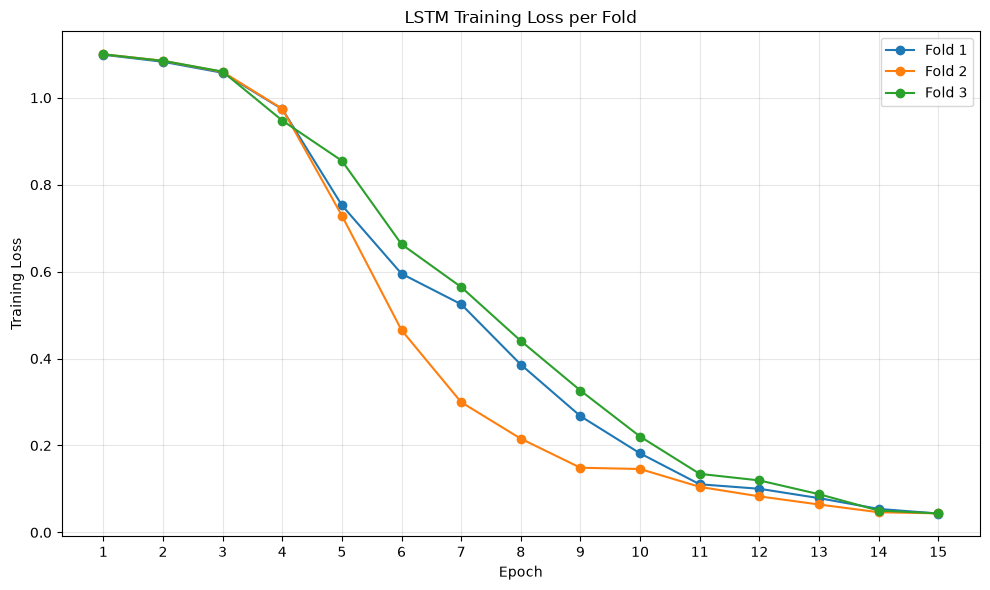

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\01_training_loss_per_fold.png


In [12]:
# MODELING VIZ-02 — TRAINING LOSS PER FOLD
# ============================================================

plt.figure(figsize=(10, 6))

for fold in sorted(history_df["fold"].unique()):
    subset = history_df.loc[history_df["fold"] == fold]
    plt.plot(
        subset["epoch"],
        subset["train_loss"],
        marker="o",
        label=f"Fold {fold}"
    )

plt.title("LSTM Training Loss per Fold")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

save_path = OUT_DIR / "01_training_loss_per_fold.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

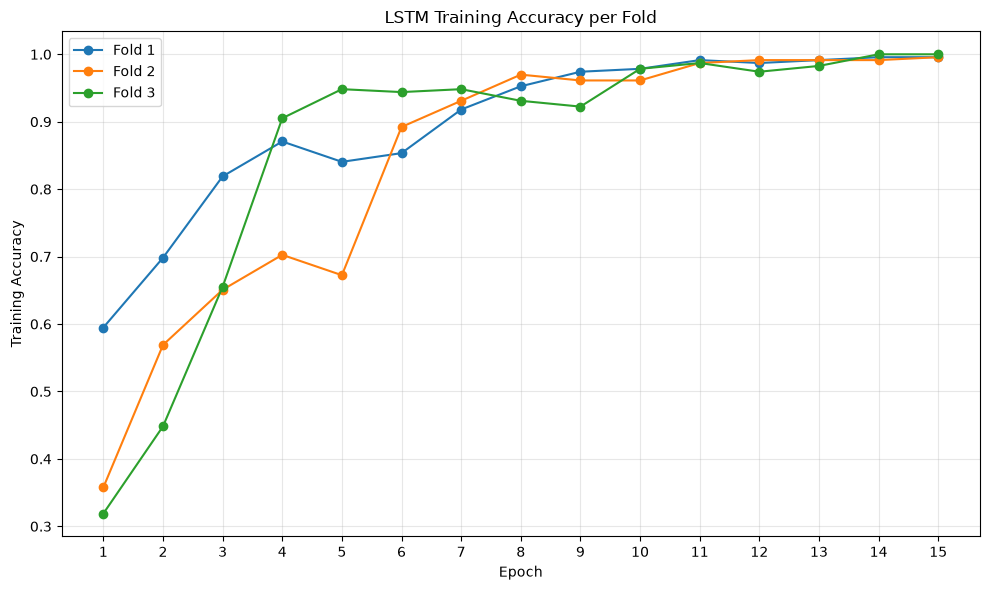

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\02_training_accuracy_per_fold.png


In [13]:
# MODELING VIZ-03 — TRAINING ACCURACY PER FOLD
# ============================================================

plt.figure(figsize=(10, 6))

for fold in sorted(history_df["fold"].unique()):
    subset = history_df.loc[history_df["fold"] == fold]
    plt.plot(
        subset["epoch"],
        subset["train_accuracy"],
        marker="o",
        label=f"Fold {fold}"
    )

plt.title("LSTM Training Accuracy per Fold")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

save_path = OUT_DIR / "02_training_accuracy_per_fold.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

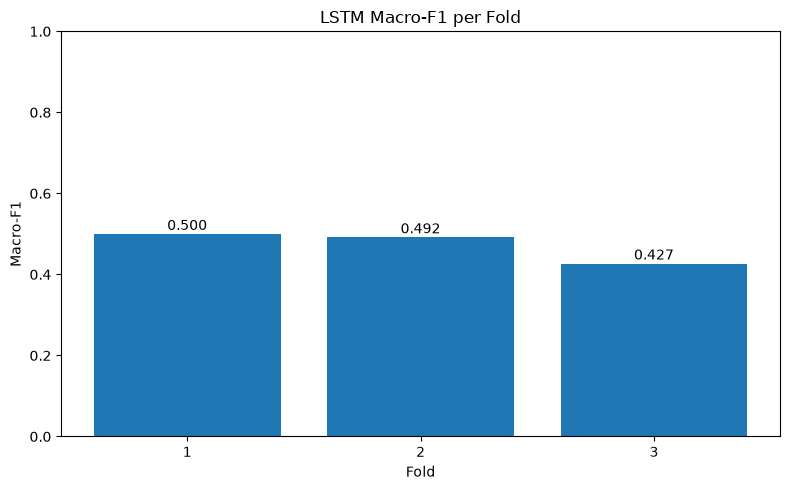

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\03_macro_f1_per_fold.png


In [14]:
# MODELING VIZ-04 — MACRO-F1 PER FOLD
# ============================================================

plot_df = fold_metrics_df.copy()

plt.figure(figsize=(8, 5))
plt.bar(
    plot_df["fold"].astype(str),
    plot_df["macro_f1"]
)

plt.title("LSTM Macro-F1 per Fold")
plt.xlabel("Fold")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)

for i, row in plot_df.iterrows():
    plt.text(
        i,
        row["macro_f1"] + 0.01,
        f'{row["macro_f1"]:.3f}',
        ha="center"
    )

plt.tight_layout()

save_path = OUT_DIR / "03_macro_f1_per_fold.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

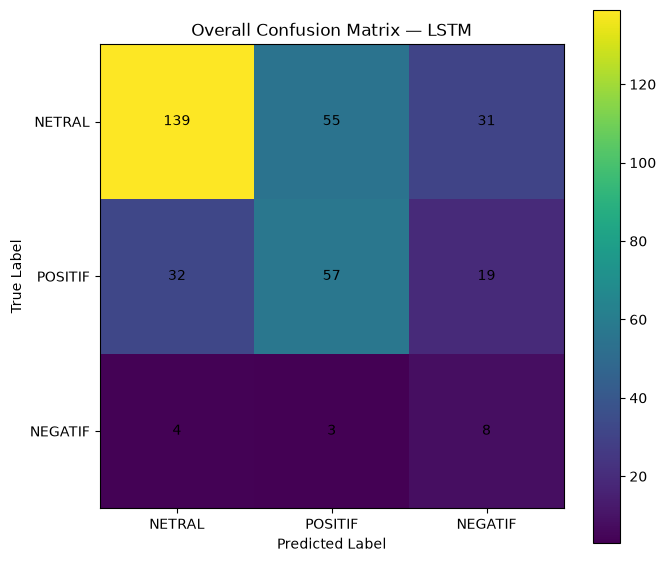

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\04_confusion_matrix_lstm.png


In [15]:
# MODELING VIZ-05 — OVERALL CONFUSION MATRIX (LSTM)
# ============================================================

labels = ["NETRAL", "POSITIF", "NEGATIF"]

overall_cm = (
    confusion_df.loc[confusion_df["scope"] == "overall_oof"]
    .pivot(
        index="true_label",
        columns="predicted_label",
        values="count"
    )
    .reindex(index=labels, columns=labels)
    .fillna(0)
)

cm_values = overall_cm.to_numpy()

plt.figure(figsize=(7, 6))
plt.imshow(cm_values, interpolation="nearest")
plt.title("Overall Confusion Matrix — LSTM")
plt.colorbar()

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm_values.shape[0]):
    for j in range(cm_values.shape[1]):
        plt.text(
            j, i,
            int(cm_values[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()

save_path = OUT_DIR / "04_confusion_matrix_lstm.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

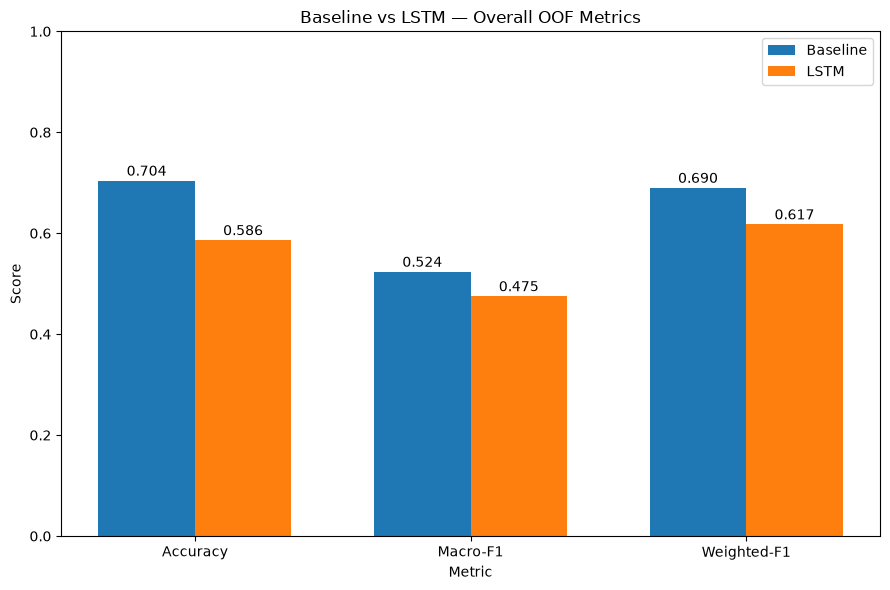

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\05_baseline_vs_lstm_overall_metrics.png


In [16]:
# MODELING VIZ-06 — BASELINE VS LSTM OVERALL METRICS
# ============================================================

baseline_oof = baseline_summary["overall_oof"]
lstm_oof = lstm_summary["overall_oof"]

compare_df = pd.DataFrame({
    "metric": ["Accuracy", "Macro-F1", "Weighted-F1"],
    "Baseline": [
        baseline_oof["accuracy"],
        baseline_oof["macro_f1"],
        baseline_oof["weighted_f1"]
    ],
    "LSTM": [
        lstm_oof["accuracy"],
        lstm_oof["macro_f1"],
        lstm_oof["weighted_f1"]
    ]
})

x = np.arange(len(compare_df))
width = 0.35

plt.figure(figsize=(9, 6))
plt.bar(x - width/2, compare_df["Baseline"], width, label="Baseline")
plt.bar(x + width/2, compare_df["LSTM"], width, label="LSTM")

plt.title("Baseline vs LSTM — Overall OOF Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.xticks(x, compare_df["metric"])
plt.ylim(0, 1)
plt.legend()

for i, v in enumerate(compare_df["Baseline"]):
    plt.text(i - width/2, v + 0.01, f"{v:.3f}", ha="center")

for i, v in enumerate(compare_df["LSTM"]):
    plt.text(i + width/2, v + 0.01, f"{v:.3f}", ha="center")

plt.tight_layout()

save_path = OUT_DIR / "05_baseline_vs_lstm_overall_metrics.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

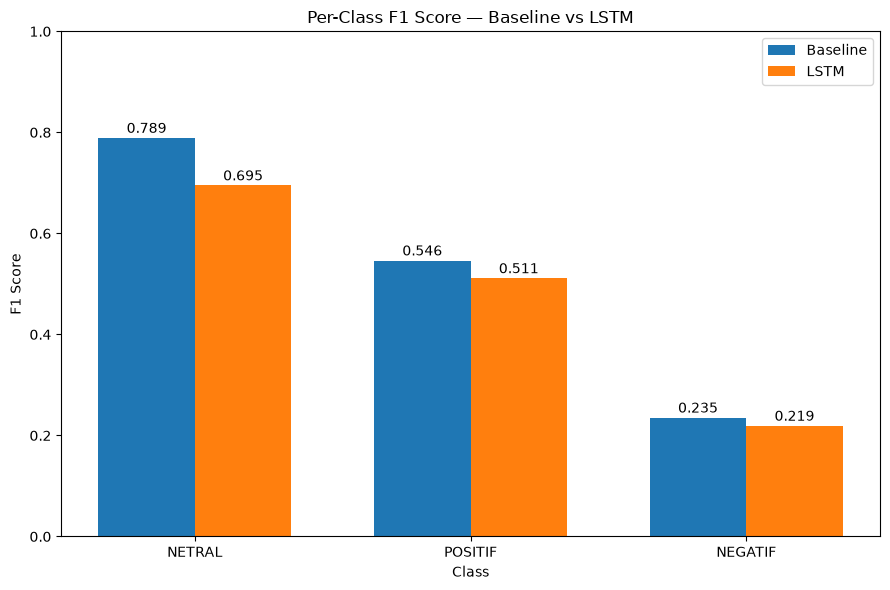

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\06_per_class_f1_baseline_vs_lstm.png


In [17]:
# MODELING VIZ-07 — PER-CLASS F1 COMPARISON
# ============================================================

labels = ["NETRAL", "POSITIF", "NEGATIF"]

baseline_class_plot = (
    baseline_per_class[["label", "f1"]]
    .rename(columns={"f1": "Baseline_F1"})
)

lstm_class_plot = (
    lstm_per_class[["label", "f1"]]
    .rename(columns={"f1": "LSTM_F1"})
)

plot_df = baseline_class_plot.merge(
    lstm_class_plot,
    on="label",
    how="inner"
)

plot_df["label"] = pd.Categorical(
    plot_df["label"],
    categories=labels,
    ordered=True
)

plot_df = plot_df.sort_values("label")

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(9, 6))
plt.bar(x - width/2, plot_df["Baseline_F1"], width, label="Baseline")
plt.bar(x + width/2, plot_df["LSTM_F1"], width, label="LSTM")

plt.title("Per-Class F1 Score — Baseline vs LSTM")
plt.xlabel("Class")
plt.ylabel("F1 Score")
plt.xticks(x, plot_df["label"])
plt.ylim(0, 1)
plt.legend()

for i, v in enumerate(plot_df["Baseline_F1"]):
    plt.text(i - width/2, v + 0.01, f"{v:.3f}", ha="center")

for i, v in enumerate(plot_df["LSTM_F1"]):
    plt.text(i + width/2, v + 0.01, f"{v:.3f}", ha="center")

plt.tight_layout()

save_path = OUT_DIR / "06_per_class_f1_baseline_vs_lstm.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

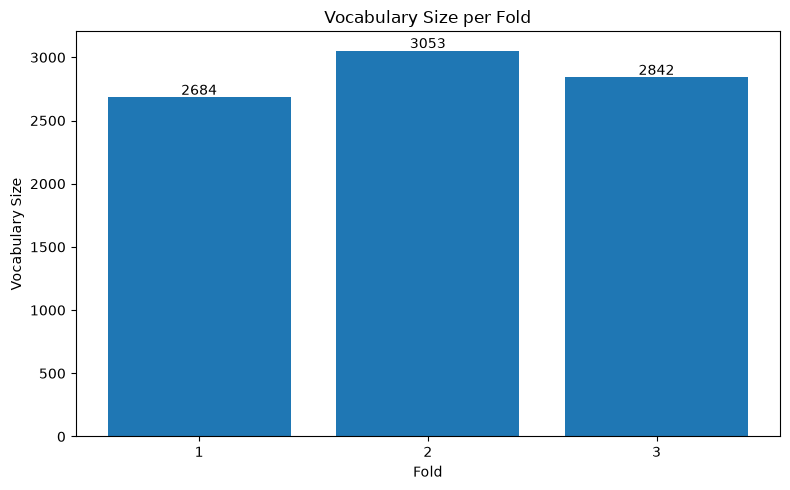

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\07_vocabulary_size_per_fold.png


In [18]:
# MODELING VIZ-08 — VOCABULARY SIZE PER FOLD
# ============================================================

plot_df = fold_metrics_df[["fold", "vocabulary_size"]].copy()

plt.figure(figsize=(8, 5))
plt.bar(
    plot_df["fold"].astype(str),
    plot_df["vocabulary_size"]
)

plt.title("Vocabulary Size per Fold")
plt.xlabel("Fold")
plt.ylabel("Vocabulary Size")

for i, row in plot_df.iterrows():
    plt.text(
        i,
        row["vocabulary_size"] + 20,
        str(int(row["vocabulary_size"])),
        ha="center"
    )

plt.tight_layout()

save_path = OUT_DIR / "07_vocabulary_size_per_fold.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

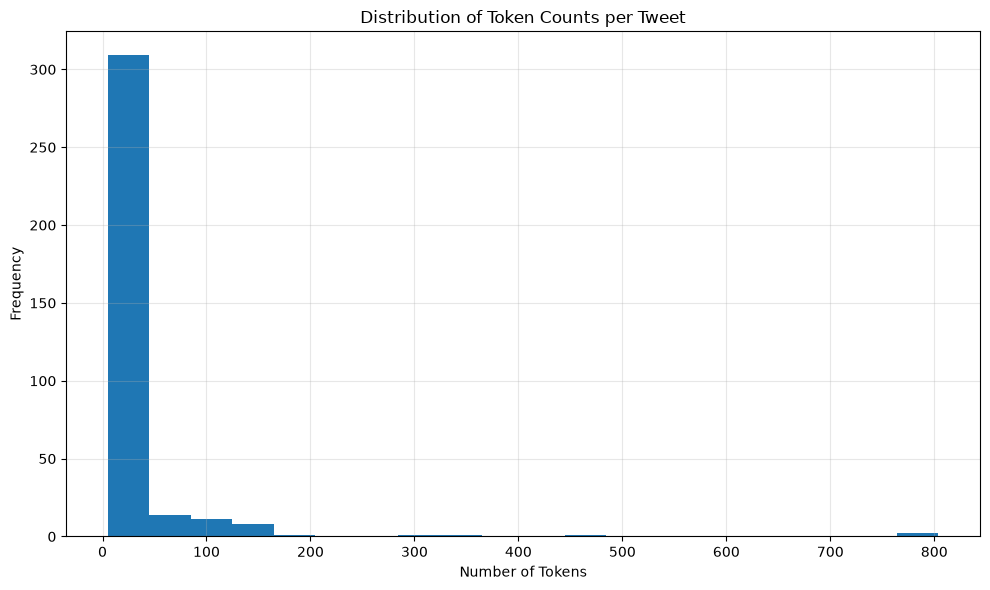

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\08_token_count_distribution.png
Min token   : 5
Max token   : 804
Mean token  : 37.72
Median token: 26.0


In [19]:
# MODELING VIZ-09 — TOKEN COUNT DISTRIBUTION
# ============================================================

token_counts = df_data["token_count"].dropna().astype(int)

plt.figure(figsize=(10, 6))
plt.hist(token_counts, bins=20)

plt.title("Distribution of Token Counts per Tweet")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()

save_path = OUT_DIR / "08_token_count_distribution.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)
print("Min token   :", token_counts.min())
print("Max token   :", token_counts.max())
print("Mean token  :", round(token_counts.mean(), 2))
print("Median token:", round(token_counts.median(), 2))

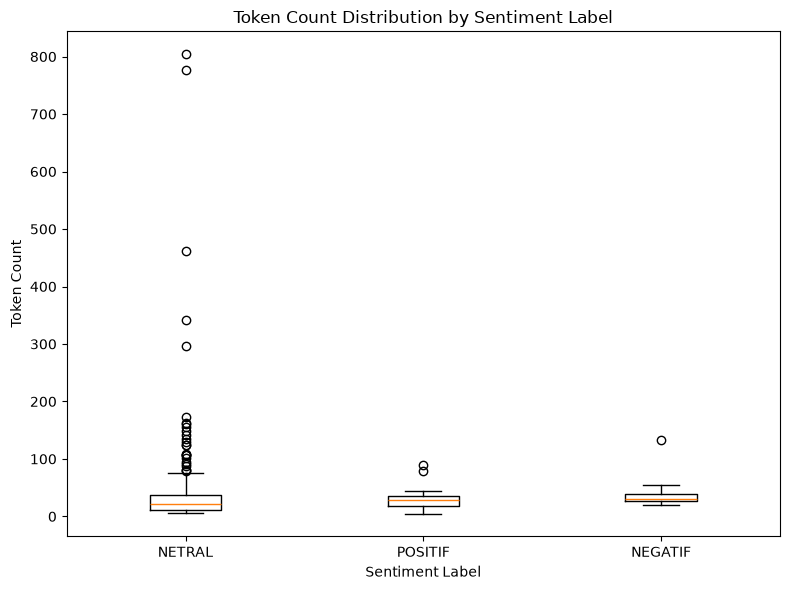

Saved: C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\lstm_visualizations\09_token_count_by_label_boxplot.png


In [20]:
# MODELING VIZ-10 — TOKEN COUNT BY SENTIMENT LABEL
# ============================================================

labels = ["NETRAL", "POSITIF", "NEGATIF"]
data_for_plot = [
    df_data.loc[df_data["sentiment_label"] == label, "token_count"].astype(int).tolist()
    for label in labels
]

plt.figure(figsize=(8, 6))
plt.boxplot(data_for_plot, tick_labels=labels)

plt.title("Token Count Distribution by Sentiment Label")
plt.xlabel("Sentiment Label")
plt.ylabel("Token Count")
plt.tight_layout()

save_path = OUT_DIR / "09_token_count_by_label_boxplot.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

In [21]:
# MODELING PART19 — BASELINE VS LSTM COMPARATIVE EVALUATION
# AND PAIRED OUT-OF-FOLD ERROR ANALYSIS
#
# READ ONLY SOURCES | NO TRAINING | NO SPLIT CHANGES
#
# Outputs:
#   paired_oof_comparison_348.csv
#   model_comparison_metrics.csv
#   comparative_case_metrics.csv
#   comparative_class_metrics.csv
#   paired_error_categories.csv
#   comparative_confusion_matrix.csv
#   part19_comparative_summary.json
#   part19_comparative_audit.json
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import uuid

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    f1_score
)

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

BASELINE_PATH = (
    BASE / "baseline_execution"
    / "baseline_oof_predictions_348.csv"
)
BASELINE_SUMMARY_PATH = (
    BASE / "baseline_execution"
    / "baseline_evaluation_summary.json"
)
LSTM_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_oof_predictions_348.csv"
)
LSTM_SUMMARY_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_evaluation_summary.json"
)
LSTM_AUDIT_PATH = (
    BASE / "lstm_training_execution"
    / "lstm_training_execution_audit.json"
)
SPLIT_PATH = (
    BASE / "cv_split_final"
    / "cv_final_assignments_348.csv"
)
DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

OUT_DIR = BASE / "comparative_evaluation"

OUTPUT_NAMES = [
    "paired_oof_comparison_348.csv",
    "model_comparison_metrics.csv",
    "comparative_case_metrics.csv",
    "comparative_class_metrics.csv",
    "paired_error_categories.csv",
    "comparative_confusion_matrix.csv",
    "part19_comparative_summary.json",
    "part19_comparative_audit.json",
]
OUTPUT_PATHS = [
    OUT_DIR / name for name in OUTPUT_NAMES
]

SOURCES = [
    BASELINE_PATH,
    BASELINE_SUMMARY_PATH,
    LSTM_PATH,
    LSTM_SUMMARY_PATH,
    LSTM_AUDIT_PATH,
    SPLIT_PATH,
    DATA_PATH
]

EXPECTED_SHA = {
    "baseline_oof_predictions_348.csv":
        "916133d8a3b8698df6d1c9879cba1bbfbe38843fdb96453c3bff2392e74b4d67",
    "baseline_evaluation_summary.json":
        "2a0e8b44ecd9555efa1d0a9bf043826b9d822bfd802dd33a7d60072074c8e3bb",
    "lstm_oof_predictions_348.csv":
        "37e69ba1d914ba2ead64ee3cb71c99536e3bb145a548864c57ee567336ef57b8",
    "lstm_evaluation_summary.json":
        "c1eb464d9526baa442eb9aeccb1e6f4650abb33cea73ddd2ad4a8bae40895f8d",
    "cv_final_assignments_348.csv":
        "f385531e2e6adaf7c8da6f0ce3d4c37838a2206634838039c65fb3c1fa01ad14",
    "modeling_labeled_348_grouped.csv":
        "cfa7df27079ef47bdb1b0cb526bc017aa1c8fe18dc4d91fef870a3441e2e9fb7",
}

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = ["lombok_2018", "palu_2018", "sumatra_2025"]
CV_CONFIG = "SGKF_3fold_seed123"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

def json_read(path):
    return json.loads(path.read_text(encoding="utf-8"))

def metrics(y_true, y_pred):
    p, r, f, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS,
        zero_division=0
    )
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(np.mean(p)),
        "macro_recall": float(np.mean(r)),
        "macro_f1": float(np.mean(f)),
        "weighted_f1": float(f1_score(
            y_true, y_pred, labels=LABELS,
            average="weighted", zero_division=0
        )),
        "per_class": {
            label: {
                "precision": float(p[i]),
                "recall": float(r[i]),
                "f1": float(f[i]),
                "support": int(support[i]),
            }
            for i, label in enumerate(LABELS)
        }
    }

print("=" * 72)
print("MODELING PART19 — PAIRED OOF COMPARATIVE ANALYSIS")
print("=" * 72)

# ------------------------------------------------------------
# A. IMMUTABLE SOURCE VERIFICATION
# ------------------------------------------------------------

for path in SOURCES:
    assert path.is_file(), f"Missing source: {path}"

for path in OUTPUT_PATHS:
    if path.exists():
        raise FileExistsError(
            f"Part19 output already exists: {path}"
        )

source_before = {
    path.name: sha256_file(path)
    for path in SOURCES
}

for name, expected in EXPECTED_SHA.items():
    assert source_before[name] == expected, (
        f"Locked SHA mismatch: {name}"
    )

baseline_summary = json_read(BASELINE_SUMMARY_PATH)
lstm_summary = json_read(LSTM_SUMMARY_PATH)
lstm_audit = json_read(LSTM_AUDIT_PATH)

assert baseline_summary["cv_configuration"] == CV_CONFIG
assert lstm_summary["cv_configuration"] == CV_CONFIG
assert lstm_audit["cv_configuration"] == CV_CONFIG
assert lstm_audit["status"] == (
    "LSTM_TRAINING_EXECUTION_PASS"
)
assert lstm_summary["status"] == (
    "LSTM_OOF_EVALUATION_COMPLETE"
)

assert lstm_audit["output_sha256"][
    "oof_predictions"
] == source_before[LSTM_PATH.name]

assert lstm_audit["output_sha256"][
    "evaluation_summary"
] == source_before[LSTM_SUMMARY_PATH.name]

print("SOURCE SHA256 AND PART18 AUDIT: PASS")

# ------------------------------------------------------------
# B. READ OOF DATA — IDs MUST REMAIN STRINGS
# ------------------------------------------------------------

read_kwargs = dict(
    encoding="utf-8-sig",
    keep_default_na=False,
    dtype={
        "id": "string",
        "leakage_group_id": "string",
    }
)

baseline = pd.read_csv(BASELINE_PATH, **read_kwargs)
lstm = pd.read_csv(LSTM_PATH, **read_kwargs)
split = pd.read_csv(SPLIT_PATH, **read_kwargs)
data = pd.read_csv(DATA_PATH, **read_kwargs)

required = {
    "id", "case", "leakage_group_id",
    "validation_fold", "true_label",
    "predicted_label", "correct",
    "prob_NETRAL", "prob_POSITIF", "prob_NEGATIF"
}

for name, frame in [
    ("Baseline", baseline),
    ("LSTM", lstm)
]:
    assert required.issubset(frame.columns), (
        f"{name} missing columns: "
        f"{sorted(required - set(frame.columns))}"
    )
    assert len(frame) == 348
    assert frame["id"].is_unique

    for col in [
        "id", "case", "leakage_group_id",
        "true_label", "predicted_label"
    ]:
        frame[col] = frame[col].astype("string").str.strip()

    frame["case"] = frame["case"].str.lower()
    for col in ["true_label", "predicted_label"]:
        frame[col] = frame[col].str.upper()

    assert frame["true_label"].isin(LABELS).all()
    assert frame["predicted_label"].isin(LABELS).all()
    assert frame["case"].isin(CASES).all()
    assert frame["validation_fold"].isin([1, 2, 3]).all()

    probs = frame[
        ["prob_NETRAL", "prob_POSITIF", "prob_NEGATIF"]
    ].to_numpy(dtype=float)

    assert np.isfinite(probs).all()
    assert (probs >= 0).all()
    assert (probs <= 1).all()
    assert np.allclose(probs.sum(axis=1), 1, atol=1e-5)

    predicted_from_probs = np.asarray(LABELS)[
        np.argmax(probs, axis=1)
    ]

    assert np.array_equal(
        predicted_from_probs,
        frame["predicted_label"].to_numpy(dtype=str)
    ), f"{name}: prediction/probability mismatch"

assert len(split) == len(data) == 348
assert split["id"].is_unique
assert data["id"].is_unique

assert set(baseline["id"]) == set(lstm["id"])
assert set(baseline["id"]) == set(split["id"])
assert set(baseline["id"]) == set(data["id"])

# ------------------------------------------------------------
# C. PAIR BASELINE AND LSTM BY EXACT TWEET ID
# ------------------------------------------------------------

common = [
    "id", "case", "leakage_group_id",
    "validation_fold", "true_label"
]

paired = baseline.merge(
    lstm,
    on="id",
    how="inner",
    suffixes=("_baseline", "_lstm"),
    validate="one_to_one"
)

assert len(paired) == 348
assert paired["id"].is_unique

for col in common[1:]:
    assert (
        paired[f"{col}_baseline"]
        .astype("string")
        .equals(
            paired[f"{col}_lstm"].astype("string")
        )
    ), f"Baseline/LSTM mismatch: {col}"

paired = paired.rename(columns={
    "case_baseline": "case",
    "leakage_group_id_baseline": "leakage_group_id",
    "validation_fold_baseline": "validation_fold",
    "true_label_baseline": "true_label"
}).drop(columns=[
    "case_lstm", "leakage_group_id_lstm",
    "validation_fold_lstm", "true_label_lstm"
])

split_lookup = split.set_index("id")
data_lookup = data.set_index("id")
aligned_split = split_lookup.reindex(paired["id"])
aligned_data = data_lookup.reindex(paired["id"])

for col, source_col in [
    ("case", "case"),
    ("leakage_group_id", "leakage_group_id"),
    ("true_label", "sentiment_label"),
    ("validation_fold", "validation_fold")
]:
    if col == "validation_fold":
        assert np.array_equal(
            paired[col].to_numpy(),
            aligned_split[source_col].to_numpy()
        )
    else:
        assert np.array_equal(
            paired[col].astype(str).to_numpy(),
            aligned_split[source_col].astype(str).to_numpy()
        ), f"Locked split mismatch: {col}"

assert np.array_equal(
    paired["true_label"].astype(str).to_numpy(),
    aligned_data["sentiment_label"].astype(str).to_numpy()
)

for model in ["baseline", "lstm"]:
    paired[f"{model}_correct"] = (
        paired[f"predicted_label_{model}"]
        == paired["true_label"]
    )

    saved_correct = (
        paired[f"correct_{model}"]
        .astype("string")
        .str.lower()
        .map({"true": True, "false": False})
    )

    assert saved_correct.notna().all()
    assert np.array_equal(
        saved_correct.astype(bool).to_numpy(),
        paired[f"{model}_correct"].to_numpy()
    )

paired["prediction_agreement"] = (
    paired["predicted_label_baseline"]
    == paired["predicted_label_lstm"]
)

conditions = [
    paired["baseline_correct"] & paired["lstm_correct"],
    paired["baseline_correct"] & ~paired["lstm_correct"],
    ~paired["baseline_correct"] & paired["lstm_correct"],
    ~paired["baseline_correct"] & ~paired["lstm_correct"]
]

categories = [
    "both_correct",
    "baseline_only_correct",
    "lstm_only_correct",
    "both_wrong"
]

paired["error_category"] = np.select(
    conditions, categories, default="INVALID"
)

assert (~paired["error_category"].eq("INVALID")).all()

paired["baseline_error_type"] = np.where(
    paired["baseline_correct"], "CORRECT",
    paired["true_label"] + "->"
    + paired["predicted_label_baseline"]
)

paired["lstm_error_type"] = np.where(
    paired["lstm_correct"], "CORRECT",
    paired["true_label"] + "->"
    + paired["predicted_label_lstm"]
)

paired = paired.sort_values("id").reset_index(drop=True)

print("348 PAIRED TWEET IDS: PASS")
print("SOURCE LABEL AND CV MEMBERSHIP: PASS")

# ------------------------------------------------------------
# D. RECOMPUTE METRICS FROM ACTUAL OOF PREDICTIONS
# ------------------------------------------------------------

overall = {}
model_metric_rows = []
class_rows = []
case_rows = []
confusion_rows = []

for model in ["baseline", "lstm"]:
    y_true = paired["true_label"].to_numpy(dtype=str)
    y_pred = paired[
        f"predicted_label_{model}"
    ].to_numpy(dtype=str)

    m = metrics(y_true, y_pred)
    overall[model] = m

    source_summary = (
        baseline_summary if model == "baseline"
        else lstm_summary
    )["overall_oof"]

    for key in [
        "accuracy", "macro_precision",
        "macro_recall", "macro_f1", "weighted_f1"
    ]:
        assert np.isclose(
            m[key], source_summary[key], atol=1e-12
        ), f"{model}: summary metric mismatch: {key}"

    model_metric_rows.append({
        "model": model,
        "rows": len(paired),
        **{
            key: m[key] for key in [
                "accuracy", "macro_precision",
                "macro_recall", "macro_f1", "weighted_f1"
            ]
        }
    })

    for label in LABELS:
        class_rows.append({
            "model": model,
            "label": label,
            **m["per_class"][label]
        })

    for case in CASES:
        section = paired.loc[paired["case"] == case]
        cm_case = metrics(
            section["true_label"].to_numpy(dtype=str),
            section[f"predicted_label_{model}"].to_numpy(dtype=str)
        )
        case_rows.append({
            "model": model,
            "case": case,
            "rows": len(section),
            "accuracy": cm_case["accuracy"],
            "macro_precision": cm_case["macro_precision"],
            "macro_recall": cm_case["macro_recall"],
            "macro_f1": cm_case["macro_f1"],
            "weighted_f1": cm_case["weighted_f1"]
        })

    for scope, section in (
        [("overall_oof", paired)]
        + [(f"fold_{f}", paired.loc[
            paired["validation_fold"] == f
        ]) for f in [1, 2, 3]]
    ):
        cm = confusion_matrix(
            section["true_label"].to_numpy(dtype=str),
            section[f"predicted_label_{model}"].to_numpy(dtype=str),
            labels=LABELS
        )

        for i, true_label in enumerate(LABELS):
            for j, predicted_label in enumerate(LABELS):
                confusion_rows.append({
                    "model": model,
                    "scope": scope,
                    "true_label": true_label,
                    "predicted_label": predicted_label,
                    "count": int(cm[i, j])
                })

model_metrics = pd.DataFrame(model_metric_rows)
class_metrics = pd.DataFrame(class_rows)
case_metrics = pd.DataFrame(case_rows)
confusion_metrics = pd.DataFrame(confusion_rows)

assert len(model_metrics) == 2
assert len(class_metrics) == 6
assert len(case_metrics) == 6
assert len(confusion_metrics) == 72

# ------------------------------------------------------------
# E. PAIRED ERROR OVERLAP
# ------------------------------------------------------------

category_counts = Counter(paired["error_category"])

error_categories = pd.DataFrame([
    {
        "category": category,
        "count": int(category_counts.get(category, 0)),
        "percentage": float(
            100 * category_counts.get(category, 0) / len(paired)
        )
    }
    for category in categories
])

assert error_categories["count"].sum() == 348

baseline_correct_n = int(
    paired["baseline_correct"].sum()
)
lstm_correct_n = int(
    paired["lstm_correct"].sum()
)

assert baseline_correct_n == 245
assert lstm_correct_n == 204

assert (
    int(category_counts["both_correct"])
    + int(category_counts["baseline_only_correct"])
    == baseline_correct_n
)

assert (
    int(category_counts["both_correct"])
    + int(category_counts["lstm_only_correct"])
    == lstm_correct_n
)

baseline_errors = len(paired) - baseline_correct_n
lstm_errors = len(paired) - lstm_correct_n

assert baseline_errors == 103
assert lstm_errors == 144

# Paired discordance counts — descriptive.
# No statistical-significance assertion.
baseline_only_n = int(
    category_counts["baseline_only_correct"]
)
lstm_only_n = int(
    category_counts["lstm_only_correct"]
)

assert baseline_only_n - lstm_only_n == 41

# ------------------------------------------------------------
# F. NEGATIVE CLASS AND FALSE POSITIVES
# ------------------------------------------------------------

negative_findings = {}

for model in ["baseline", "lstm"]:
    y = paired["true_label"]
    p = paired[f"predicted_label_{model}"]

    tp = int(((y == "NEGATIF") & (p == "NEGATIF")).sum())
    fp = int(((y != "NEGATIF") & (p == "NEGATIF")).sum())
    fn = int(((y == "NEGATIF") & (p != "NEGATIF")).sum())

    negative_findings[model] = {
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn,
        "negative_predictions": tp + fp,
        "precision": overall[model]["per_class"]["NEGATIF"]["precision"],
        "recall": overall[model]["per_class"]["NEGATIF"]["recall"],
        "f1": overall[model]["per_class"]["NEGATIF"]["f1"]
    }

assert negative_findings["baseline"]["true_positive"] == 2
assert negative_findings["lstm"]["true_positive"] == 8
assert negative_findings["lstm"]["false_positive"] == 50

# ------------------------------------------------------------
# G. SUMMARY AND AUDIT
# ------------------------------------------------------------

summary = {
    "stage": "04_Modeling",
    "part": "19 Baseline vs LSTM Comparative Evaluation",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "3e64a629182c3ebaa5261ac4ab10d26bd19e52dc"
    ),
    "cv_configuration": CV_CONFIG,
    "total_rows": 348,
    "labels": LABELS,
    "cases": CASES,
    "model_metrics": overall,
    "accuracy_delta_lstm_minus_baseline": float(
        overall["lstm"]["accuracy"]
        - overall["baseline"]["accuracy"]
    ),
    "macro_f1_delta_lstm_minus_baseline": float(
        overall["lstm"]["macro_f1"]
        - overall["baseline"]["macro_f1"]
    ),
    "correct_predictions": {
        "baseline": baseline_correct_n,
        "lstm": lstm_correct_n
    },
    "error_predictions": {
        "baseline": baseline_errors,
        "lstm": lstm_errors
    },
    "paired_correctness_categories": {
        key: int(category_counts.get(key, 0))
        for key in categories
    },
    "discordant_counts": {
        "baseline_only_correct": baseline_only_n,
        "lstm_only_correct": lstm_only_n
    },
    "prediction_agreement_count": int(
        paired["prediction_agreement"].sum()
    ),
    "negative_class_findings": negative_findings,
    "comparison_is_descriptive": True,
    "independent_holdout_available": False,
    "model_retrained_during_part19": False,
    "status": "PART19_COMPARATIVE_ANALYSIS_COMPLETE"
}

assert {
    p.name: sha256_file(p) for p in SOURCES
} == source_before

audit = {
    "stage": "04_Modeling",
    "part": "19 Paired OOF Comparison Audit",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit": (
        "3e64a629182c3ebaa5261ac4ab10d26bd19e52dc"
    ),
    "source_sha256": source_before,
    "paired_oof_rows": 348,
    "unique_ids": int(paired["id"].nunique()),
    "case_count": 3,
    "labels_count": 3,
    "models_compared": 2,
    "source_fold_match": True,
    "source_label_match": True,
    "source_group_match": True,
    "baseline_correct": baseline_correct_n,
    "lstm_correct": lstm_correct_n,
    "baseline_errors": baseline_errors,
    "lstm_errors": lstm_errors,
    "new_training_performed": False,
    "source_modified": False,
    "final_split_modified": False,
    "status": "PART19_COMPARATIVE_AUDIT_PASS"
}

# ------------------------------------------------------------
# H. SAFE EXPORT — NEW FILES ONLY
# ------------------------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)

for path in OUTPUT_PATHS:
    if path.exists():
        raise FileExistsError(
            f"Refusing overwrite: {path}"
        )

export_paired = paired[[
    "id", "case", "leakage_group_id",
    "validation_fold", "true_label",
    "predicted_label_baseline",
    "predicted_label_lstm",
    "baseline_correct", "lstm_correct",
    "prediction_agreement", "error_category",
    "baseline_error_type", "lstm_error_type",
    "prob_NETRAL_baseline", "prob_POSITIF_baseline",
    "prob_NEGATIF_baseline",
    "prob_NETRAL_lstm", "prob_POSITIF_lstm",
    "prob_NEGATIF_lstm"
]].copy()

token = uuid.uuid4().hex[:10]
temps = {
    name: OUT_DIR / f".part19_{token}_{i}.tmp"
    for i, name in enumerate(OUTPUT_NAMES)
}

data_exports = [
    (OUTPUT_NAMES[0], export_paired),
    (OUTPUT_NAMES[1], model_metrics),
    (OUTPUT_NAMES[2], case_metrics),
    (OUTPUT_NAMES[3], class_metrics),
    (OUTPUT_NAMES[4], error_categories),
    (OUTPUT_NAMES[5], confusion_metrics)
]

created = []

try:
    for name, frame in data_exports:
        frame.to_csv(
            temps[name],
            index=False,
            encoding="utf-8-sig"
        )

    temps[OUTPUT_NAMES[6]].write_text(
        json.dumps(summary, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    audit["output_sha256"] = {
        name: sha256_file(temps[name])
        for name in OUTPUT_NAMES[:7]
    }

    temps[OUTPUT_NAMES[7]].write_text(
        json.dumps(audit, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    # Reload critical CSV with ID as STRING.
    check = pd.read_csv(
        temps[OUTPUT_NAMES[0]],
        dtype={"id": "string"},
        encoding="utf-8-sig"
    )

    assert len(check) == 348
    assert check["id"].is_unique
    assert set(check["id"]) == set(baseline["id"])

    assert {
        p.name: sha256_file(p)
        for p in SOURCES
    } == source_before

    for name, destination in zip(
        OUTPUT_NAMES, OUTPUT_PATHS
    ):
        with open(destination, "xb") as target:
            target.write(temps[name].read_bytes())
        created.append(destination)

except Exception:
    for destination in created:
        if destination.exists():
            destination.unlink()
    raise

finally:
    for path in temps.values():
        if path.exists():
            path.unlink()

# ------------------------------------------------------------
# I. FINAL INTEGRITY CHECK
# ------------------------------------------------------------

for name in OUTPUT_NAMES[:7]:
    assert sha256_file(OUT_DIR / name) == (
        audit["output_sha256"][name]
    )

assert {
    p.name: sha256_file(p) for p in SOURCES
} == source_before

print("\n" + "=" * 72)
print("PART19 — OVERALL MODEL COMPARISON")
print("=" * 72)
display(model_metrics)

print("\nPART19 — CASE-LEVEL COMPARISON")
display(case_metrics)

print("\nPART19 — PER-CLASS COMPARISON")
display(class_metrics)

print("\nPART19 — PAIRED ERROR CATEGORIES")
display(error_categories)

print("\nPART19 — NEGATIVE CLASS")
display(pd.DataFrame(negative_findings).T)

print("\nBaseline correct :", baseline_correct_n)
print("LSTM correct     :", lstm_correct_n)
print("Baseline errors  :", baseline_errors)
print("LSTM errors      :", lstm_errors)

print("\nOUTPUT FILES")
for path in OUTPUT_PATHS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("NO TRAINING OR DATA MODIFICATION")
print("=" * 72)


MODELING PART19 — PAIRED OOF COMPARATIVE ANALYSIS
SOURCE SHA256 AND PART18 AUDIT: PASS
348 PAIRED TWEET IDS: PASS
SOURCE LABEL AND CV MEMBERSHIP: PASS

PART19 — OVERALL MODEL COMPARISON


,model,rows,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,baseline,348,0.704023,0.776108,0.494321,0.523555,0.689845
1,lstm,348,0.586207,0.475956,0.559630,0.475130,0.617452



PART19 — CASE-LEVEL COMPARISON


,model,case,rows,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,baseline,lombok_2018,101,0.702970,0.441618,0.443667,0.440564,0.684387
1,baseline,palu_2018,105,0.695238,0.761084,0.513486,0.548148,0.689101
2,baseline,sumatra_2025,142,0.711268,0.789814,0.506176,0.537698,0.693620
3,lstm,lombok_2018,101,0.613861,0.456252,0.508469,0.462659,0.632527
4,lstm,palu_2018,105,0.704762,0.564046,0.648923,0.588889,0.716508
5,lstm,sumatra_2025,142,0.478873,0.443737,0.510701,0.410517,0.524831



PART19 — PER-CLASS COMPARISON


...


PART19 — PAIRED ERROR CATEGORIES


,category,count,percentage
0,both_correct,165,47.413793
1,baseline_only_correct,80,22.988506
2,lstm_only_correct,39,11.206897
3,both_wrong,64,18.390805



PART19 — NEGATIVE CLASS


,true_positive,false_positive,false_negative,negative_predictions,precision,recall,f1
baseline,2.0,0.0,13.0,2.0,1.000000,0.133333,0.235294
lstm,8.0,50.0,7.0,58.0,0.137931,0.533333,0.219178



Baseline correct : 245
LSTM correct     : 204
Baseline errors  : 103
LSTM errors      : 144

OUTPUT FILES
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\paired_oof_comparison_348.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\model_comparison_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\comparative_case_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\comparative_class_metrics.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\paired_error_categories.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\comparative_confusion_matrix.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\part19_comparative_summary.json
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\comparative_evaluation\pa

In [ ]:
# MODELING 00 — ENVIRONMENT DIAGNOSTIC (FIXED)
# ============================================================

import sys
import pandas as pd
import numpy as np
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("=" * 60)
print("MODELING 00 — ENVIRONMENT DIAGNOSTIC")
print("=" * 60)

print("Python executable :", sys.executable)
print("Python version    :", sys.version.split()[0])
print("Pandas version    :", pd.__version__)
print("NumPy version     :", np.__version__)
print("Scikit-learn      :", sklearn.__version__)

print("\nLibrary import validation:")
print("Pandas            : PASS")
print("NumPy             : PASS")
print("Scikit-learn      : PASS")
print("TF-IDF import     : PASS")
print("Cosine similarity : PASS")

print("\nMODELING ENVIRONMENT: PASS")


MODELING 00 — ENVIRONMENT DIAGNOSTIC
Python executable : c:\Penelitian Sentimen Bencana Nasional\.venv\Scripts\python.exe
Python version    : 3.14.8
Pandas version    : 3.0.6
NumPy version     : 2.5.3
Scikit-learn      : 1.9.1

Library import validation:
Pandas            : PASS
NumPy             : PASS
Scikit-learn      : PASS
TF-IDF import     : PASS
Cosine similarity : PASS

MODELING ENVIRONMENT: PASS


In [22]:
# MODELING PART20 — FINAL EVALUATION & RESEARCH FINDINGS
#
# NO MODEL TRAINING
# NO TOKENIZER ADAPTATION
# NO SOURCE FILE MODIFICATION
#
# Inputs:
#   Part19 comparative evaluation
#   Part18 training history
#   Part6 grouped dataset
#   9 existing Visual Modeling PNG figures
#
# Outputs:
#   final_evaluation_report.md
#   final_research_findings.json
#   final_figure_registry.csv
#   part20_final_report_audit.json
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")
BASE = ROOT / "04_Modeling" / "outputs"

COMP = BASE / "comparative_evaluation"
VIZ = BASE / "lstm_visualizations"
EXEC = BASE / "lstm_training_execution"
OUT = BASE / "final_evaluation_report"

SUMMARY_PATH = COMP / "part19_comparative_summary.json"
PART19_AUDIT_PATH = COMP / "part19_comparative_audit.json"
MODEL_PATH = COMP / "model_comparison_metrics.csv"
CASE_PATH = COMP / "comparative_case_metrics.csv"
CLASS_PATH = COMP / "comparative_class_metrics.csv"
ERROR_PATH = COMP / "paired_error_categories.csv"
PAIRED_PATH = COMP / "paired_oof_comparison_348.csv"
HISTORY_PATH = EXEC / "lstm_training_history_45.csv"
DATA_PATH = (
    BASE / "leakage_grouping"
    / "modeling_labeled_348_grouped.csv"
)

FIGURES = [
    (
        "G01",
        "01_training_loss_per_fold.png",
        "Training loss per fold",
        "Dinamika penurunan loss pada 15 epoch"
    ),
    (
        "G02",
        "02_training_accuracy_per_fold.png",
        "Training accuracy per fold",
        "Dinamika akurasi training pada 15 epoch"
    ),
    (
        "G03",
        "03_macro_f1_per_fold.png",
        "LSTM Macro-F1 per fold",
        "Variasi performa antar validation fold"
    ),
    (
        "G04",
        "04_confusion_matrix_lstm.png",
        "LSTM confusion matrix",
        "Distribusi prediksi benar dan kesalahan"
    ),
    (
        "G05",
        "05_baseline_vs_lstm_overall_metrics.png",
        "Baseline vs LSTM overall metrics",
        "Perbandingan kinerja out-of-fold"
    ),
    (
        "G06",
        "06_per_class_f1_baseline_vs_lstm.png",
        "Per-class F1 comparison",
        "Perbandingan F1 menurut sentimen"
    ),
    (
        "G07",
        "07_vocabulary_size_per_fold.png",
        "Vocabulary size per fold",
        "Ukuran vocabulary hasil adaptasi training-only"
    ),
    (
        "G08",
        "08_token_count_distribution.png",
        "Token-count distribution",
        "Distribusi jumlah token per tweet"
    ),
    (
        "G09",
        "09_token_count_by_label_boxplot.png",
        "Token count by sentiment",
        "Sebaran panjang teks per kelas sentimen"
    ),
]

REPORT_PATH = OUT / "final_evaluation_report.md"
FINDINGS_PATH = OUT / "final_research_findings.json"
FIGURE_PATH = OUT / "final_figure_registry.csv"
AUDIT_PATH = OUT / "part20_final_report_audit.json"

OUTPUTS = [
    REPORT_PATH,
    FINDINGS_PATH,
    FIGURE_PATH,
    AUDIT_PATH
]

SOURCE_FILES = [
    SUMMARY_PATH,
    PART19_AUDIT_PATH,
    MODEL_PATH,
    CASE_PATH,
    CLASS_PATH,
    ERROR_PATH,
    PAIRED_PATH,
    HISTORY_PATH,
    DATA_PATH
] + [VIZ / filename for _, filename, _, _ in FIGURES]

LABELS = ["NETRAL", "POSITIF", "NEGATIF"]
CASES = ["lombok_2018", "palu_2018", "sumatra_2025"]

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def pct(number):
    return f"{number * 100:.2f}%"

def score(number):
    return f"{number:.4f}"

def markdown_table(frame, columns):
    lines = [
        "| " + " | ".join(columns) + " |",
        "| " + " | ".join(["---"] * len(columns)) + " |"
    ]
    for row in frame[columns].itertuples(
        index=False, name=None
    ):
        lines.append(
            "| " + " | ".join(str(v) for v in row) + " |"
        )
    return "\n".join(lines)

def exclusive_copy(src, dst):
    with dst.open("xb") as handle:
        handle.write(src.read_bytes())

print("=" * 72)
print("MODELING PART20 — FINAL REPORT PREFLIGHT")
print("=" * 72)

# ------------------------------------------------------------
# A. VERIFY ALL LOCKED SOURCES EXIST
# ------------------------------------------------------------

for path in SOURCE_FILES:
    assert path.is_file(), (
        f"Missing required source: {path}"
    )

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Output exists; refusing overwrite: {path}"
        )

source_before = {
    str(p.relative_to(ROOT)).replace("\\", "/"):
        sha256_file(p)
    for p in SOURCE_FILES
}

part19 = read_json(SUMMARY_PATH)
audit19 = read_json(PART19_AUDIT_PATH)

assert part19["status"] == (
    "PART19_COMPARATIVE_ANALYSIS_COMPLETE"
)
assert audit19["status"] == (
    "PART19_COMPARATIVE_AUDIT_PASS"
)

# Verify all Part19 files consumed here.
part19_input_map = {
    "part19_comparative_summary.json": SUMMARY_PATH,
    "model_comparison_metrics.csv": MODEL_PATH,
    "comparative_case_metrics.csv": CASE_PATH,
    "comparative_class_metrics.csv": CLASS_PATH,
    "paired_error_categories.csv": ERROR_PATH,
    "paired_oof_comparison_348.csv": PAIRED_PATH,
}
for name, path in part19_input_map.items():
    assert sha256_file(path) == (
        audit19["output_sha256"][name]
    ), f"Part19 artifact SHA mismatch: {name}"

assert sha256_file(DATA_PATH) == (
    audit19["source_sha256"][DATA_PATH.name]
)

print("PART19 PROVENANCE: PASS")

# ------------------------------------------------------------
# B. LOAD AND RECONCILE SUMMARY TABLES
# ------------------------------------------------------------

models = pd.read_csv(MODEL_PATH, encoding="utf-8-sig")
cases = pd.read_csv(CASE_PATH, encoding="utf-8-sig")
classes = pd.read_csv(CLASS_PATH, encoding="utf-8-sig")
errors = pd.read_csv(ERROR_PATH, encoding="utf-8-sig")
history = pd.read_csv(HISTORY_PATH, encoding="utf-8-sig")
paired = pd.read_csv(
    PAIRED_PATH,
    encoding="utf-8-sig",
    dtype={"id": "string"},
    keep_default_na=False
)
data = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype={"id": "string"},
    keep_default_na=False
)

assert len(models) == 2
assert set(models["model"]) == {"baseline", "lstm"}
assert len(cases) == 6
assert len(classes) == 6
assert len(errors) == 4
assert len(history) == 45
assert len(paired) == 348
assert paired["id"].is_unique
assert len(data) == 348

assert set(paired["id"]) == set(data["id"])
assert set(cases["case"]) == set(CASES)
assert set(classes["label"]) == set(LABELS)
assert int(errors["count"].sum()) == 348

for fold in (1, 2, 3):
    segment = history[history["fold"] == fold]
    assert segment["epoch"].tolist() == list(range(1, 16))
    assert np.isfinite(segment["train_loss"]).all()
    assert np.isfinite(segment["train_accuracy"]).all()

for model in ("baseline", "lstm"):
    record = models.loc[
        models["model"] == model
    ].iloc[0]
    reference = part19["model_metrics"][model]

    for field in (
        "accuracy", "macro_f1",
        "weighted_f1", "macro_precision",
        "macro_recall"
    ):
        assert np.isclose(
            float(record[field]),
            float(reference[field]),
            atol=1e-12
        )

print("METRICS AND OOF COUNTS: PASS")

# ------------------------------------------------------------
# C. FIGURE REGISTRY — REUSE EXISTING PNG FILES
# ------------------------------------------------------------

figure_rows = []

for fig_id, filename, title, purpose in FIGURES:
    path = VIZ / filename
    signature = path.read_bytes()[:8]

    # PNG magic signature, not just filename extension.
    assert signature == bytes.fromhex(
        "89504e470d0a1a0a"
    ), f"Invalid PNG: {filename}"

    figure_rows.append({
        "figure_id": fig_id,
        "filename": filename,
        "title": title,
        "purpose": purpose,
        "relative_path_from_report":
            f"../lstm_visualizations/{filename}",
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path),
        "source_commit": "a613f00992acf1bc6e4a4f34240bc0a4d13a8139",
        "reused_existing_figure": True
    })

registry = pd.DataFrame(figure_rows)

assert len(registry) == 9
assert registry["sha256"].nunique() == 9

print("NINE EXISTING PNG FIGURES: VERIFIED")

# ------------------------------------------------------------
# D. DERIVE FINAL RESULTS
# ------------------------------------------------------------

b = part19["model_metrics"]["baseline"]
l = part19["model_metrics"]["lstm"]

counts = part19["paired_correctness_categories"]
negative = part19["negative_class_findings"]

train_final = (
    history.sort_values(["fold", "epoch"])
    .groupby("fold", as_index=False)
    .tail(1)
    .sort_values("fold")
)

assert len(train_final) == 3

token_counts = (
    data["text_linguistic"]
    .astype("string")
    .fillna("")
    .str.split()
    .str.len()
    .astype(int)
)

token_stats = {
    "min": int(token_counts.min()),
    "median": float(token_counts.median()),
    "mean": float(token_counts.mean()),
    "max": int(token_counts.max()),
    "over_128": int((token_counts > 128).sum()),
    "equal_or_under_128": int(
        (token_counts <= 128).sum()
    )
}

# These count raw whitespace tokens in the finalized
# preprocessing text, not learned vocabulary entries.
assert token_counts.ge(1).all()

case_pivot = cases.pivot(
    index="case",
    columns="model",
    values="macro_f1"
).reindex(CASES)

assert case_pivot.notna().all().all()

case_pivot["delta_lstm_minus_baseline"] = (
    case_pivot["lstm"] - case_pivot["baseline"]
)

assert b["accuracy"] > l["accuracy"]
assert b["macro_f1"] > l["macro_f1"]
assert l["macro_recall"] > b["macro_recall"]

# ------------------------------------------------------------
# E. WRITE FORMAL ACADEMIC REPORT
# ------------------------------------------------------------

model_table = models.copy()
for col in (
    "accuracy", "macro_f1", "weighted_f1",
    "macro_precision", "macro_recall"
):
    model_table[col] = model_table[col].map(score)

case_table = cases.copy()
for col in ("accuracy", "macro_f1", "weighted_f1"):
    case_table[col] = case_table[col].map(score)

class_table = classes.copy()
for col in ("precision", "recall", "f1"):
    class_table[col] = class_table[col].map(score)

error_table = errors.copy()
error_table["percentage"] = (
    error_table["percentage"]
    .map(lambda x: f"{x:.2f}%")
)

fig_md = {
    name: f"![{title}](../lstm_visualizations/{name})"
    for _, name, title, _ in FIGURES
}

report = f"""# LAPORAN EVALUASI AKHIR PEMODELAN SENTIMEN

**Penelitian:** Sentimen Penetapan Bencana Nasional
**Tahap:** Modeling Part20 — Final Evaluation Report
**Konfigurasi CV:** SGKF_3fold_seed123
**Tanggal laporan (UTC):** {datetime.now(timezone.utc).isoformat()}

> Laporan ini disusun menggunakan artefak OOF yang telah
> dikunci dari Part12, Part18, dan Part19. Tidak dilakukan
> pelatihan model baru atau pengubahan data.

## 1. Metodologi Evaluasi

Penelitian ini mengevaluasi 348 tweet yang dikelompokkan
menjadi 337 leakage group. Data terdiri atas tiga kasus,
yaitu Lombok 2018 (101 tweet), Palu 2018 (105 tweet),
dan Sumatera 2025 (142 tweet).

Evaluasi menggunakan Stratified Group K-Fold sebanyak
tiga fold, dengan seed 123. Setiap fold terdiri atas
232 tweet training dan 116 tweet validation.

Dua model dibandingkan pada keanggotaan validation fold
yang identik, yaitu TF-IDF dengan Logistic Regression
sebagai baseline dan LSTM_SMALL_V1.

Metrik utama penelitian adalah OOF Macro-F1, sedangkan
accuracy, precision, recall, dan weighted-F1 menjadi
metrik pendukung.

## 2. Hasil Evaluasi Keseluruhan

{markdown_table(model_table, [
    "model", "accuracy", "macro_precision",
    "macro_recall", "macro_f1", "weighted_f1"
])}

Baseline memperoleh accuracy {pct(b["accuracy"])} dan
Macro-F1 {score(b["macro_f1"])}, sedangkan LSTM mencapai
accuracy {pct(l["accuracy"])} dan Macro-F1
{score(l["macro_f1"])}.

Selisih Macro-F1 LSTM terhadap baseline adalah
{score(l["macro_f1"] - b["macro_f1"])}.
Baseline memiliki performa agregat yang lebih baik
menurut accuracy dan Macro-F1, sedangkan LSTM memiliki
Macro-Recall yang lebih tinggi.

{fig_md["05_baseline_vs_lstm_overall_metrics.png"]}

*Gambar 1. Perbandingan metrik OOF baseline dan LSTM.*

## 3. Analisis Training LSTM

LSTM menggunakan arsitektur Embedding 32 dimensi,
LSTM 32 unit, dropout 0,30 dan softmax tiga kelas,
dengan total 168.419 parameter. Model dilatih 15 epoch
pada masing-masing fold.

Akurasi training akhir berturut-turut:
{", ".join(pct(v) for v in train_final["train_accuracy"])}.
Loss training akhir berturut-turut:
{", ".join(score(v) for v in train_final["train_loss"])}.

Sebaliknya, accuracy OOF per fold LSTM berada sekitar
55%–62%. Perbedaan antara training dan validation
mengindikasikan overfitting. Karena validation tidak
dipakai selama fit(), laporan ini tidak menyatakan
epoch optimal atau validation-loss trajectory.

{fig_md["01_training_loss_per_fold.png"]}

*Gambar 2. Perubahan training loss pada tiga fold.*

{fig_md["02_training_accuracy_per_fold.png"]}

*Gambar 3. Perubahan training accuracy pada tiga fold.*

## 4. Evaluasi Macro-F1 dan Confusion Matrix LSTM

OOF Macro-F1 LSTM secara keseluruhan adalah
{score(l["macro_f1"])}. Rata-rata nilai Macro-F1
ketiga validation fold dapat berbeda sedikit dari
Macro-F1 agregat OOF karena prosedur agregasi
metriknya berbeda.

{fig_md["03_macro_f1_per_fold.png"]}

*Gambar 4. Macro-F1 LSTM per fold.*

{fig_md["04_confusion_matrix_lstm.png"]}

*Gambar 5. Confusion matrix agregat OOF model LSTM.*

Dari 348 tweet, LSTM mengklasifikasikan 204 tweet
secara benar dan 144 tweet secara salah.

## 5. Perbandingan Per Kelas

{markdown_table(class_table, [
    "model", "label", "precision", "recall",
    "f1", "support"
])}

{fig_md["06_per_class_f1_baseline_vs_lstm.png"]}

*Gambar 6. Perbandingan F1-score setiap kelas sentimen.*

Kelas NEGATIF berjumlah 15 tweet. Baseline mengenali
{negative["baseline"]["true_positive"]} tweet NEGATIF
secara benar, sedangkan LSTM mengenali
{negative["lstm"]["true_positive"]} tweet secara benar.

Namun, LSTM juga membuat
{negative["lstm"]["false_positive"]} prediksi NEGATIF
yang sebenarnya berasal dari kelas lain. Hal tersebut
menyebabkan precision NEGATIF LSTM hanya
{pct(negative["lstm"]["precision"])} walaupun recall
mencapai {pct(negative["lstm"]["recall"])}.

## 6. Perbandingan Berdasarkan Kasus Bencana

{markdown_table(case_table, [
    "model", "case", "rows", "accuracy",
    "macro_f1", "weighted_f1"
])}

LSTM memiliki Macro-F1 lebih tinggi daripada baseline
pada kasus Lombok 2018 dan Palu 2018, tetapi lebih
rendah pada Sumatera 2025. Perbedaan ini merupakan
temuan deskriptif dan belum membuktikan penyebab
perbedaan karakteristik tiap kasus.

## 7. Analisis Kesalahan Berpasangan

{markdown_table(error_table, [
    "category", "count", "percentage"
])}

Kedua model benar pada {counts["both_correct"]} tweet.
Baseline saja benar pada
{counts["baseline_only_correct"]} tweet,
sedangkan LSTM saja benar pada
{counts["lstm_only_correct"]} tweet.

Kedua model sama-sama salah pada
{counts["both_wrong"]} tweet. Temuan ini menunjukkan
bahwa kedua model memiliki sebagian pola kesalahan
yang berbeda, tetapi tidak membuktikan bahwa kombinasi
keduanya akan meningkatkan performa.

## 8. Karakteristik Token dan Vocabulary

{fig_md["07_vocabulary_size_per_fold.png"]}

*Gambar 7. Ukuran vocabulary training-only per fold.*

Vocabulary LSTM berturut-turut berisi 2.684,
3.053, dan 2.842 entri, berada di bawah batas
maksimum 5.000. Tokenizer dibentuk dari training
fold masing-masing untuk mencegah kebocoran vocabulary
dari validation.

{fig_md["08_token_count_distribution.png"]}

*Gambar 8. Distribusi jumlah token per tweet.*

Statistik panjang teks setelah preprocessing
(dihitung dengan pemisahan whitespace):
minimum {token_stats["min"]}, median
{token_stats["median"]:.1f}, rata-rata
{token_stats["mean"]:.2f}, dan maksimum
{token_stats["max"]} token.

Sebanyak {token_stats["over_128"]} dari 348 tweet
memiliki lebih dari 128 token sebelum vectorization.
Perhitungan ini bersifat deskriptif pada teks akhir,
bukan penghitungan indeks vocabulary aktif.

{fig_md["09_token_count_by_label_boxplot.png"]}

*Gambar 9. Distribusi panjang teks menurut sentimen.*

Boxplot membantu membandingkan panjang teks
NETRAL, POSITIF, dan NEGATIF. Perbedaan panjang
teks tidak dengan sendirinya membuktikan adanya
pengaruh kausal terhadap akurasi klasifikasi.

## 9. Keterbatasan Penelitian

1. **Ukuran dataset.** Evaluasi dilakukan terhadap
   348 tweet sehingga hasil belum dapat digeneralisasi
   untuk populasi diskusi media sosial yang lebih luas.
2. **Ketidakseimbangan kelas.** Distribusi sentimen
   adalah NETRAL 225, POSITIF 108, dan NEGATIF 15.
   Kelas NEGATIF hanya memiliki 5 validation tweet
   pada setiap fold.
3. **Tidak tersedia independent holdout test set.**
   Hasil dilaporkan sebagai out-of-fold evaluation,
   bukan estimasi kinerja pada sampel independen.
4. **Overfitting LSTM.** Training accuracy sangat
   tinggi, tetapi kinerja validation lebih rendah.
5. **Cakupan topik.** Dataset berasal dari tiga
   peristiwa bencana dengan periode dan konteks
   berbeda sehingga hasil bisa dipengaruhi
   karakteristik pembicaraan tiap peristiwa.
6. **Perbandingan bersifat deskriptif.** Tidak
   dilakukan klaim signifikansi statistik, kausalitas,
   atau keunggulan di luar konfigurasi yang diuji.
7. **Potensi bias pengumpulan dan anotasi data.**
   Distribusi tweet yang terkumpul dan proses
   penentuan label dapat memengaruhi hasil;
   evaluasi ini tidak membuktikan sampel representatif
   terhadap seluruh opini publik.

## 10. Kesimpulan Pemodelan

Pada dataset dan protokol evaluasi yang digunakan,
model TF-IDF + Logistic Regression memiliki kinerja
agregat lebih baik daripada LSTM_SMALL_V1 berdasarkan
accuracy dan OOF Macro-F1.

LSTM menghasilkan recall lebih tinggi pada kelas
NEGATIF, tetapi disertai banyak false positive.
Dengan demikian, penelitian ini memperlihatkan
trade-off antara sensitivitas kelas minoritas
dan precision klasifikasinya.

Model baseline menjadi hasil terbaik di antara dua
konfigurasi yang dievaluasi menurut metrik utama
OOF Macro-F1. Kesimpulan tersebut dibatasi pada
dataset, skema cross-validation, dan parameter
yang telah ditetapkan sebelumnya.

## 11. Provenance

- Baseline: Modeling Part12
- LSTM training: Modeling Part18
- Comparative evaluation: Modeling Part19
- Visualisasi: commit a613f00992acf1bc6e4a4f34240bc0a4d13a8139
- Final report: Modeling Part20
- Training ulang: tidak dilakukan
"""

findings = {
    "stage": "04_Modeling",
    "part": "20 Final Evaluation",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "source_commit":
        "8e0aa1b74394c78038baee1e36f323f9f0045184",
    "visualization_commit":
        "a613f00992acf1bc6e4a4f34240bc0a4d13a8139",
    "dataset_rows": 348,
    "unique_leakage_groups": 337,
    "cv_configuration": "SGKF_3fold_seed123",
    "primary_metric": "OOF Macro-F1",
    "baseline": {
        "accuracy": float(b["accuracy"]),
        "macro_f1": float(b["macro_f1"]),
        "macro_recall": float(b["macro_recall"])
    },
    "lstm": {
        "accuracy": float(l["accuracy"]),
        "macro_f1": float(l["macro_f1"]),
        "macro_recall": float(l["macro_recall"])
    },
    "best_model_by_primary_metric": "baseline",
    "paired_correctness": counts,
    "negative_class": negative,
    "lstm_training_final_accuracy": [
        float(x) for x in train_final["train_accuracy"]
    ],
    "token_count_statistics": token_stats,
    "figures_reused": len(registry),
    "independent_holdout_available": False,
    "comparison_descriptive_only": True,
    "new_model_training": False,
    "status": "PART20_FINAL_FINDINGS_PREPARED"
}

# ------------------------------------------------------------
# F. SAFELY EXPORT IMMUTABLE ARTIFACTS
# ------------------------------------------------------------

assert {
    str(p.relative_to(ROOT)).replace("\\", "/"):
        sha256_file(p)
    for p in SOURCE_FILES
} == source_before

OUT.mkdir(parents=True, exist_ok=True)

for path in OUTPUTS:
    if path.exists():
        raise FileExistsError(
            f"Refusing overwrite: {path}"
        )

token = uuid.uuid4().hex[:10]

temps = {
    REPORT_PATH: OUT / f".report_{token}.tmp",
    FINDINGS_PATH: OUT / f".findings_{token}.tmp",
    FIGURE_PATH: OUT / f".figures_{token}.tmp",
    AUDIT_PATH: OUT / f".audit_{token}.tmp",
}

created = []

try:
    temps[REPORT_PATH].write_text(
        report, encoding="utf-8"
    )

    temps[FINDINGS_PATH].write_text(
        json.dumps(
            findings,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    registry.to_csv(
        temps[FIGURE_PATH],
        index=False,
        encoding="utf-8-sig"
    )

    assert len(
        pd.read_csv(
            temps[FIGURE_PATH],
            encoding="utf-8-sig"
        )
    ) == 9

    output_hashes = {
        path.name: sha256_file(temps[path])
        for path in [
            REPORT_PATH, FINDINGS_PATH, FIGURE_PATH
        ]
    }

    audit = {
        "stage": "04_Modeling",
        "part": "20 Final Report and Limitations",
        "generated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "source_commit":
            "8e0aa1b74394c78038baee1e36f323f9f0045184",
        "source_sha256": source_before,
        "output_sha256": output_hashes,
        "dataset_rows": 348,
        "model_count": 2,
        "figures_verified": 9,
        "figures_reused_without_modification": True,
        "training_performed": False,
        "source_modified": False,
        "cv_split_modified": False,
        "report_includes_research_limitations": True,
        "status": "PART20_FINAL_REPORT_AUDIT_PASS"
    }

    temps[AUDIT_PATH].write_text(
        json.dumps(
            audit,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    for dst in OUTPUTS:
        exclusive_copy(temps[dst], dst)
        created.append(dst)

except Exception:
    for dst in created:
        if dst.exists():
            dst.unlink()
    raise

finally:
    for temporary in temps.values():
        if temporary.exists():
            temporary.unlink()

# ------------------------------------------------------------
# G. FINAL AUDIT
# ------------------------------------------------------------

for path in [
    REPORT_PATH, FINDINGS_PATH, FIGURE_PATH
]:
    assert sha256_file(path) == (
        audit["output_sha256"][path.name]
    )

assert all((VIZ / name).exists() for _, name, _, _ in FIGURES)

assert {
    str(p.relative_to(ROOT)).replace("\\", "/"):
        sha256_file(p)
    for p in SOURCE_FILES
} == source_before

print("\n" + "=" * 72)
print("MODELING PART20 — FINAL AUDIT")
print("=" * 72)
print("Tweet evaluated     :", 348)
print("Models compared      :", 2)
print("Existing PNG figures:", len(registry))
print("Baseline Macro-F1    :", score(b["macro_f1"]))
print("LSTM Macro-F1        :", score(l["macro_f1"]))
print("Best by OOF Macro-F1 : BASELINE")
print("Token count > 128    :", token_stats["over_128"])
print("New training         : NO")

print("\nOUTPUT ARTIFACTS:")
for path in OUTPUTS:
    print("-", path)

print("\nFINAL STATUS:", audit["status"])
print("=" * 72)


MODELING PART20 — FINAL REPORT PREFLIGHT
PART19 PROVENANCE: PASS
METRICS AND OOF COUNTS: PASS
NINE EXISTING PNG FIGURES: VERIFIED

MODELING PART20 — FINAL AUDIT
Tweet evaluated     : 348
Models compared      : 2
Existing PNG figures: 9
Baseline Macro-F1    : 0.5236
LSTM Macro-F1        : 0.4751
Best by OOF Macro-F1 : BASELINE
Token count > 128    : 14
New training         : NO

OUTPUT ARTIFACTS:
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\final_evaluation_report\final_evaluation_report.md
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\final_evaluation_report\final_research_findings.json
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\final_evaluation_report\final_figure_registry.csv
- C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\final_evaluation_report\part20_final_report_audit.json

FINAL STATUS: PART20_FINAL_REPORT_AUDIT_PASS


In [24]:
# EXPORT MODELING PART20 MARKDOWN TO PDF
# REPORTLAB VERSION — NO WEASYPRINT / GTK REQUIRED
# NO MODEL TRAINING | NO SOURCE MODIFICATION
# ============================================================

from pathlib import Path
from html import escape

import markdown
from bs4 import BeautifulSoup
from PIL import Image as PILImage

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, Table, TableStyle, KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import mm

ROOT = Path(r"C:\Penelitian Sentimen Bencana Nasional")

FOLDER = (
    ROOT / "04_Modeling" / "outputs"
    / "final_evaluation_report"
)

MD_PATH = FOLDER / "final_evaluation_report.md"
PDF_PATH = FOLDER / "final_evaluation_report.pdf"

assert MD_PATH.is_file(), f"File Markdown tidak ditemukan: {MD_PATH}"

if PDF_PATH.exists():
    raise FileExistsError(
        f"PDF sudah tersedia dan tidak akan ditimpa: {PDF_PATH}"
    )

md_content = MD_PATH.read_text(encoding="utf-8")

html_content = markdown.markdown(
    md_content,
    extensions=["tables", "fenced_code"]
)

soup = BeautifulSoup(html_content, "html.parser")

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitleCustom",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=16,
    leading=21,
    alignment=TA_CENTER,
    spaceAfter=16
))

styles.add(ParagraphStyle(
    name="ReportHeadingCustom",
    parent=styles["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=12,
    leading=16,
    spaceBefore=14,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="ReportBodyCustom",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=9.5,
    leading=15,
    alignment=TA_JUSTIFY,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="ReportTableCustom",
    parent=styles["BodyText"],
    fontSize=7,
    leading=10
))

PAGE_WIDTH, PAGE_HEIGHT = A4
AVAILABLE_WIDTH = PAGE_WIDTH - 36 * mm

story = []
image_count = 0
table_count = 0

def safe_paragraph(tag, style):
    # Keep basic Markdown formatting such as bold/italic.
    text = tag.decode_contents()
    text = text.replace("<strong>", "<b>").replace("</strong>", "</b>")
    text = text.replace("<em>", "<i>").replace("</em>", "</i>")
    text = text.replace("<code>", "<font face='Courier'>")
    text = text.replace("</code>", "</font>")
    return Paragraph(text, style)

def add_image(src):
    global image_count

    img_path = (FOLDER / src).resolve()

    assert img_path.is_file(), (
        f"Gambar tidak ditemukan: {img_path}"
    )

    with PILImage.open(img_path) as image_file:
        width, height = image_file.size

    max_width = AVAILABLE_WIDTH
    max_height = 150 * mm

    ratio = min(
        max_width / width,
        max_height / height,
        1.0
    )

    story.append(Spacer(1, 5 * mm))
    story.append(Image(
        str(img_path),
        width=width * ratio,
        height=height * ratio
    ))
    story.append(Spacer(1, 3 * mm))

    image_count += 1

def add_table(table_tag):
    global table_count

    rows = []

    for tr in table_tag.find_all("tr"):
        cells = tr.find_all(["th", "td"], recursive=False)

        rows.append([
            Paragraph(
                escape(cell.get_text(" ", strip=True)),
                styles["ReportTableCustom"]
            )
            for cell in cells
        ])

    if not rows:
        return

    ncols = max(len(row) for row in rows)

    for row in rows:
        while len(row) < ncols:
            row.append("")

    col_widths = [
        AVAILABLE_WIDTH / ncols
    ] * ncols

    table = Table(
        rows,
        colWidths=col_widths,
        repeatRows=1,
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E9EEF5")),
        ("GRID", (0, 0), (-1, -1), 0.35, colors.grey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ]))

    story.append(table)
    story.append(Spacer(1, 5 * mm))
    table_count += 1

for tag in soup.children:

    if not getattr(tag, "name", None):
        continue

    if tag.name == "h1":
        story.append(
            safe_paragraph(tag, styles["ReportTitleCustom"])
        )

    elif tag.name in ("h2", "h3", "h4"):
        story.append(
            safe_paragraph(tag, styles["ReportHeadingCustom"])
        )

    elif tag.name == "p":
        images = tag.find_all("img")

        if images:
            for image_tag in images:
                add_image(image_tag.get("src", ""))
        else:
            story.append(
                safe_paragraph(tag, styles["ReportBodyCustom"])
            )

    elif tag.name == "table":
        add_table(tag)

    elif tag.name in ("ul", "ol"):
        for index, li in enumerate(tag.find_all("li", recursive=False), 1):
            marker = f"{index}. " if tag.name == "ol" else "• "
            story.append(Paragraph(
                escape(marker) + li.decode_contents(),
                styles["ReportBodyCustom"]
            ))

    elif tag.name == "blockquote":
        for p in tag.find_all("p"):
            story.append(
                safe_paragraph(p, styles["ReportBodyCustom"])
            )

assert image_count == 9, (
    f"Expected 9 figures, found {image_count}"
)

def page_number(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawCentredString(
        PAGE_WIDTH / 2,
        12 * mm,
        f"Halaman {doc.page}"
    )
    canvas.restoreState()

document = SimpleDocTemplate(
    str(PDF_PATH),
    pagesize=A4,
    rightMargin=18 * mm,
    leftMargin=18 * mm,
    topMargin=18 * mm,
    bottomMargin=20 * mm,
    title="Final Modeling Evaluation Report",
    author="Penelitian Sentimen Penetapan Bencana Nasional"
)

document.build(
    story,
    onFirstPage=page_number,
    onLaterPages=page_number
)

assert PDF_PATH.exists()
assert PDF_PATH.stat().st_size > 0

print("=" * 65)
print("PDF EXPORT: SUCCESS")
print("=" * 65)
print("Markdown source :", MD_PATH.name)
print("Figures included:", image_count)
print("Tables included :", table_count)
print("PDF output      :", PDF_PATH)
print("Size (KB)       :", round(PDF_PATH.stat().st_size / 1024, 2))
print("=" * 65)

PDF EXPORT: SUCCESS
Markdown source : final_evaluation_report.md
Figures included: 9
Tables included : 4
PDF output      : C:\Penelitian Sentimen Bencana Nasional\04_Modeling\outputs\final_evaluation_report\final_evaluation_report.pdf
Size (KB)       : 804.65
